# 300_04 — Evaluación con cuatro predictores, tres intervalos y comportamientos · Escenario TAR · **barrido en $M$**

La 200 (`escenario_200_chungEscG_1_r01`, rezago propio, `N_LAGS = 4`, $M = 1..10$) reevaluada sobre los mismos datos y trazas: cuatro predictores puntuales y tres intervalos (docs §03_05) y comportamientos predictivos (§03_06). §1–§10 son los del `200_04`.

## 1. Imports, `[CONFIG]` y artefactos

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from model_psbp_fd.fit.convergencia_barrido import (
    cargar_artefactos, cargar_trazas, pip_punto, contraste_generador,
)
from model_psbp_fd.fit.evaluacion_barrido import (
    METRICAS_A as _MA, METRICAS_B as _MB,
    cargar_representaciones, serie_origenes, predecir_barrido, guardar_bandas,
    tablas_ventana, apilar_tablas, verificar_relaciones_metricas,
    ganancias_por_ventana, tabla_ganadores_test, saltos_T0, peores_ventanas,
    resumen_metricas, resumen_barrido, monitoreo_scores, intervalos_scores,
    tabla_predictores, curvas_draws, diagnostico_multimodalidad,
    INTERVALOS as INTERVALOS_TODOS, tabla_intervalos, filtrar_ventana,
)
from model_psbp_fd.fit.resumenes_predictiva import PREDICTORES as PREDICTORES_TODOS
from model_psbp_fd.fit.comparacion_barrido import ganadores_por_ventana
from model_psbp_fd.fit.comportamientos import (
    comportamientos_barrido, catalogo_barrido, regimen_barrido, resumen_regimen,
)
from model_psbp_fd.pipelines import cargar_escenario, predictiva_oraculo_TAR
from model_psbp_fd.graphics import (
    plot_ventana_movil, plot_extractos_curvas,
    plot_ganador_ventana, plot_scores_banda, plot_scores_dispersion,
    plot_predictores_vs_M, plot_histogramas_draws, plot_curvas_predictores,
    plot_comportamientos, plot_K_barrido, plot_K_serie, plot_catalogo, plot_validacion_regimen,
)
from model_psbp_fd.graphics.viz_evaluacion_barrido import (
    plot_ventana_grupos_por_M, plot_ganador_grupo_vs_M,
)
from model_psbp_fd.graphics import ESTILOS_PREDICTORES
from model_psbp_fd.utils import get_project_root, experiment_id, normalizar_lista_M
from model_psbp_fd.utils.rutas import ruta_barrido_M

import json

from model_psbp_fd.fit.intervalos_predictiva import ancho_tramos, cobertura_tramos
from model_psbp_fd.fit.metrics_puntual import normas_error_por_origen, pesos_normalizados
from model_psbp_fd.fit.resumenes_predictiva import distancia_a_muestra_mas_cercana

plt.style.use("seaborn-v0_8-darkgrid")
%matplotlib inline

### 1.1 `[CONFIG]` Identificación del experimento y barrido en $M$

In [2]:
PROJECT_ROOT = get_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Mismos valores que 300_01 §1.1 (la 200 con otro BASENAME).
VARIANTE     = "chungEscG"
BASENAME     = f"escenario_300_{VARIANTE}"
ESCENARIO_ID = 1      # escenario TAR (único)
REPLICA_ID   = 1      # réplica Monte Carlo
M_FPCA_LIST  = (1, 2, 3, 4, 5, 6, 7, 8, 9, 10)

# Propias de la evaluación. Las ventanas, el nivel y el objetivo se LEEN de
# eval_config.json (artefacto copiado de 200_01): no se redeclaran aquí.
SALTAR_M_SIN_TRAZAS = True    # mirar el barrido mientras MATLAB va terminando
PESOS_TAU           = None    # cuadratura trapezoidal por defecto
METRICA_PEORES      = "rmse_f"   # cualquiera de las columnas de METRICAS_A / METRICAS_B
N_PEORES            = 5

# Predicción a h=1 (§3). S = (nsim - burn) x S_POR_ITER x n_cadenas draws por score;
# subirlos sólo reduce el error Monte Carlo de los cuantiles.
S_POR_ITER  = 1
S_FUNC      = 1000      # muestras funcionales tras adelgazar
BLOQUE_ORIG = 200       # orígenes por tramo al propagar a la curva (memoria)
SEED_PRED   = 20260823
CADA        = 30        # un extracto de curva cada CADA períodos (§6)
CADA_BARRA  = 12        # un origen de cada CADA_BARRA lleva barra de IC (§10.3)

# Predictores puntuales (docs 03_05_04) y comportamientos (03_06).
PREDICTORES    = PREDICTORES_TODOS    # esperanza, mediana, medoide, modal
INTERVALOS     = INTERVALOS_TODOS     # equicolas, simultanea, hdr (docs §03_05_05)
K_MAX_HDR      = 3                    # tramos por (t, tau) de la HDR
N_DETALLE      = 10                   # orígenes consecutivos de prueba para el análisis predictivo
T0_DETALLE     = None                 # None = criterio automático del escenario; un entero lo fija a mano
GUARDAR_DRAWS  = True                 # draws_scores_psbp.npy en predict/
UMBRAL_SEP     = 0.25                 # §11: |esperanza - mediana| > UMBRAL_SEP x sd robusta
N_REF_NN       = 100                  # §11: extracciones de referencia (distancia típica)
COMP_SOLO_TEST = False                # §12: también en train
S_ORACULO      = 4000                 # §12.4: extracciones de la ley verdadera por origen
SEED_ORACULO   = 20261011
M_DETALLE      = (1, 4, 5, 10)        # figuras por origen sólo en estos M
N_EJEMPLOS     = 4

# §7: contraste de PIP con el generador.
UMBRAL_PIP = 0.5
SD_PIP_MAX = 0.15
COS_MIN    = 0.95

# Las 10 métricas del marco teórico 02_02_03, en su orden. No se agregan otras.
METRICAS_A = [("1. MAE  (L^1)", "mae_f"), ("2. RMSE (L^2)", "rmse_f"),
              ("3. E_max promedio por curva", "linf_medio"),
              ("4. E_max peor de la ventana", "linf_max")]
METRICAS_B = [("5. MPIW", "mpiw"), ("6. PICP puntual", "picp"),
              ("7. PICPB curva completa", "picp_simultaneo"), ("8. Winkler", "winkler"),
              ("9. Winkler max promedio", "winkler_max_medio"),
              ("10. Winkler max peor ventana", "winkler_max_glob")]
assert METRICAS_A == _MA and METRICAS_B == _MB, "METRICAS_* difieren de fit.evaluacion_barrido."
METRICAS_A_COLS = [c for _, c in METRICAS_A]
METRICAS_B_COLS = [c for _, c in METRICAS_B]

M_FPCA_LIST     = normalizar_lista_M(M_FPCA_LIST)
EXPERIMENT_BASE = experiment_id(BASENAME, ESCENARIO_ID, REPLICA_ID)
PATH_BARRIDO    = ruta_barrido_M(BASENAME, ESCENARIO_ID, REPLICA_ID, project_root=PROJECT_ROOT)

print(f"EXPERIMENT_BASE : {EXPERIMENT_BASE}")
print(f"barrido en M    : {list(M_FPCA_LIST)}")
print(f"salidas cruzadas: {PATH_BARRIDO}")

EXPERIMENT_BASE : escenario_300_chungEscG_1_r01
barrido en M    : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
salidas cruzadas: C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_barrido_M


In [3]:
# EST[M]: estado de cada punto (cruza el contrato al cargar). DIS: diseño común.
EST, saltados = cargar_artefactos(BASENAME, ESCENARIO_ID, REPLICA_ID, M_FPCA_LIST,
                                  PROJECT_ROOT, con_test=True)
DIS = cargar_representaciones(EST)

T, T0, N_LAGS, NIVEL = DIS["T"], DIS["T0"], DIS["N_LAGS"], DIS["NIVEL"]
VENTANAS_W, W_REF    = DIS["VENTANAS_W"], DIS["W_REF"]
grilla, X_true, X_obs, X_suav = DIS["grilla"], DIS["X_true"], DIS["X_obs"], DIS["X_suav"]

  M  comp  cadenas  covariables  seed_base
  1     1        3            4  41232
  2     2        3            8  41232
  3     3        3           12  41232
  4     4        3           16  41232
  5     5        3           20  41232
  6     6        3           24  41232
  7     7        3           28  41232
  8     8        3           32  41232
  9     9        3           36  41232
 10    10        3           40  41232

OK misma configuracion MCMC en todos los M: nsim/N/burn/cadenas = (2500, 30, 500, 3)
M=1  FPCA M=1 K=10  var. explicada=42.3063%  ·  curvas (1000, 75)
M=2  FPCA M=2 K=10  var. explicada=69.2705%  ·  curvas (1000, 75)


M=3  FPCA M=3 K=10  var. explicada=84.2086%  ·  curvas (1000, 75)
M=4  FPCA M=4 K=10  var. explicada=91.4081%  ·  curvas (1000, 75)
M=5  FPCA M=5 K=10  var. explicada=95.2358%  ·  curvas (1000, 75)


M=6  FPCA M=6 K=10  var. explicada=97.4576%  ·  curvas (1000, 75)
M=7  FPCA M=7 K=10  var. explicada=98.6746%  ·  curvas (1000, 75)
M=8  FPCA M=8 K=10  var. explicada=99.4035%  ·  curvas (1000, 75)


M=9  FPCA M=9 K=10  var. explicada=99.7962%  ·  curvas (1000, 75)
M=10  FPCA M=10 K=10  var. explicada=100.0000%  ·  curvas (1000, 75)

OK 10 puntos con el mismo diseno, objetivo, MCMC y simulacion.
T=1000 T0=700 n_lags=4   ventanas w=[20, 30, 40]   referencia w=30   nivel=0.95


## 2. Trazas MCMC

Una lectura por punto del barrido; `feature_names` del `.mat` se cruza con el dataset.

In [4]:
M_OK = cargar_trazas(EST, SALTAR_M_SIN_TRAZAS)     # los M efectivamente disponibles

OK M=1: 1 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=2: 2 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=3: 3 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=4: 4 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=5: 5 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=6: 6 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=7: 7 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=8: 8 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=9: 9 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=10: 10 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente


## 3. Predicción a $h=1$ sobre la serie completa

Cuatro predictores (esperanza, mediana puntual, medoide $L^1$, átomo modal) y tres intervalos (equi-colas, simultánea, HDR) sobre las mismas extracciones.

In [5]:
ORIG = serie_origenes(DIS)
t_orig, n_orig, T0_orig, es_train = ORIG["t_orig"], ORIG["n_orig"], ORIG["T0_orig"], ORIG["es_train"]
X_obj_ev, X_obs_ev = ORIG["X_obj_ev"], ORIG["X_obs_ev"]

predecir_barrido(EST, M_OK, DIS, ORIG, S_POR_ITER, S_FUNC, BLOQUE_ORIG, SEED_PRED,
                 predictores=PREDICTORES, pesos_tau=PESOS_TAU,
                 intervalos=INTERVALOS, k_max_hdr=K_MAX_HDR)

# La HDR fusiona tramos cuando una (t, tau) da más de K_MAX_HDR: no debe pasar del 1 %.
for M in M_OK:
    print(f"M={M}: HDR con fusión de tramos en {EST[M]['hdr_fusiones']} (t, tau) "
          f"= {EST[M]['hdr_frac_fusiones']:.3%}")
assert max(EST[M]["hdr_frac_fusiones"] for M in M_OK) <= 0.01, "subir K_MAX_HDR y reportarlo"

origenes evaluados: 996  (train 696 · test 300)
SC_draws de TODO el barrido: 1315 MB en float32


M=1: HDR puntual (k_max=3, recorte (0.005, 0.995)): (t, g) con 1/2/3... tramos 62.70% / 31.23% / 6.07% · fusiones en 0.19% de los (t, g)


M=1: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 24 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.616813   <- distancia del objetivo a su propia proyeccion en M


M=2: HDR puntual (k_max=3, recorte (0.005, 0.995)): (t, g) con 1/2/3... tramos 73.38% / 21.37% / 5.25% · fusiones en 0.35% de los (t, g)


M=2: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 48 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.352150   <- distancia del objetivo a su propia proyeccion en M


...

M=8: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 191 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.006728   <- distancia del objetivo a su propia proyeccion en M


M=9: HDR puntual (k_max=3, recorte (0.005, 0.995)): (t, g) con 1/2/3... tramos 90.39% / 8.91% / 0.70% · fusiones en 0.01% de los (t, g)


M=9: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 215 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.002189   <- distancia del objetivo a su propia proyeccion en M


M=10: HDR puntual (k_max=3, recorte (0.005, 0.995)): (t, g) con 1/2/3... tramos 90.45% / 8.89% / 0.66% · fusiones en 0.01% de los (t, g)


M=10: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 239 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.000000   <- distancia del objetivo a su propia proyeccion en M
M=1: HDR con fusión de tramos en 144 (t, tau) = 0.193%
M=2: HDR con fusión de tramos en 264 (t, tau) = 0.353%
M=3: HDR con fusión de tramos en 132 (t, tau) = 0.177%
M=4: HDR con fusión de tramos en 51 (t, tau) = 0.068%
M=5: HDR con fusión de tramos en 25 (t, tau) = 0.033%
M=6: HDR con fusión de tramos en 10 (t, tau) = 0.013%
M=7: HDR con fusión de tramos en 8 (t, tau) = 0.011%
M=8: HDR con fusión de tramos en 9 (t, tau) = 0.012%
M=9: HDR con fusión de tramos en 10 (t, tau) = 0.013%
M=10: HDR con fusión de tramos en 6 (t, tau) = 0.008%


### 3.1 Persistencia

`banda_funcional_psbp.npz` (predictores e intervalos) y `draws_scores_psbp.npy` en `predict/`; los lee el `_05`.

In [6]:
guardar_bandas(EST, M_OK, DIS, ORIG, guardar_draws=GUARDAR_DRAWS)

[M=1] banda funcional -> banda_funcional_psbp.npz  (2.2 MB, (996, 75))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']
        extracciones de scores -> draws_scores_psbp.npy (24 MB, (6000, 996, 1))


[M=2] banda funcional -> banda_funcional_psbp.npz  (3.0 MB, (996, 75))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']
        extracciones de scores -> draws_scores_psbp.npy (48 MB, (6000, 996, 2))


[M=3] banda funcional -> banda_funcional_psbp.npz  (3.0 MB, (996, 75))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']


        extracciones de scores -> draws_scores_psbp.npy (72 MB, (6000, 996, 3))
[M=4] banda funcional -> banda_funcional_psbp.npz  (2.9 MB, (996, 75))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']


        extracciones de scores -> draws_scores_psbp.npy (96 MB, (6000, 996, 4))
[M=5] banda funcional -> banda_funcional_psbp.npz  (2.9 MB, (996, 75))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']


...

        extracciones de scores -> draws_scores_psbp.npy (143 MB, (6000, 996, 6))
[M=7] banda funcional -> banda_funcional_psbp.npz  (2.9 MB, (996, 75))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']


        extracciones de scores -> draws_scores_psbp.npy (167 MB, (6000, 996, 7))
[M=8] banda funcional -> banda_funcional_psbp.npz  (2.9 MB, (996, 75))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']


        extracciones de scores -> draws_scores_psbp.npy (191 MB, (6000, 996, 8))
[M=9] banda funcional -> banda_funcional_psbp.npz  (2.9 MB, (996, 75))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']


        extracciones de scores -> draws_scores_psbp.npy (215 MB, (6000, 996, 9))
[M=10] banda funcional -> banda_funcional_psbp.npz  (2.9 MB, (996, 75))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']


        extracciones de scores -> draws_scores_psbp.npy (239 MB, (6000, 996, 10))
Banda por CUANTILES de la predictiva muestral: no supone forma alguna.


### 3.2 Ventana de detalle

`N_DETALLE` orígenes consecutivos de prueba para el análisis por origen (§6, §11, §12.2–§12.5; en el `_05`, §9–§10). Criterio automático sobre los `internos` del generador: la ventana con más cambios de régimen verdadero en los scores activos. Se guarda en `112_ventana_detalle.json`; con 10 orígenes las cifras son cuentas.

In [7]:
esc = cargar_escenario(str(EST[M_OK[0]]["paths"]["raw"] / f"escenario_{ESCENARIO_ID}.npz"))
# 300 (TAR): la ventana de N_DETALLE orígenes de prueba con más cambios de régimen
# verdadero en los scores activos; en empate, la primera.
A_ACT = esc["interno_parametros"].shape[0]
REG   = esc["interno_regimen"][REPLICA_ID - 1][:, :A_ACT].astype(bool)      # (T, A), B = True
CAMB  = (REG[t_orig - 1] != REG[t_orig - 2]).sum(axis=1)                     # cambios en cada origen
i_test = np.flatnonzero(~es_train)
cand   = i_test[: len(i_test) - N_DETALLE + 1]
puntaje = np.array([CAMB[i:i + N_DETALLE].sum() for i in cand])
j = int(np.argmax(puntaje))                                                   # empate: la primera
T0_DETALLE_AUTO = int(t_orig[cand[j]])
CRITERIO_DET    = "cambios de régimen verdadero en los scores activos, suma sobre la ventana"
VALOR_DET       = float(puntaje[j])
VERDAD_DET = {"regimen_activos": np.array(["".join("B" if b else "A" for b in r) for r in REG[t_orig - 1]]),
              "n_activos_en_B": REG[t_orig - 1].sum(axis=1),
              "cambios_de_regimen": CAMB}

In [8]:
if T0_DETALLE is None:
    T0_DET, CRITERIO, VALOR = T0_DETALLE_AUTO, CRITERIO_DET, VALOR_DET
else:
    T0_DET, CRITERIO, VALOR = int(T0_DETALLE), "fijado a mano en [CONFIG]", float("nan")
IDX_DET  = np.flatnonzero((t_orig >= T0_DET) & (t_orig < T0_DET + N_DETALLE))
assert len(IDX_DET) == N_DETALLE and not es_train[IDX_DET].any(), "la ventana de detalle debe caer en prueba"
MASK_DET = np.isin(np.arange(n_orig), IDX_DET)
T_DET    = t_orig[IDX_DET]
(PATH_BARRIDO / "112_ventana_detalle.json").write_text(json.dumps(
    {"t0": int(T0_DET), "n": int(N_DETALLE), "criterio": CRITERIO, "valor": VALOR},
    ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Ventana de detalle: t = {T0_DET}..{T0_DET + N_DETALLE - 1}   ·   {CRITERIO}: {VALOR:g}")

Ventana de detalle: t = 807..816   ·   cambios de régimen verdadero en los scores activos, suma sobre la ventana: 14


## 4. Bloque A: error puntual sobre la ventana móvil

MAE, RMSE y error máximo del mismo error $e_t(\tau)$, una fila por ventana y predictor. Las figuras son de la esperanza; se calcula una vez en `tablas_fun`, la misma tabla del Bloque B.

[ventana_movil_funcional[w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=2.1s  t=19 [train] mise=0.7225


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] mise=0.7989


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] mise=1.132


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] mise=0.7289


...

  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] mise=0.5977


  960/967 (99.3%) t=0.1s eta=0.0s  t=978 [test] mise=0.496


  967/967 (100.0%) t=0.1s eta=0.0s  t=985 [test] mise=0.4633


[ventana_movil_funcional[w=30]] listo: 967 pasos en 0.1s  29 ventanas cruzan T0


OK relaciones entre metricas verificadas en 10 puntos x 3 anchos (L1<=L2<=Linf, PICPB<=PICP, W<=Wmax_medio<=Wmax_glob)


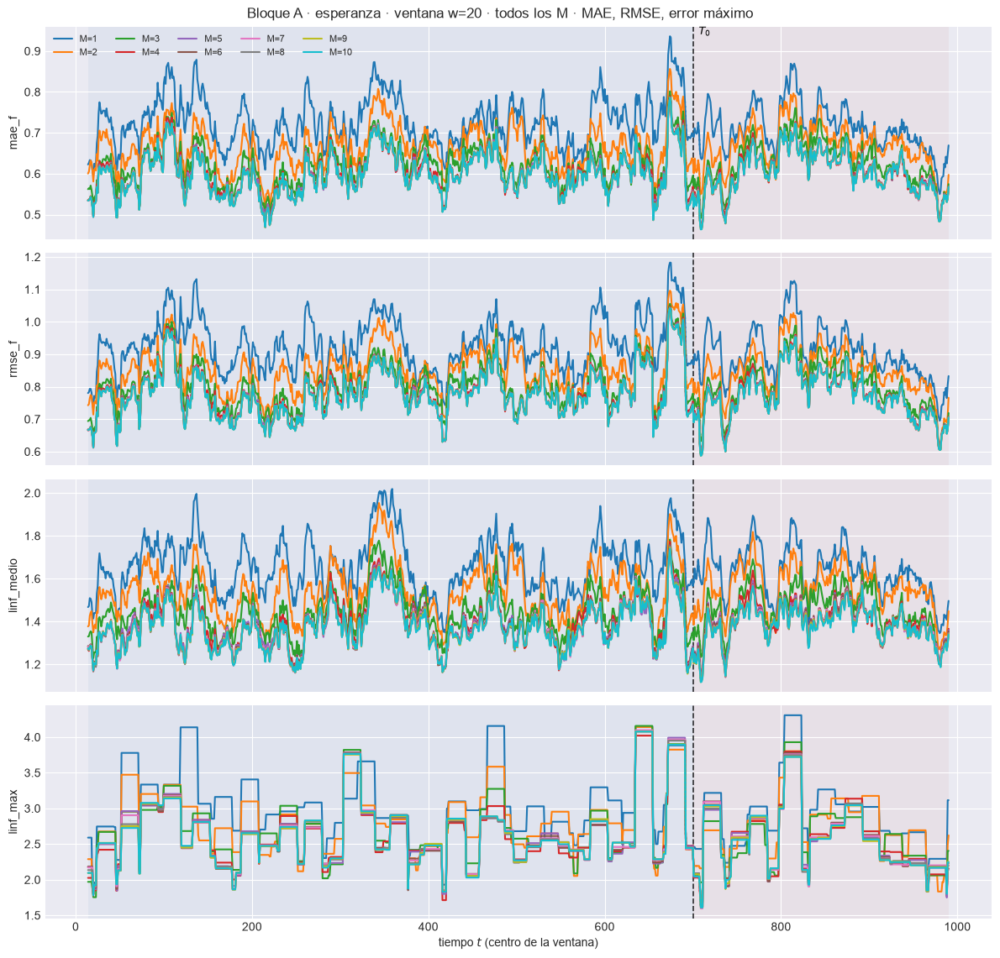

[plot_ventana_movil] inicio (4 pasos)


  1/4 (25.0%) t=0.1s eta=0.2s  mae_f: w=30 train=0.6121  w=30 test=0.6249


  2/4 (50.0%) t=0.1s eta=0.1s  rmse_f: w=30 train=0.792  w=30 test=0.8001


  3/4 (75.0%) t=0.1s eta=0.0s  linf_medio: w=30 train=1.411  w=30 test=1.427


  4/4 (100.0%) t=0.2s eta=0.0s  linf_max: w=30 train=2.815  w=30 test=2.782


[plot_ventana_movil] listo: 4 pasos en 0.8s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_barrido_M\85_bloqueA_w30.png


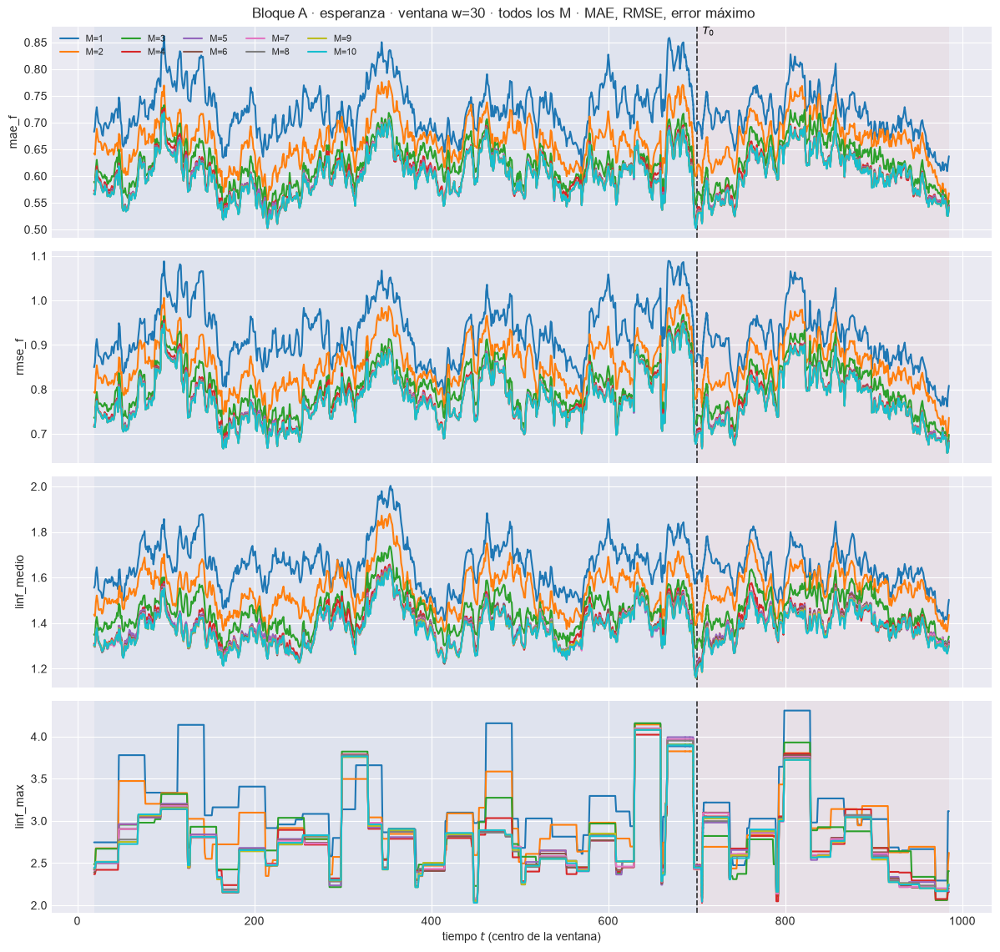

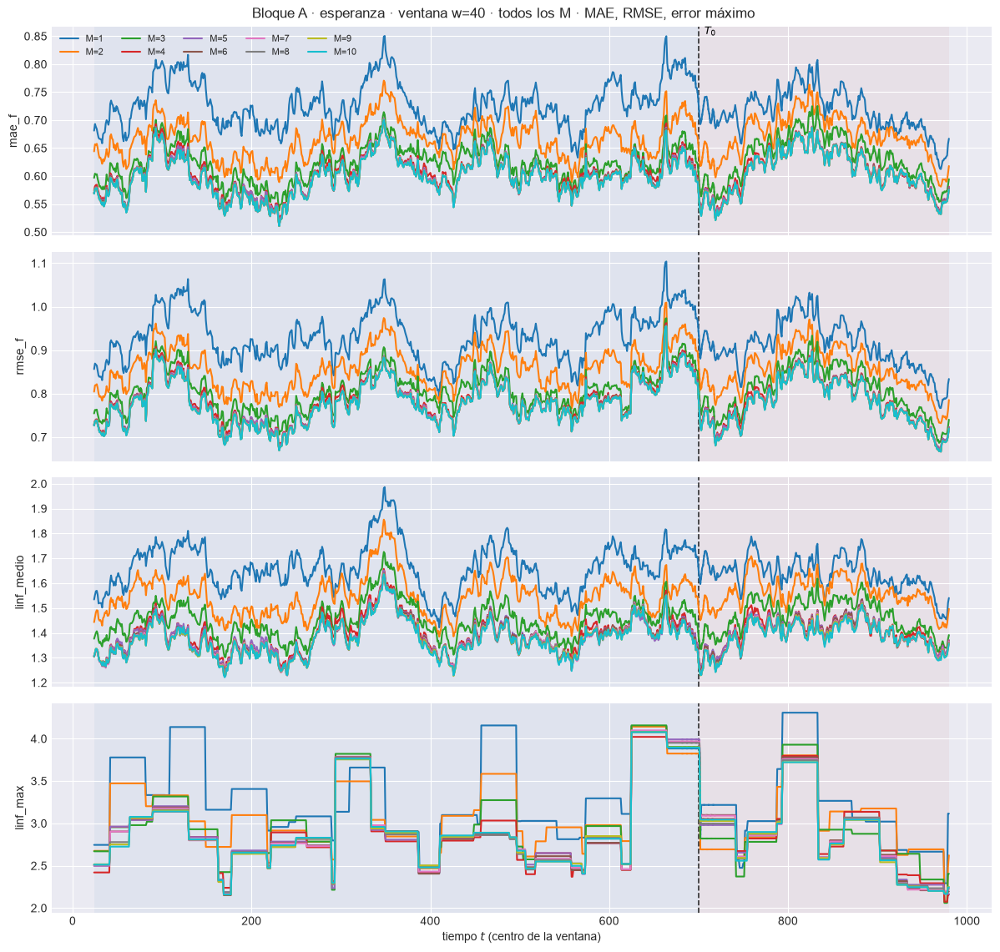

In [9]:
for M in M_OK:
    tablas_ventana(EST[M], DIS, ORIG, PESOS_TAU, predictores=PREDICTORES, intervalos=INTERVALOS)
TABLAS_W = apilar_tablas(EST, M_OK, VENTANAS_W, METRICAS_A_COLS + METRICAS_B_COLS)
verificar_relaciones_metricas(EST, M_OK, VENTANAS_W)

# Una figura por ancho con los M superpuestos.
for w in VENTANAS_W:
    plot_ventana_movil(
        TABLAS_W[w], T0, METRICAS_A_COLS, columna_grupo="punto",
        title=f"Bloque A · esperanza · ventana w={w} · todos los M · MAE, RMSE, error máximo",
        save_path=str(PATH_BARRIDO / f"85_bloqueA_w{w}.png"), verbose=(w == W_REF))
    plt.show()

### 4.1 ¿Qué $M$ gana en cada ventana, y en cada ancho?

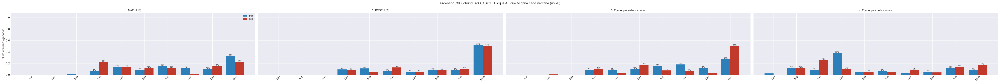

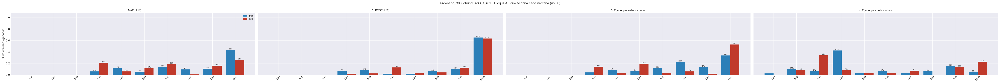

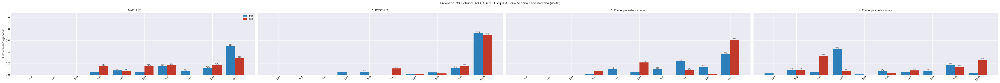

In [10]:
GANA_A = ganancias_por_ventana(EST, M_OK, VENTANAS_W, METRICAS_A, NIVEL)
GANA_B = ganancias_por_ventana(EST, M_OK, VENTANAS_W, METRICAS_B, NIVEL)
GANA_A.to_csv(PATH_BARRIDO / "84_ganador_por_ventana.csv", index=False)
GANA_B.to_csv(PATH_BARRIDO / "87_ganador_bloqueB.csv", index=False)

for w in VENTANAS_W:
    plot_ganador_ventana(GANA_A, METRICAS_A, w, M_OK,
                         f"{EXPERIMENT_BASE} · Bloque A · qué M gana cada ventana (w={w})",
                         PATH_BARRIDO / f"84_ganador_por_ventana_w{w}.png")
    plt.show()

display(tabla_ganadores_test(GANA_A).style.format("{:.1%}")
        .set_caption("Bloque A · % de ventanas TEST ganadas por M (84_ganador_por_ventana.csv)"))

# Salto del MISE en T0, sin las ventanas que lo cruzan.
display(saltos_T0(EST, M_OK, VENTANAS_W).set_index(["M", "w"]).style
        .format({"mise_train": "{:.6f}", "mise_test": "{:.6f}", "salto": "{:.2f}x"})
        .set_caption("MISE train / test y salto en T0"))

### 4.2 ¿Qué predictor gana cada ventana?

Bajo MAE ganan las medianas si la predictiva es multimodal o asimétrica; bajo RMSE, la esperanza.

In [11]:
for M in M_OK:
    EST[M]["ventana_pred"] = filtrar_ventana(EST[M]["tablas_fun"][W_REF], intervalo="equicolas")
GANA_P, REL_P = ganadores_por_ventana(EST, "ventana_pred", "predictor", METRICAS_A, NIVEL)
GANA_P.to_csv(PATH_BARRIDO / "101b_ganador_predictor.csv", index=False)

for etiqueta, _c in METRICAS_A:
    display(GANA_P[(GANA_P.metrica == etiqueta) & (GANA_P.bloque == "test")]
            .pivot(index="predictor", columns="M", values="pct_ventanas_ganadas").loc[list(PREDICTORES)]
            .style.format("{:.1%}").background_gradient(cmap="RdYlGn", axis=None)
            .set_caption(f"{etiqueta} · % de ventanas TEST ganadas por cada predictor (w={W_REF})"))

M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,54.6%,60.9%,42.8%,29.2%,23.6%,21.0%,21.8%,17.3%,20.7%,19.6%
mediana,12.5%,22.1%,29.9%,56.1%,53.1%,73.1%,68.6%,64.2%,72.7%,72.0%
medoide,14.0%,10.0%,20.3%,8.5%,17.3%,0.0%,3.7%,11.8%,0.4%,3.0%
modal,18.8%,7.0%,7.0%,6.3%,5.9%,5.9%,5.9%,6.6%,6.3%,5.5%


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,69.0%,67.9%,61.6%,54.6%,52.4%,49.8%,49.4%,50.2%,49.8%,49.8%
mediana,6.3%,18.5%,13.7%,24.7%,40.6%,46.9%,48.7%,46.5%,48.7%,49.8%
medoide,6.3%,11.1%,23.6%,19.9%,6.3%,2.6%,1.5%,3.0%,1.5%,0.4%
modal,18.5%,2.6%,1.1%,0.7%,0.7%,0.7%,0.4%,0.4%,0.0%,0.0%


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,57.2%,15.1%,12.2%,10.7%,16.2%,16.6%,15.9%,17.0%,15.9%,15.1%
mediana,15.1%,12.9%,19.9%,18.1%,36.5%,45.8%,48.0%,52.8%,48.7%,54.6%
medoide,4.4%,35.1%,31.0%,45.8%,20.3%,10.0%,8.1%,1.8%,6.6%,1.8%
modal,23.2%,36.9%,36.9%,25.5%,26.9%,27.7%,28.0%,28.4%,28.8%,28.4%


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,52.8%,68.3%,55.7%,63.8%,55.4%,63.1%,63.5%,90.0%,83.8%,89.7%
mediana,15.5%,5.2%,10.3%,3.7%,10.0%,8.1%,4.1%,6.6%,4.4%,4.4%
medoide,1.1%,10.0%,10.0%,29.2%,32.5%,17.7%,30.3%,1.1%,8.9%,3.7%
modal,30.6%,16.6%,24.0%,3.3%,2.2%,11.1%,2.2%,2.2%,3.0%,2.2%


### 4.3 Los cuatro predictores en la ventana móvil

`58_ventana_predictores_w<w>.png` por $M$ y `108_predictores_ventana_w30.png` en el barrido.

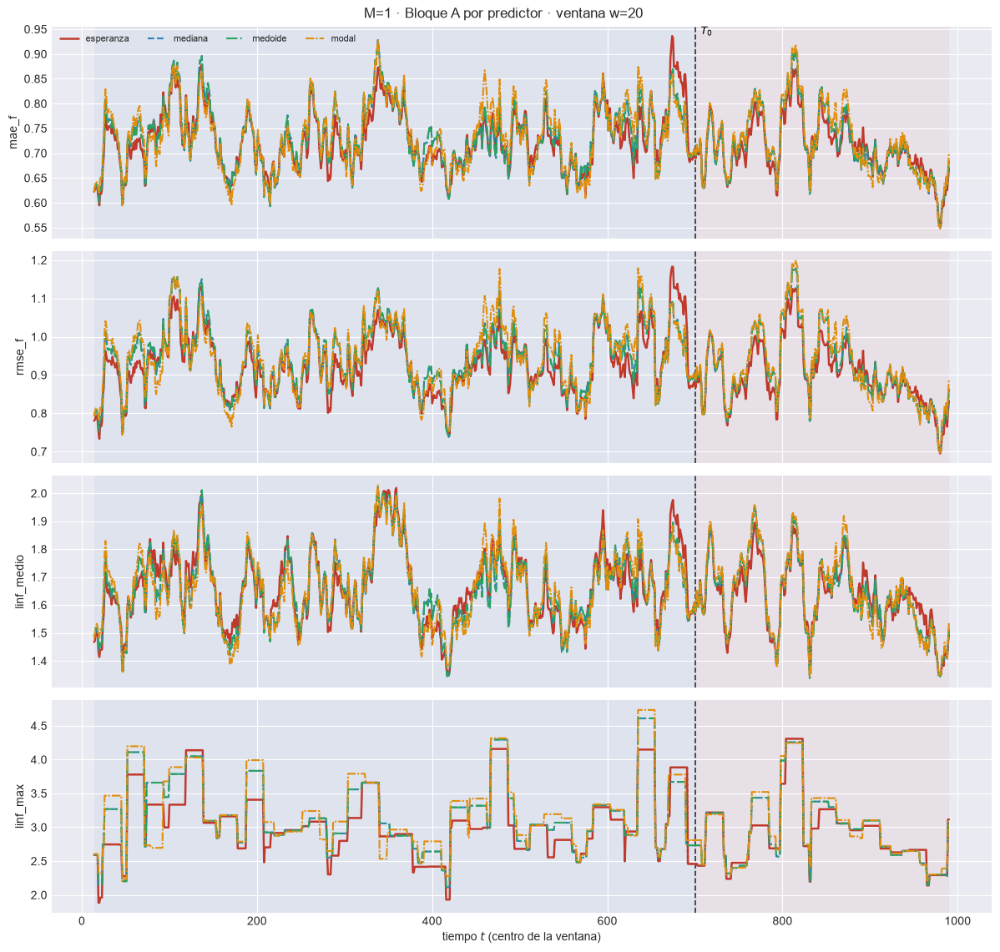

[plot_ventana_movil] inicio (4 pasos)


  1/4 (25.0%) t=0.0s eta=0.0s  mae_f: w=30 train=0.7307  w=30 test=0.716


  2/4 (50.0%) t=0.0s eta=0.0s  rmse_f: w=30 train=0.9447  w=30 test=0.9135


  3/4 (75.0%) t=0.0s eta=0.0s  linf_medio: w=30 train=1.66  w=30 test=1.635


  4/4 (100.0%) t=0.1s eta=0.0s  linf_max: w=30 train=3.268  w=30 test=3.099


[plot_ventana_movil] listo: 4 pasos en 0.7s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_m01\58_ventana_predictores_w30.png


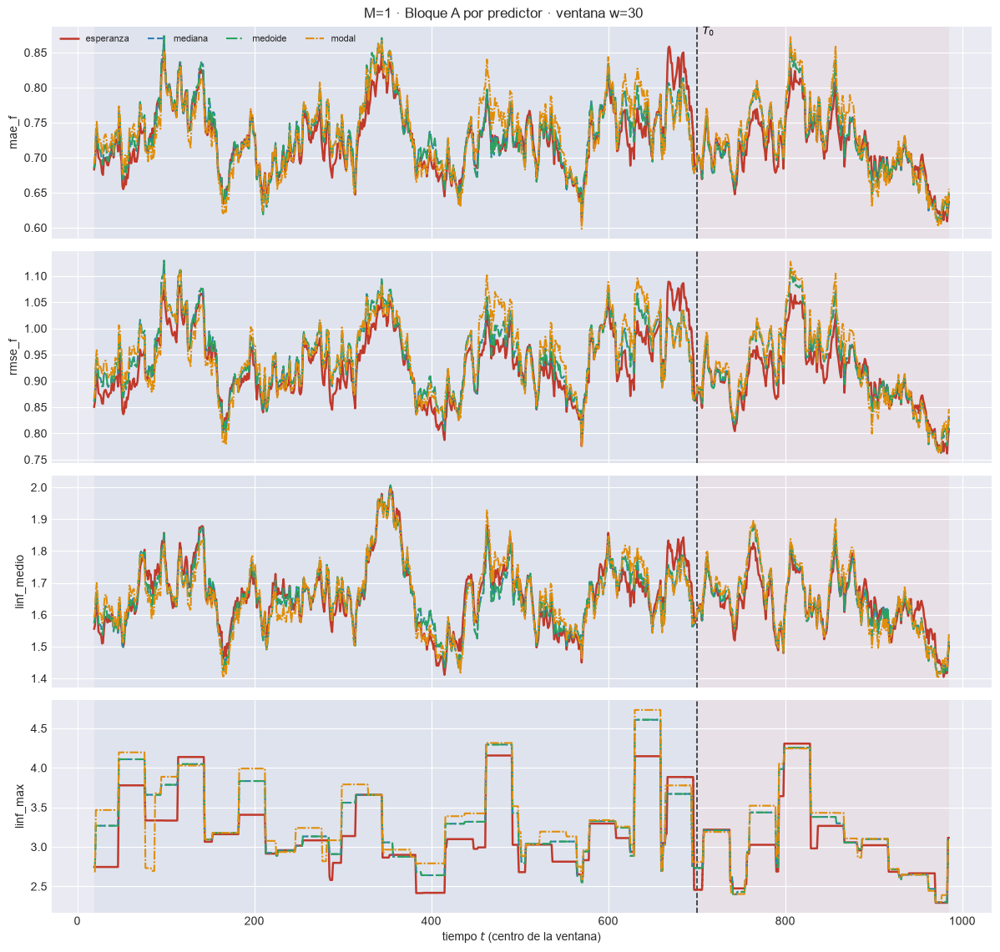

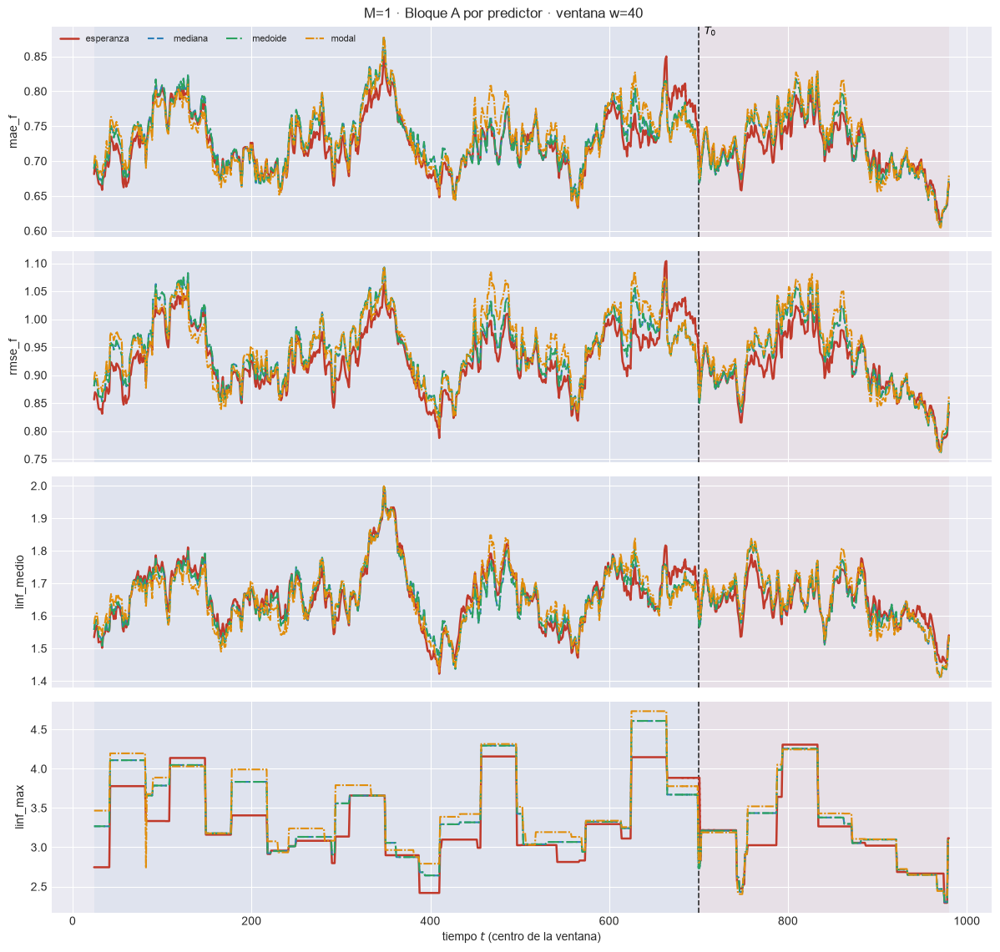

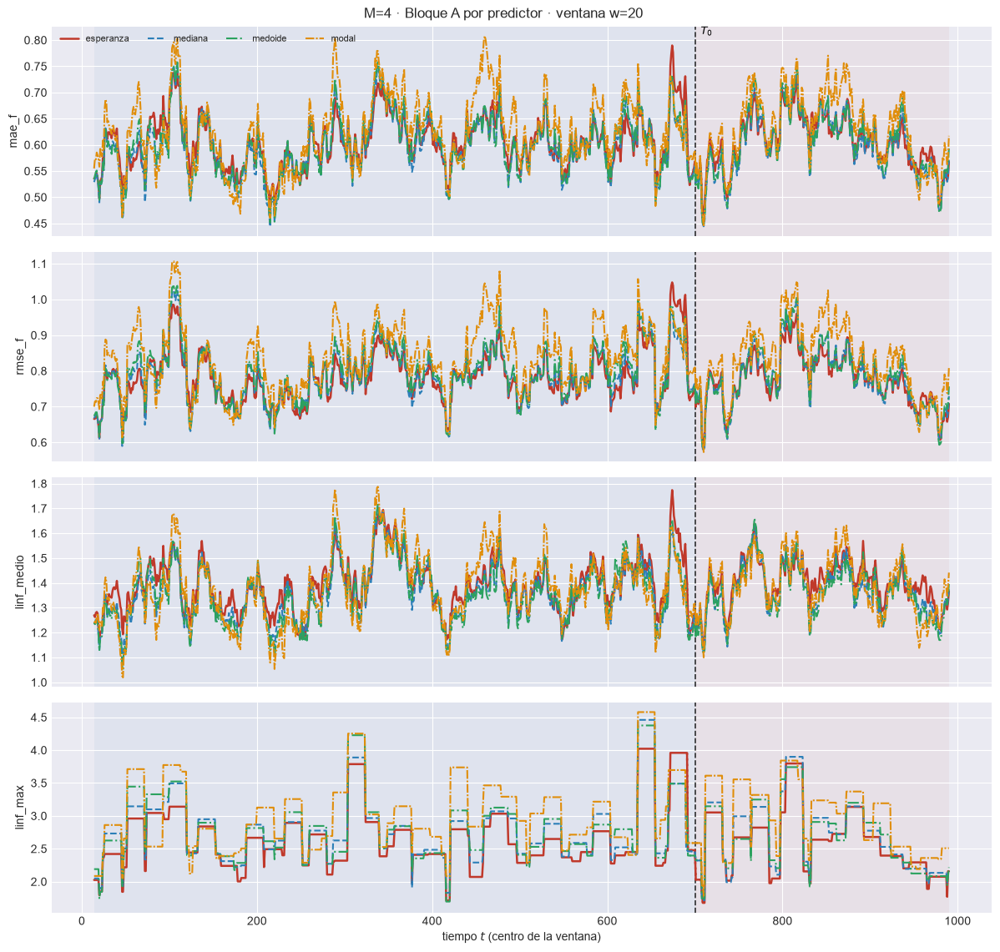

[plot_ventana_movil] inicio (4 pasos)


  1/4 (25.0%) t=0.0s eta=0.0s  mae_f: w=30 train=0.6045  w=30 test=0.6175


  2/4 (50.0%) t=0.0s eta=0.0s  rmse_f: w=30 train=0.7966  w=30 test=0.8009


  3/4 (75.0%) t=0.0s eta=0.0s  linf_medio: w=30 train=1.37  w=30 test=1.389


  4/4 (100.0%) t=0.1s eta=0.0s  linf_max: w=30 train=2.893  w=30 test=2.994


[plot_ventana_movil] listo: 4 pasos en 0.7s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_m04\58_ventana_predictores_w30.png


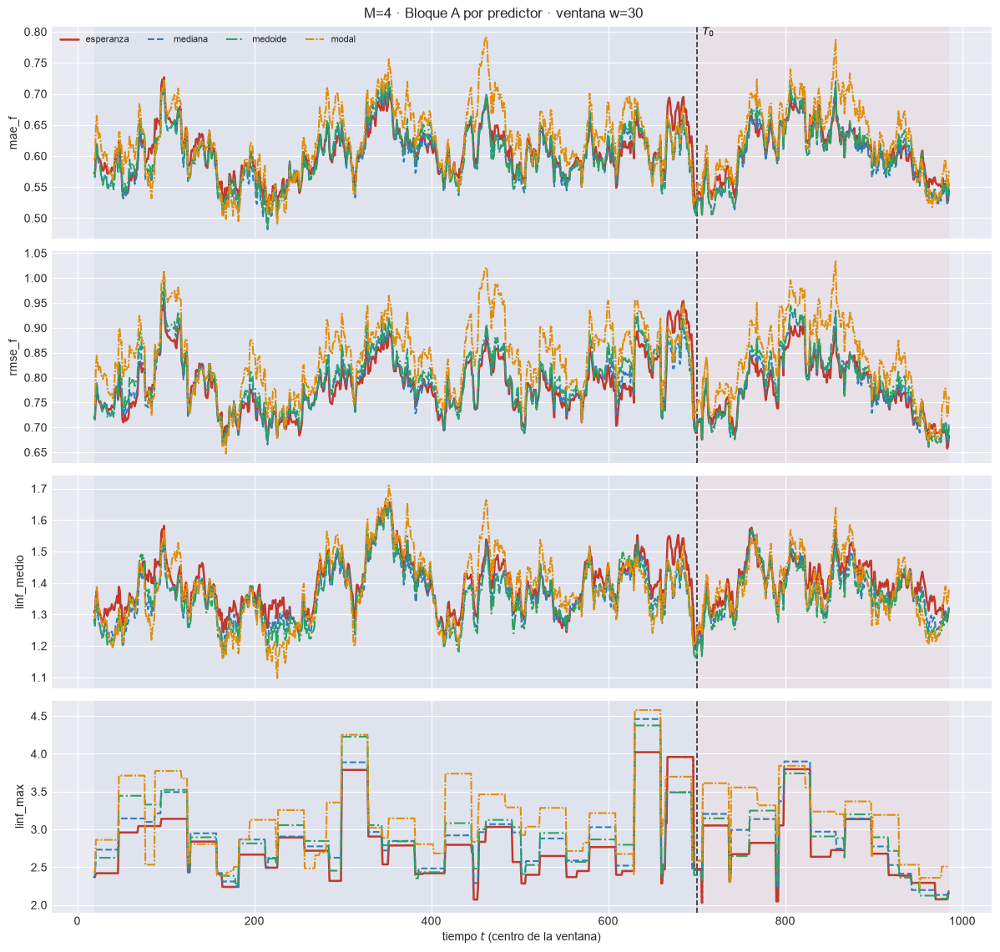

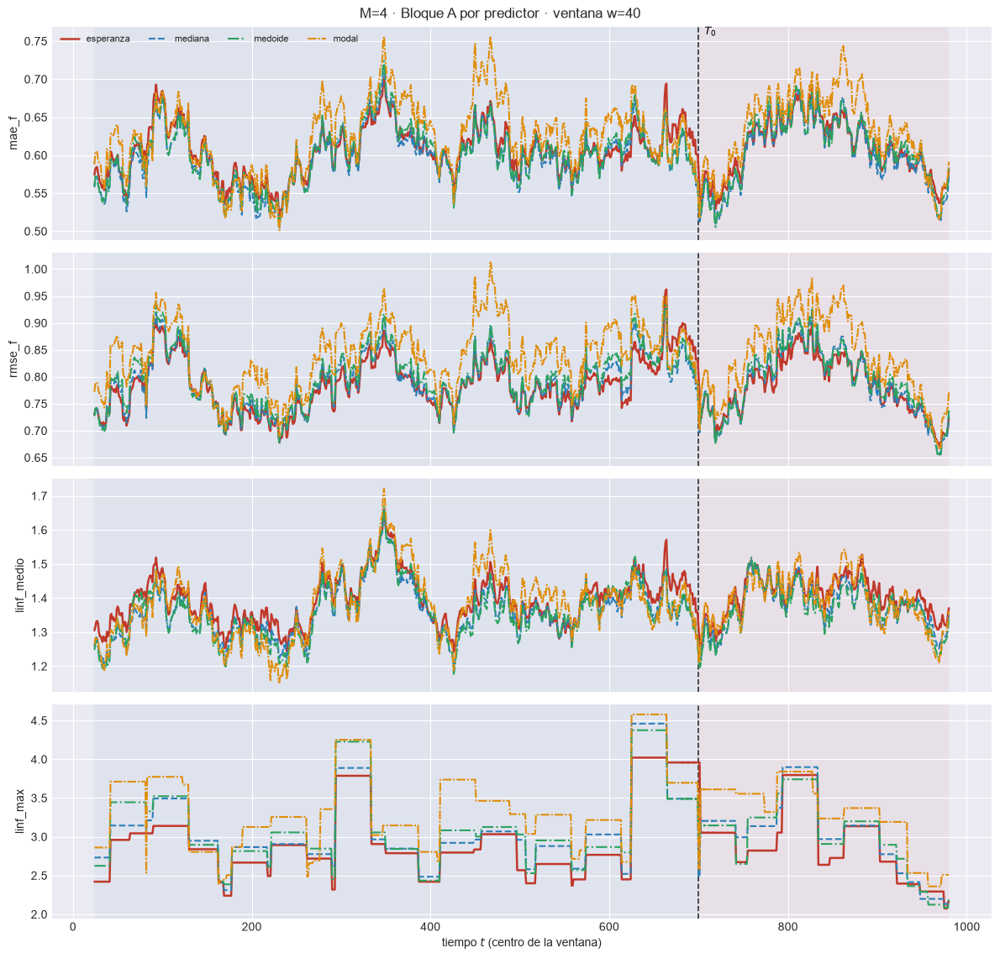

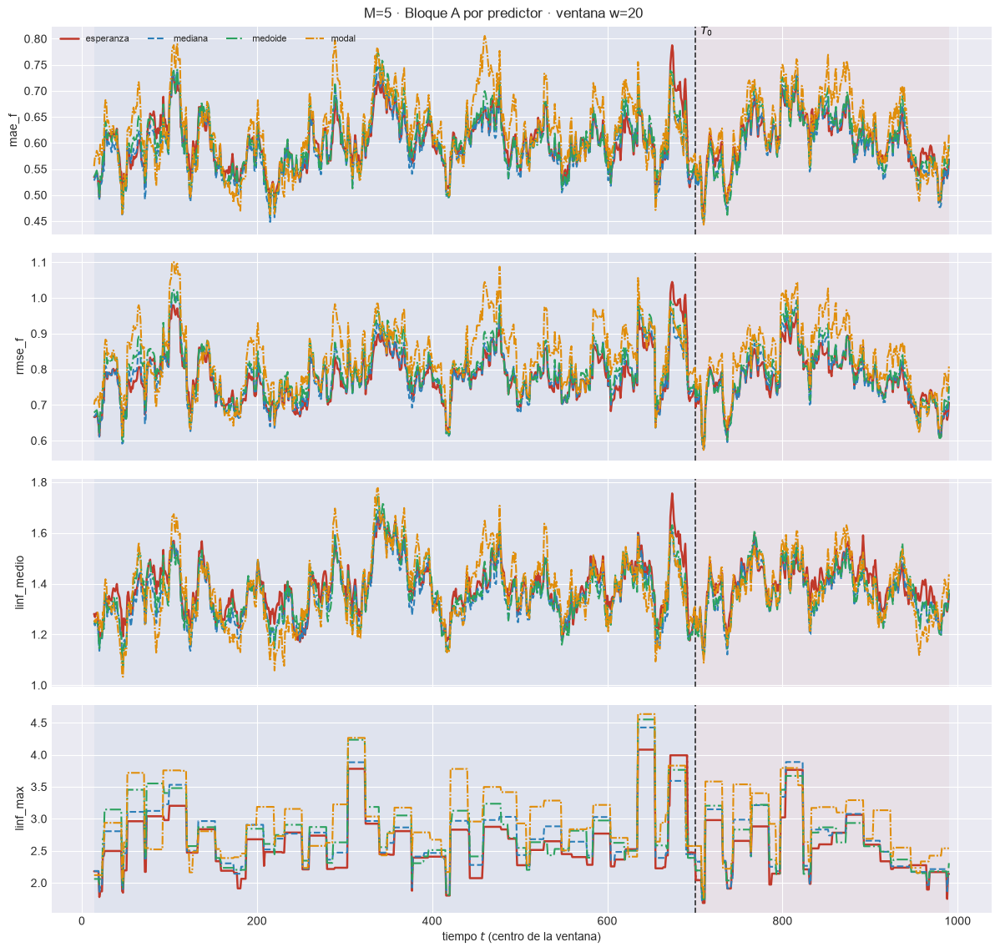

[plot_ventana_movil] inicio (4 pasos)


  1/4 (25.0%) t=0.0s eta=0.1s  mae_f: w=30 train=0.6023  w=30 test=0.6163


  2/4 (50.0%) t=0.1s eta=0.1s  rmse_f: w=30 train=0.7931  w=30 test=0.7981


  3/4 (75.0%) t=0.1s eta=0.0s  linf_medio: w=30 train=1.366  w=30 test=1.389


  4/4 (100.0%) t=0.1s eta=0.0s  linf_max: w=30 train=2.907  w=30 test=2.934


[plot_ventana_movil] listo: 4 pasos en 1.1s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_m05\58_ventana_predictores_w30.png


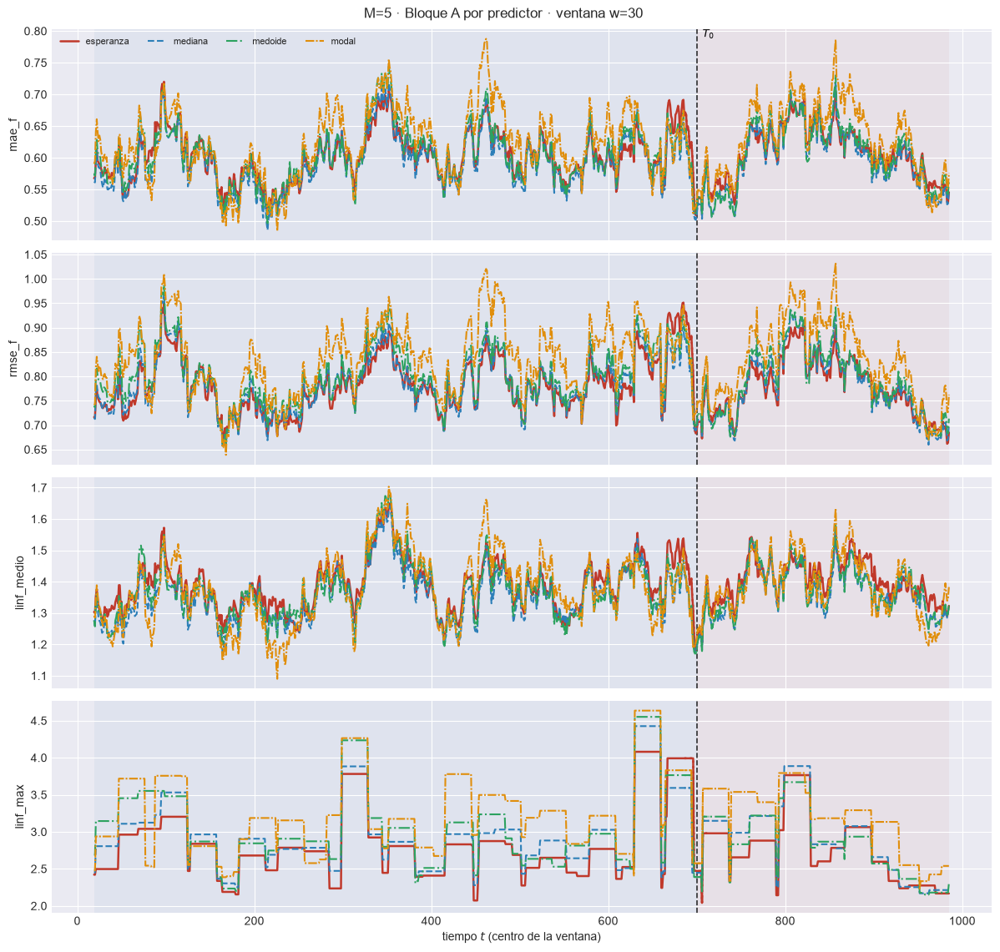

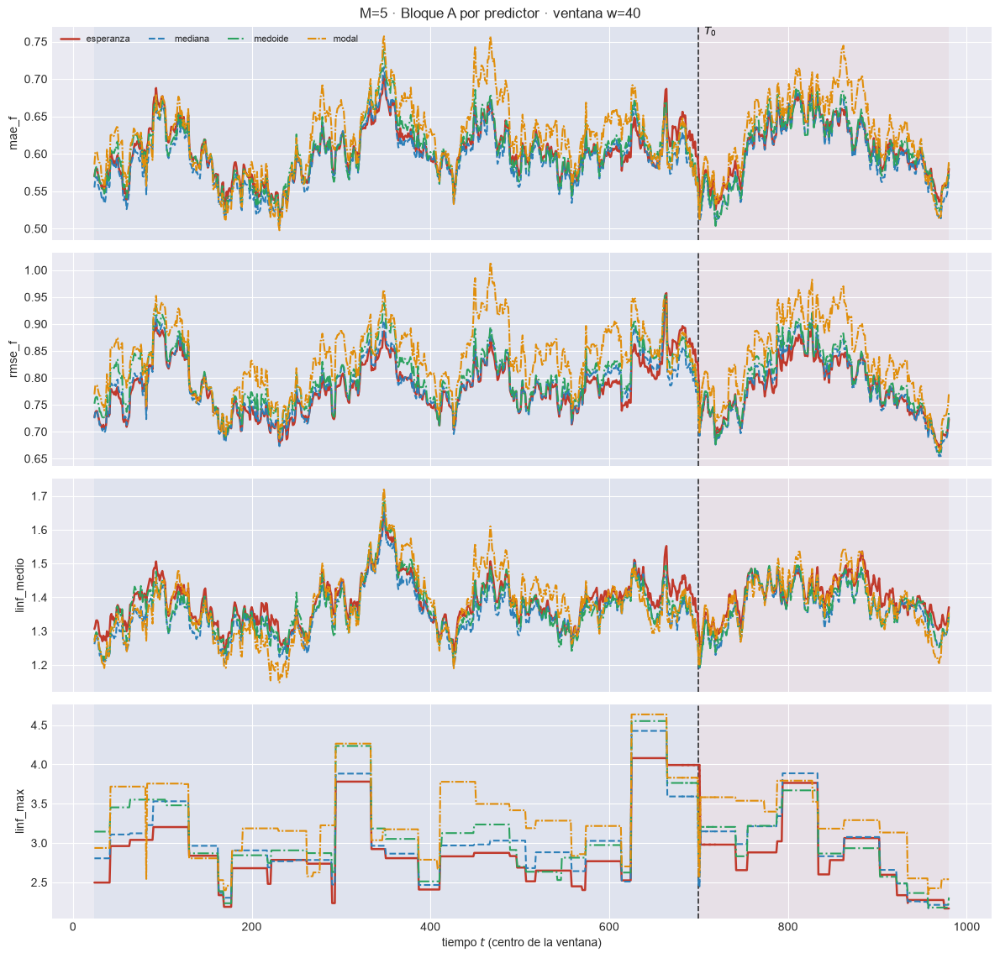

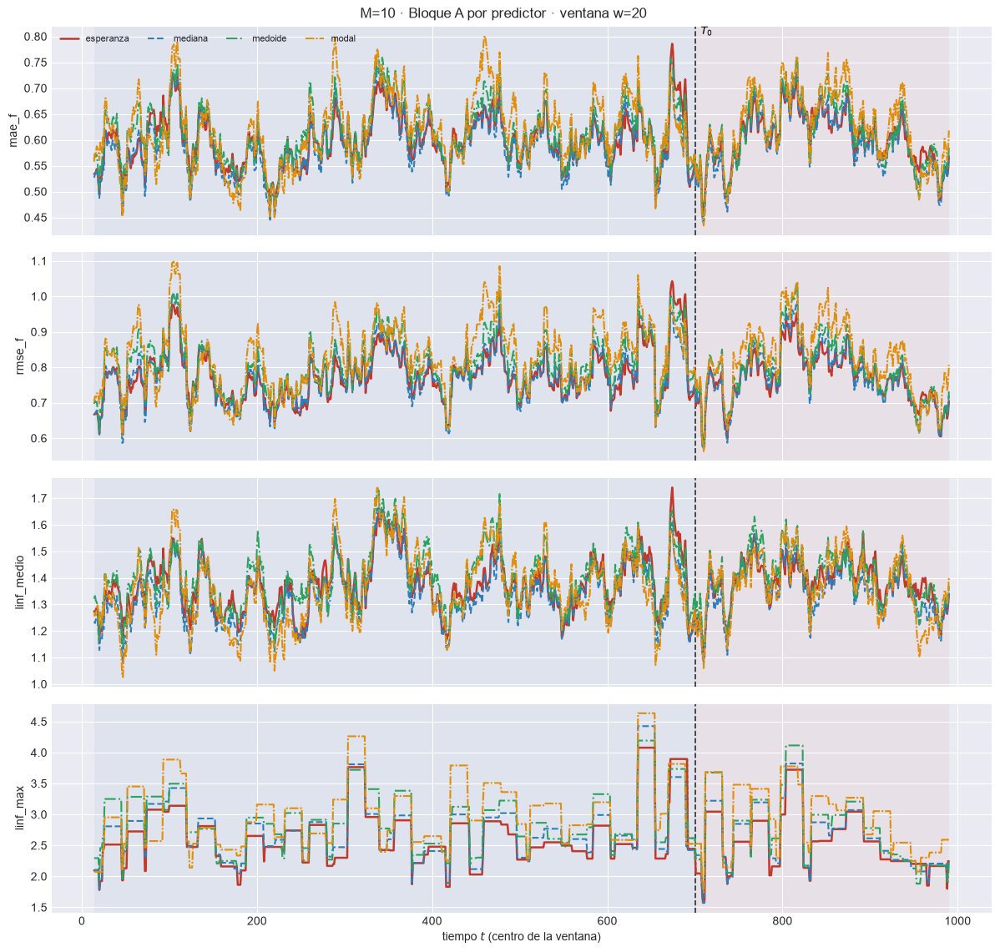

[plot_ventana_movil] inicio (4 pasos)


  1/4 (25.0%) t=0.0s eta=0.1s  mae_f: w=30 train=0.603  w=30 test=0.6163


  2/4 (50.0%) t=0.1s eta=0.1s  rmse_f: w=30 train=0.7939  w=30 test=0.7959


  3/4 (75.0%) t=0.1s eta=0.0s  linf_medio: w=30 train=1.365  w=30 test=1.388


  4/4 (100.0%) t=0.1s eta=0.0s  linf_max: w=30 train=2.913  w=30 test=2.994


[plot_ventana_movil] listo: 4 pasos en 1.2s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_m10\58_ventana_predictores_w30.png


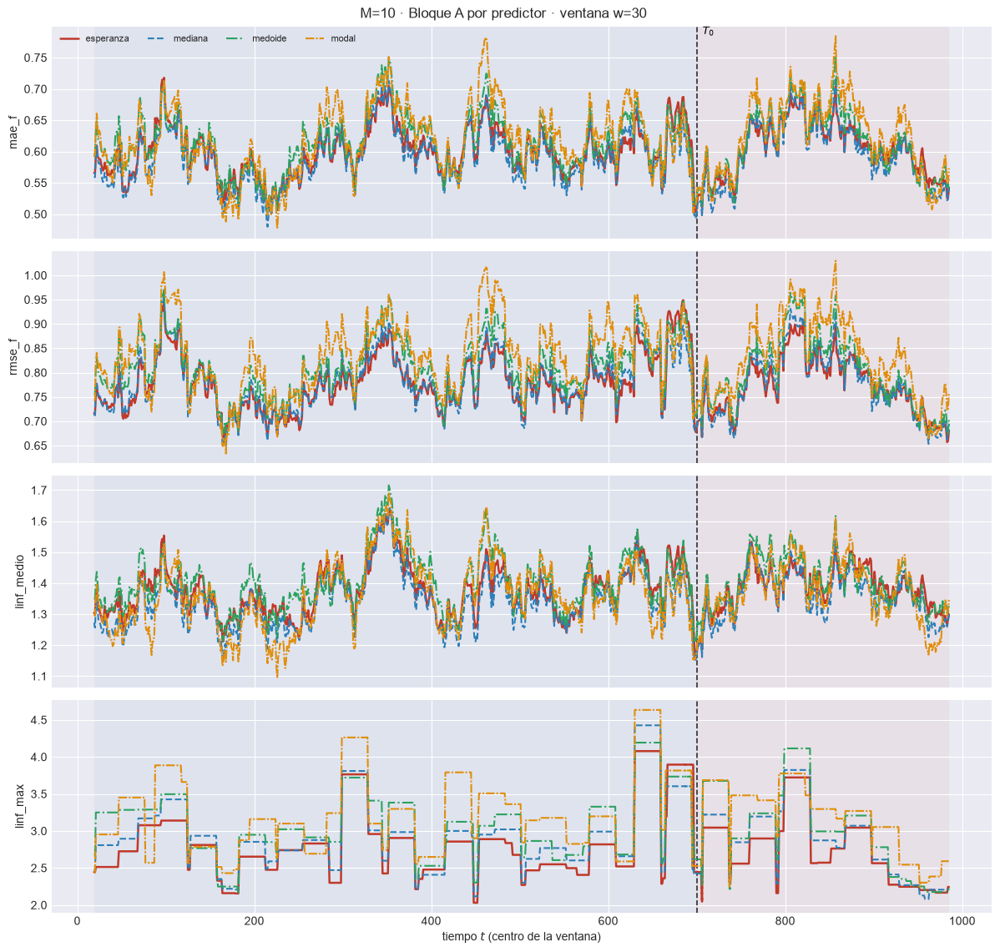

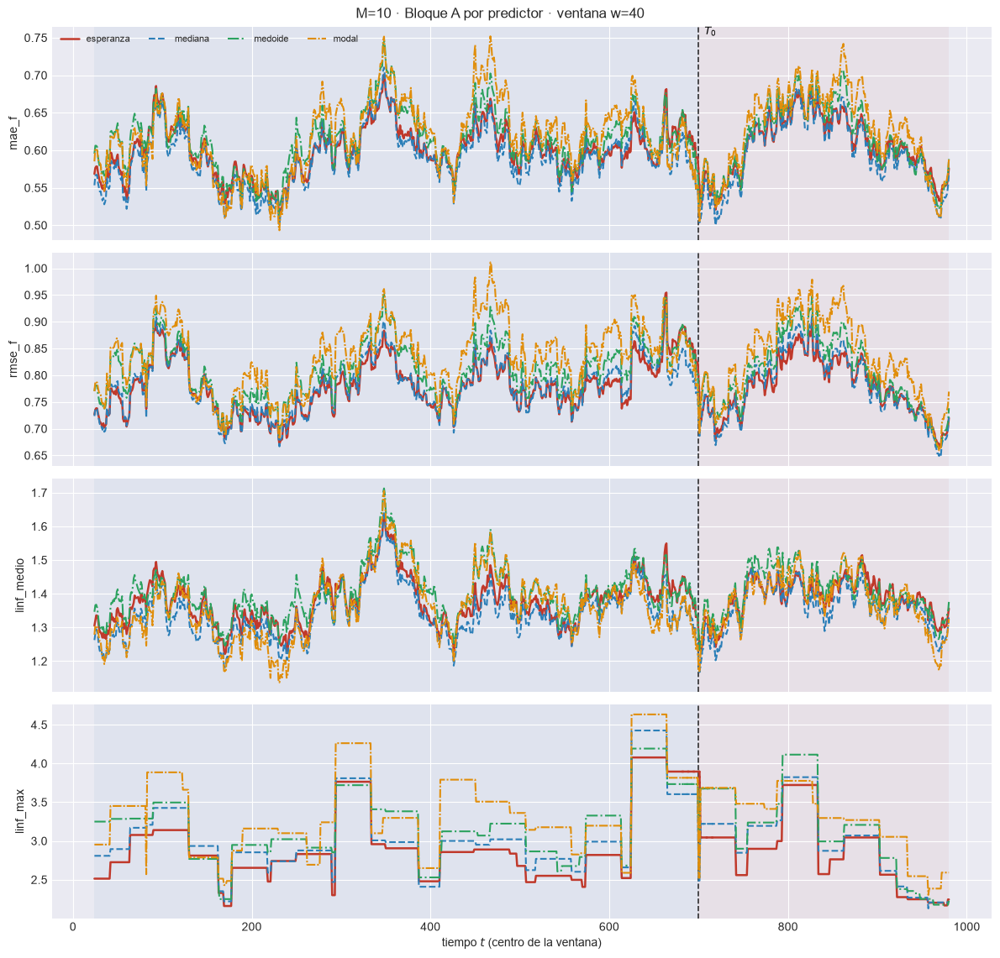

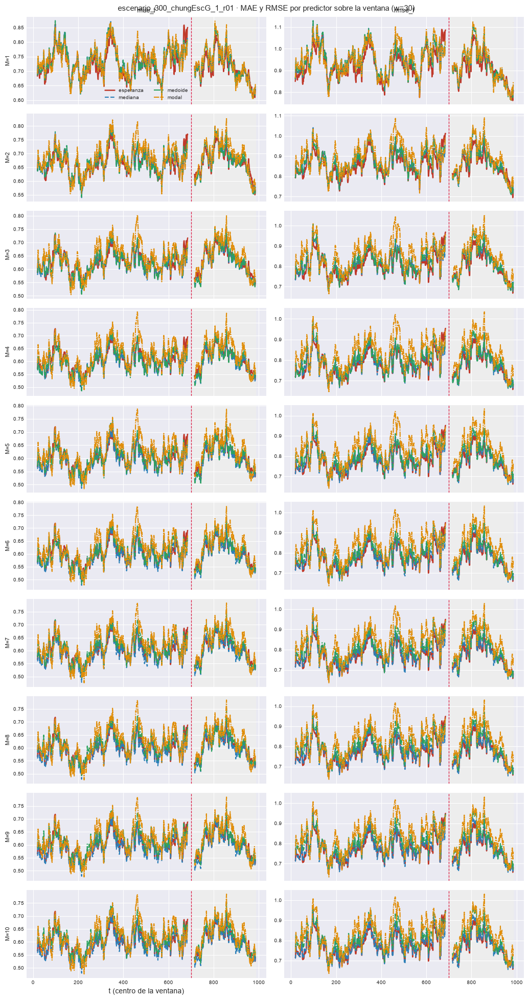

In [12]:
for M in (m for m in M_DETALLE if m in M_OK):
    for w in VENTANAS_W:
        tp = filtrar_ventana(EST[M]["tablas_fun"][w], intervalo="equicolas")
        tp.attrs["w"] = w
        plot_ventana_movil(
            tp, T0, METRICAS_A_COLS, columna_grupo="predictor", estilos=ESTILOS_PREDICTORES,
            title=f"M={M} · Bloque A por predictor · ventana w={w}",
            save_path=str(EST[M]["paths"]["out_report"] / f"58_ventana_predictores_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

plot_ventana_grupos_por_M(
    {M: filtrar_ventana(EST[M]["tablas_fun"][W_REF], intervalo="equicolas") for M in M_OK},
    ["mae_f", "rmse_f"], "predictor", T0, ESTILOS_PREDICTORES,
    f"{EXPERIMENT_BASE} · MAE y RMSE por predictor sobre la ventana (w={W_REF})",
    PATH_BARRIDO / f"108_predictores_ventana_w{W_REF}.png")
plt.show()

## 5. Bloque B por construcción de intervalo

Equi-colas, banda simultánea y HDR puntual (docs §03_05_05) sobre las mismas extracciones; las seis métricas van sobre la unión de tramos. Las figuras de los $M$ superpuestos son de la equi-colas.

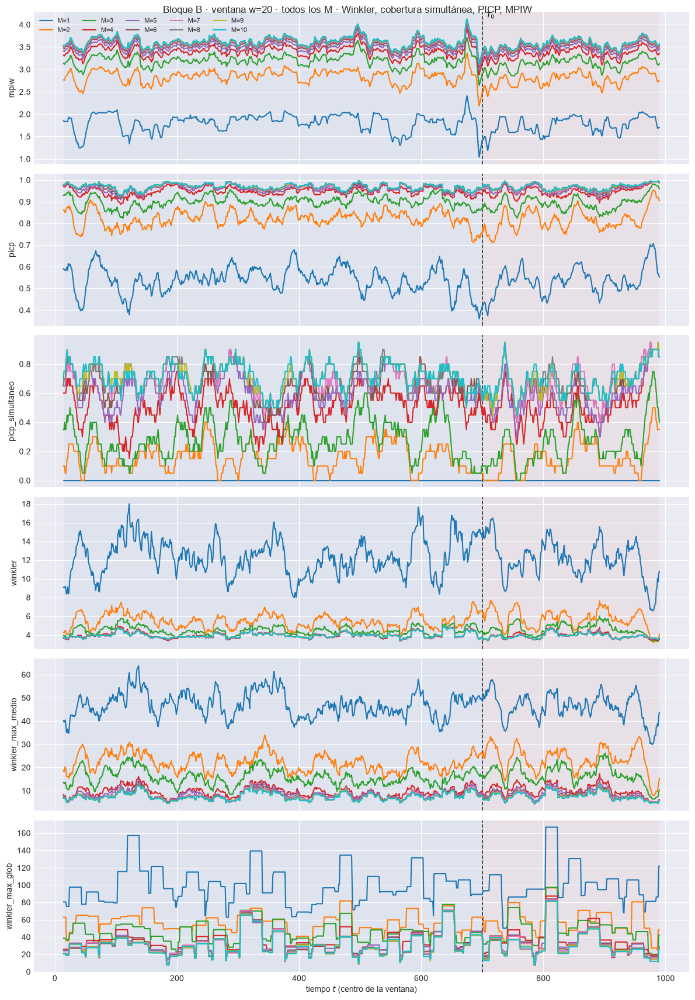

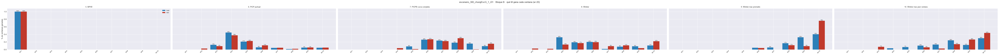

[plot_ventana_movil] inicio (6 pasos)


  1/6 (16.7%) t=0.1s eta=0.3s  mpiw: w=30 train=3.505  w=30 test=3.452


  2/6 (33.3%) t=0.1s eta=0.3s  picp: w=30 train=0.956  w=30 test=0.9547


  3/6 (50.0%) t=0.2s eta=0.2s  picp_simultaneo: w=30 train=0.6333  w=30 test=0.6


  4/6 (66.7%) t=0.2s eta=0.1s  winkler: w=30 train=4.086  w=30 test=3.982


  5/6 (83.3%) t=0.3s eta=0.1s  winkler_max_medio: w=30 train=8.926  w=30 test=9.308


  6/6 (100.0%) t=0.4s eta=0.0s  winkler_max_glob: w=30 train=40.11  w=30 test=42.44


[plot_ventana_movil] listo: 6 pasos en 2.0s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_barrido_M\86_bloqueB_w30.png


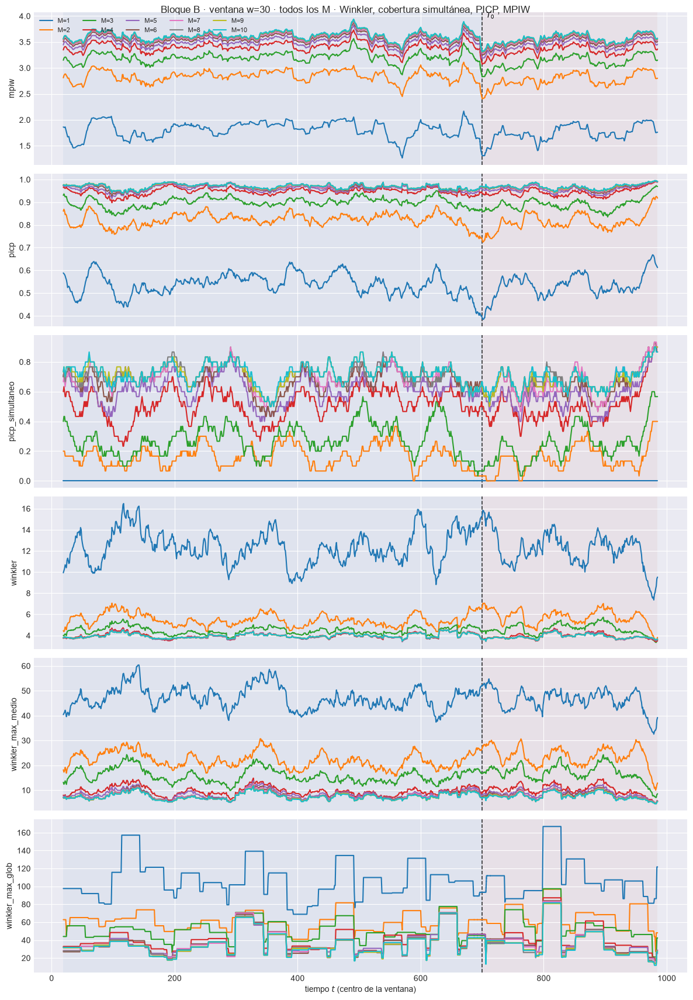

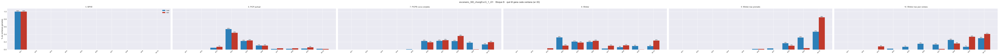

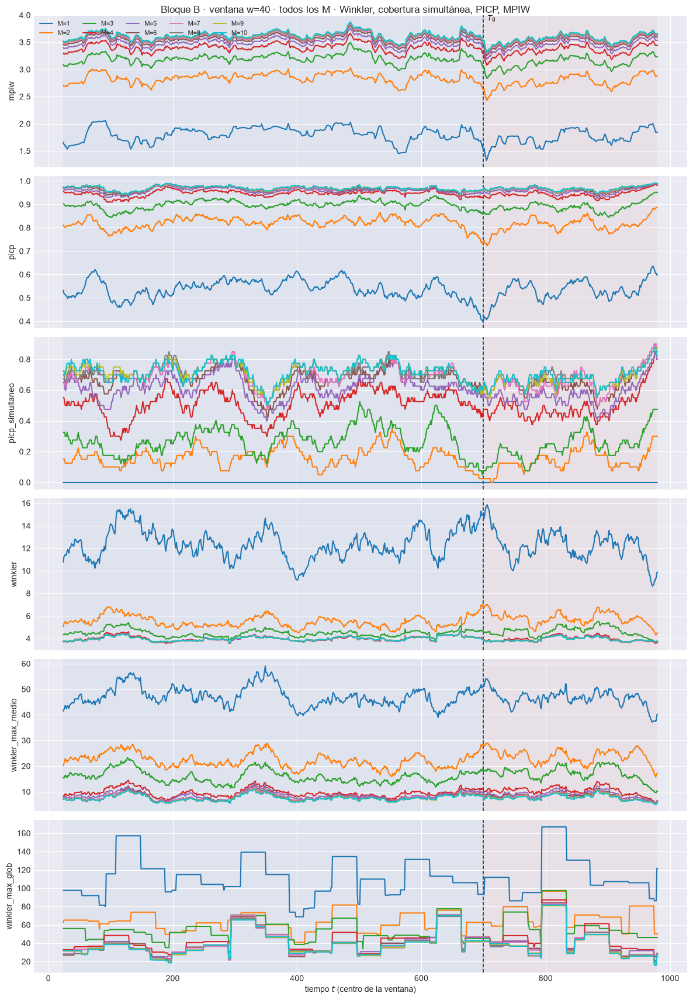

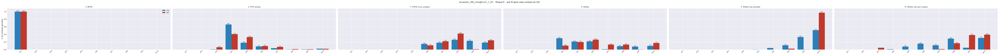

In [13]:
for w in VENTANAS_W:
    plot_ventana_movil(
        TABLAS_W[w], T0, METRICAS_B_COLS, columna_grupo="punto",
        title=f"Bloque B · ventana w={w} · todos los M · Winkler, cobertura simultánea, PICP, MPIW",
        save_path=str(PATH_BARRIDO / f"86_bloqueB_w{w}.png"), verbose=(w == W_REF))
    plt.show()
    # En picp el objetivo es el NOMINAL, no el mínimo.
    plot_ganador_ventana(GANA_B, METRICAS_B, w, M_OK,
                         f"{EXPERIMENT_BASE} · Bloque B · qué M gana cada ventana (w={w})",
                         PATH_BARRIDO / f"87_ganador_bloqueB_w{w}.png")
    plt.show()

display(tabla_ganadores_test(GANA_B).style.format("{:.1%}")
        .set_caption("Bloque B · % de ventanas TEST ganadas por M (87_ganador_bloqueB.csv)"))

### 5.1 Las tres construcciones en la ventana móvil

`59_ventana_intervalos_w<w>.png` por $M$ y quién gana cada ventana (`109_*`). En PICP y PICPB gana la más cercana al nominal.

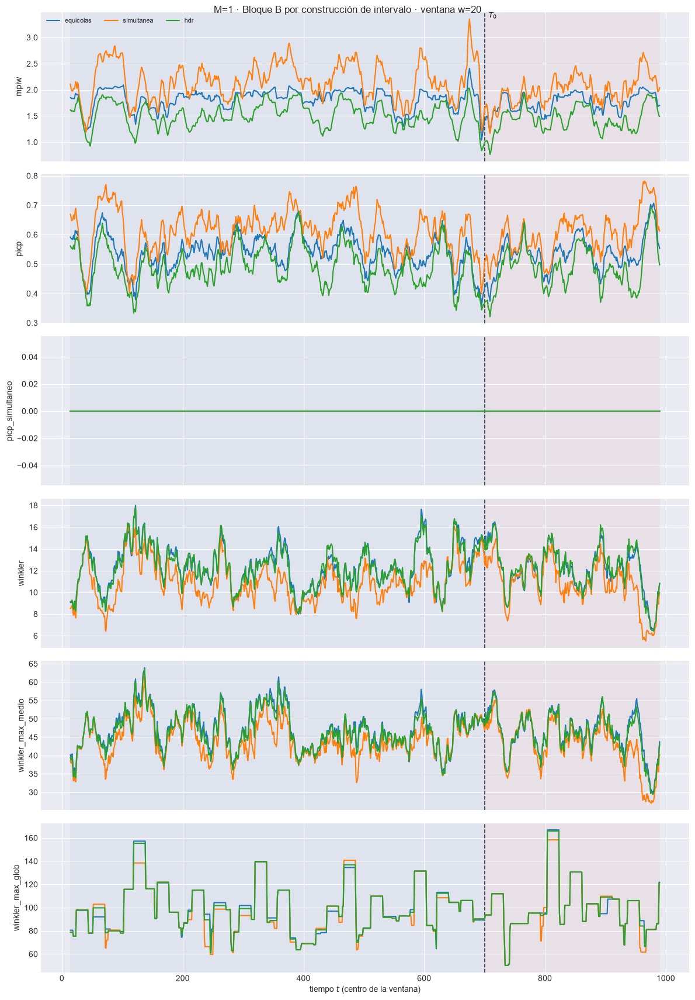

[plot_ventana_movil] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  mpiw: w=30 train=1.829  w=30 test=1.752


  2/6 (33.3%) t=0.1s eta=0.1s  picp: w=30 train=0.5462  w=30 test=0.5444


  3/6 (50.0%) t=0.1s eta=0.1s  picp_simultaneo: w=30 train=0  w=30 test=0


  4/6 (66.7%) t=0.1s eta=0.0s  winkler: w=30 train=11.86  w=30 test=11.75


  5/6 (83.3%) t=0.1s eta=0.0s  winkler_max_medio: w=30 train=45.76  w=30 test=45.53


  6/6 (100.0%) t=0.1s eta=0.0s  winkler_max_glob: w=30 train=104.3  w=30 test=106


[plot_ventana_movil] listo: 6 pasos en 1.3s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_m01\59_ventana_intervalos_w30.png


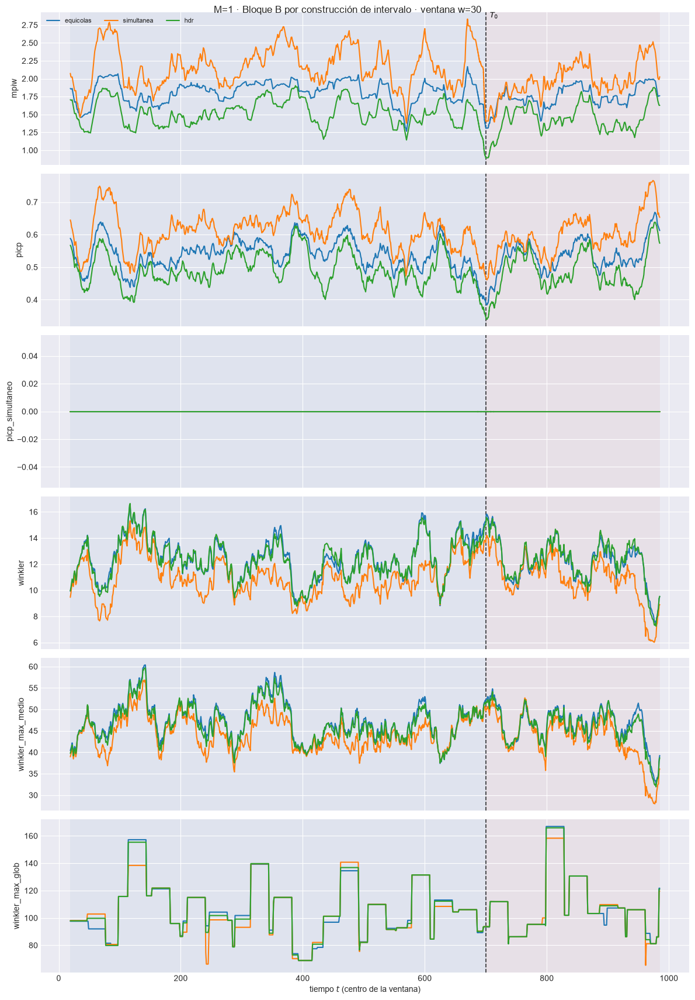

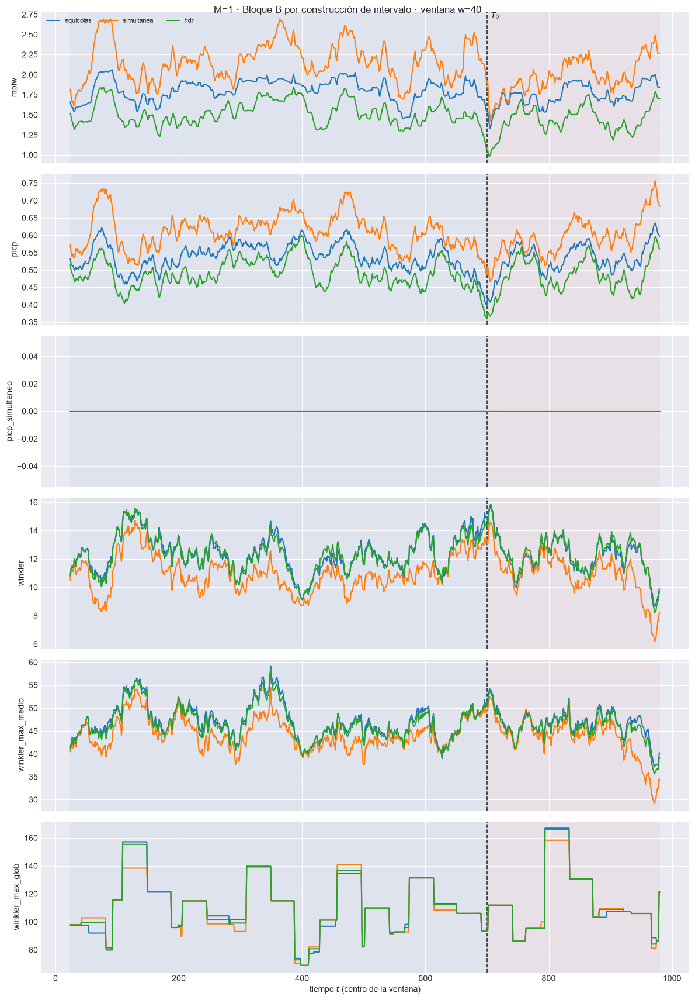

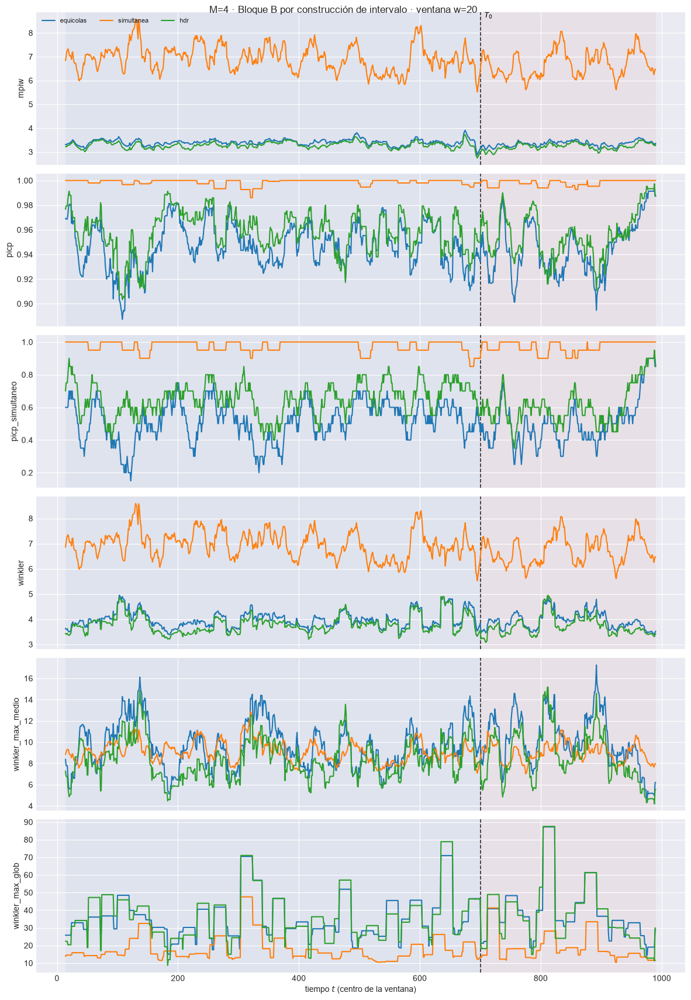

[plot_ventana_movil] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  mpiw: w=30 train=3.426  w=30 test=3.367


  2/6 (33.3%) t=0.0s eta=0.1s  picp: w=30 train=0.9627  w=30 test=0.96


  3/6 (50.0%) t=0.1s eta=0.1s  picp_simultaneo: w=30 train=0.6667  w=30 test=0.6


  4/6 (66.7%) t=0.1s eta=0.0s  winkler: w=30 train=4.093  w=30 test=4.062


  5/6 (83.3%) t=0.1s eta=0.0s  winkler_max_medio: w=30 train=8.988  w=30 test=9.165


  6/6 (100.0%) t=0.1s eta=0.0s  winkler_max_glob: w=30 train=32.49  w=30 test=34.23


[plot_ventana_movil] listo: 6 pasos en 1.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_m04\59_ventana_intervalos_w30.png


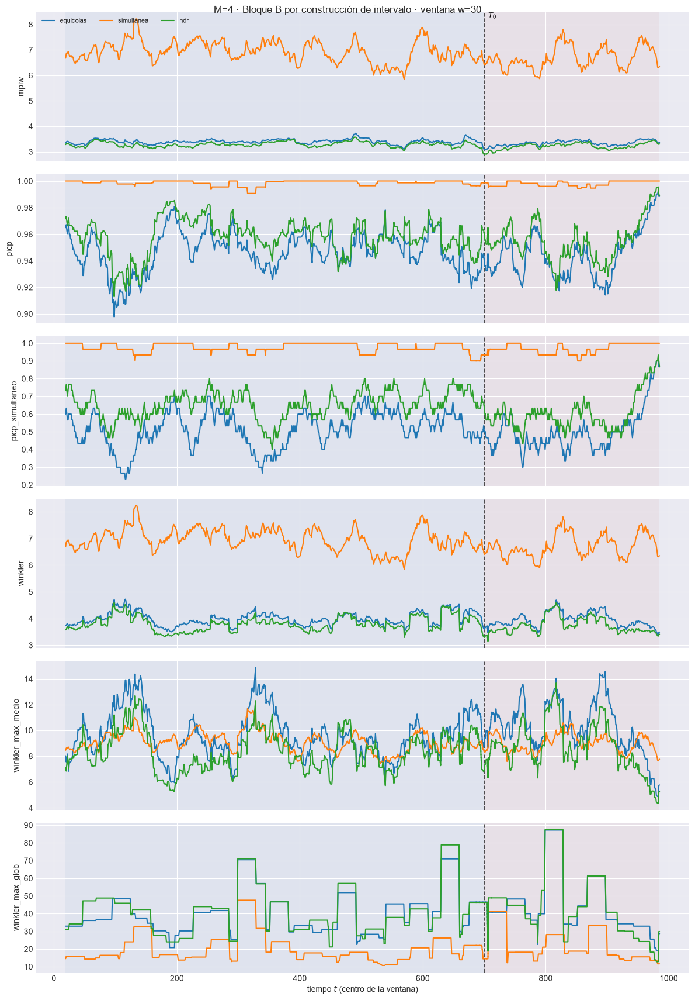

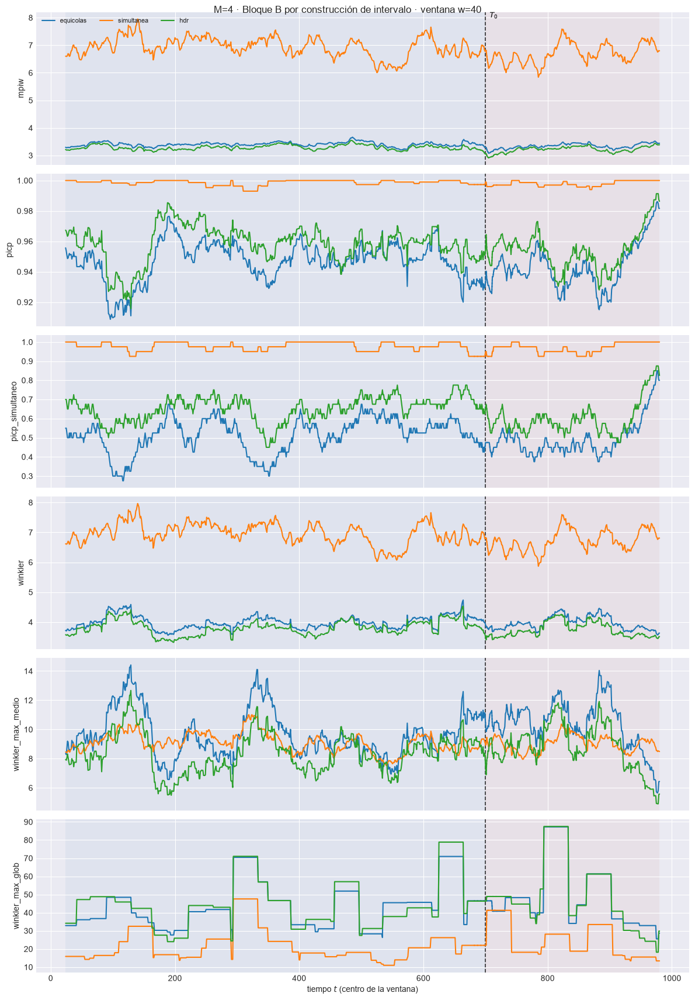

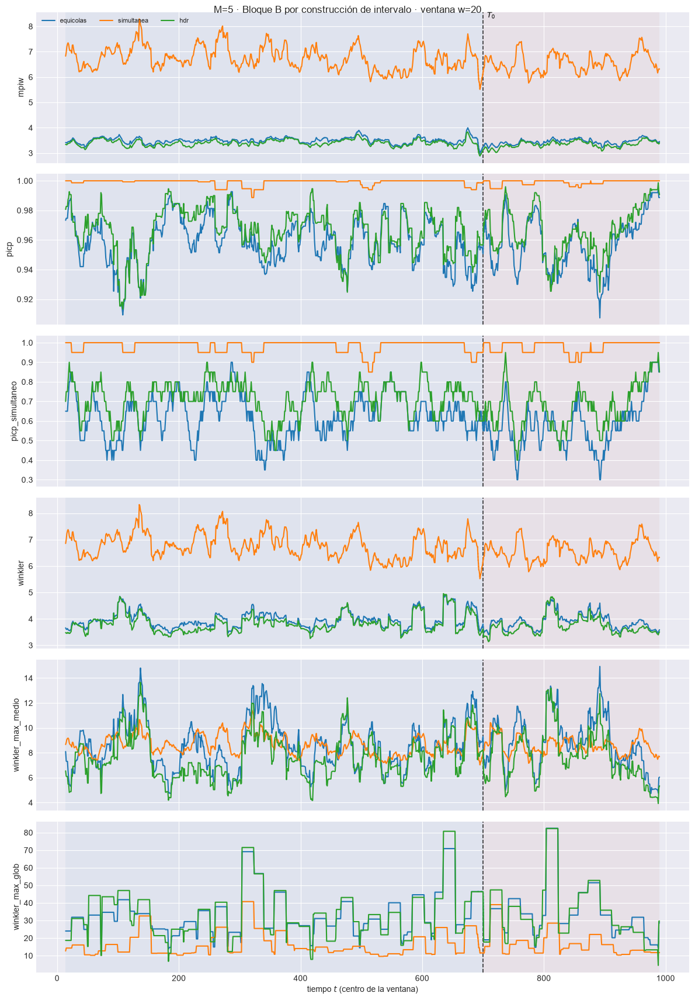

[plot_ventana_movil] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  mpiw: w=30 train=3.525  w=30 test=3.471


  2/6 (33.3%) t=0.0s eta=0.1s  picp: w=30 train=0.9724  w=30 test=0.9711


  3/6 (50.0%) t=0.1s eta=0.1s  picp_simultaneo: w=30 train=0.7333  w=30 test=0.7


  4/6 (66.7%) t=0.1s eta=0.0s  winkler: w=30 train=4.089  w=30 test=3.993


  5/6 (83.3%) t=0.1s eta=0.0s  winkler_max_medio: w=30 train=8.312  w=30 test=8.439


  6/6 (100.0%) t=0.1s eta=0.0s  winkler_max_glob: w=30 train=31.14  w=30 test=31.85


[plot_ventana_movil] listo: 6 pasos en 1.3s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_m05\59_ventana_intervalos_w30.png


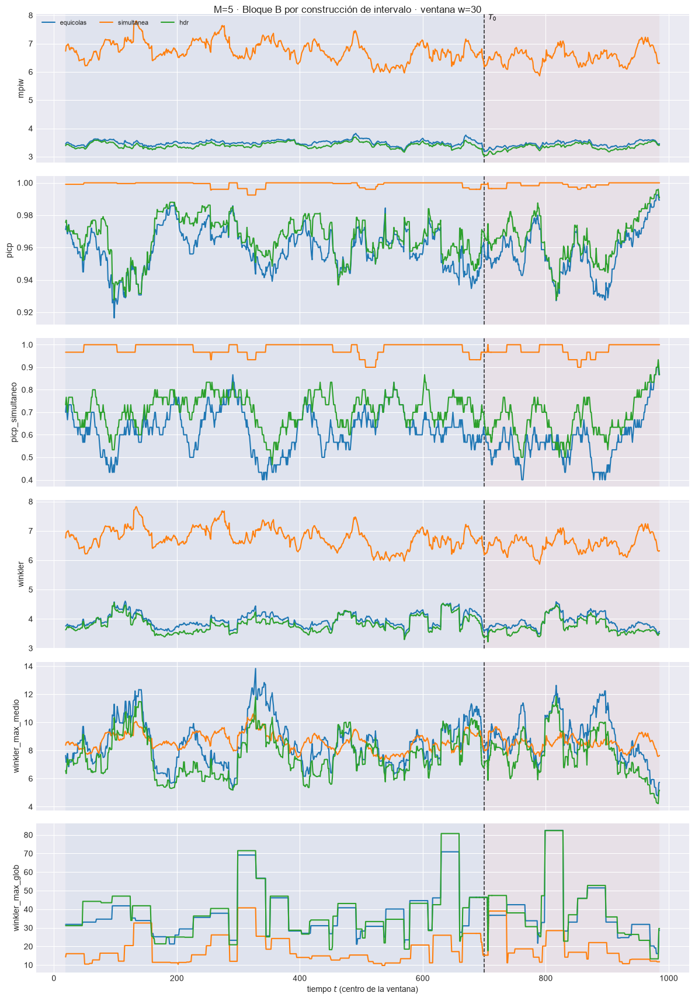

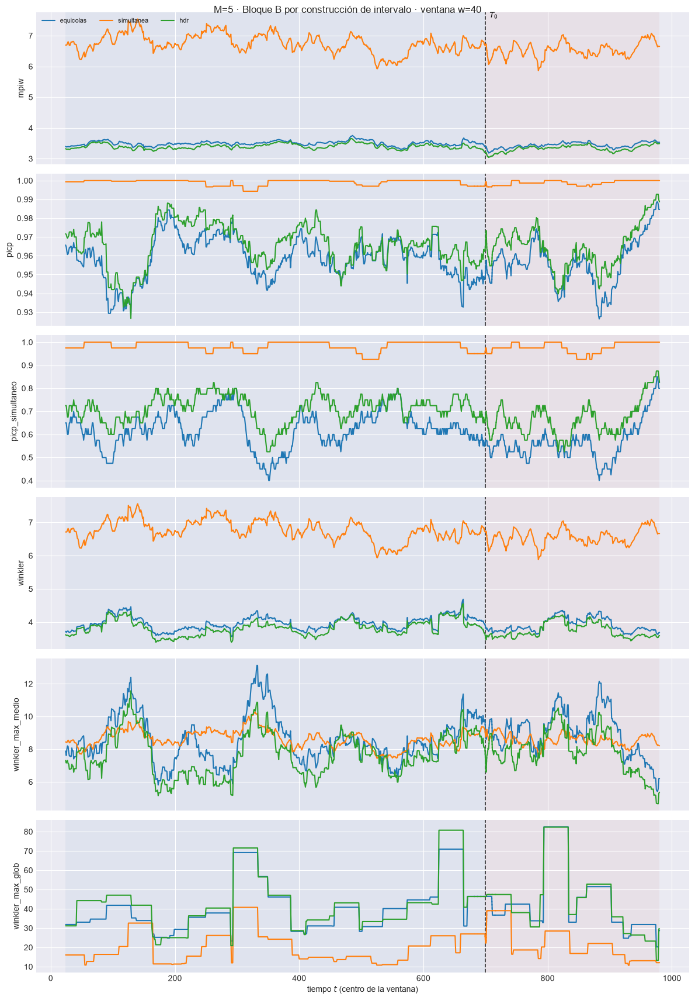

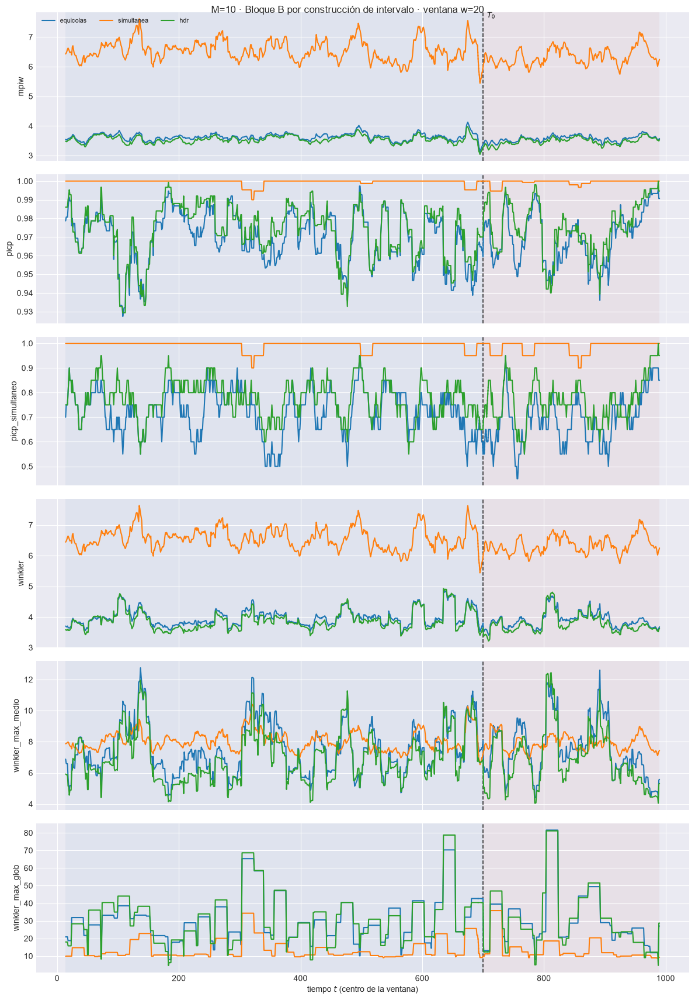

[plot_ventana_movil] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  mpiw: w=30 train=3.657  w=30 test=3.601


  2/6 (33.3%) t=0.0s eta=0.1s  picp: w=30 train=0.9804  w=30 test=0.98


  3/6 (50.0%) t=0.1s eta=0.1s  picp_simultaneo: w=30 train=0.8  w=30 test=0.7667


  4/6 (66.7%) t=0.1s eta=0.0s  winkler: w=30 train=4.096  w=30 test=3.976


  5/6 (83.3%) t=0.1s eta=0.0s  winkler_max_medio: w=30 train=7.62  w=30 test=7.612


  6/6 (100.0%) t=0.1s eta=0.0s  winkler_max_glob: w=30 train=28.75  w=30 test=25.25


[plot_ventana_movil] listo: 6 pasos en 1.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_m10\59_ventana_intervalos_w30.png


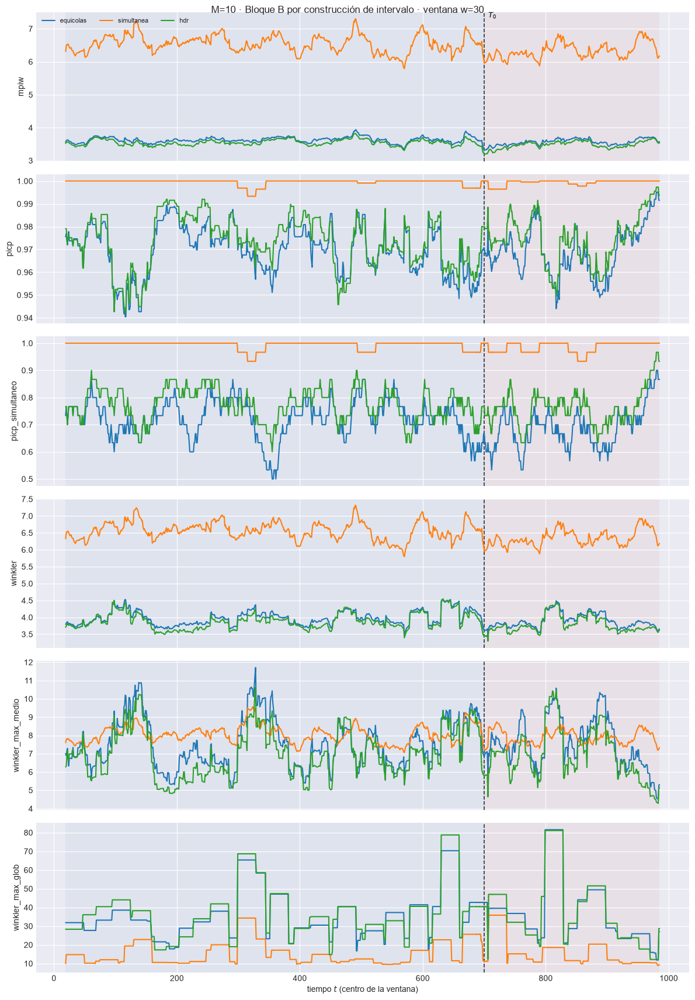

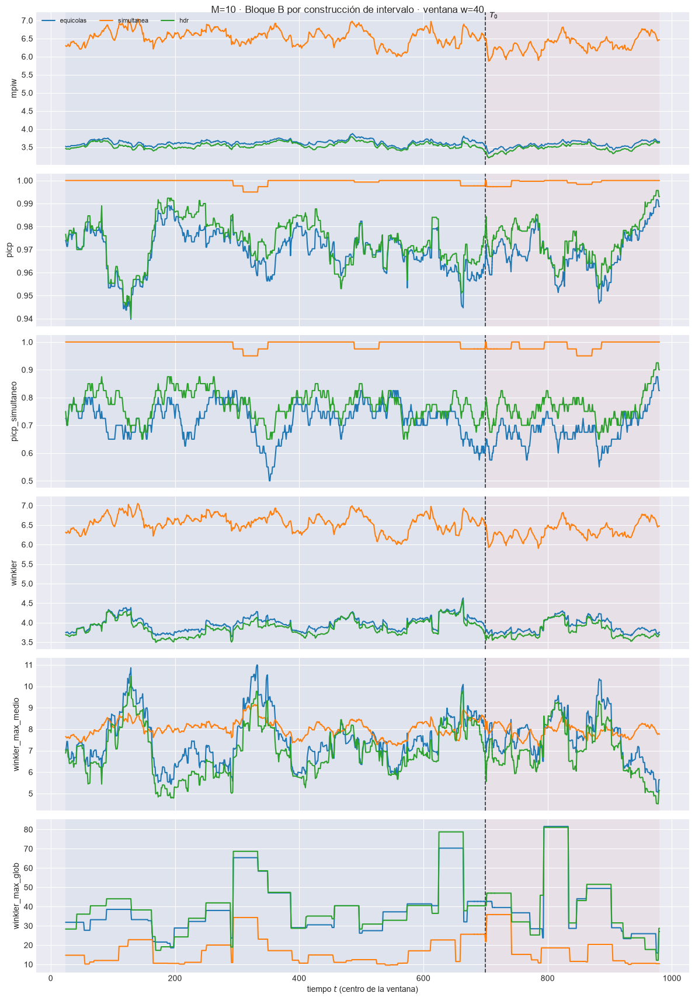

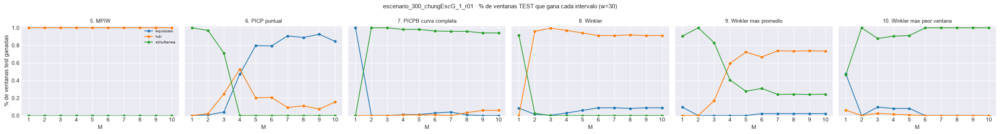

M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
simultanea,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
hdr,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,0.0%,0.7%,4.1%,47.2%,79.7%,79.3%,90.8%,88.9%,92.6%,84.5%
simultanea,100.0%,97.0%,71.2%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
hdr,0.0%,2.2%,24.7%,52.8%,20.3%,20.7%,9.2%,11.1%,7.4%,15.5%


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,100.0%,0.0%,0.0%,1.1%,1.1%,3.0%,4.1%,0.7%,0.0%,0.0%
simultanea,0.0%,100.0%,100.0%,98.2%,98.2%,96.3%,95.9%,95.9%,94.1%,94.1%
hdr,0.0%,0.0%,0.0%,0.7%,0.7%,0.7%,0.0%,3.3%,5.9%,5.9%


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,8.5%,1.5%,0.4%,3.0%,5.9%,8.9%,8.9%,8.1%,8.9%,8.9%
simultanea,91.5%,2.6%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
hdr,0.0%,95.9%,99.6%,97.0%,94.1%,91.1%,91.1%,91.9%,91.1%,91.1%


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,9.6%,0.0%,0.0%,0.0%,0.0%,2.2%,2.2%,2.2%,2.2%,2.2%
simultanea,90.4%,100.0%,83.0%,40.6%,27.7%,31.0%,24.0%,24.4%,24.0%,24.4%
hdr,0.0%,0.0%,17.0%,59.4%,72.3%,66.8%,73.8%,73.4%,73.8%,73.4%


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,47.6%,0.0%,9.6%,8.1%,8.1%,0.0%,0.0%,0.0%,0.0%,0.0%
simultanea,46.1%,100.0%,87.8%,90.4%,91.1%,100.0%,100.0%,100.0%,100.0%,100.0%
hdr,6.3%,0.0%,2.6%,1.5%,0.7%,0.0%,0.0%,0.0%,0.0%,0.0%


In [14]:
for M in (m for m in M_DETALLE if m in M_OK):
    for w in VENTANAS_W:
        ti = filtrar_ventana(EST[M]["tablas_fun"][w], predictor="esperanza")
        ti.attrs["w"] = w
        plot_ventana_movil(
            ti, T0, METRICAS_B_COLS, columna_grupo="intervalo",
            title=f"M={M} · Bloque B por construcción de intervalo · ventana w={w}",
            save_path=str(EST[M]["paths"]["out_report"] / f"59_ventana_intervalos_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

for M in M_OK:
    EST[M]["ventana_int"] = filtrar_ventana(EST[M]["tablas_fun"][W_REF], predictor="esperanza")
GANA_I, REL_I = ganadores_por_ventana(EST, "ventana_int", "intervalo", METRICAS_B, NIVEL)
GANA_I.to_csv(PATH_BARRIDO / f"109_ganador_intervalo_w{W_REF}.csv", index=False)
plot_ganador_grupo_vs_M(GANA_I, "intervalo", METRICAS_B,
                        f"{EXPERIMENT_BASE} · % de ventanas TEST que gana cada intervalo (w={W_REF})",
                        save_path=PATH_BARRIDO / f"109_ganador_intervalo_w{W_REF}.png")
plt.show()
for etiqueta, _c in METRICAS_B:
    display(GANA_I[(GANA_I.metrica == etiqueta) & (GANA_I.bloque == "test")]
            .pivot(index="intervalo", columns="M", values="pct_ventanas_ganadas").loc[list(INTERVALOS)]
            .style.format("{:.1%}").background_gradient(cmap="RdYlGn", axis=None)
            .set_caption(f"{etiqueta} · % de ventanas TEST ganadas por cada intervalo (w={W_REF})"))

## 6. Muestra de predicciones

Ventana de detalle, frontera train/test y ventanas con peor `METRICA_PEORES`.

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.1s  t=807 [test] cob=0.533 rmse=0.7809


  2/10 (20.0%) t=0.0s eta=0.1s  t=808 [test] cob=0.240 rmse=2.236


  3/10 (30.0%) t=0.0s eta=0.1s  t=809 [test] cob=0.653 rmse=1.111


  4/10 (40.0%) t=0.0s eta=0.0s  t=810 [test] cob=0.747 rmse=0.4736


...

  7/10 (70.0%) t=0.0s eta=0.0s  t=813 [test] cob=0.560 rmse=0.5989


  8/10 (80.0%) t=0.1s eta=0.0s  t=814 [test] cob=0.400 rmse=2.099


  9/10 (90.0%) t=0.1s eta=0.0s  t=815 [test] cob=0.360 rmse=1.367


  10/10 (100.0%) t=0.1s eta=0.0s  t=816 [test] cob=0.640 rmse=1.202


[plot_extractos_curvas] listo: 10 pasos en 1.6s  cob media train=nan test=0.489 (nominal 0.95)


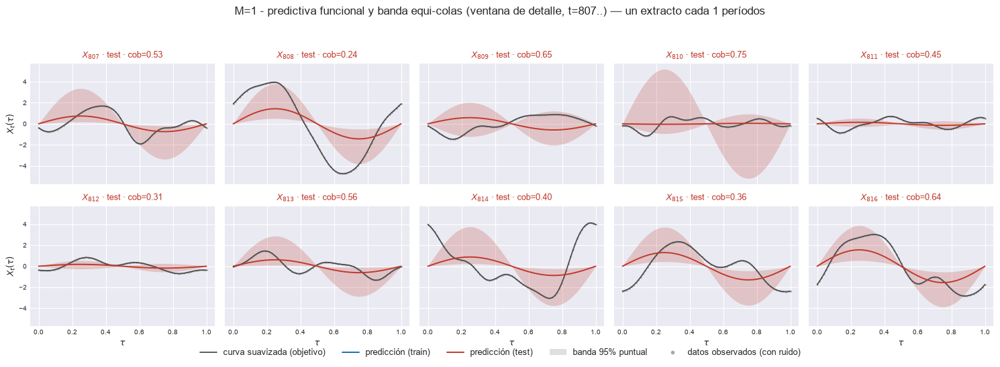

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.1s  t=807 [test] cob=0.773 rmse=0.9369


  2/10 (20.0%) t=0.0s eta=0.0s  t=808 [test] cob=0.480 rmse=2.095


  3/10 (30.0%) t=0.0s eta=0.0s  t=809 [test] cob=1.000 rmse=1.201


  4/10 (40.0%) t=0.0s eta=0.0s  t=810 [test] cob=0.933 rmse=0.4889


...

  7/10 (70.0%) t=0.1s eta=0.0s  t=813 [test] cob=0.880 rmse=0.5993


  8/10 (80.0%) t=0.1s eta=0.0s  t=814 [test] cob=0.613 rmse=1.8


  9/10 (90.0%) t=0.1s eta=0.0s  t=815 [test] cob=0.880 rmse=0.8054


  10/10 (100.0%) t=0.1s eta=0.0s  t=816 [test] cob=0.893 rmse=0.9892


[plot_extractos_curvas] listo: 10 pasos en 1.6s  cob media train=nan test=0.801 (nominal 0.95)


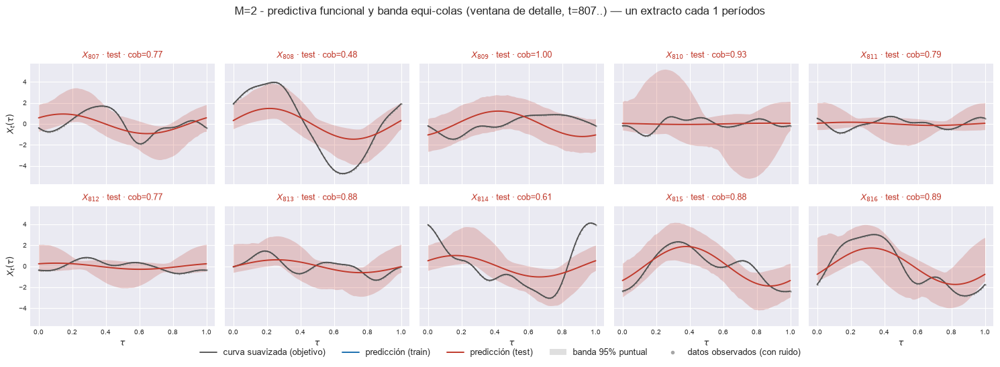

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=807 [test] cob=1.000 rmse=0.6089


  2/10 (20.0%) t=0.0s eta=0.0s  t=808 [test] cob=0.493 rmse=2.058


  3/10 (30.0%) t=0.0s eta=0.0s  t=809 [test] cob=0.987 rmse=1.199


  4/10 (40.0%) t=0.0s eta=0.0s  t=810 [test] cob=1.000 rmse=0.4907


...

  7/10 (70.0%) t=0.0s eta=0.0s  t=813 [test] cob=1.000 rmse=0.3391


  8/10 (80.0%) t=0.0s eta=0.0s  t=814 [test] cob=0.693 rmse=1.836


  9/10 (90.0%) t=0.1s eta=0.0s  t=815 [test] cob=0.907 rmse=0.786


  10/10 (100.0%) t=0.1s eta=0.0s  t=816 [test] cob=0.920 rmse=0.9891


[plot_extractos_curvas] listo: 10 pasos en 1.6s  cob media train=nan test=0.893 (nominal 0.95)


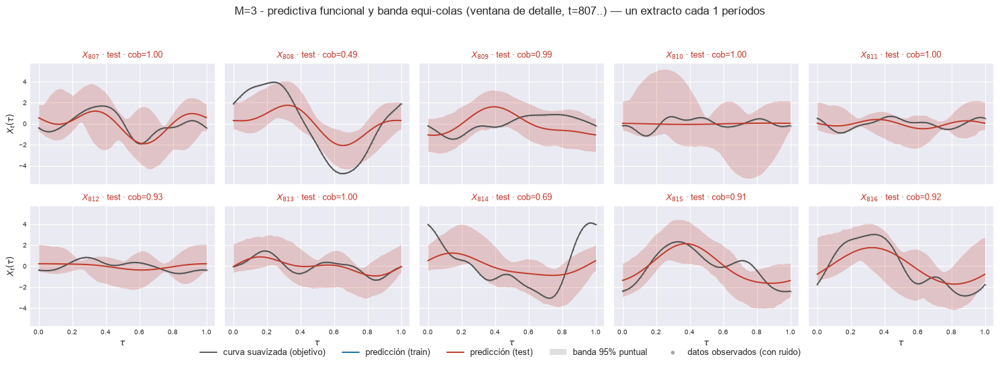

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=807 [test] cob=1.000 rmse=0.6232


  2/10 (20.0%) t=0.0s eta=0.0s  t=808 [test] cob=0.547 rmse=2.06


  3/10 (30.0%) t=0.0s eta=0.0s  t=809 [test] cob=0.973 rmse=1.217


  4/10 (40.0%) t=0.0s eta=0.0s  t=810 [test] cob=1.000 rmse=0.5503


...

  7/10 (70.0%) t=0.0s eta=0.0s  t=813 [test] cob=1.000 rmse=0.3919


  8/10 (80.0%) t=0.1s eta=0.0s  t=814 [test] cob=0.787 rmse=1.77


  9/10 (90.0%) t=0.1s eta=0.0s  t=815 [test] cob=1.000 rmse=0.4419


  10/10 (100.0%) t=0.1s eta=0.0s  t=816 [test] cob=1.000 rmse=0.8644


[plot_extractos_curvas] listo: 10 pasos en 1.7s  cob media train=nan test=0.931 (nominal 0.95)


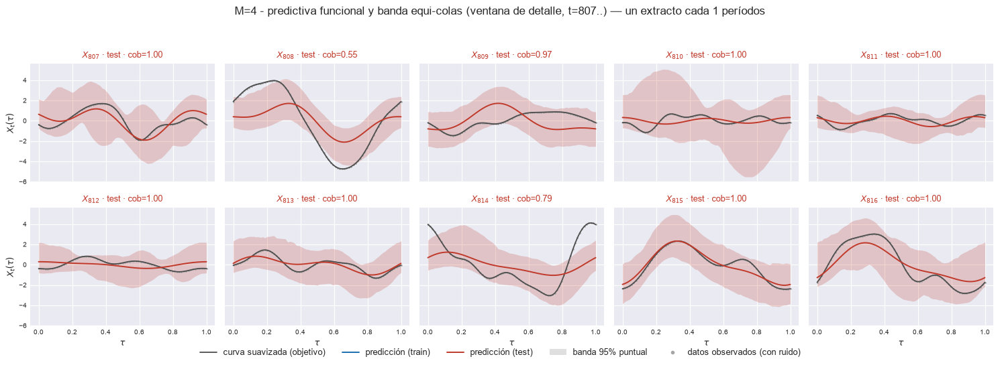

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=807 [test] cob=1.000 rmse=0.6137


  2/10 (20.0%) t=0.0s eta=0.1s  t=808 [test] cob=0.547 rmse=2.062


  3/10 (30.0%) t=0.0s eta=0.1s  t=809 [test] cob=1.000 rmse=1.215


  4/10 (40.0%) t=0.0s eta=0.1s  t=810 [test] cob=1.000 rmse=0.5503


...

  7/10 (70.0%) t=0.1s eta=0.0s  t=813 [test] cob=1.000 rmse=0.383


  8/10 (80.0%) t=0.1s eta=0.0s  t=814 [test] cob=0.787 rmse=1.764


  9/10 (90.0%) t=0.1s eta=0.0s  t=815 [test] cob=1.000 rmse=0.4934


  10/10 (100.0%) t=0.1s eta=0.0s  t=816 [test] cob=1.000 rmse=0.8435


[plot_extractos_curvas] listo: 10 pasos en 1.5s  cob media train=nan test=0.933 (nominal 0.95)


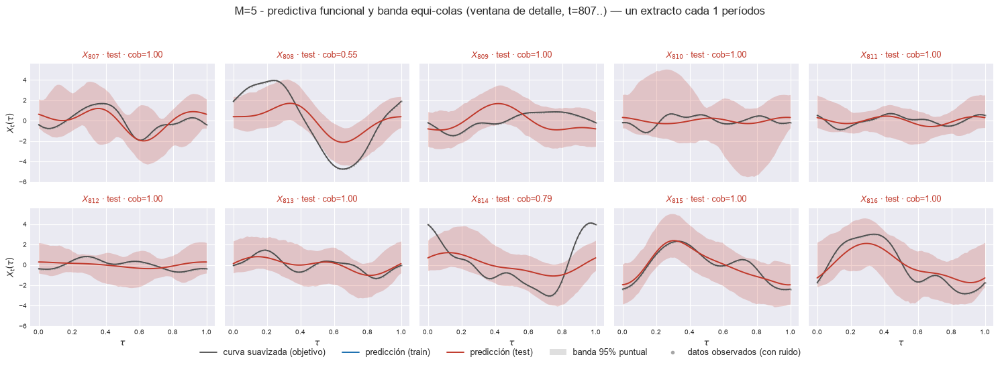

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=807 [test] cob=1.000 rmse=0.6137


  2/10 (20.0%) t=0.0s eta=0.0s  t=808 [test] cob=0.547 rmse=2.062


  3/10 (30.0%) t=0.0s eta=0.0s  t=809 [test] cob=1.000 rmse=1.216


  4/10 (40.0%) t=0.0s eta=0.0s  t=810 [test] cob=1.000 rmse=0.5502


...

  7/10 (70.0%) t=0.0s eta=0.0s  t=813 [test] cob=1.000 rmse=0.3857


  8/10 (80.0%) t=0.1s eta=0.0s  t=814 [test] cob=0.787 rmse=1.765


  9/10 (90.0%) t=0.1s eta=0.0s  t=815 [test] cob=1.000 rmse=0.493


  10/10 (100.0%) t=0.1s eta=0.0s  t=816 [test] cob=1.000 rmse=0.8435


[plot_extractos_curvas] listo: 10 pasos en 1.6s  cob media train=nan test=0.933 (nominal 0.95)


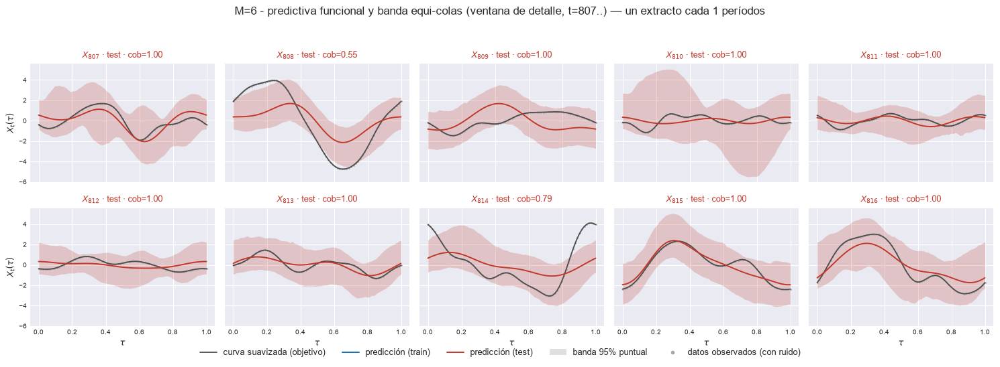

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.1s  t=807 [test] cob=1.000 rmse=0.6067


  2/10 (20.0%) t=0.0s eta=0.1s  t=808 [test] cob=0.533 rmse=2.063


  3/10 (30.0%) t=0.0s eta=0.0s  t=809 [test] cob=1.000 rmse=1.215


  4/10 (40.0%) t=0.0s eta=0.0s  t=810 [test] cob=1.000 rmse=0.5456


...

  7/10 (70.0%) t=0.1s eta=0.0s  t=813 [test] cob=1.000 rmse=0.3874


  8/10 (80.0%) t=0.1s eta=0.0s  t=814 [test] cob=0.787 rmse=1.764


  9/10 (90.0%) t=0.1s eta=0.0s  t=815 [test] cob=1.000 rmse=0.4909


  10/10 (100.0%) t=0.1s eta=0.0s  t=816 [test] cob=1.000 rmse=0.8422


[plot_extractos_curvas] listo: 10 pasos en 1.8s  cob media train=nan test=0.932 (nominal 0.95)


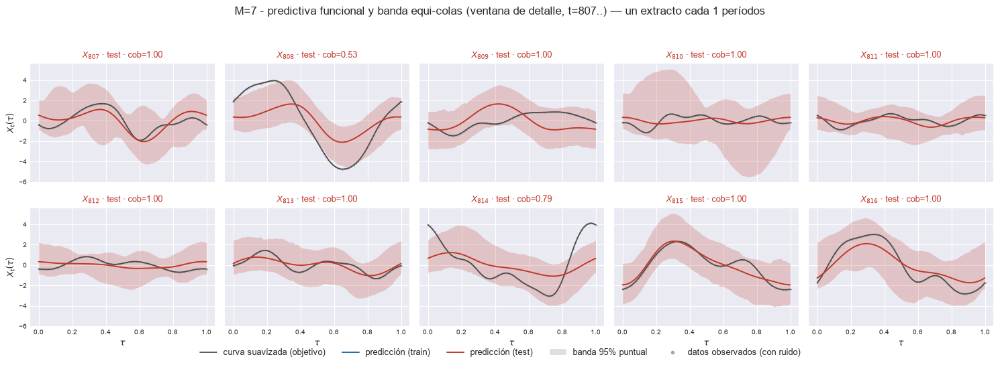

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.1s  t=807 [test] cob=1.000 rmse=0.608


  2/10 (20.0%) t=0.0s eta=0.1s  t=808 [test] cob=0.533 rmse=2.063


  3/10 (30.0%) t=0.0s eta=0.0s  t=809 [test] cob=1.000 rmse=1.215


  4/10 (40.0%) t=0.0s eta=0.0s  t=810 [test] cob=1.000 rmse=0.5414


...

  7/10 (70.0%) t=0.1s eta=0.0s  t=813 [test] cob=1.000 rmse=0.3848


  8/10 (80.0%) t=0.1s eta=0.0s  t=814 [test] cob=0.787 rmse=1.761


  9/10 (90.0%) t=0.1s eta=0.0s  t=815 [test] cob=1.000 rmse=0.4894


  10/10 (100.0%) t=0.1s eta=0.0s  t=816 [test] cob=1.000 rmse=0.8429


[plot_extractos_curvas] listo: 10 pasos en 2.0s  cob media train=nan test=0.932 (nominal 0.95)


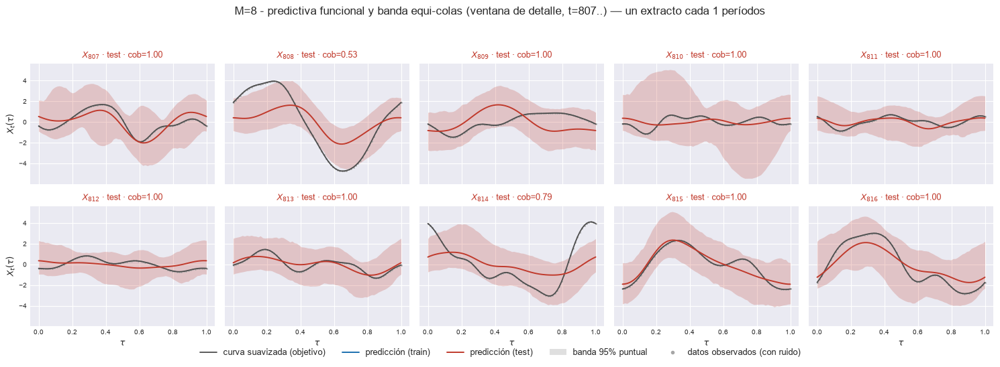

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=807 [test] cob=1.000 rmse=0.6093


  2/10 (20.0%) t=0.0s eta=0.0s  t=808 [test] cob=0.533 rmse=2.063


  3/10 (30.0%) t=0.0s eta=0.0s  t=809 [test] cob=1.000 rmse=1.215


  4/10 (40.0%) t=0.0s eta=0.0s  t=810 [test] cob=1.000 rmse=0.5414


...

  7/10 (70.0%) t=0.0s eta=0.0s  t=813 [test] cob=1.000 rmse=0.3838


  8/10 (80.0%) t=0.1s eta=0.0s  t=814 [test] cob=0.787 rmse=1.763


  9/10 (90.0%) t=0.1s eta=0.0s  t=815 [test] cob=1.000 rmse=0.4919


  10/10 (100.0%) t=0.1s eta=0.0s  t=816 [test] cob=1.000 rmse=0.8428


[plot_extractos_curvas] listo: 10 pasos en 1.6s  cob media train=nan test=0.932 (nominal 0.95)


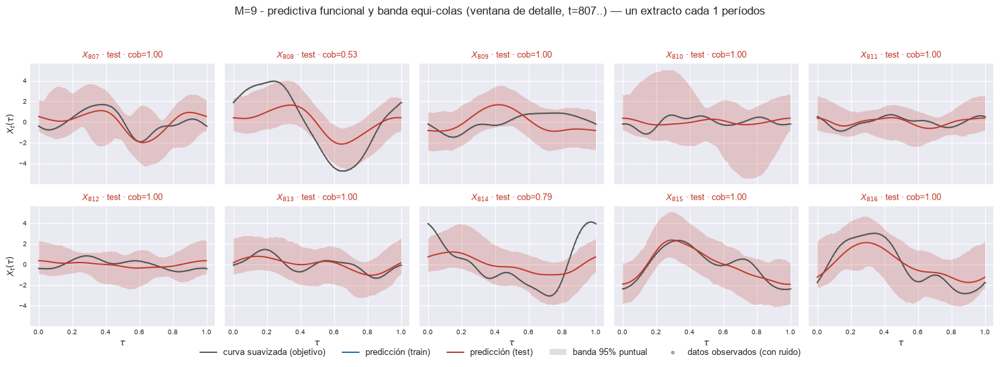

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=807 [test] cob=1.000 rmse=0.608


  2/10 (20.0%) t=0.0s eta=0.0s  t=808 [test] cob=0.533 rmse=2.063


  3/10 (30.0%) t=0.0s eta=0.0s  t=809 [test] cob=1.000 rmse=1.216


  4/10 (40.0%) t=0.0s eta=0.0s  t=810 [test] cob=1.000 rmse=0.541


...

  7/10 (70.0%) t=0.0s eta=0.0s  t=813 [test] cob=1.000 rmse=0.3837


  8/10 (80.0%) t=0.1s eta=0.0s  t=814 [test] cob=0.787 rmse=1.763


  9/10 (90.0%) t=0.1s eta=0.0s  t=815 [test] cob=1.000 rmse=0.4921


  10/10 (100.0%) t=0.1s eta=0.0s  t=816 [test] cob=1.000 rmse=0.8426


[plot_extractos_curvas] listo: 10 pasos en 1.5s  cob media train=nan test=0.932 (nominal 0.95)


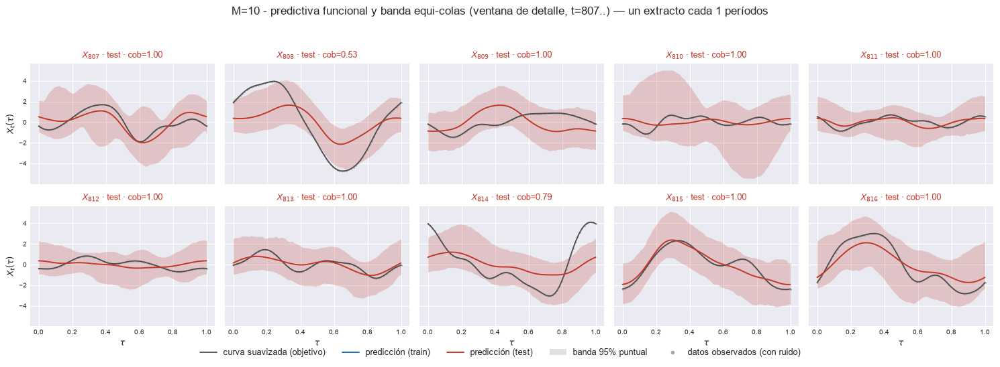

In [15]:
# Los N_DETALLE orígenes de la ventana de detalle (§3.2).
for M in M_OK:
    e = EST[M]
    plot_extractos_curvas(
        X_obj_ev[IDX_DET], e["X_pred"][IDX_DET], e["li_f"][IDX_DET], e["ls_f"][IDX_DET],
        grilla, T0, t=T_DET, cada=1, n_col=5, nivel=NIVEL,
        etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[IDX_DET],
        title=f"M={M} - predictiva funcional y banda equi-colas (ventana de detalle, t={T0_DET}..)",
        save_path=str(e["paths"]["out_report"] / "54_extractos_curvas_test.png"), verbose=True)
    plt.show()

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=0.493 rmse=1.158


  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.520 rmse=1.595


  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.707 rmse=0.8517


  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=0.133 rmse=0.7641


  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=0.413 rmse=0.5458


  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=0.147 rmse=1.192


  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=0.320 rmse=0.601


[plot_extractos_curvas] listo: 7 pasos en 1.5s  cob media train=0.463 test=0.293 (nominal 0.95)


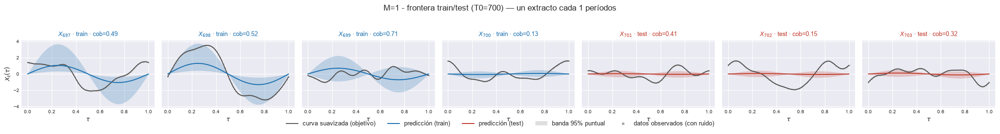

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=0.973 rmse=0.9477


  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.880 rmse=1.604


  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.840 rmse=0.9079


  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=0.800 rmse=0.6433


  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=0.880 rmse=0.4594


  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=0.800 rmse=0.8265


  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=0.867 rmse=0.4658


[plot_extractos_curvas] listo: 7 pasos en 1.3s  cob media train=0.873 test=0.849 (nominal 0.95)


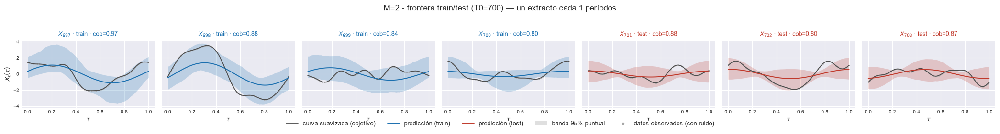

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.9432


  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.920 rmse=1.6


  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.907 rmse=0.9205


  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=0.880 rmse=0.6218


  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=0.920 rmse=0.4609


  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=0.773 rmse=0.8901


  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=0.907 rmse=0.4638


[plot_extractos_curvas] listo: 7 pasos en 1.4s  cob media train=0.927 test=0.867 (nominal 0.95)


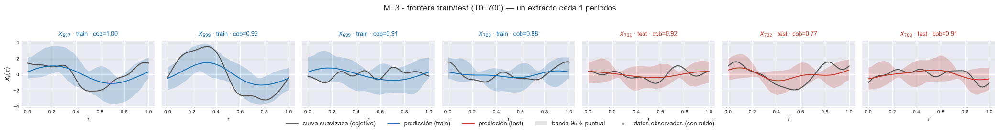

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.9442


  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.947 rmse=1.595


  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.920 rmse=0.9301


  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=1.000 rmse=0.5804


  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=0.960 rmse=0.3777


  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=0.880 rmse=0.8528


  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=1.000 rmse=0.3575


[plot_extractos_curvas] listo: 7 pasos en 1.3s  cob media train=0.967 test=0.947 (nominal 0.95)


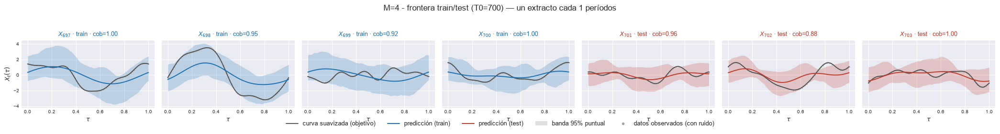

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.9513


  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.933 rmse=1.597


  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.933 rmse=0.9343


  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=1.000 rmse=0.5803


  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=1.000 rmse=0.3711


  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=0.920 rmse=0.8382


  7/7 (100.0%) t=0.1s eta=0.0s  t=703 [test] cob=1.000 rmse=0.3155


[plot_extractos_curvas] listo: 7 pasos en 1.7s  cob media train=0.967 test=0.973 (nominal 0.95)


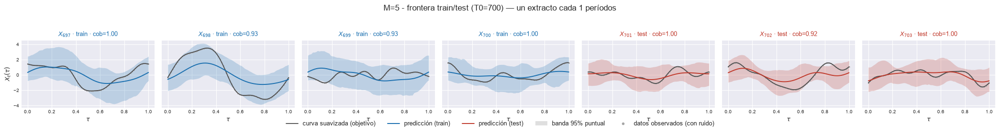

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.9503


  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.933 rmse=1.594


  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.933 rmse=0.9324


  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=1.000 rmse=0.5785


  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=1.000 rmse=0.37


  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=0.920 rmse=0.8393


  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=1.000 rmse=0.3078


[plot_extractos_curvas] listo: 7 pasos en 1.3s  cob media train=0.967 test=0.973 (nominal 0.95)


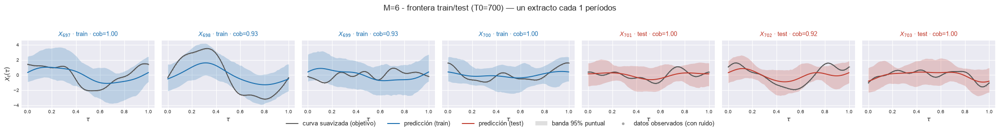

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.1s  t=697 [train] cob=1.000 rmse=0.9503


  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.933 rmse=1.594


  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.933 rmse=0.9306


  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=1.000 rmse=0.5757


  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=1.000 rmse=0.366


  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=0.920 rmse=0.8441


  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=1.000 rmse=0.3091


[plot_extractos_curvas] listo: 7 pasos en 1.4s  cob media train=0.967 test=0.973 (nominal 0.95)


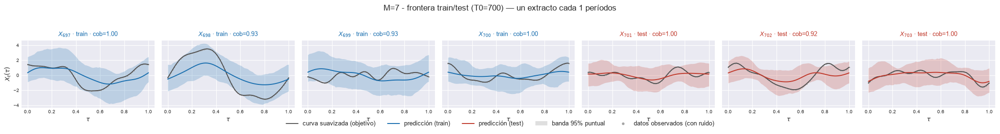

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.9501


  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.933 rmse=1.594


  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.933 rmse=0.9342


  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=1.000 rmse=0.5705


  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=1.000 rmse=0.3565


  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=0.920 rmse=0.8433


  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=1.000 rmse=0.3083


[plot_extractos_curvas] listo: 7 pasos en 1.3s  cob media train=0.967 test=0.973 (nominal 0.95)


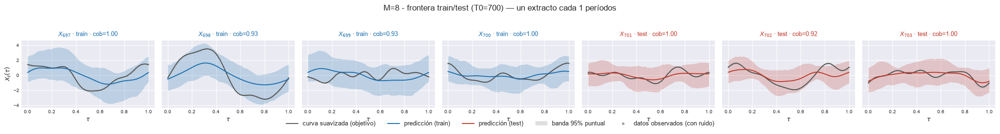

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.9502


  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.933 rmse=1.595


  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.933 rmse=0.9342


  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=1.000 rmse=0.5668


  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=1.000 rmse=0.3549


  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=0.920 rmse=0.8426


  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=1.000 rmse=0.2985


[plot_extractos_curvas] listo: 7 pasos en 1.4s  cob media train=0.967 test=0.973 (nominal 0.95)


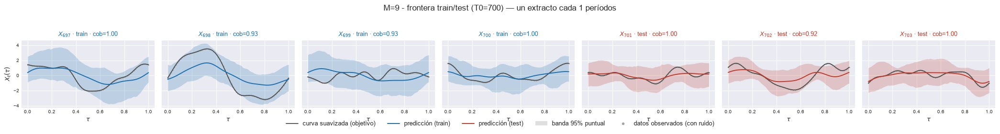

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.9497


  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.947 rmse=1.594


  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.933 rmse=0.9315


  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=1.000 rmse=0.5723


  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=1.000 rmse=0.3545


  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=0.920 rmse=0.8426


  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=1.000 rmse=0.2997


[plot_extractos_curvas] listo: 7 pasos en 1.4s  cob media train=0.970 test=0.973 (nominal 0.95)


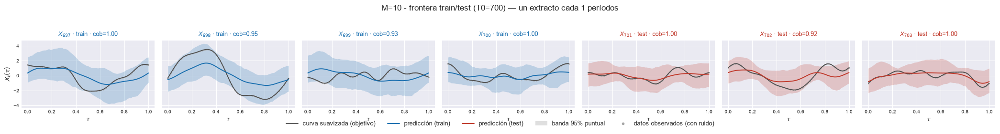

In [16]:
# Zoom sobre la frontera: los últimos orígenes de train y los primeros de test.
i_corte = int(np.searchsorted(t_orig, T0))
sel = np.arange(max(0, i_corte - 3), min(n_orig, i_corte + 4))
for M in M_OK:
    e = EST[M]
    plot_extractos_curvas(
        X_obj_ev[sel], e["X_pred"][sel], e["li_f"][sel], e["ls_f"][sel], grilla, T0,
        t=t_orig[sel], cada=1, n_col=len(sel), nivel=NIVEL,
        etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[sel],
        title=f"M={M} - frontera train/test (T0={T0})",
        save_path=str(e["paths"]["out_report"] / "55_extractos_frontera.png"), verbose=True)
    plt.show()

[M=1] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[792, 821]  rmse_f=1.065713


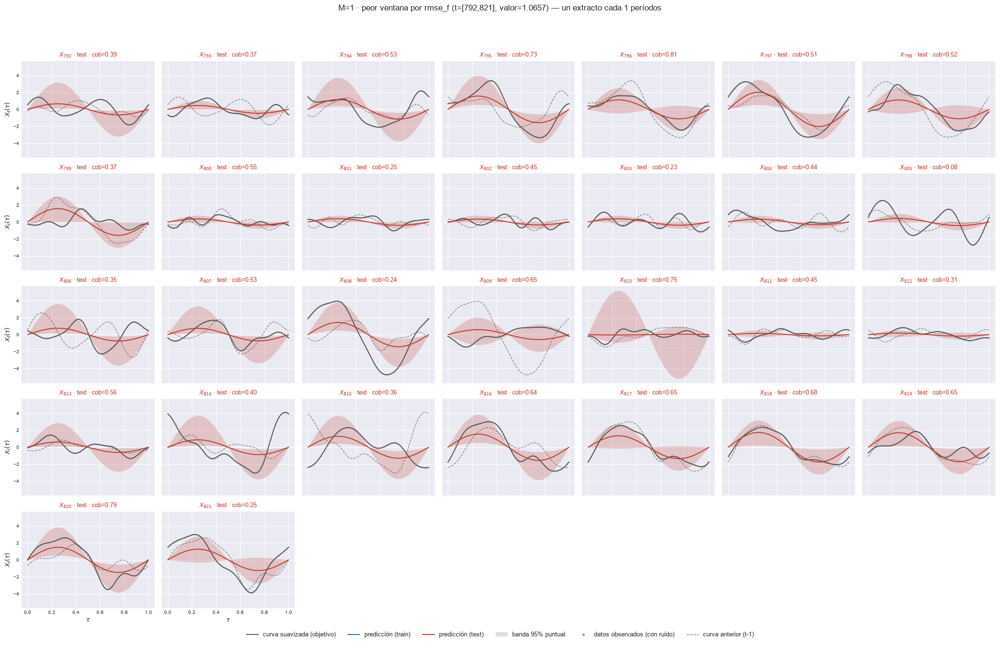

    t=[797, 826]  rmse_f=1.063117


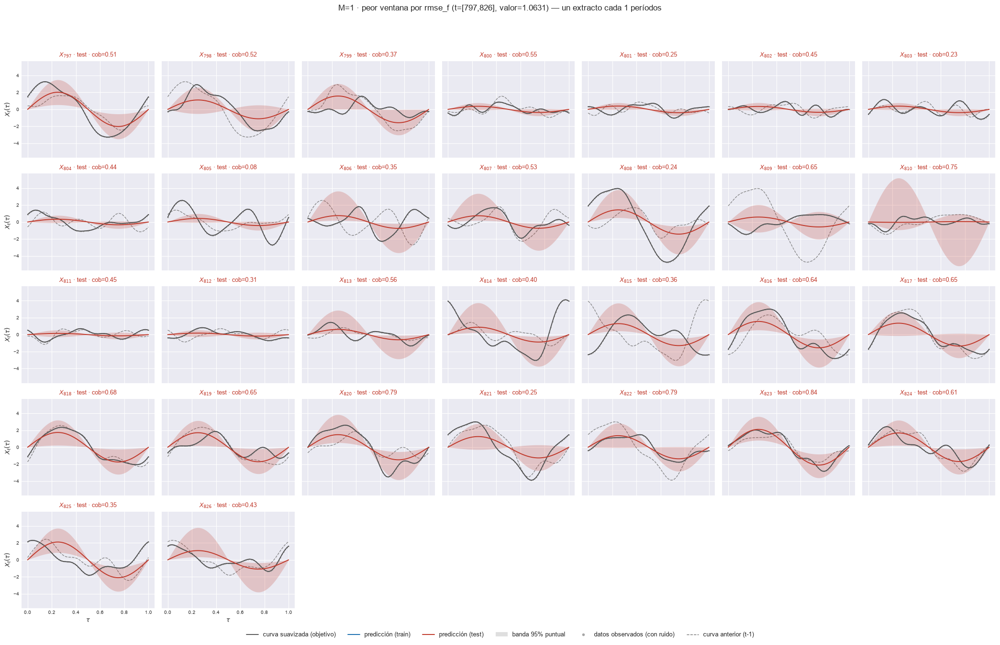

    t=[796, 825]  rmse_f=1.053609


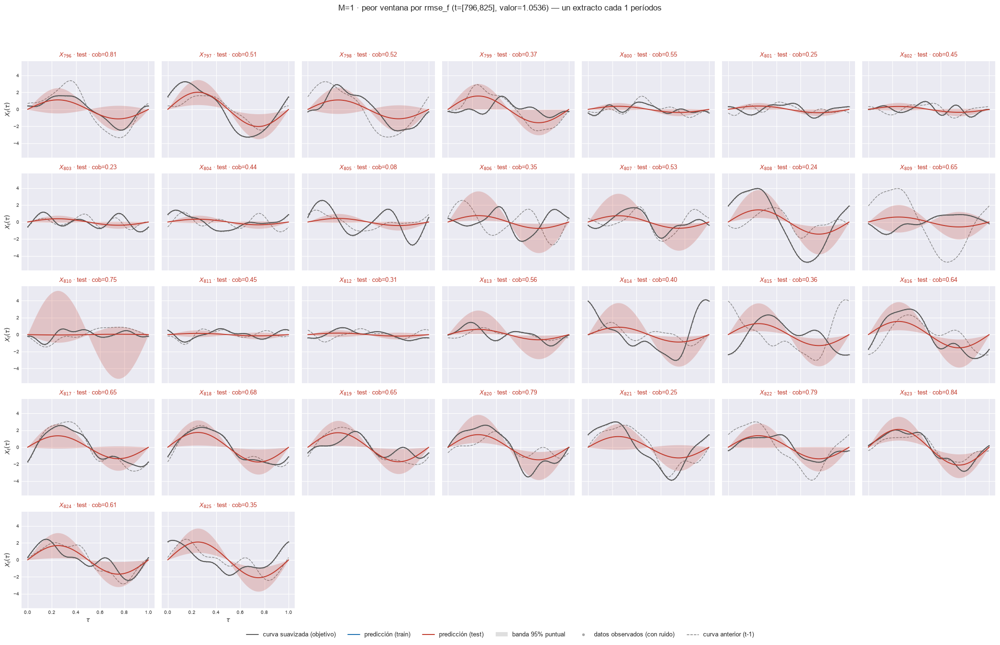

    t=[793, 822]  rmse_f=1.053342


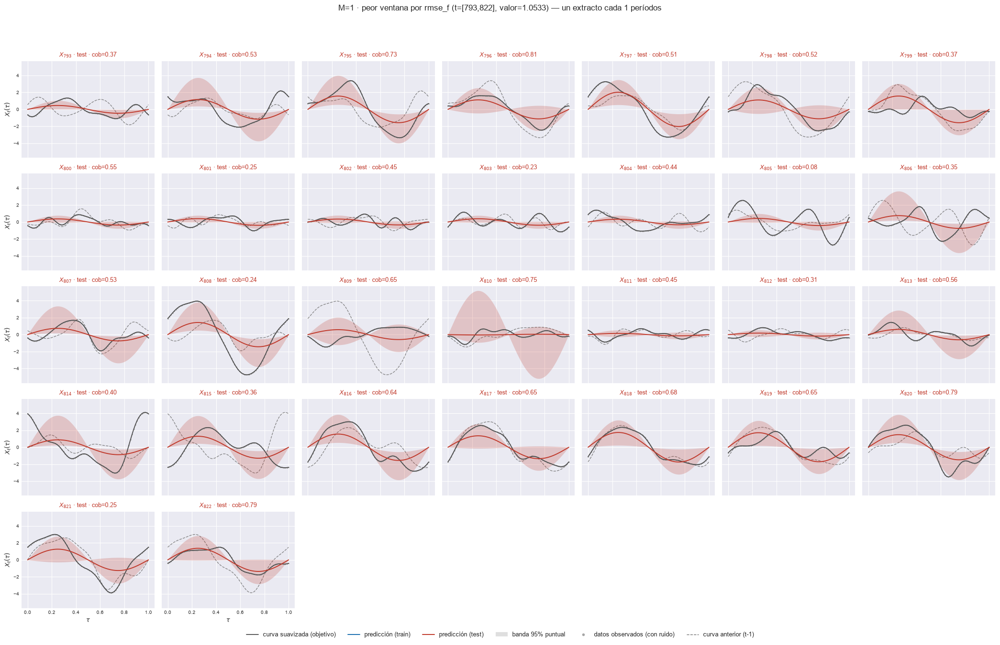

    t=[803, 832]  rmse_f=1.051537


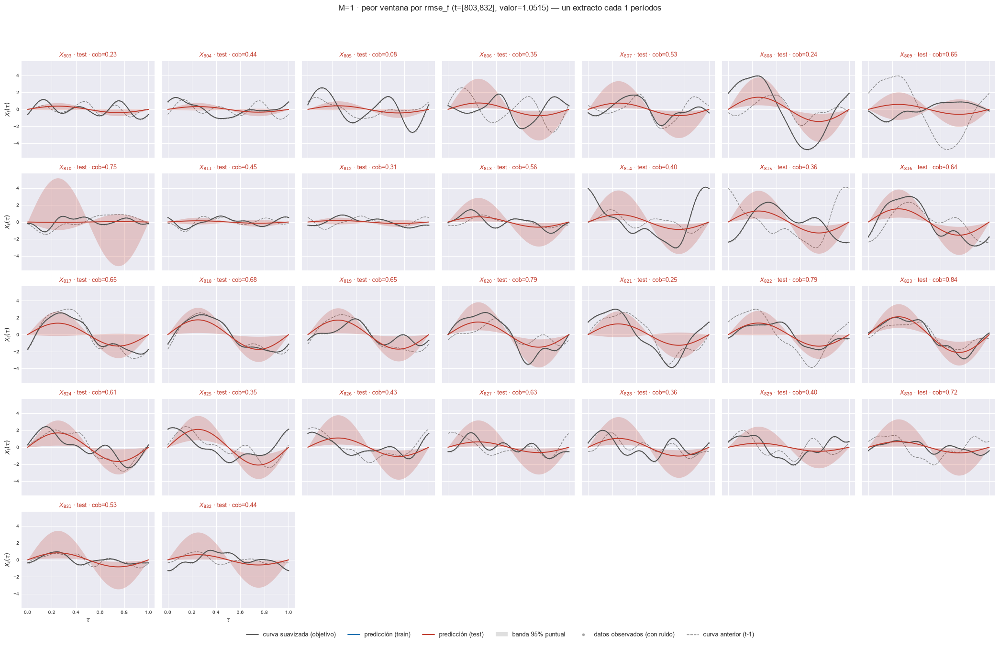

[M=2] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[805, 834]  rmse_f=0.979807


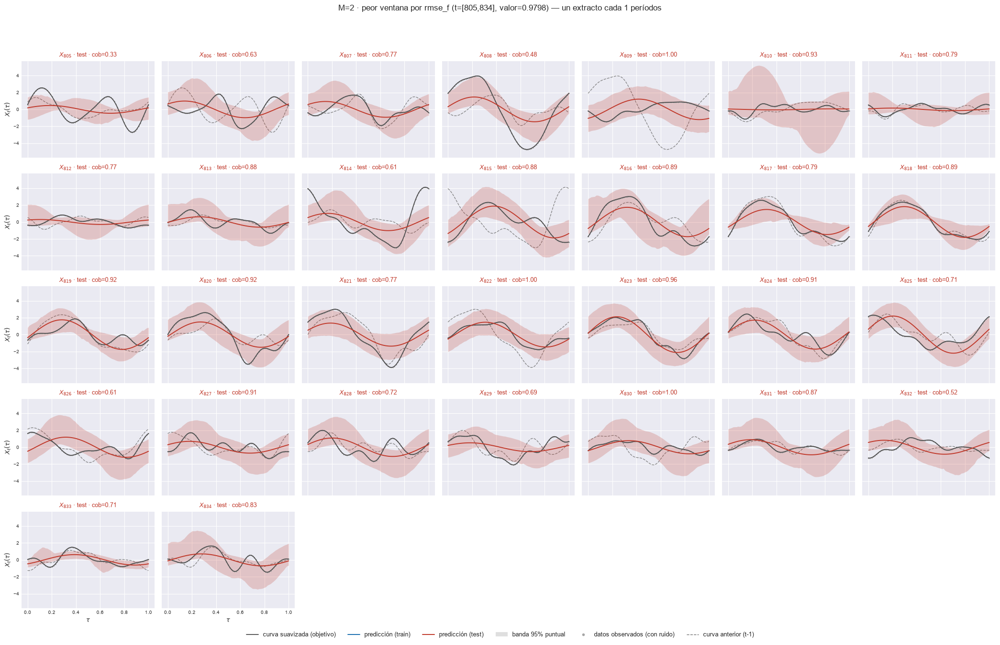

    t=[803, 832]  rmse_f=0.978621


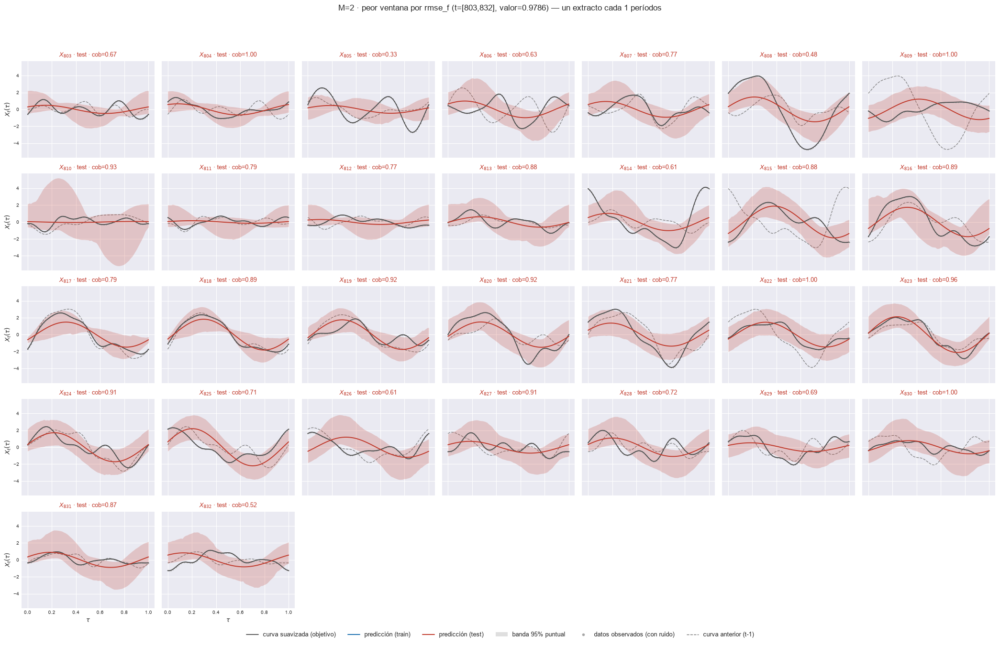

    t=[792, 821]  rmse_f=0.976242


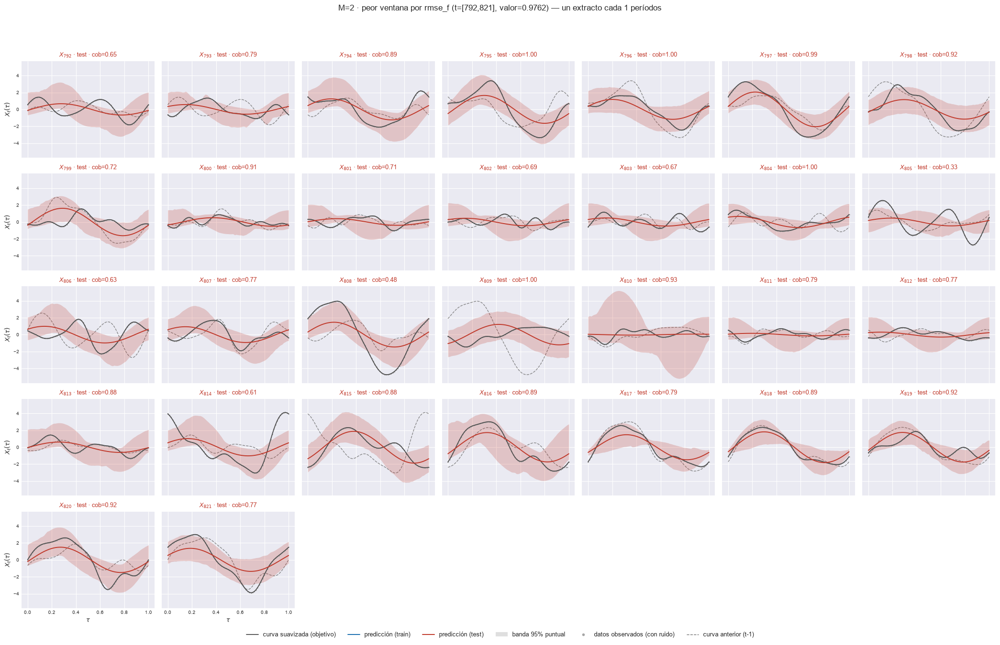

    t=[797, 826]  rmse_f=0.974865


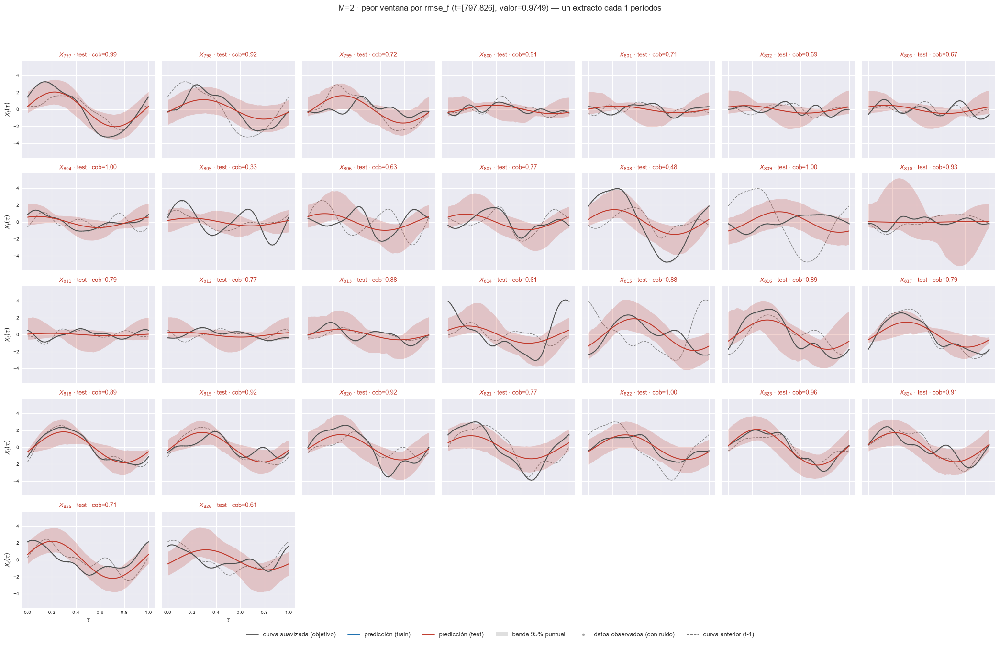

    t=[804, 833]  rmse_f=0.974704


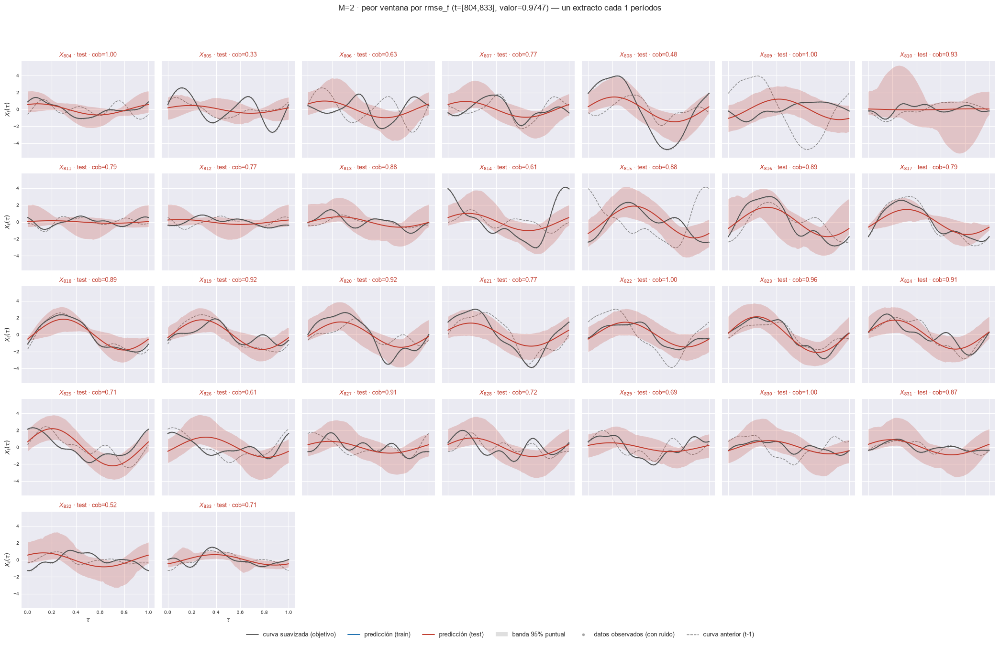

[M=3] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[808, 837]  rmse_f=0.933399


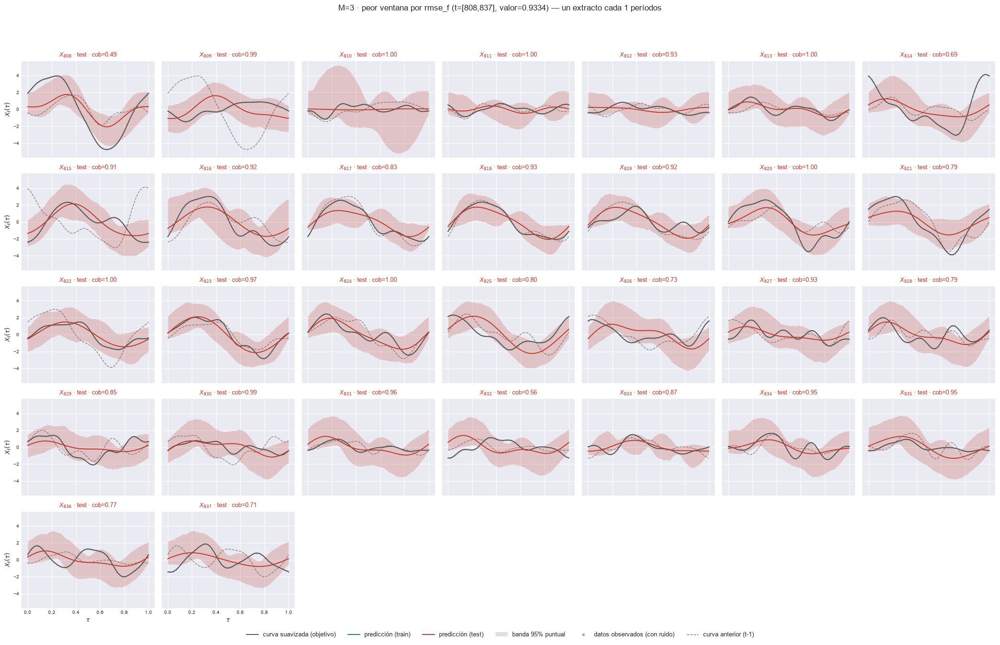

    t=[843, 872]  rmse_f=0.928352


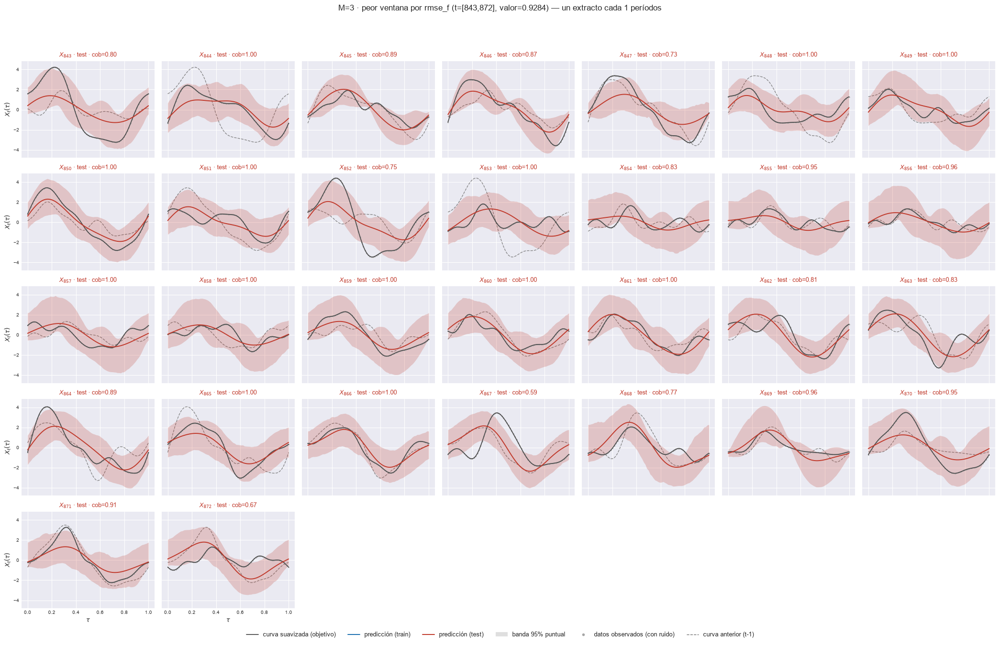

    t=[792, 821]  rmse_f=0.926214


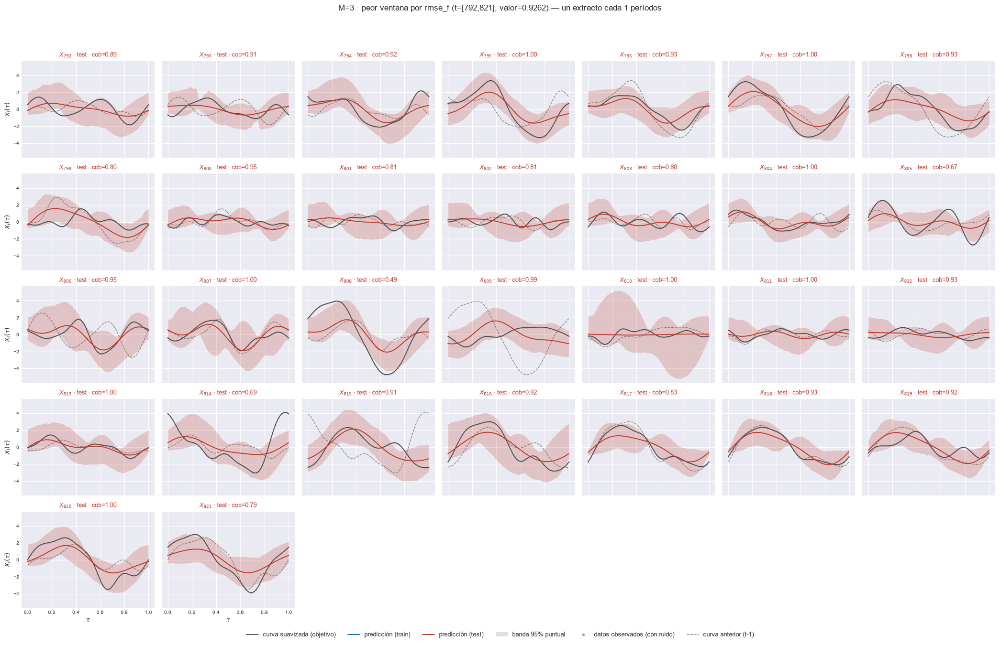

    t=[805, 834]  rmse_f=0.926038


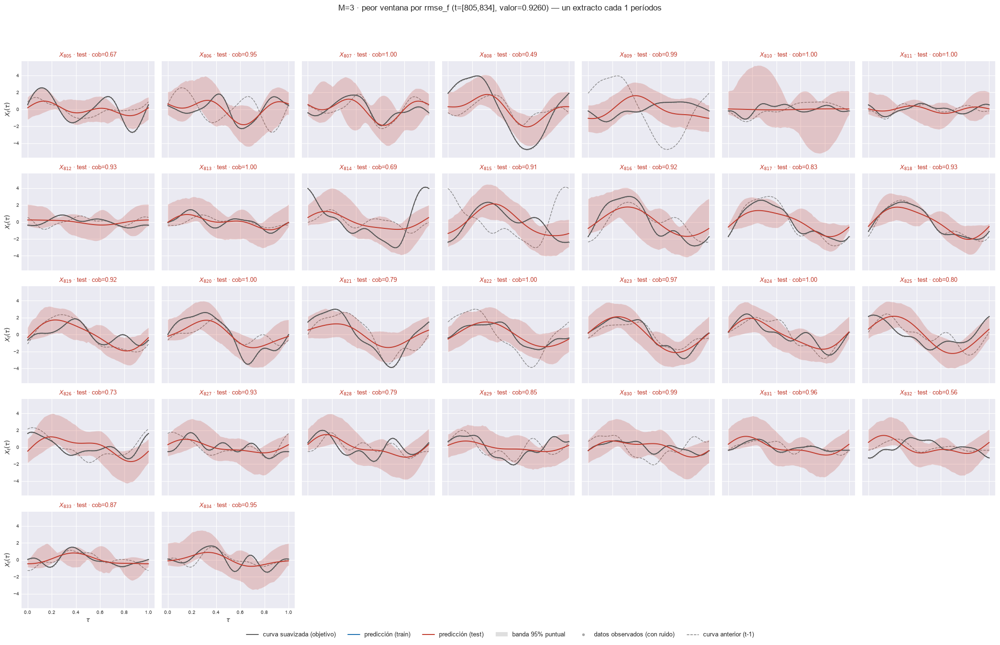

    t=[797, 826]  rmse_f=0.925597


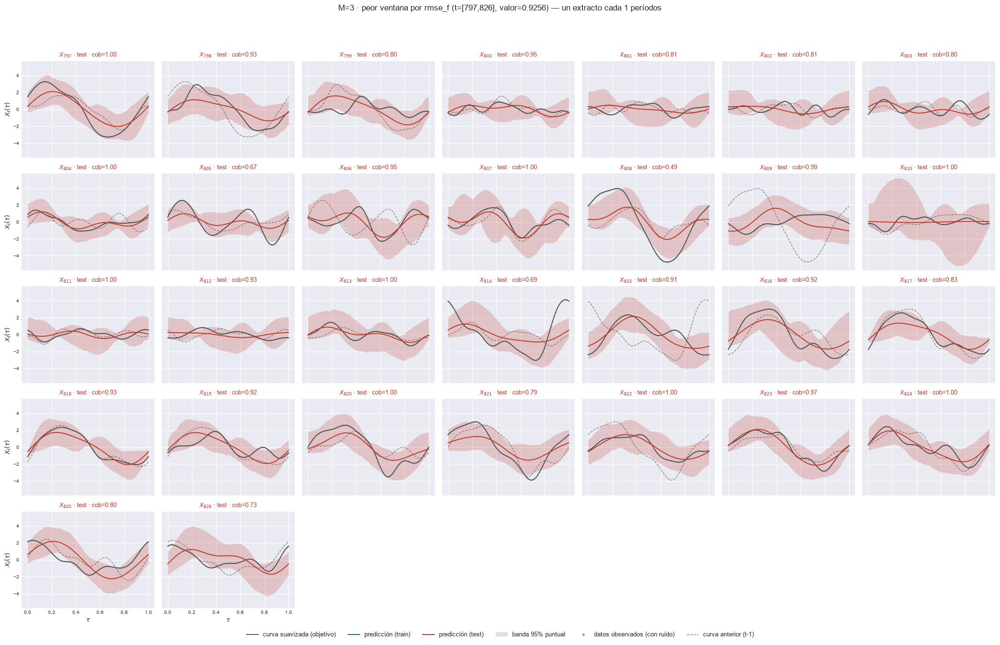

[M=4] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[808, 837]  rmse_f=0.905095


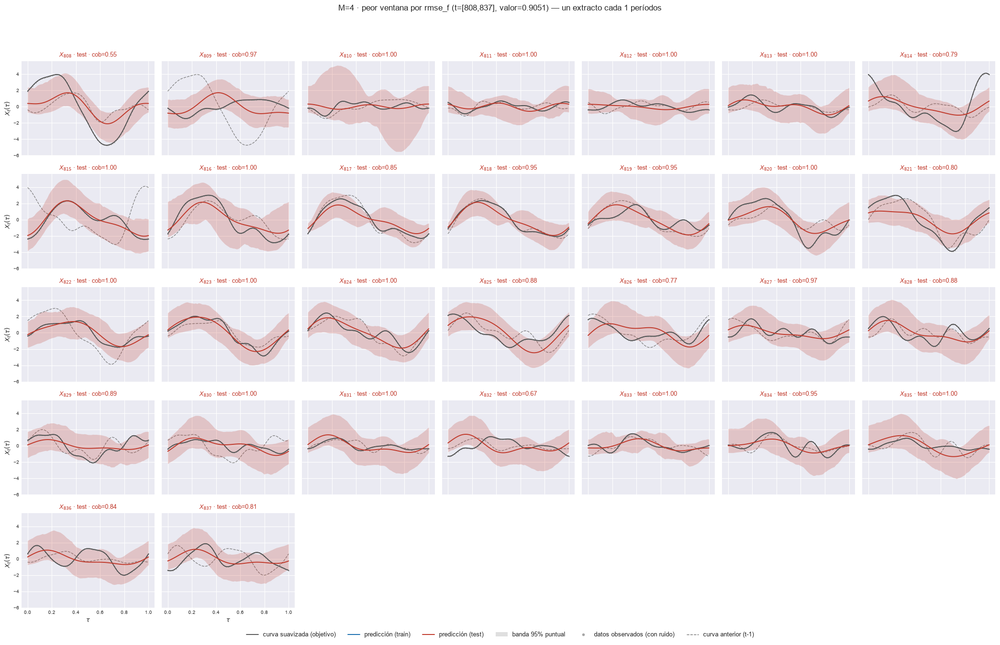

    t=[797, 826]  rmse_f=0.903781


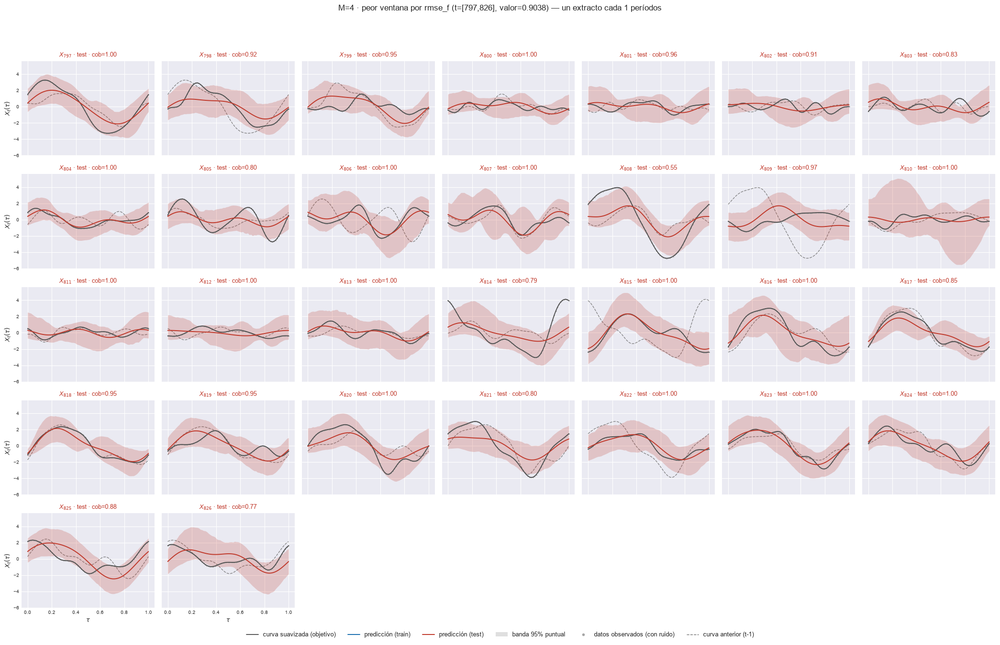

    t=[792, 821]  rmse_f=0.903270


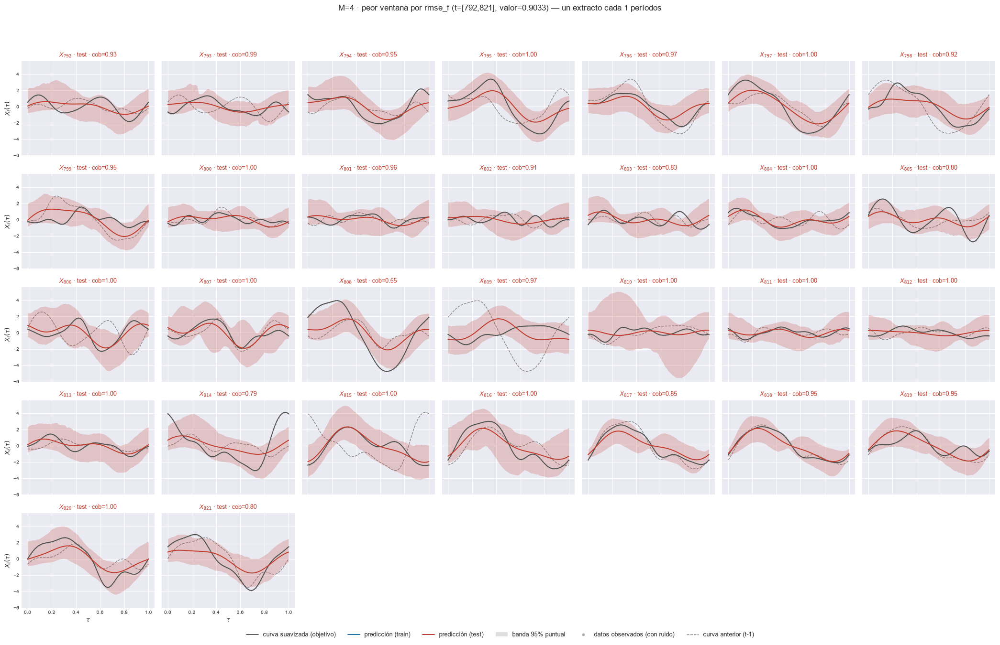

    t=[803, 832]  rmse_f=0.903241


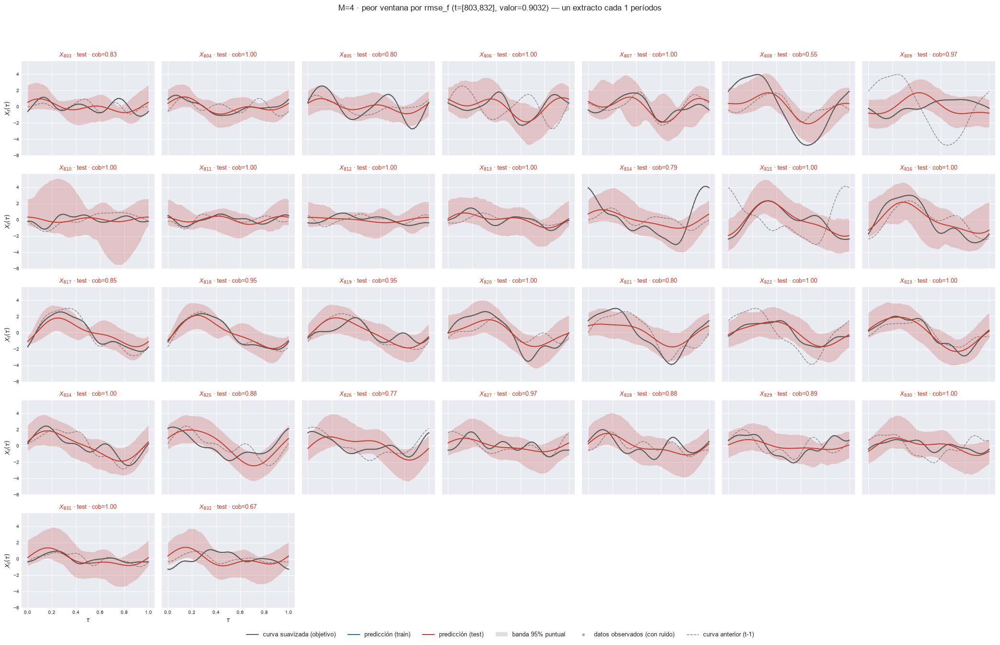

    t=[805, 834]  rmse_f=0.902241


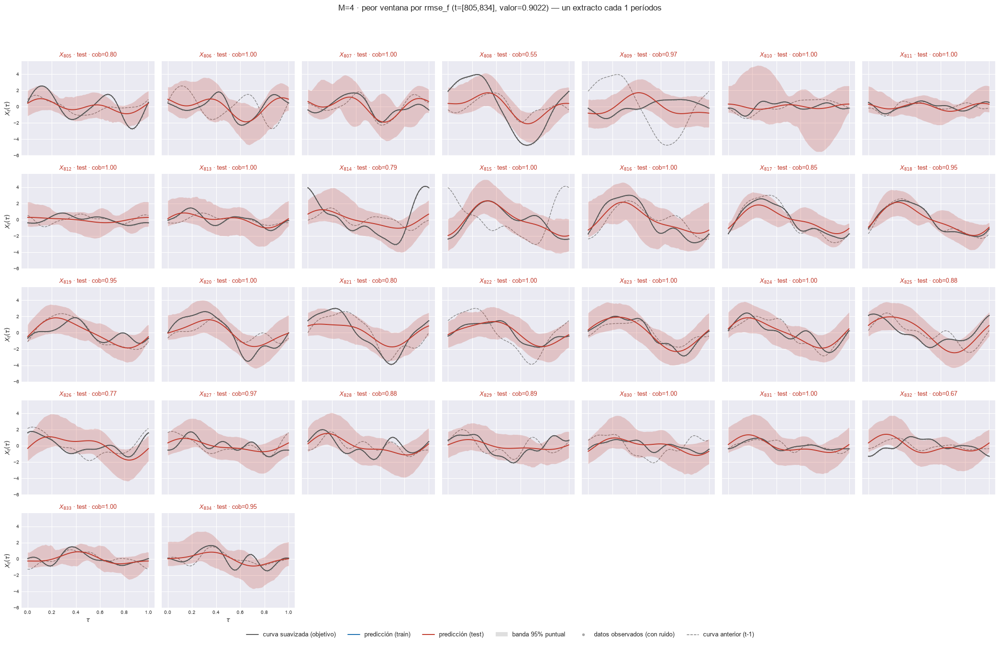

[M=5] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[808, 837]  rmse_f=0.904085


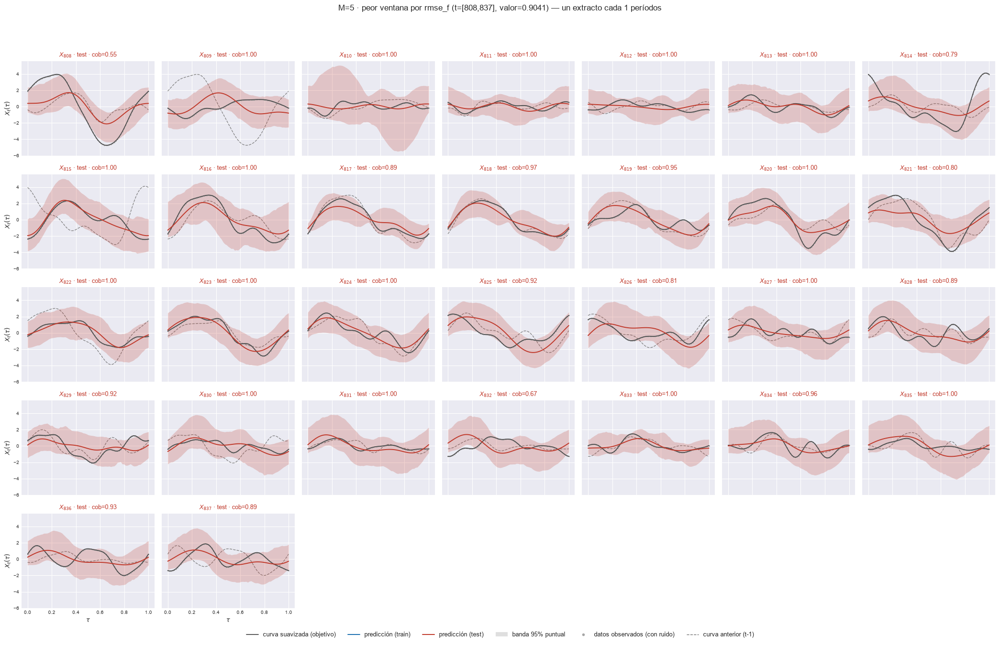

    t=[797, 826]  rmse_f=0.900681


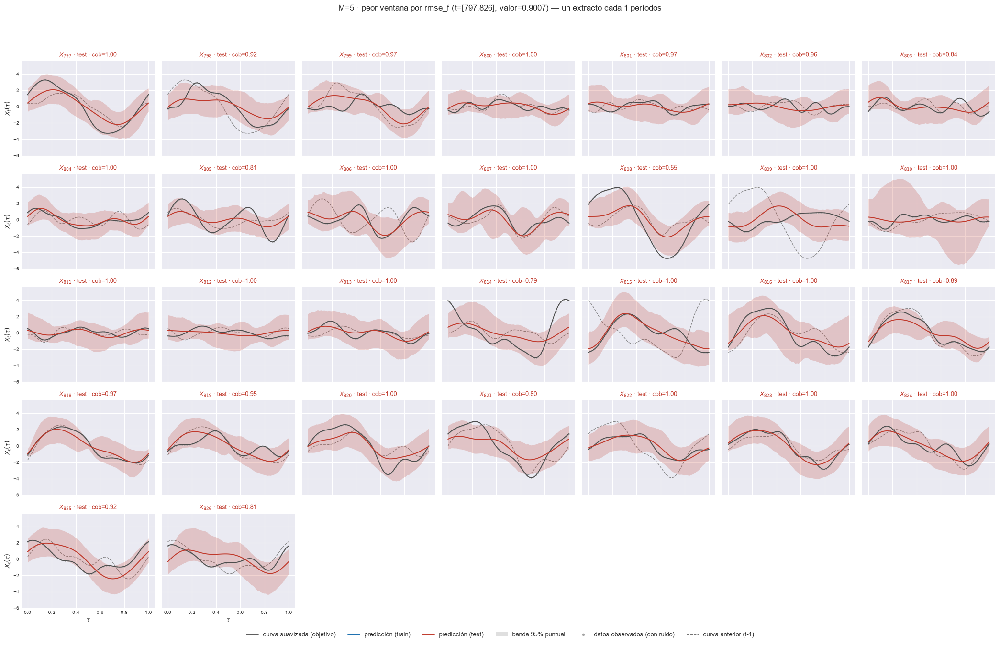

    t=[792, 821]  rmse_f=0.900148


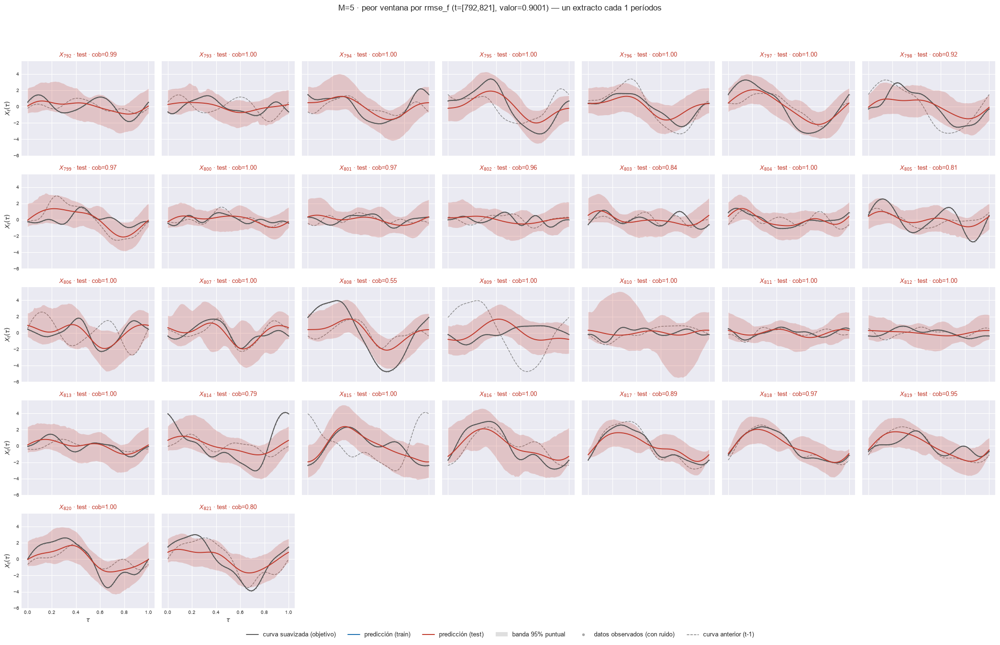

    t=[805, 834]  rmse_f=0.899927


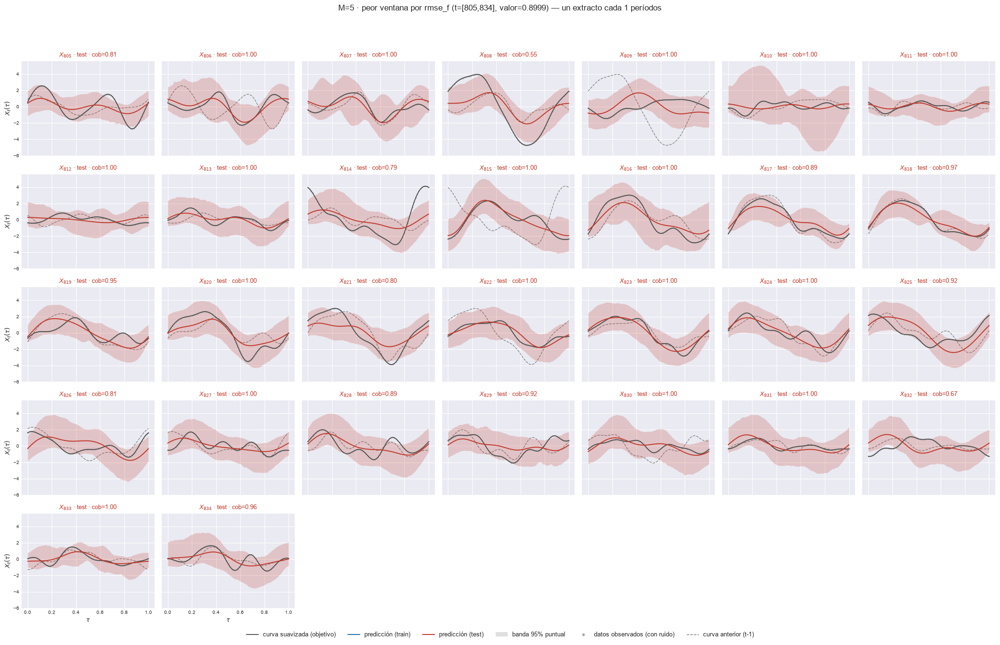

    t=[803, 832]  rmse_f=0.899779


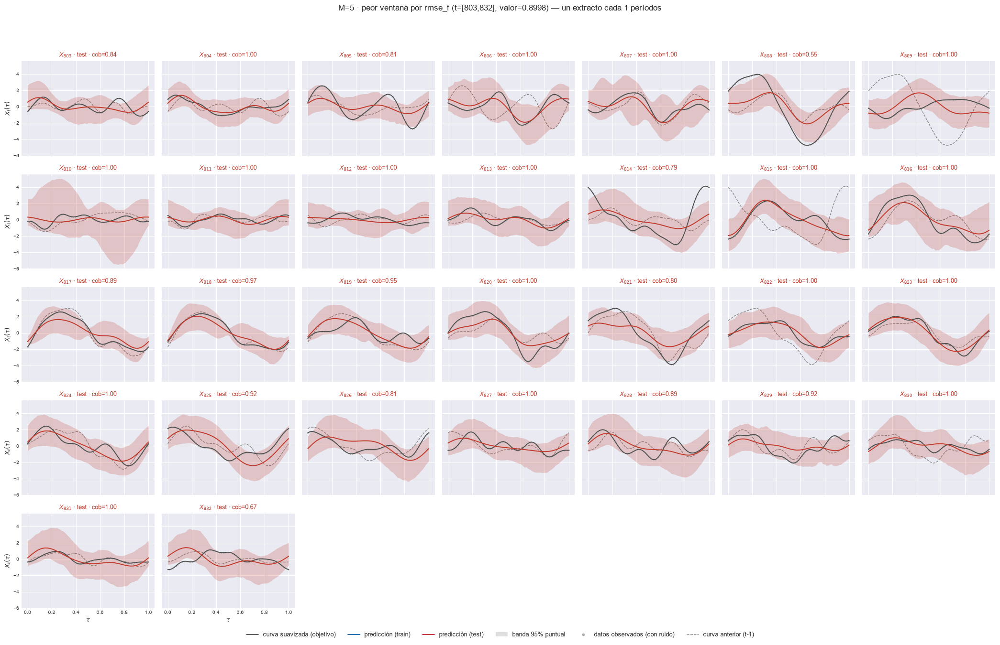

[M=6] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[808, 837]  rmse_f=0.902279


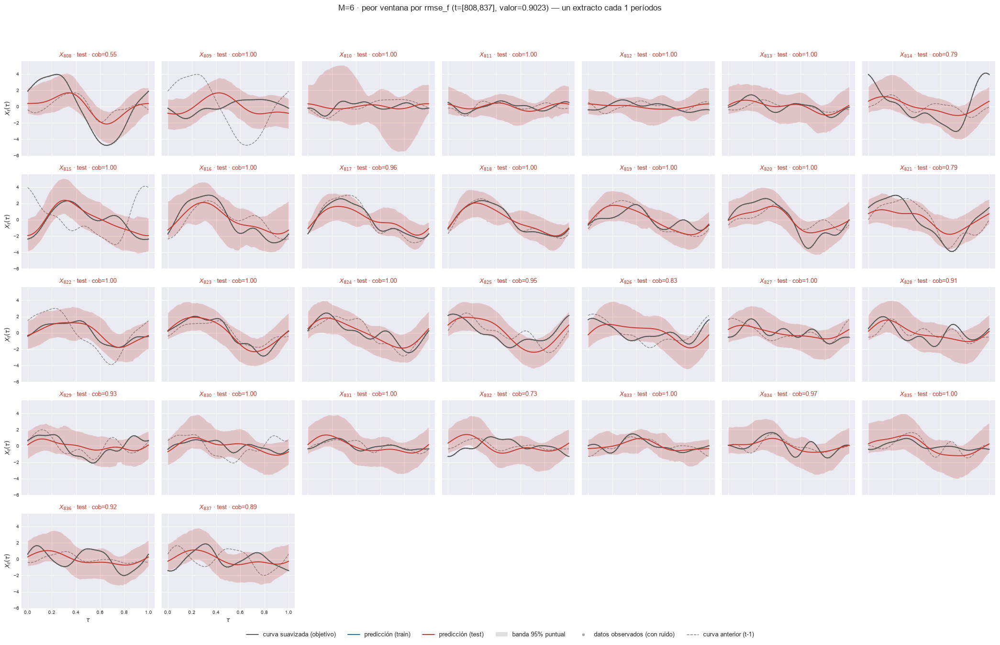

    t=[797, 826]  rmse_f=0.899452


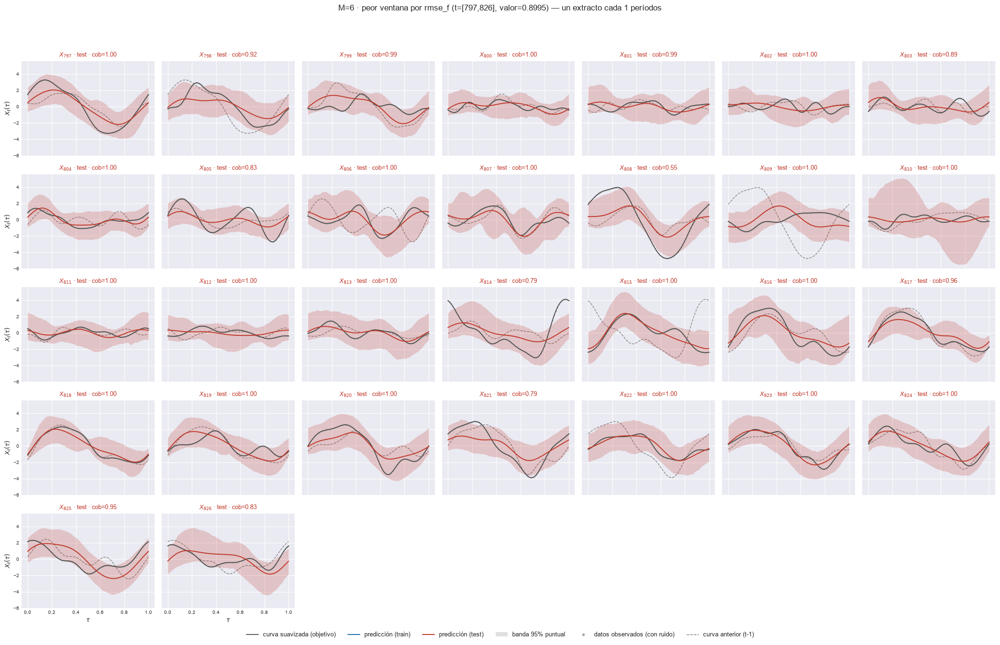

    t=[792, 821]  rmse_f=0.899410


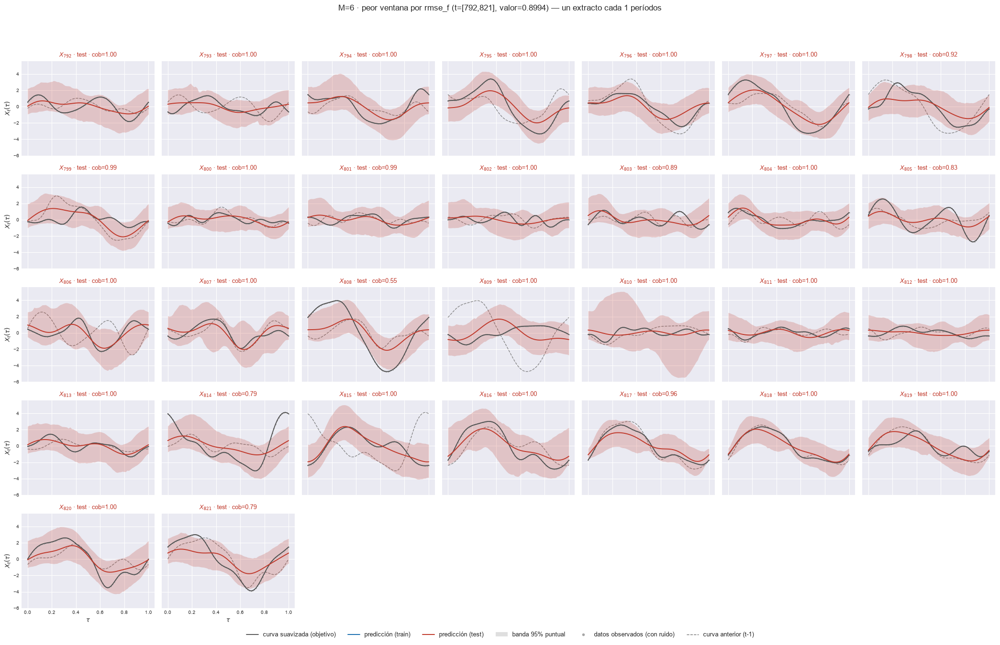

    t=[803, 832]  rmse_f=0.899027


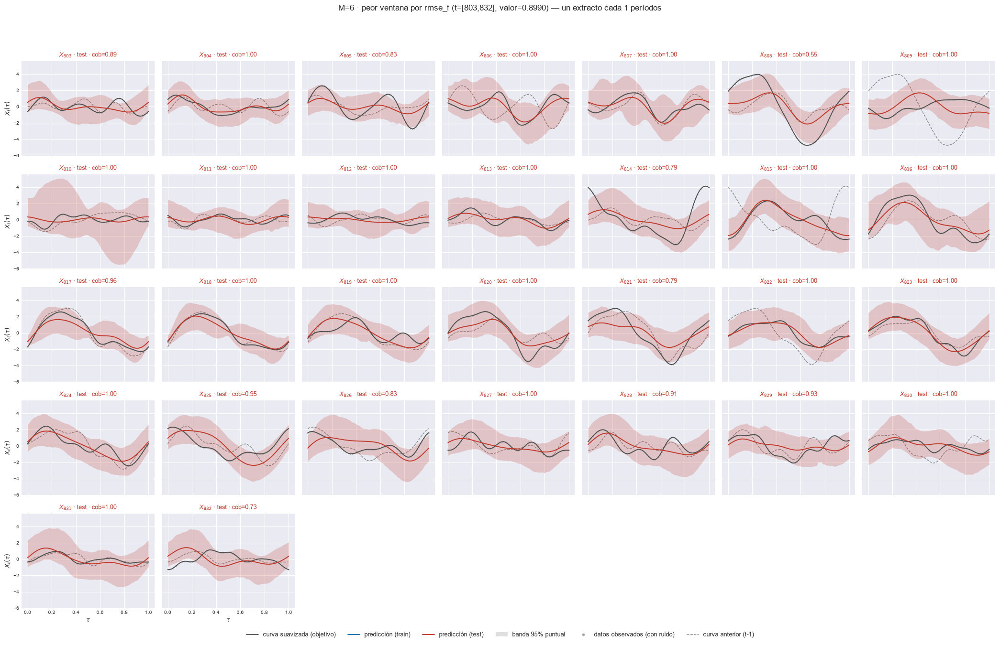

    t=[805, 834]  rmse_f=0.898505


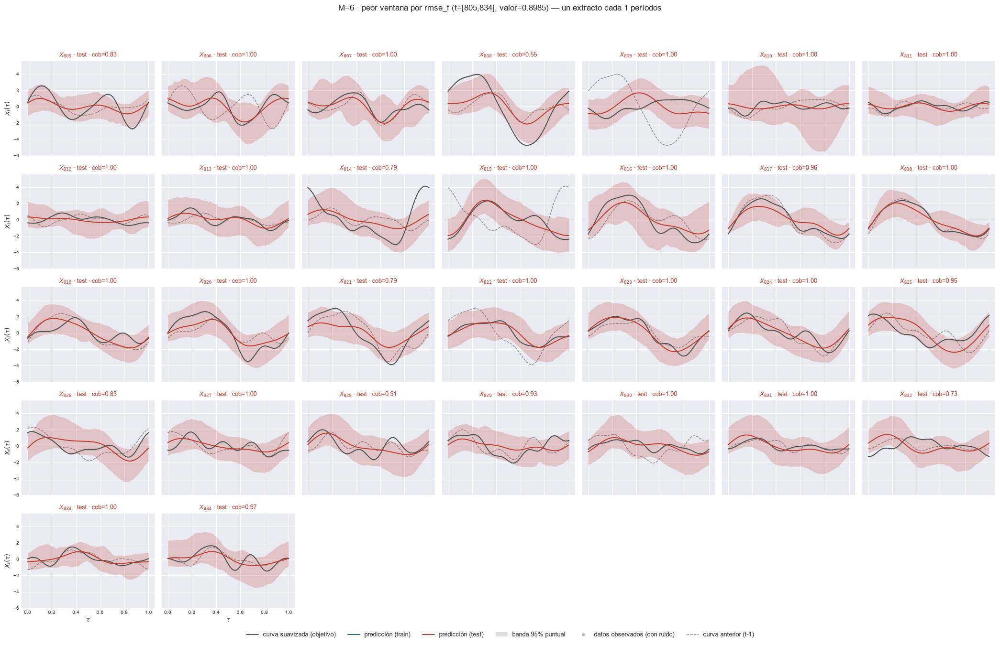

[M=7] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[808, 837]  rmse_f=0.900538


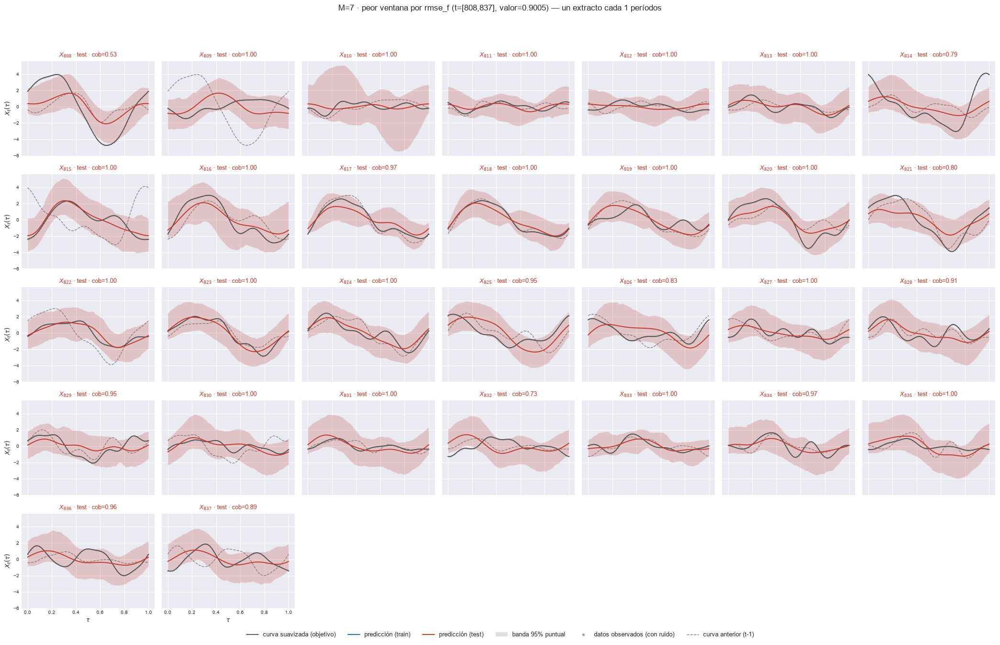

    t=[792, 821]  rmse_f=0.898727


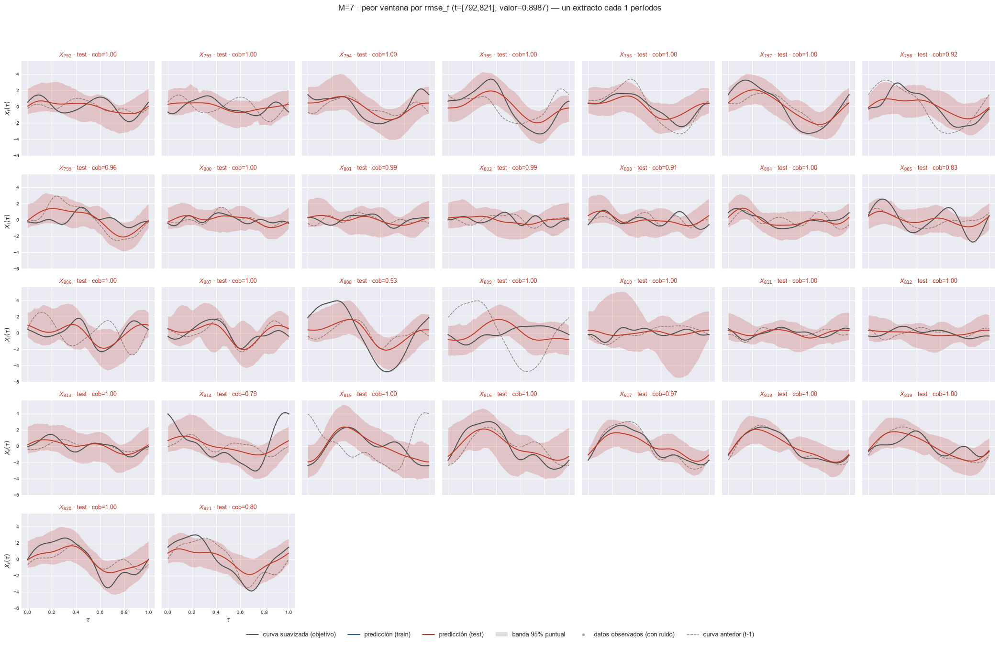

    t=[797, 826]  rmse_f=0.898589


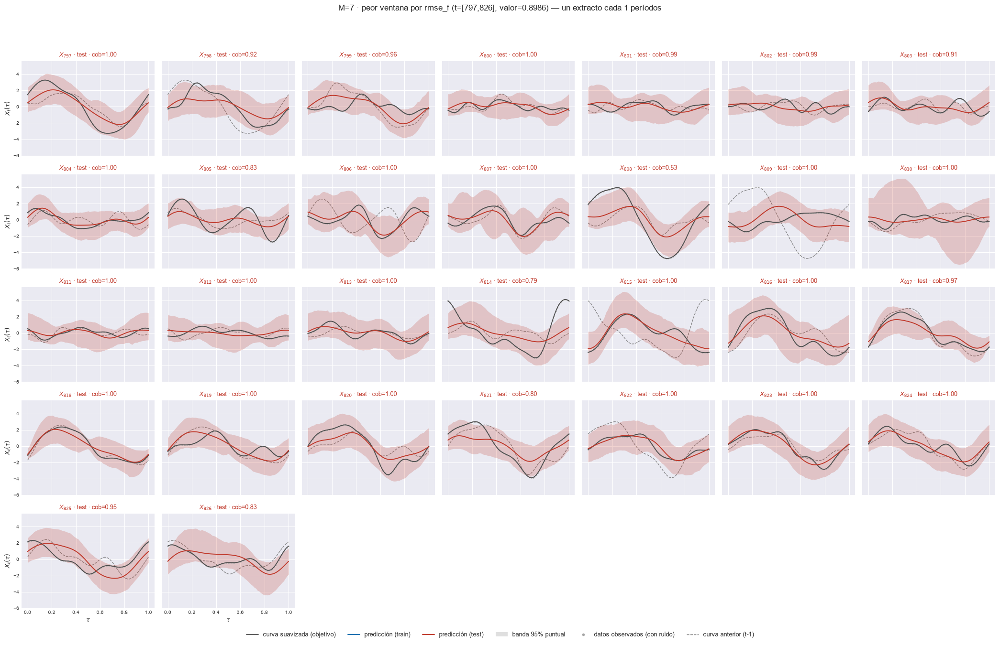

    t=[803, 832]  rmse_f=0.896876


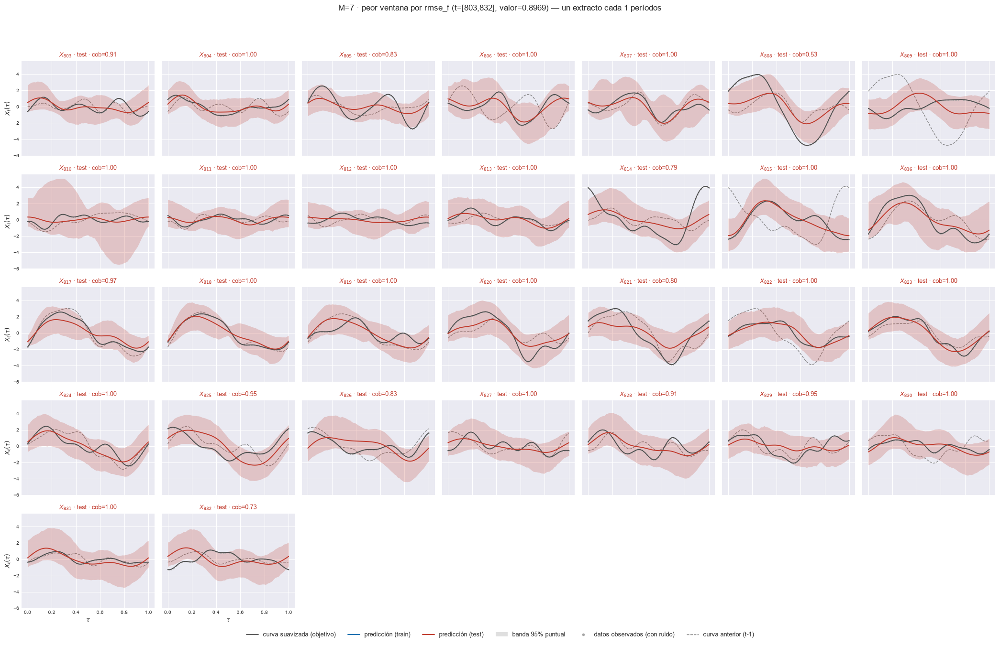

    t=[805, 834]  rmse_f=0.896558


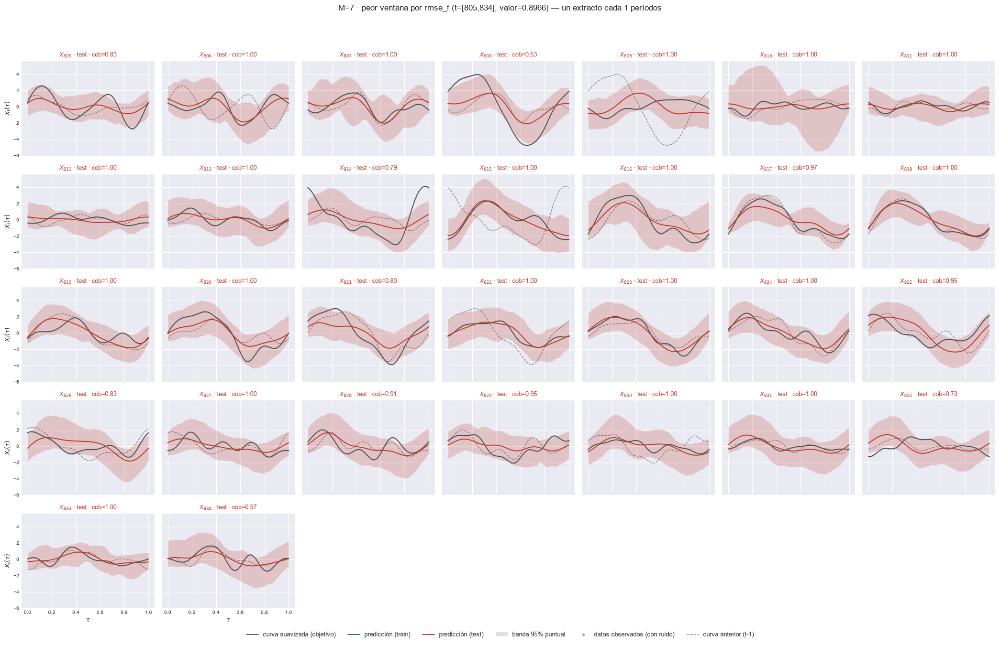

[M=8] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[808, 837]  rmse_f=0.900137


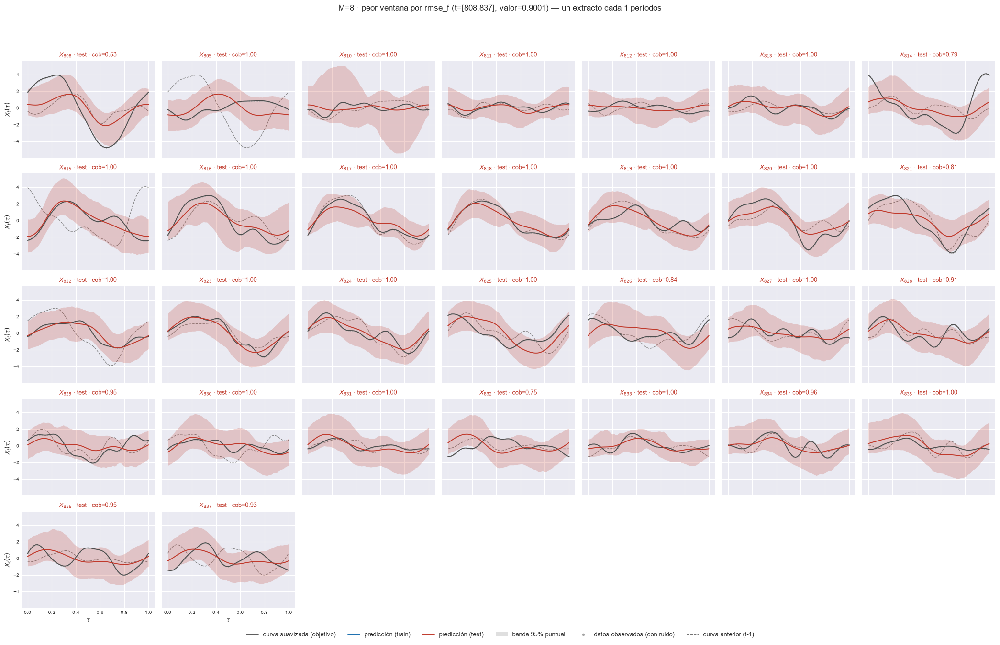

    t=[797, 826]  rmse_f=0.898637


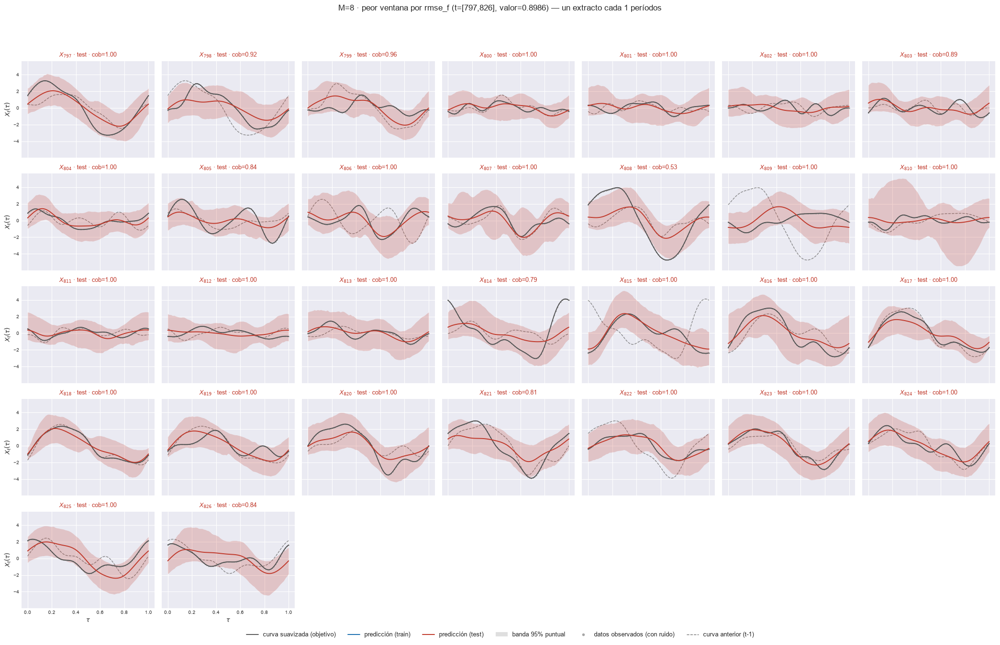

    t=[792, 821]  rmse_f=0.898429


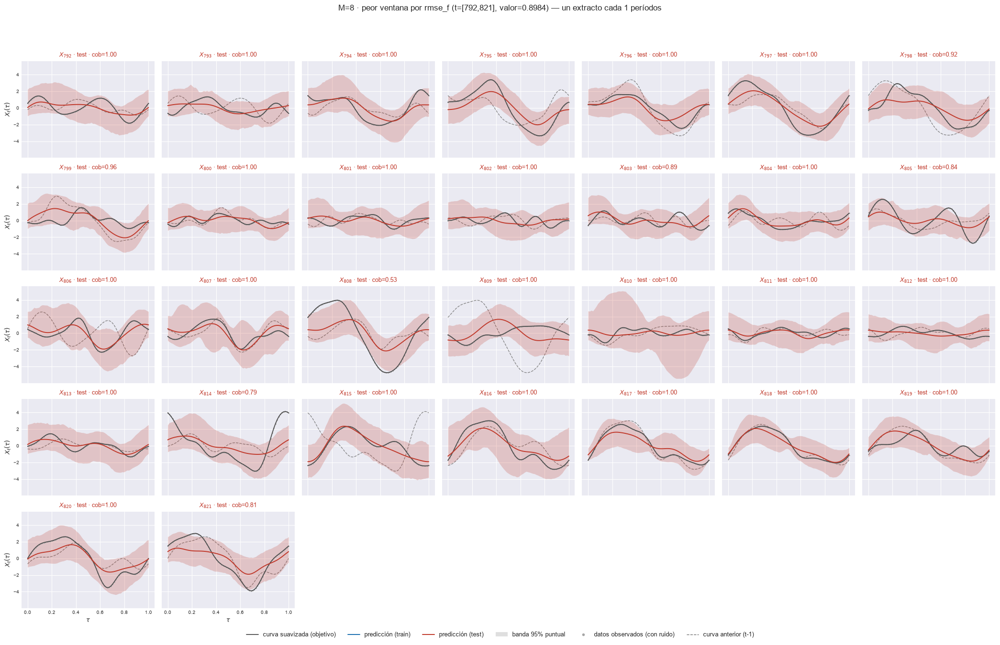

    t=[803, 832]  rmse_f=0.896668


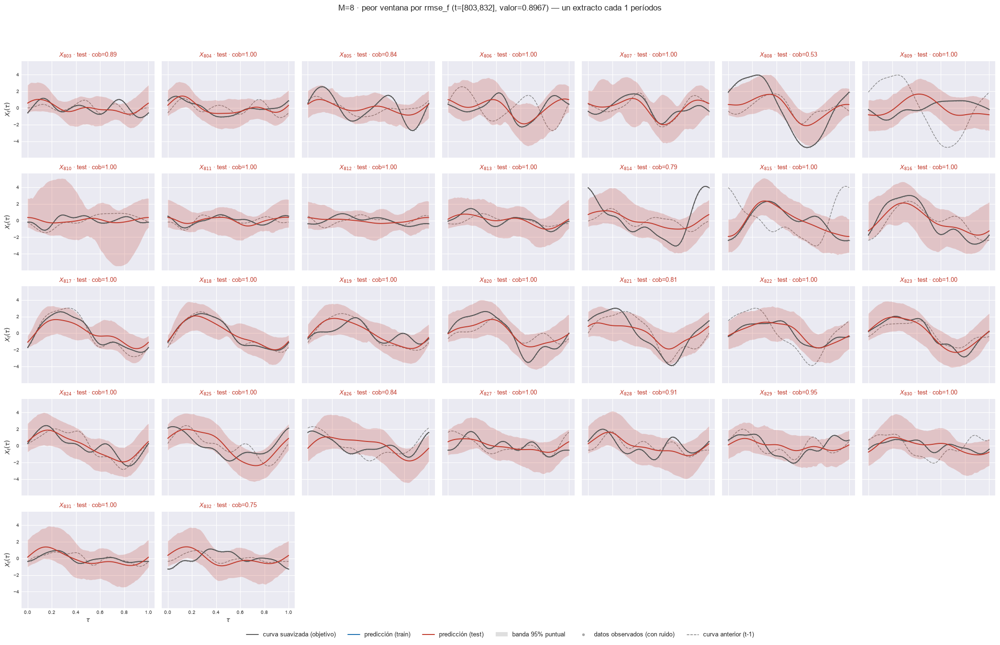

    t=[843, 872]  rmse_f=0.896347


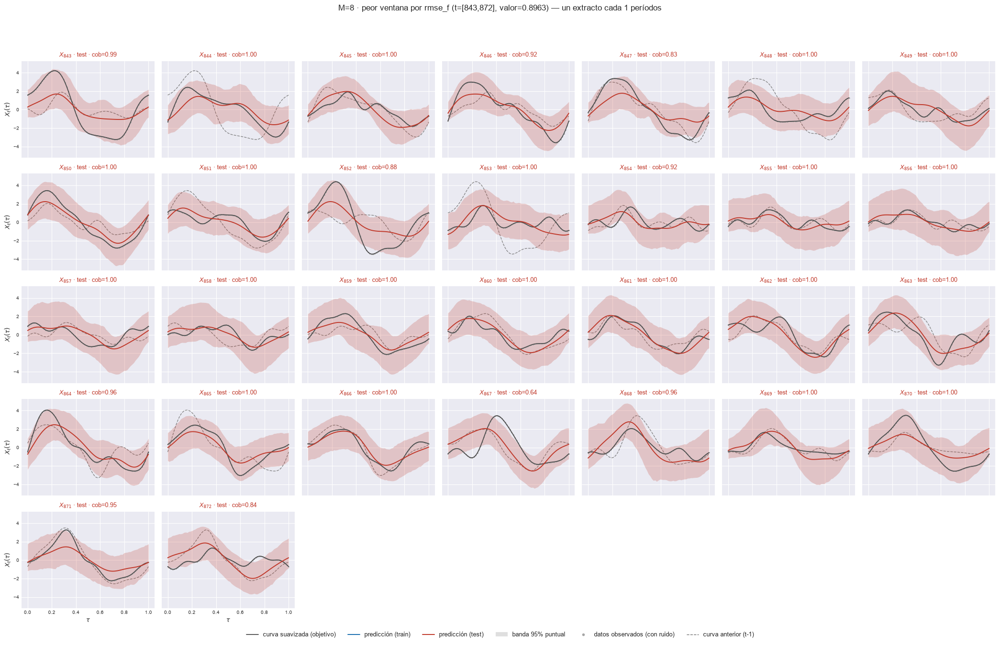

[M=9] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[808, 837]  rmse_f=0.900253


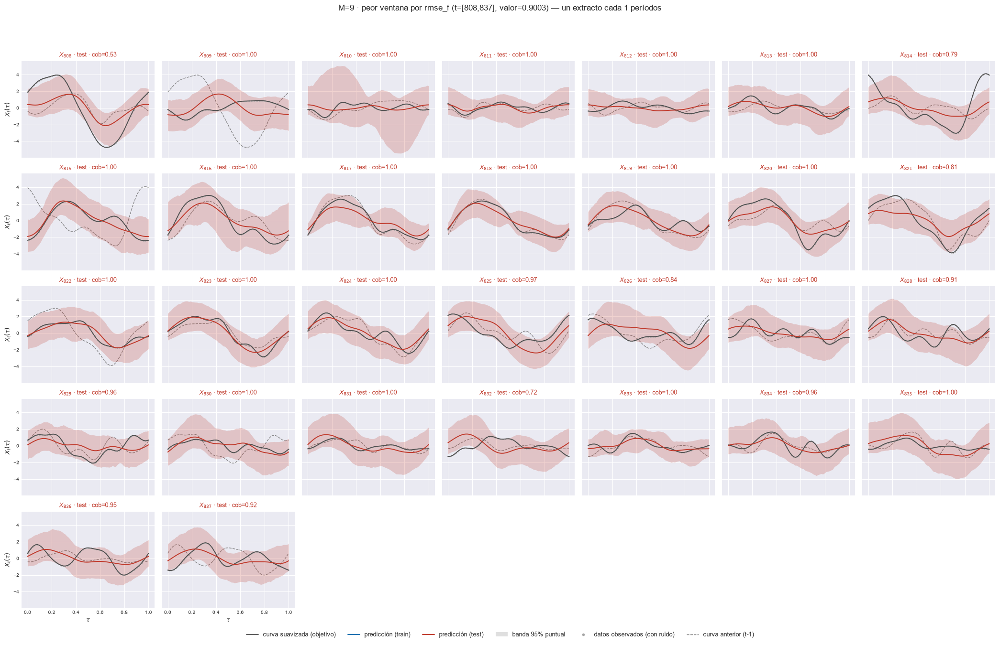

    t=[797, 826]  rmse_f=0.898781


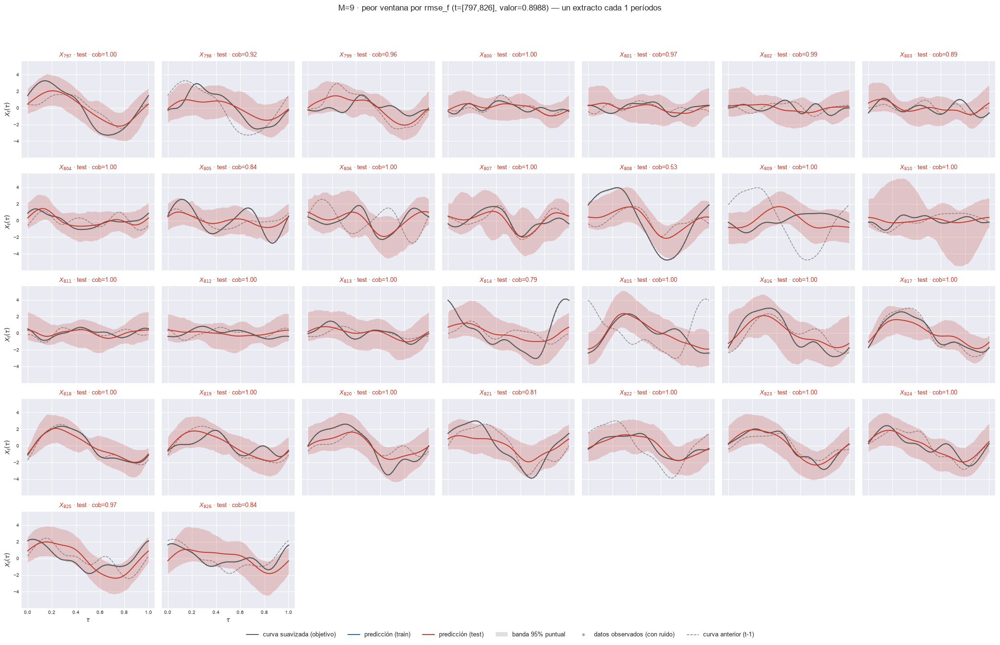

    t=[792, 821]  rmse_f=0.898538


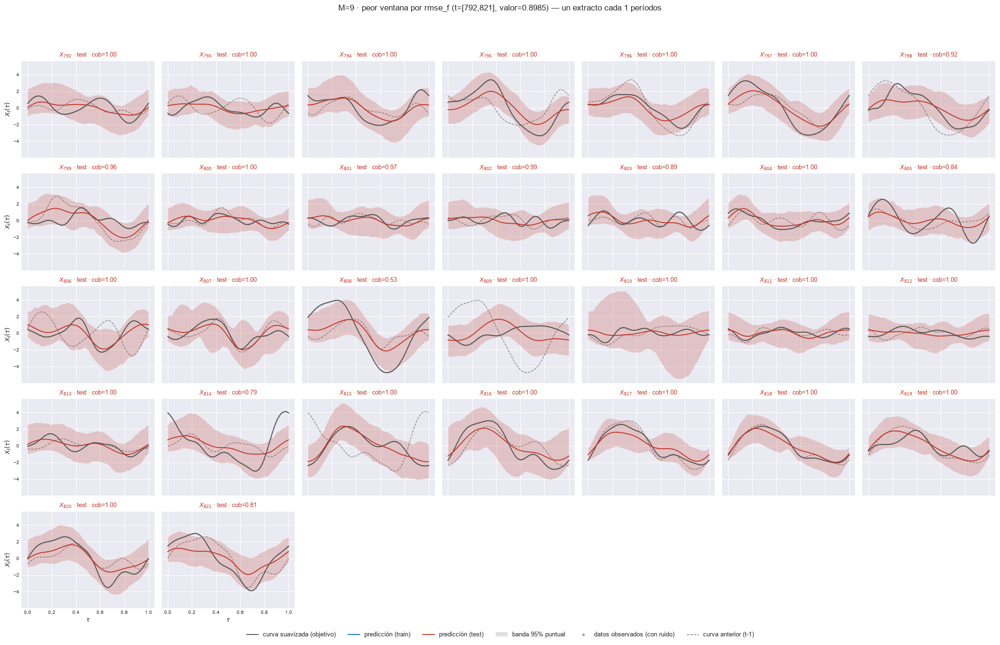

    t=[803, 832]  rmse_f=0.896578


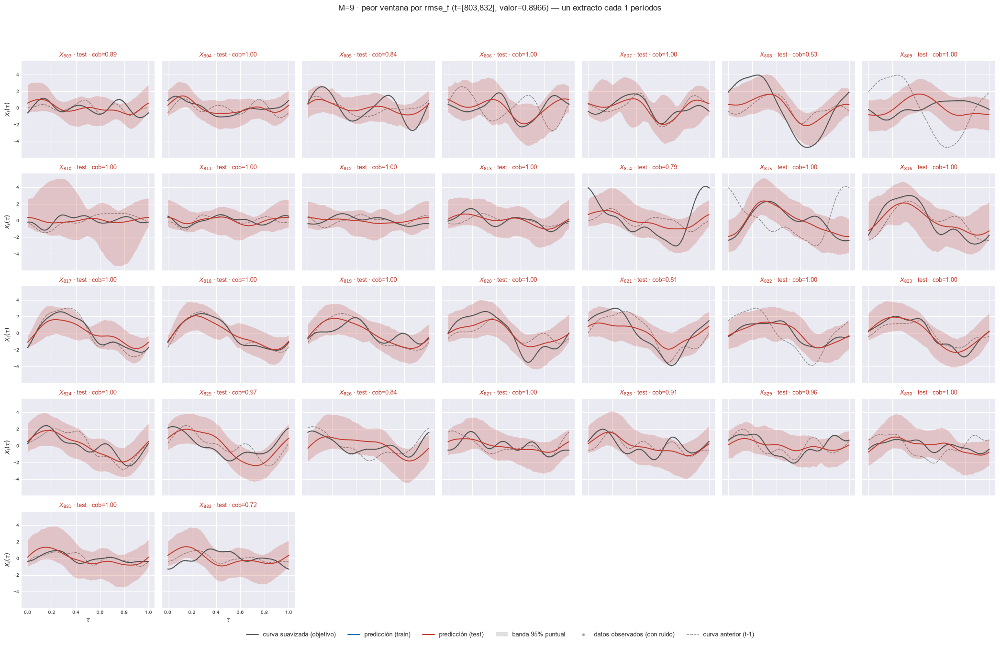

    t=[805, 834]  rmse_f=0.896212


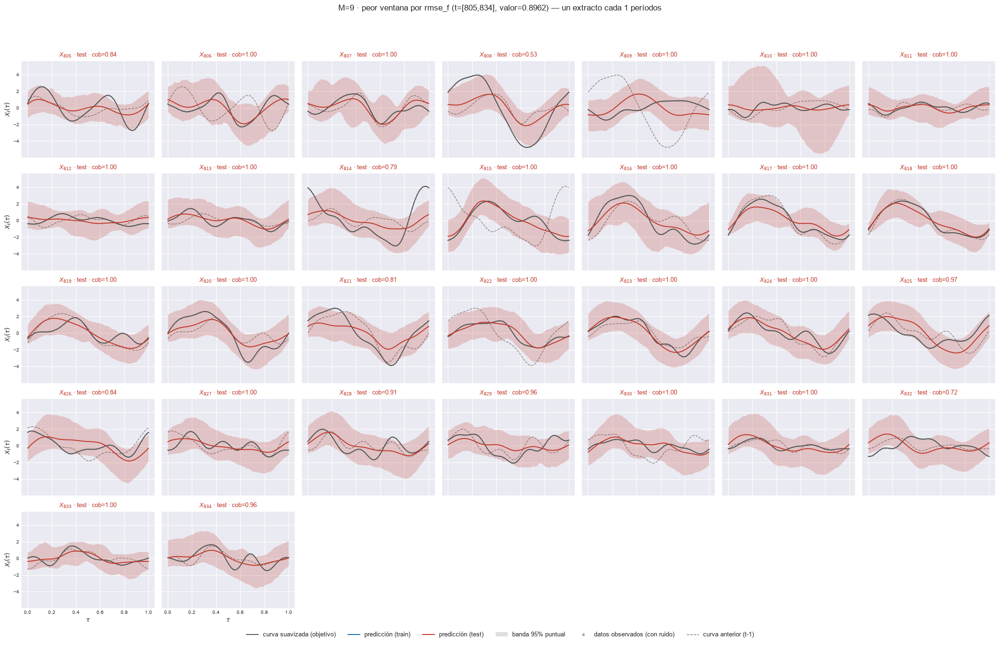

[M=10] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[808, 837]  rmse_f=0.899991


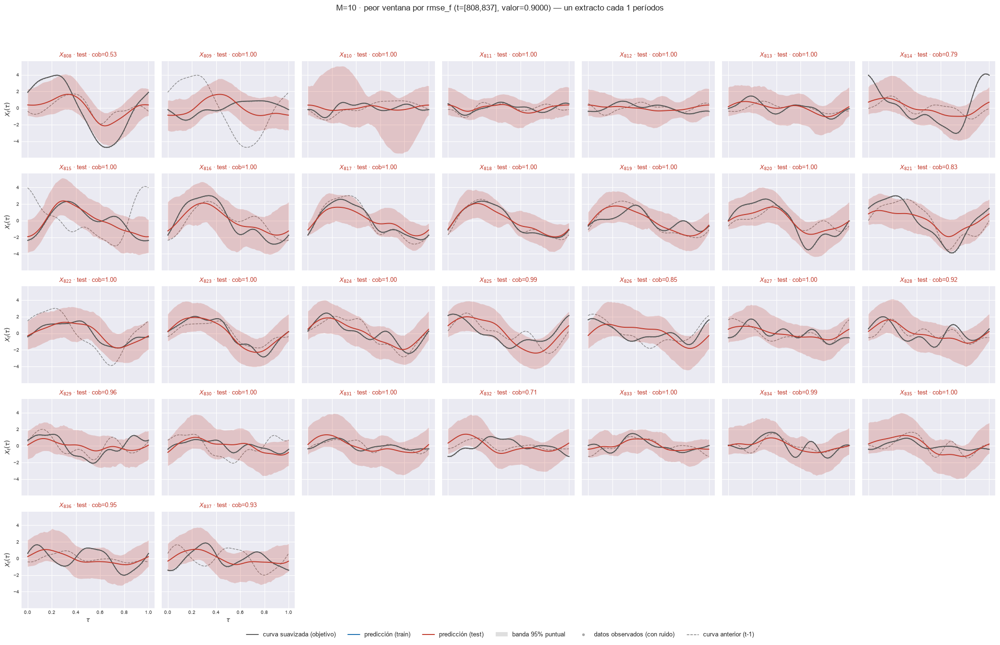

    t=[797, 826]  rmse_f=0.898624


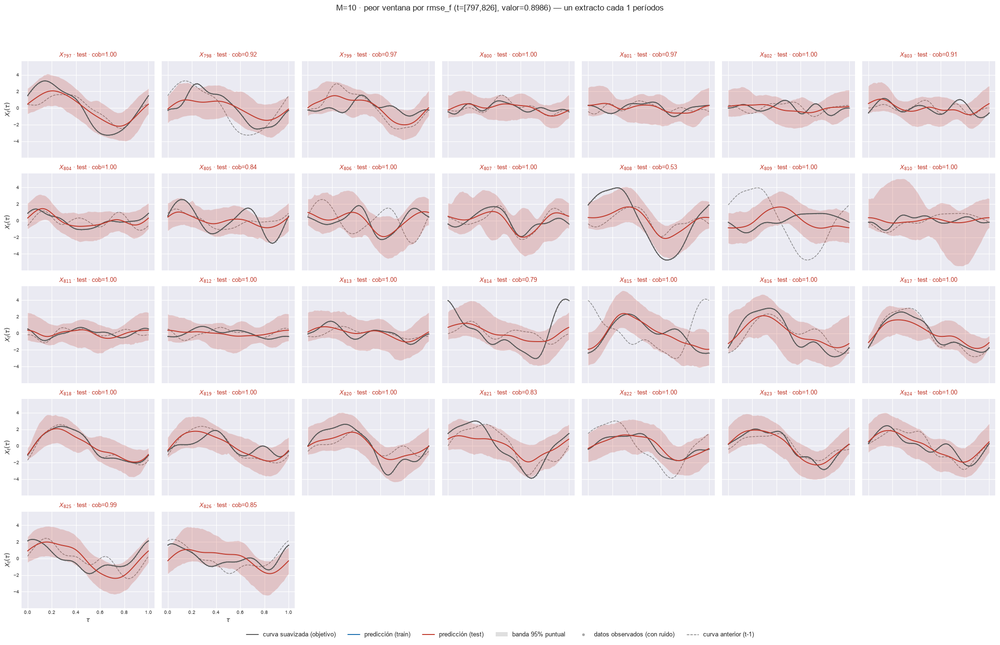

    t=[792, 821]  rmse_f=0.898392


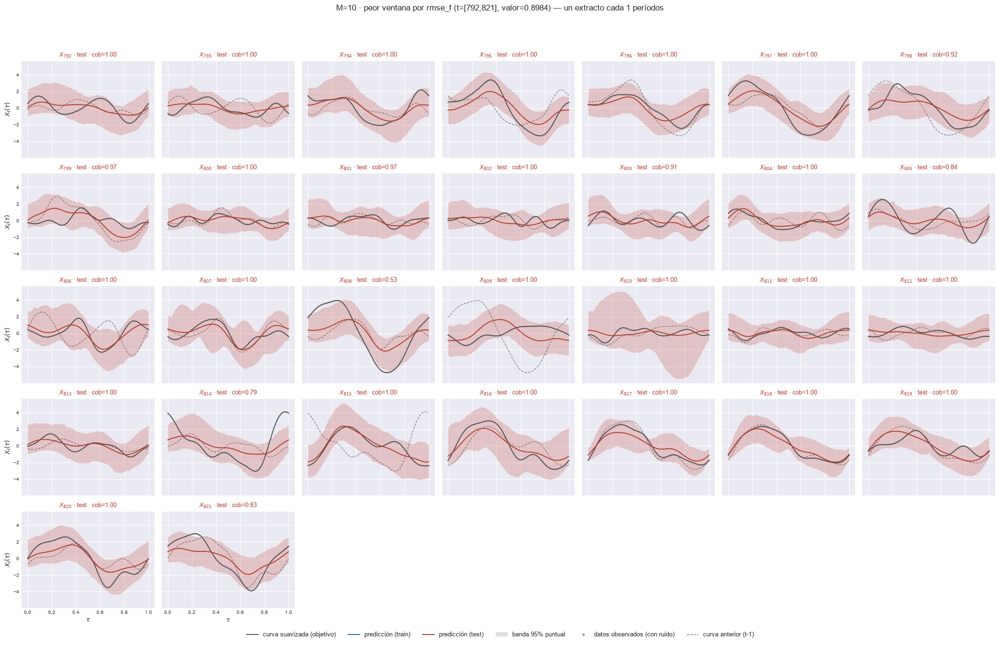

    t=[803, 832]  rmse_f=0.896405


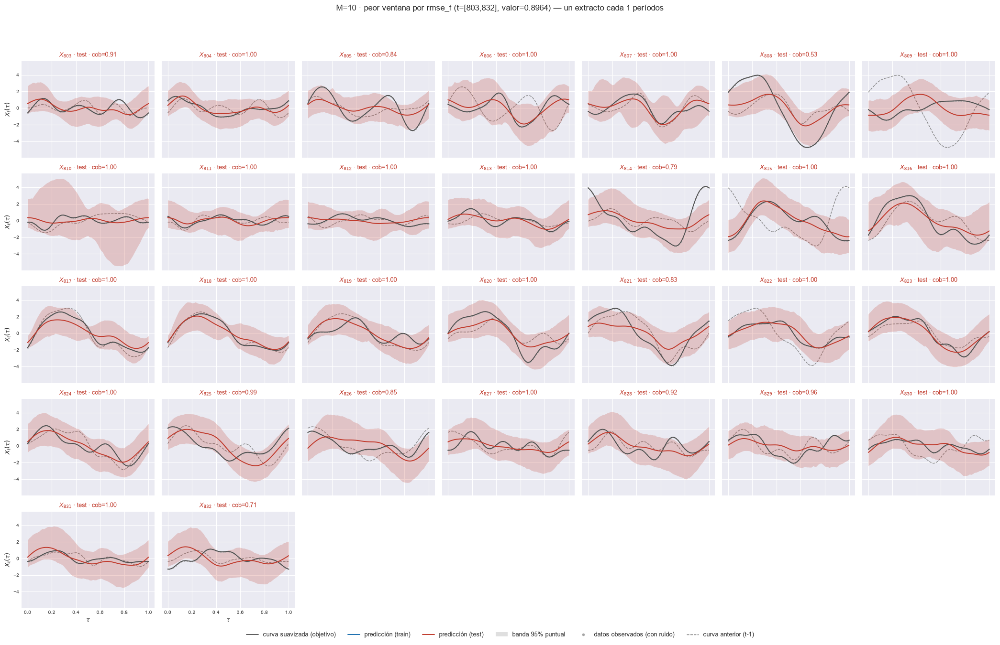

    t=[805, 834]  rmse_f=0.895941


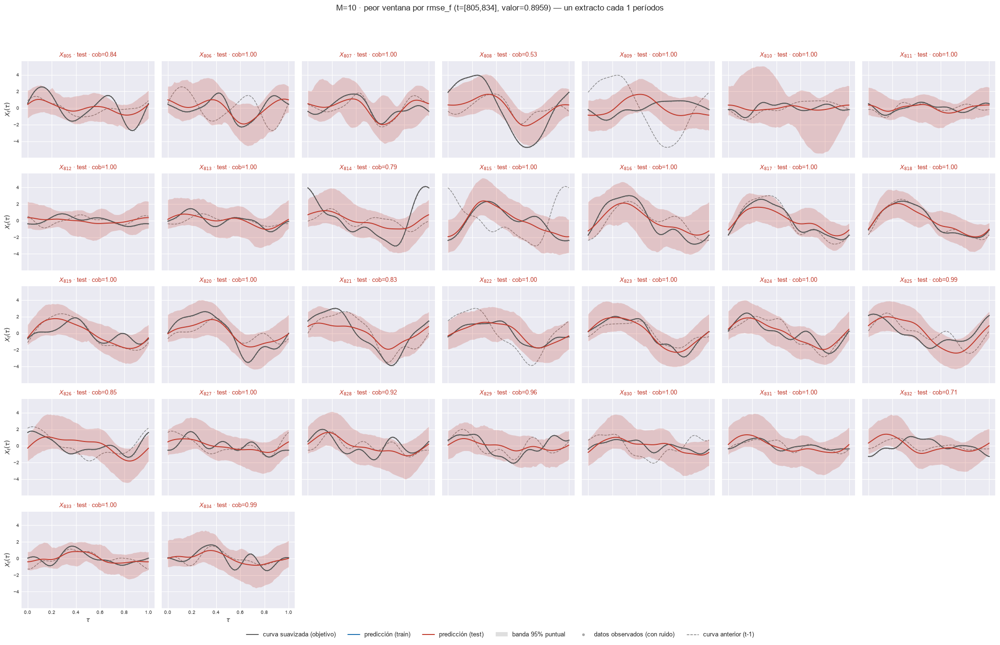

In [17]:
# Peores ventanas de test, con la curva anterior (t-1) al lado.
X_prev_full = np.full_like(X_obj_ev, np.nan)
X_prev_full[1:] = X_obj_ev[:-1]

for M in M_OK:
    e = EST[M]
    peores = peores_ventanas(e, W_REF, METRICA_PEORES, N_PEORES)
    print(f"[M={M}] peores {len(peores)} ventanas por {METRICA_PEORES} (w={W_REF}, test, sin cruzar T0)")
    for _, row in peores.iterrows():
        ini, fin = int(row["t_ini"]), int(row["t_fin"])
        print(f"    t=[{ini}, {fin}]  {METRICA_PEORES}={row[METRICA_PEORES]:.6f}")
        sel = np.where((t_orig >= ini) & (t_orig <= fin))[0]
        if sel.size == 0:
            continue
        plot_extractos_curvas(
            X_obj_ev[sel], e["X_pred"][sel], e["li_f"][sel], e["ls_f"][sel], grilla, T0,
            t=t_orig[sel], cada=1, n_col=min(len(sel), 7), nivel=NIVEL,
            etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[sel],
            X_prev=X_prev_full[sel],
            title=f"M={M} · peor ventana por {METRICA_PEORES} (t=[{ini},{fin}], "
                  f"valor={row[METRICA_PEORES]:.4f})",
            save_path=str(e["paths"]["out_report"] / f"56b_peor_ventana_{METRICA_PEORES}_t{ini}.png"),
            verbose=False)
        plt.show()

## 7. Probabilidades posteriores de inclusión (PIP)

Soporte verdadero de `internos["soporte"]`; sensibilidad, especificidad y AUC.

In [18]:
for M in M_OK:
    pip_df = pip_punto(EST[M], SD_PIP_MAX)
    display(pip_df.style
        .background_gradient(subset=[c for c in pip_df.columns if not c.endswith("_sd")],
                             cmap="RdYlGn", vmin=0, vmax=1)
        .format("{:.3f}")
        .set_caption(f"M={M} · P(gamma_j = 1 | datos), inclusión global, media entre cadenas ± sd"))

[matriz_pip] inicio (1 pasos)


  1/1 (100.0%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 4 variables, PIP en [0.028, 1.000]


[matriz_pip] listo: 1 pasos en 0.0s  tabla 4x2


[M=1] dispersion maxima entre cadenas: 0.082   OK las cadenas coinciden


,FPC 1,FPC 1_sd
variable,,
fpc_1_lag1,1.000,0.000
fpc_1_lag2,0.067,0.082
fpc_1_lag3,0.032,0.028
fpc_1_lag4,0.028,0.014


...

  9/10 (90.0%) t=0.0s eta=0.0s  FPC 9: 3 cadenas, 4 variables, PIP en [0.056, 1.000]


  10/10 (100.0%) t=0.0s eta=0.0s  FPC 10: 3 cadenas, 4 variables, PIP en [0.052, 1.000]


[matriz_pip] listo: 10 pasos en 0.0s  tabla 40x20


[M=10] dispersion maxima entre cadenas: 0.082   OK las cadenas coinciden


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd,FPC 6,FPC 6_sd,FPC 7,FPC 7_sd,FPC 8,FPC 8_sd,FPC 9,FPC 9_sd,FPC 10,FPC 10_sd
variable,,,,,,,,,,,,,,,,,,,,
fpc_10_lag1,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,1.000,0.000
fpc_10_lag2,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,0.063,0.020
fpc_10_lag3,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,0.052,0.012
fpc_10_lag4,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,0.055,0.003
fpc_1_lag1,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag2,0.067,0.082,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag3,0.032,0.028,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag4,0.028,0.014,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag1,nan,nan,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan


In [19]:
for M in M_OK:
    contraste = contraste_generador(EST[M], ESCENARIO_ID, UMBRAL_PIP, COS_MIN)
    if not contraste.empty:
        display(contraste.style.format("{:.3f}", subset=[
            c for c in contraste.columns if contraste[c].dtype.kind == "f"])
            .set_caption(f"M={M} - selección de variables vs soporte del generador "
                         f"(umbral {UMBRAL_PIP})"))

[M=1] |cos(psi_k, phi_k)| = [1.]

,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043


[M=2] |cos(psi_k, phi_k)| = [1. 1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 2,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.036


[M=3] |cos(psi_k, phi_k)| = [1. 1. 1.]


...

,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 2,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.036
FPC 3,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.059
FPC 4,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 5,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.049
FPC 6,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.094
FPC 7,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.062
FPC 8,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.065


[M=9] |cos(psi_k, phi_k)| = [1. 1. 1. 1. 1. 1. 1. 1. 1.]

,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 2,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.036
FPC 3,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.059
FPC 4,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 5,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.049
FPC 6,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.094
FPC 7,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.062
FPC 8,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.065
FPC 9,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.060


[M=10] |cos(psi_k, phi_k)| = [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 2,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.036
FPC 3,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.059
FPC 4,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 5,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.049
FPC 6,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.094
FPC 7,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.062
FPC 8,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.065
FPC 9,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.060


## 8. Cuadro resumen: mínimo, máximo y promedio

Por métrica y bloque train/test, sin las ventanas que cruzan $T_0$.

In [20]:
# Los dos objetivos, los cuatro predictores y los tres intervalos en 66_metricas_resumen.csv (por M) y 89_resumen_por_M.csv.
for M in M_OK:
    resumen_metricas(EST[M], M, DIS, ORIG)
resumen_bar = resumen_barrido(EST, M_OK, PATH_BARRIDO)

_esp = resumen_bar[(resumen_bar.bloque == "test") & (resumen_bar.objetivo == "curva_suavizada")
                   & (resumen_bar.predictor == "esperanza") & (resumen_bar.intervalo == "equicolas")]
display(_esp.pivot(index="metrica", columns="M", values="promedio").style.format("{:.6f}")
        .set_caption("Esperanza · promedio en TEST contra M, objetivo=curva_suavizada (89_resumen_por_M.csv)"))

[M=1] curva_suavizada      PICP puntual test = 0.5411 (nominal 0.95)  ·  PICP simultaneo test = 0.0000


[M=1] representacion_fpca  PICP puntual test = 0.9686 (nominal 0.95)  ·  PICP simultaneo test = 0.9686


[M=2] curva_suavizada      PICP puntual test = 0.8169 (nominal 0.95)  ·  PICP simultaneo test = 0.1540


[M=2] representacion_fpca  PICP puntual test = 0.9662 (nominal 0.95)  ·  PICP simultaneo test = 0.8870


[M=3] curva_suavizada      PICP puntual test = 0.8907 (nominal 0.95)  ·  PICP simultaneo test = 0.2515


...

[M=9] curva_suavizada      PICP puntual test = 0.9682 (nominal 0.95)  ·  PICP simultaneo test = 0.6781


[M=9] representacion_fpca  PICP puntual test = 0.9689 (nominal 0.95)  ·  PICP simultaneo test = 0.7076


[M=10] curva_suavizada      PICP puntual test = 0.9694 (nominal 0.95)  ·  PICP simultaneo test = 0.6907


[M=10] representacion_fpca  PICP puntual test = 0.9694 (nominal 0.95)  ·  PICP simultaneo test = 0.6907


M,1,2,3,4,5,6,7,8,9,10
metrica,,,,,,,,,,
1. MAE (L^1),0.713680,0.672804,0.634800,0.611634,0.610302,0.609401,0.609034,0.609099,0.608728,0.608652
10. Winkler max peor ventana,110.153177,68.181356,56.964404,45.602952,40.835170,40.471196,39.779125,37.839035,37.752360,37.532583
2. RMSE (L^2),0.906452,0.853710,0.807873,0.782675,0.780518,0.778797,0.777760,0.777433,0.777240,0.777128
3. E_max promedio por curva,1.633727,1.564066,1.472328,1.410220,1.406934,1.400979,1.398244,1.395972,1.394984,1.392756
4. E_max peor de la ventana,3.072922,2.922209,2.800118,2.795655,2.769375,2.770102,2.766488,2.757615,2.748704,2.749770
5. MPIW,1.764447,2.786985,3.135223,3.351358,3.450259,3.510780,3.541703,3.560165,3.570350,3.575695
6. PICP puntual,0.541096,0.816882,0.890699,0.944694,0.957130,0.964346,0.966532,0.968153,0.968210,0.969383
7. PICPB curva completa,0.000000,0.153998,0.251538,0.503075,0.572079,0.651907,0.663346,0.685486,0.678106,0.690652
8. Winkler,11.953095,5.693002,4.613525,3.968097,3.913330,3.900107,3.901616,3.906718,3.908927,3.906754


### 8.1 Bloque A por predictor

Promedio en test por predictor y $M$ (`101_*`); cambio relativo contra la esperanza.

M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,0.7137,0.6728,0.6348,0.6116,0.6103,0.6094,0.6090,0.6091,0.6087,0.6087
mediana,0.7198,0.6753,0.6329,0.6051,0.6025,0.6017,0.6012,0.6012,0.6006,0.6006
medoide,0.7198,0.6753,0.6345,0.6110,0.6103,0.6142,0.6175,0.6147,0.6167,0.6179
modal,0.7248,0.6906,0.6525,0.6354,0.6333,0.6319,0.6312,0.6309,0.6306,0.6306


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,0.9065,0.8537,0.8079,0.7827,0.7805,0.7788,0.7778,0.7774,0.7772,0.7771
mediana,0.9198,0.8653,0.8161,0.7872,0.7834,0.7811,0.7796,0.7791,0.7786,0.7786
medoide,0.9198,0.8660,0.8187,0.7927,0.7937,0.7955,0.8006,0.8012,0.8008,0.8026
modal,0.9270,0.8893,0.8491,0.8385,0.8366,0.8350,0.8339,0.8336,0.8334,0.8334


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,1.6337,1.5641,1.4723,1.4102,1.4069,1.4010,1.3982,1.3960,1.3950,1.3928
mediana,1.6358,1.5381,1.4490,1.3801,1.3774,1.3734,1.3697,1.3681,1.3665,1.3646
medoide,1.6359,1.5355,1.4450,1.3759,1.3840,1.3879,1.4031,1.4029,1.4077,1.4120
modal,1.6414,1.5486,1.4555,1.3962,1.3940,1.3907,1.3871,1.3841,1.3825,1.3827


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,3.0729,2.9222,2.8001,2.7957,2.7694,2.7701,2.7665,2.7576,2.7487,2.7498
mediana,3.1432,3.0331,2.9067,2.9309,2.8989,2.9028,2.9011,2.8888,2.8742,2.8786
medoide,3.1431,3.0224,2.9211,2.9126,2.8604,2.9232,2.9491,2.9920,3.0212,3.0158
modal,3.1630,3.0993,3.0138,3.2124,3.1921,3.1993,3.2006,3.2040,3.1924,3.1905


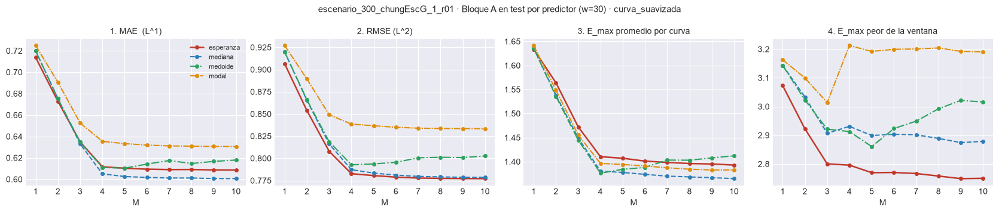

M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,0.2997,0.4606,0.5145,0.5537,0.5788,0.5918,0.6000,0.6042,0.6076,0.6087
mediana,0.2935,0.4377,0.4958,0.5392,0.5670,0.5830,0.5924,0.5965,0.5995,0.6006
medoide,0.2935,0.4379,0.4983,0.5451,0.5750,0.5947,0.6082,0.6103,0.6157,0.6179
modal,0.2989,0.4465,0.5088,0.5644,0.5953,0.6124,0.6232,0.6274,0.6299,0.6306


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,0.4559,0.6093,0.6683,0.7126,0.7430,0.7587,0.7684,0.7731,0.7758,0.7771
mediana,0.4778,0.6241,0.6779,0.7174,0.7456,0.7609,0.7703,0.7747,0.7772,0.7786
medoide,0.4778,0.6245,0.6805,0.7233,0.7567,0.7758,0.7914,0.7970,0.7994,0.8026
modal,0.4895,0.6554,0.7163,0.7731,0.8015,0.8162,0.8251,0.8296,0.8321,0.8334


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,0.4707,0.7233,0.9752,1.1196,1.2445,1.3027,1.3511,1.3766,1.3849,1.3928
mediana,0.4609,0.7076,0.9492,1.0926,1.2166,1.2754,1.3242,1.3497,1.3582,1.3646
medoide,0.4609,0.6877,0.9288,1.0814,1.2142,1.2933,1.3537,1.3792,1.3976,1.4120
modal,0.4693,0.7011,0.9301,1.0871,1.2097,1.2821,1.3307,1.3609,1.3769,1.3827


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,1.6965,1.9777,2.2064,2.4541,2.6373,2.7015,2.7508,2.7930,2.7497,2.7498
mediana,1.9180,2.2369,2.3460,2.5962,2.7686,2.8381,2.8902,2.9159,2.8775,2.8786
medoide,1.9184,2.2401,2.4198,2.5920,2.7532,2.8552,2.9586,3.0501,3.0270,3.0158
modal,1.9640,2.4133,2.6468,2.9920,3.0907,3.1283,3.1817,3.2173,3.1856,3.1905


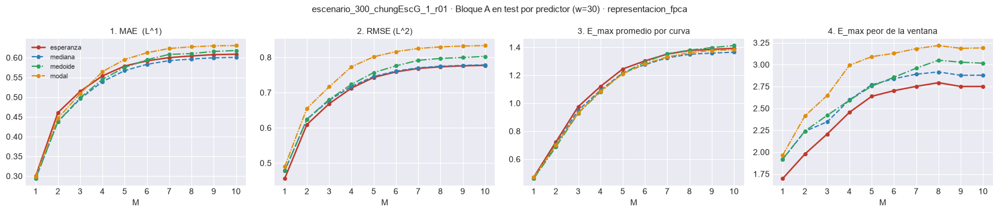

In [21]:
for objetivo in ("curva_suavizada", "representacion_fpca"):
    TAB_PRED = tabla_predictores(resumen_bar, PATH_BARRIDO, objetivo=objetivo)
    for etiqueta, col in METRICAS_A:
        display(TAB_PRED.loc[col].style.format("{:.4f}").highlight_min(axis=0, props="font-weight: bold")
                .set_caption(f"{etiqueta} · TEST · objetivo={objetivo}"))
    rel = TAB_PRED.div(TAB_PRED.xs("esperanza", level="predictor"), level="columna") - 1
    display(rel.style.format("{:+.1%}").background_gradient(cmap="RdYlGn_r", vmin=-0.1, vmax=0.1)
            .set_caption(f"Cambio relativo contra la esperanza · TEST · objetivo={objetivo}"))
    plot_predictores_vs_M(TAB_PRED, METRICAS_A,
                          f"{EXPERIMENT_BASE} · Bloque A en test por predictor (w={W_REF}) · {objetivo}",
                          save_path=PATH_BARRIDO / f"101_bloqueA_predictores_vs_M_{objetivo}.png")
    plt.show()

### 8.2 Bloque B por intervalo

Seis métricas en test por construcción y $M$ (`110_*`), con la esperanza.

M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,1.7644,2.7870,3.1352,3.3514,3.4503,3.5108,3.5417,3.5602,3.5703,3.5757
simultanea,2.0092,6.0828,7.7872,6.7089,6.5521,6.3096,6.3985,6.3444,6.3550,6.3501
hdr,1.4605,2.5567,2.9697,3.2336,3.3489,3.4185,3.4526,3.4740,3.4858,3.4920


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,0.5411,0.8169,0.8907,0.9447,0.9571,0.9643,0.9665,0.9682,0.9682,0.9694
simultanea,0.6043,0.9682,0.9917,0.9981,0.9989,0.9991,0.9993,0.9994,0.9994,0.9994
hdr,0.4934,0.8133,0.8987,0.9552,0.9654,0.9710,0.9736,0.9742,0.9747,0.9746


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,0.0000,0.1540,0.2515,0.5031,0.5721,0.6519,0.6633,0.6855,0.6781,0.6907
simultanea,0.0000,0.7781,0.8930,0.9715,0.9788,0.9825,0.9825,0.9862,0.9825,0.9862
hdr,0.0000,0.1883,0.2859,0.6057,0.6728,0.7226,0.7411,0.7597,0.7614,0.7651


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,11.9531,5.6930,4.6135,3.9681,3.9133,3.9001,3.9016,3.9067,3.9089,3.9068
simultanea,10.7352,6.5381,7.9066,6.7314,6.5725,6.3247,6.4138,6.3575,6.3679,6.3630
hdr,12.0854,5.2861,4.3141,3.7472,3.7496,3.7646,3.7745,3.7834,3.7905,3.7931


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,45.9548,23.4335,16.9736,10.2827,8.9279,8.2006,7.9606,7.7906,7.7428,7.6042
simultanea,42.8343,11.9388,12.1193,9.0053,8.5477,8.0080,8.0639,7.9345,7.9206,7.8979
hdr,45.3268,21.2187,15.1554,8.7484,7.8072,7.3759,7.1428,7.0667,7.0158,6.9732


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,110.1532,68.1814,56.9644,45.6030,40.8352,40.4712,39.7791,37.8390,37.7524,37.5326
simultanea,109.6167,43.6778,33.3624,21.6857,19.2941,16.7021,16.5560,15.6878,15.5991,15.4917
hdr,110.4076,68.5024,56.4771,44.6563,40.7422,40.1514,39.7639,38.2407,37.4980,37.5564


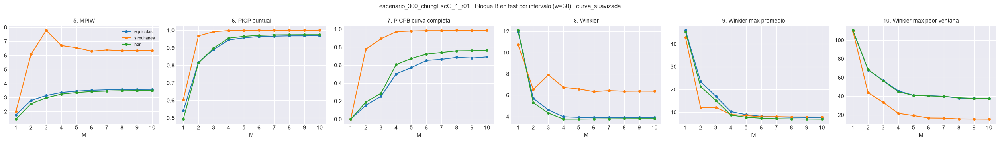

M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,1.7644,2.7870,3.1352,3.3514,3.4503,3.5108,3.5417,3.5602,3.5703,3.5757
simultanea,2.0092,6.0828,7.7872,6.7089,6.5521,6.3096,6.3985,6.3444,6.3550,6.3501
hdr,1.4605,2.5567,2.9697,3.2336,3.3489,3.4185,3.4526,3.4740,3.4858,3.4920


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,0.9686,0.9662,0.9710,0.9680,0.9689,0.9679,0.9683,0.9691,0.9689,0.9694
simultanea,0.9779,0.9981,0.9994,0.9988,0.9993,0.9992,0.9993,0.9994,0.9995,0.9994
hdr,0.9785,0.9749,0.9778,0.9745,0.9749,0.9738,0.9738,0.9740,0.9740,0.9746


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,0.9686,0.8870,0.8242,0.7686,0.7465,0.7022,0.7039,0.7086,0.7076,0.6907
simultanea,0.9779,0.9862,0.9936,0.9899,0.9862,0.9825,0.9788,0.9825,0.9862,0.9862
hdr,0.9779,0.9146,0.8857,0.8415,0.8205,0.7744,0.7651,0.7503,0.7651,0.7651


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,1.9237,3.0393,3.3920,3.6736,3.7829,3.8441,3.8816,3.8983,3.9040,3.9068
simultanea,2.1498,6.1078,7.8230,6.7255,6.5689,6.3220,6.4120,6.3580,6.3684,6.3630
hdr,1.5930,2.8084,3.2185,3.5294,3.6486,3.7176,3.7596,3.7797,3.7881,3.7931


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,3.0209,4.1254,5.1780,6.3608,6.8710,7.2451,7.5363,7.6691,7.6332,7.6042
simultanea,3.3759,8.3606,11.0006,8.8959,8.4765,7.9539,8.0214,7.9399,7.9327,7.8979
hdr,2.5015,3.9822,4.9738,5.9195,6.2455,6.5334,6.8041,6.9723,6.9492,6.9732


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,7.8192,16.5054,20.9016,30.7437,35.0305,36.4036,36.8394,38.6204,37.6418,37.5326
simultanea,9.5257,21.9317,25.8813,20.5131,18.2522,16.1465,16.0869,15.9237,15.8776,15.4917
hdr,7.2345,19.0326,22.3028,30.2860,34.4210,37.1189,36.7023,38.2814,37.6658,37.5564


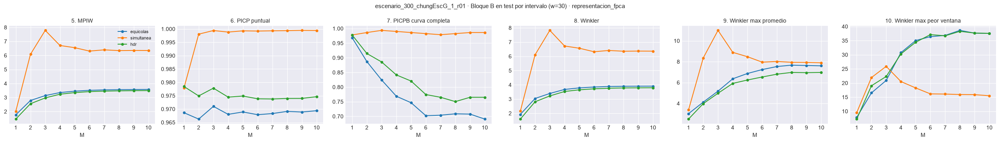

In [22]:
for objetivo in ("curva_suavizada", "representacion_fpca"):
    TAB_INT = tabla_intervalos(resumen_bar, PATH_BARRIDO, objetivo=objetivo)
    for etiqueta, col in METRICAS_B:
        display(TAB_INT.loc[col].style.format("{:.4f}")
                .set_caption(f"{etiqueta} · TEST · objetivo={objetivo}"))
    plot_predictores_vs_M(TAB_INT, METRICAS_B,
                          f"{EXPERIMENT_BASE} · Bloque B en test por intervalo (w={W_REF}) · {objetivo}",
                          save_path=PATH_BARRIDO / f"110_intervalos_vs_M_{objetivo}.png")
    plt.show()

## 9. Monitoreo univariado por componente FPCA

MAE, RMSE y MISE del score por componente sobre la ventana móvil. Solo monitoreo.

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.1s  t=19 [train] rmse=0.4025


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.498


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.5062


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.385


...

  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.5378


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] rmse=0.4462


  960/967 (99.3%) t=0.2s eta=0.0s  t=978 [test] rmse=0.4674


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.3738


[ventana_movil_scores[FPC 1, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


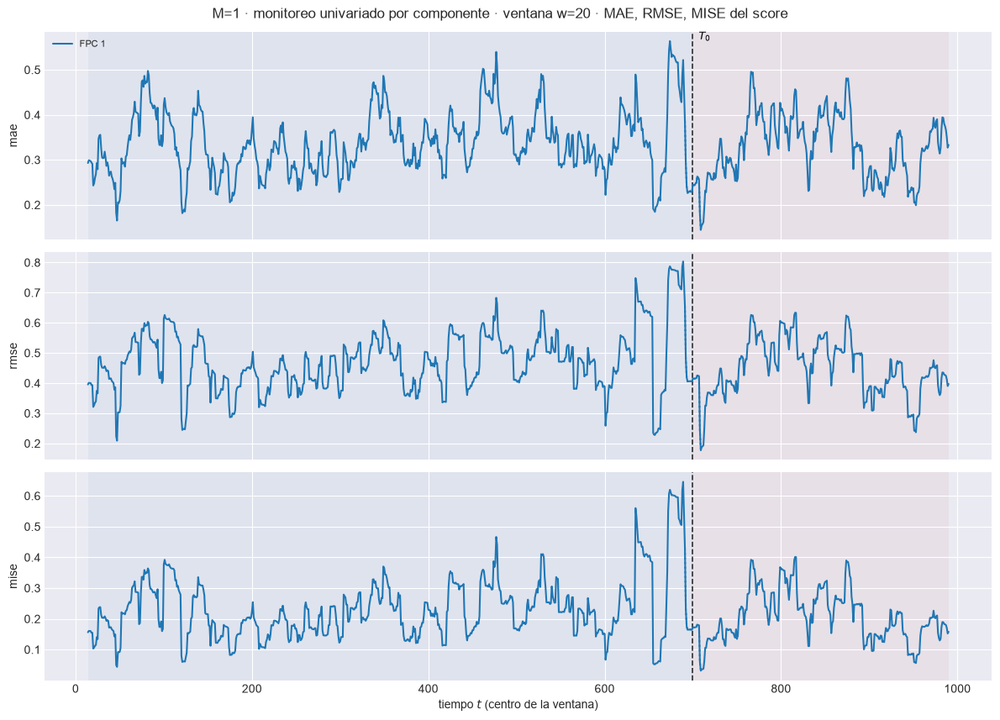

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.3267  w=30 test=0.3393


  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.4749  w=30 test=0.4553


  3/3 (100.0%) t=0.0s eta=0.0s  mise: w=30 train=0.2256  w=30 test=0.2073


[plot_ventana_movil] listo: 3 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_m01\91_ventana_univariado_w30.png


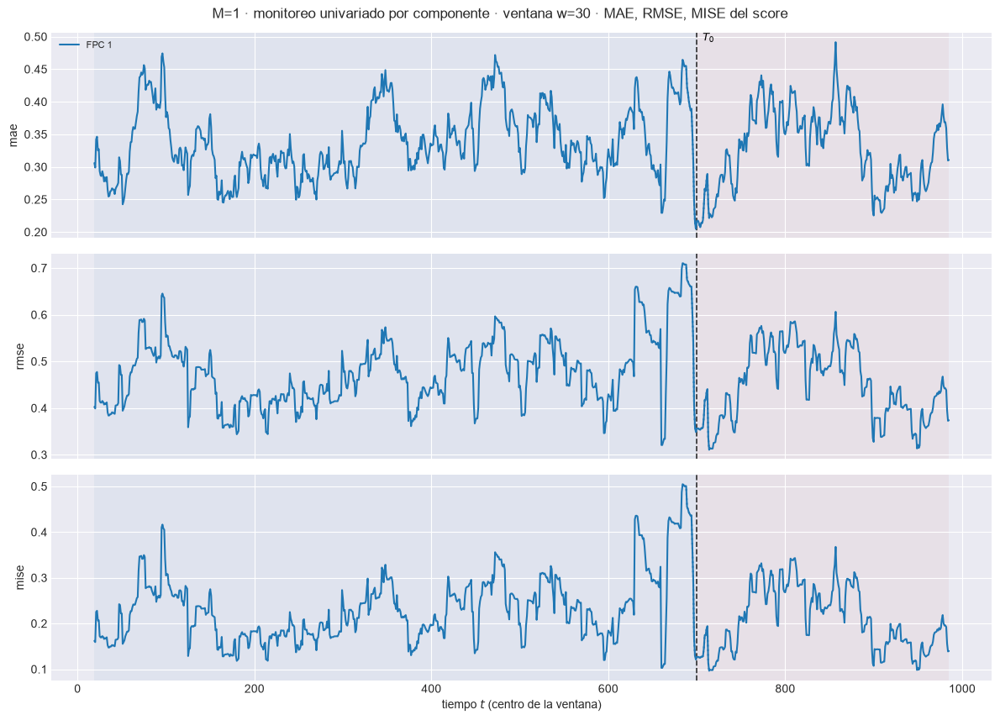

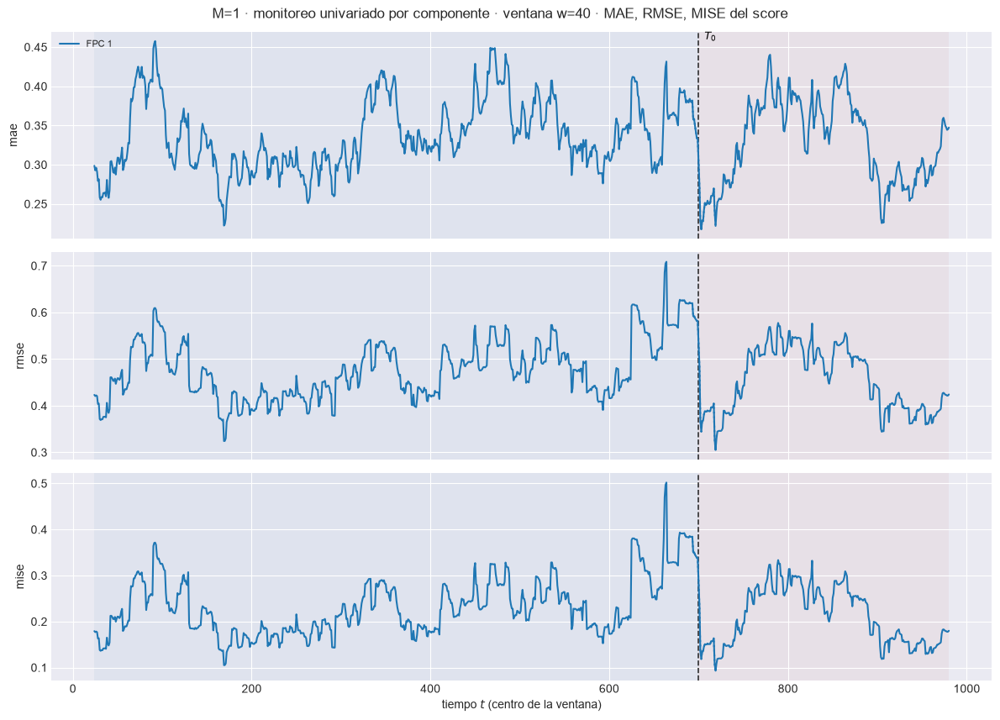

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.8s  t=19 [train] rmse=0.4025


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.498


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.5062


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.385


...

  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.3697


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] rmse=0.4197


  960/967 (99.3%) t=0.1s eta=0.0s  t=978 [test] rmse=0.3043


  967/967 (100.0%) t=0.1s eta=0.0s  t=985 [test] rmse=0.4015


[ventana_movil_scores[FPC 2, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


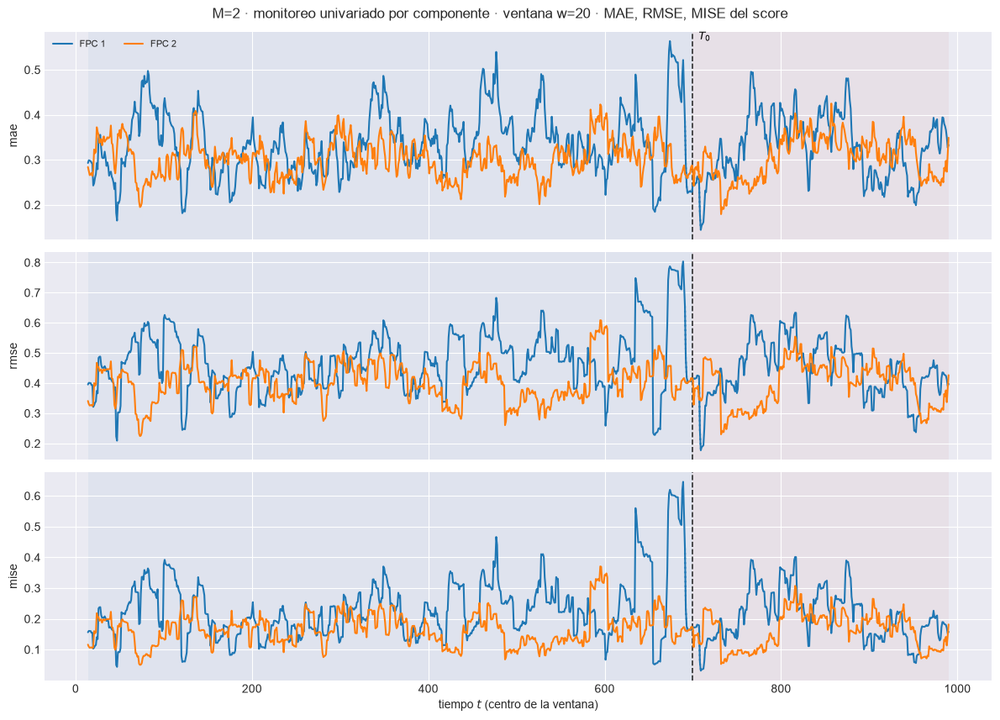

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.314  w=30 test=0.3218


  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.4297  w=30 test=0.4317


  3/3 (100.0%) t=0.0s eta=0.0s  mise: w=30 train=0.1847  w=30 test=0.1863


[plot_ventana_movil] listo: 3 pasos en 0.8s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_m02\91_ventana_univariado_w30.png


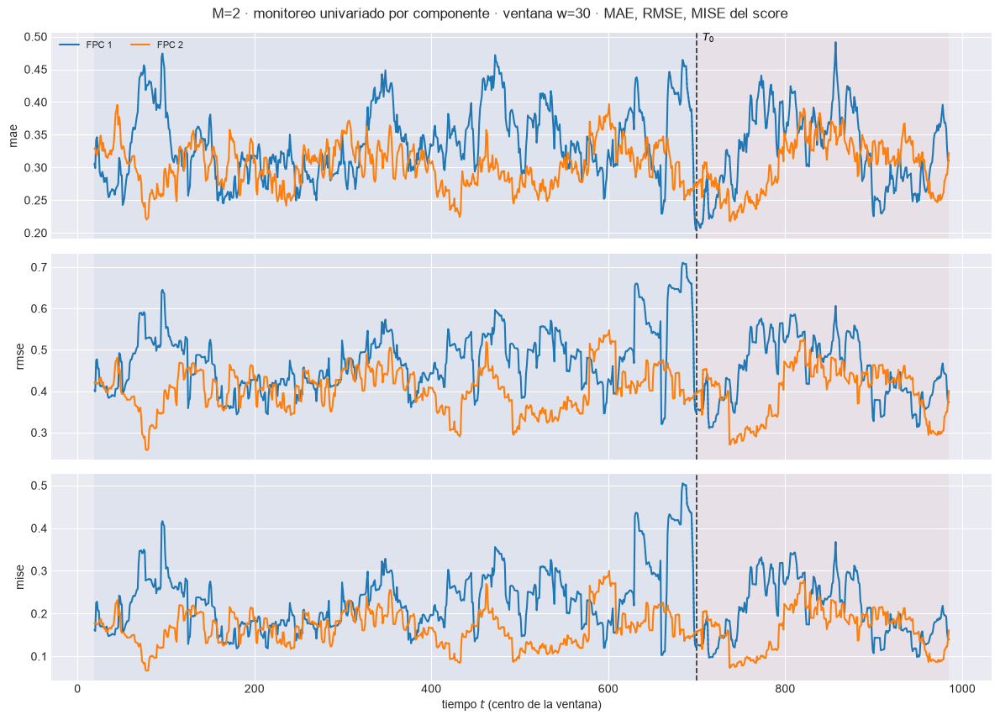

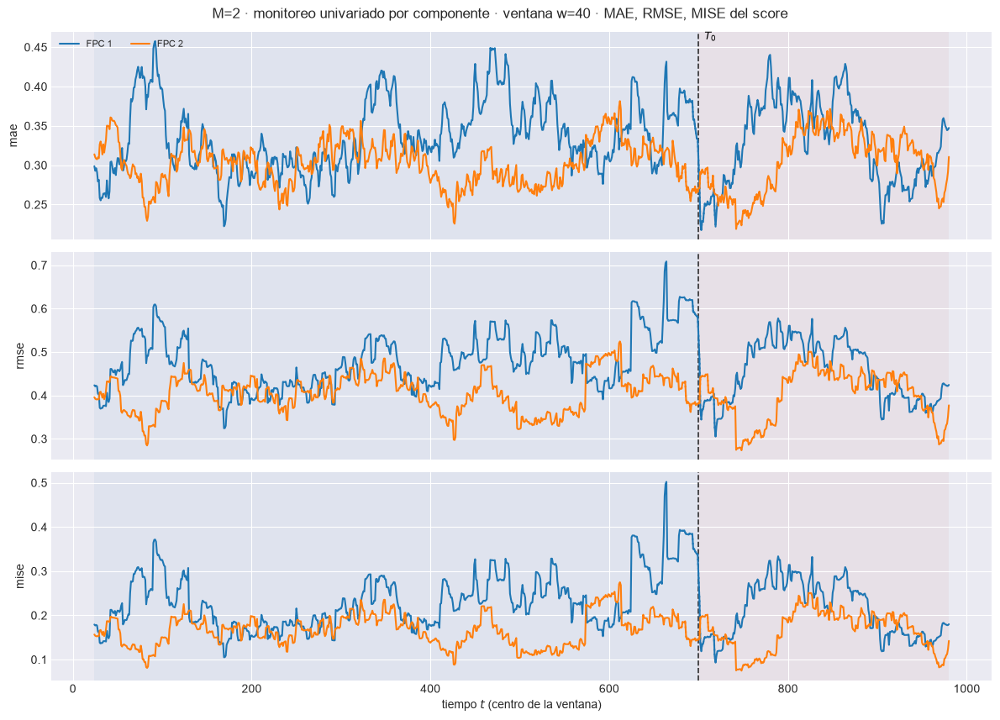

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.5s  t=19 [train] rmse=0.4025


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.498


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.5062


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.385


...

  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.2433


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] rmse=0.27


  960/967 (99.3%) t=0.1s eta=0.0s  t=978 [test] rmse=0.2848


  967/967 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.2268


[ventana_movil_scores[FPC 3, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


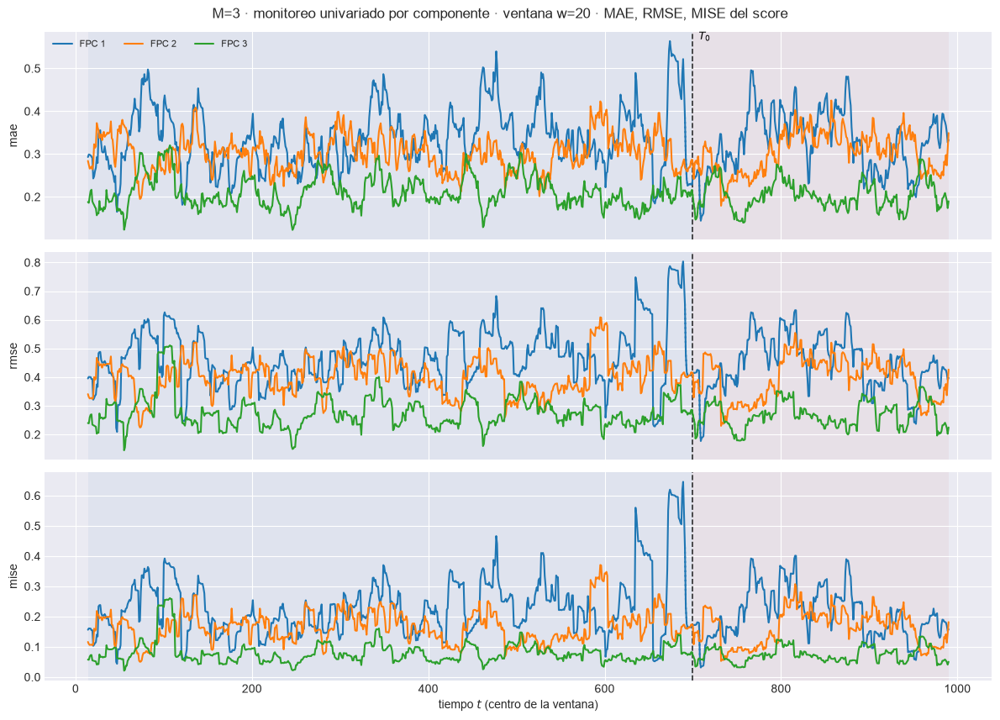

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.2878  w=30 test=0.2758


  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.3968  w=30 test=0.3757


  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.1575  w=30 test=0.1412


[plot_ventana_movil] listo: 3 pasos en 0.8s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_m03\91_ventana_univariado_w30.png


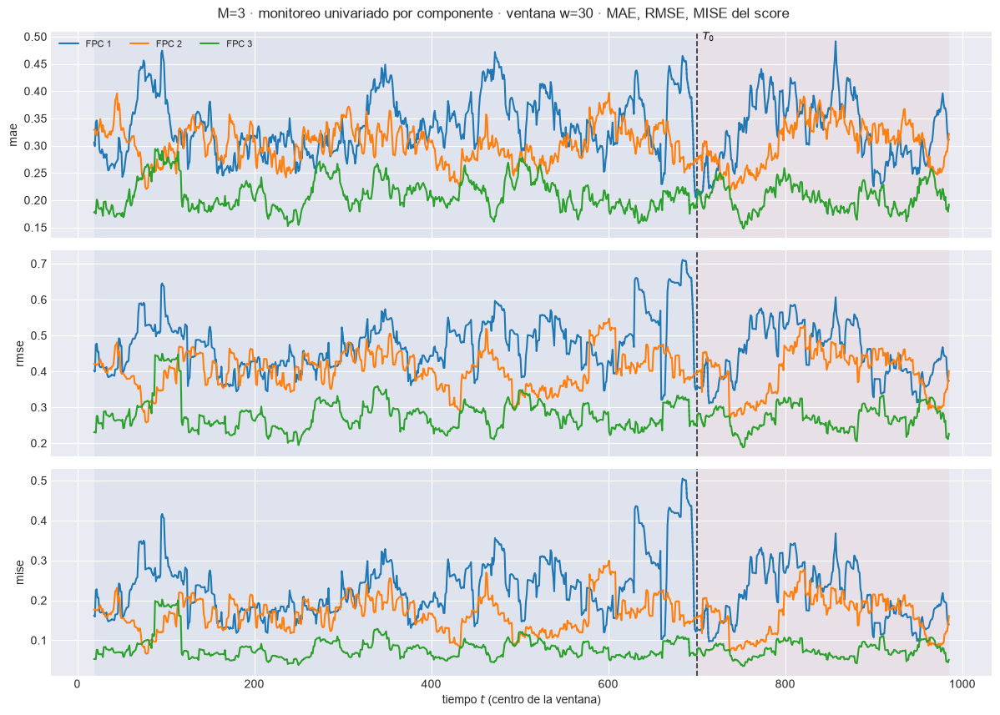

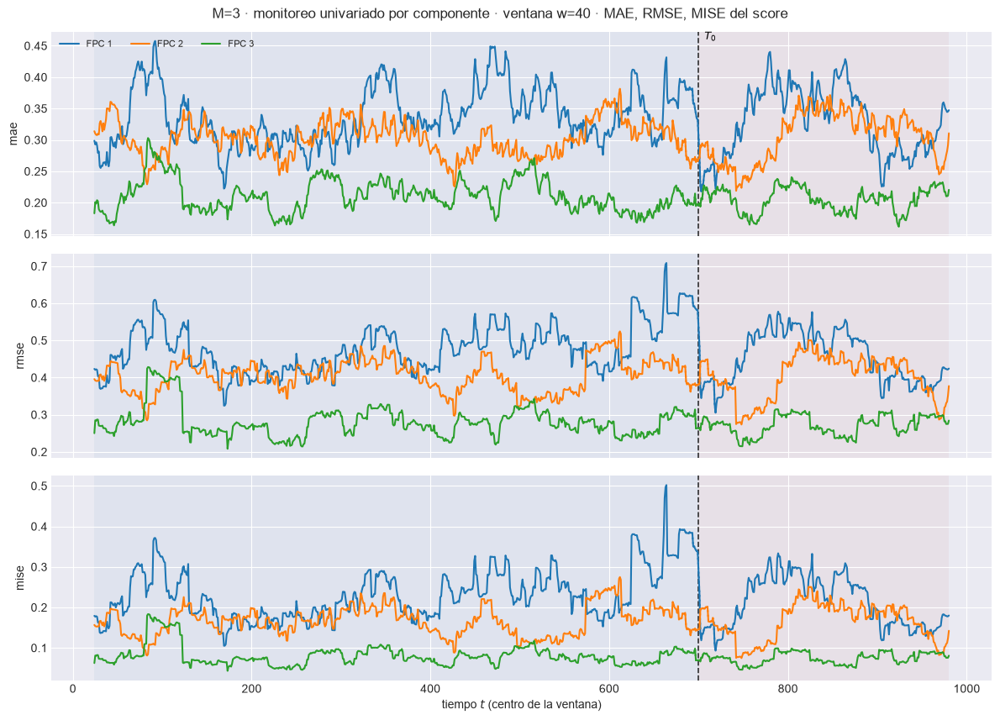

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.0s  t=19 [train] rmse=0.4025


  48/967 ( 5.0%) t=0.0s eta=0.1s  t=66 [train] rmse=0.498


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.5062


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.385


...

  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.2282


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] rmse=0.2546


  960/967 (99.3%) t=0.1s eta=0.0s  t=978 [test] rmse=0.1654


  967/967 (100.0%) t=0.1s eta=0.0s  t=985 [test] rmse=0.2035


[ventana_movil_scores[FPC 4, w=30]] listo: 967 pasos en 0.1s  29 ventanas cruzan T0


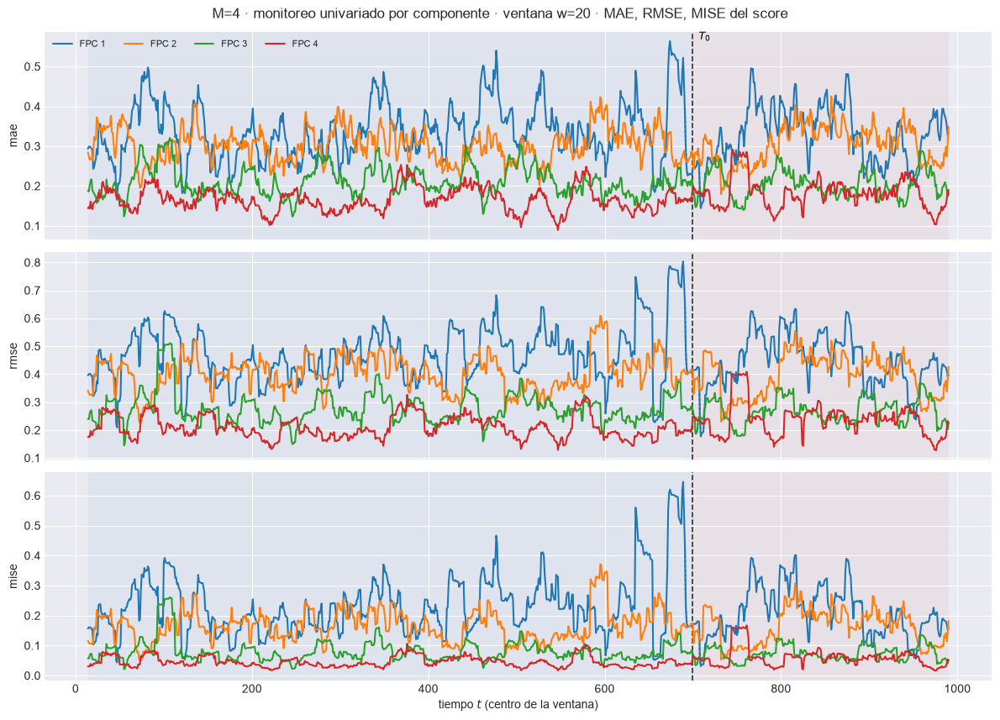

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  mae: w=30 train=0.2555  w=30 test=0.2424


  2/3 (66.7%) t=0.1s eta=0.0s  rmse: w=30 train=0.3344  w=30 test=0.3153


  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.1118  w=30 test=0.09942


[plot_ventana_movil] listo: 3 pasos en 0.8s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_m04\91_ventana_univariado_w30.png


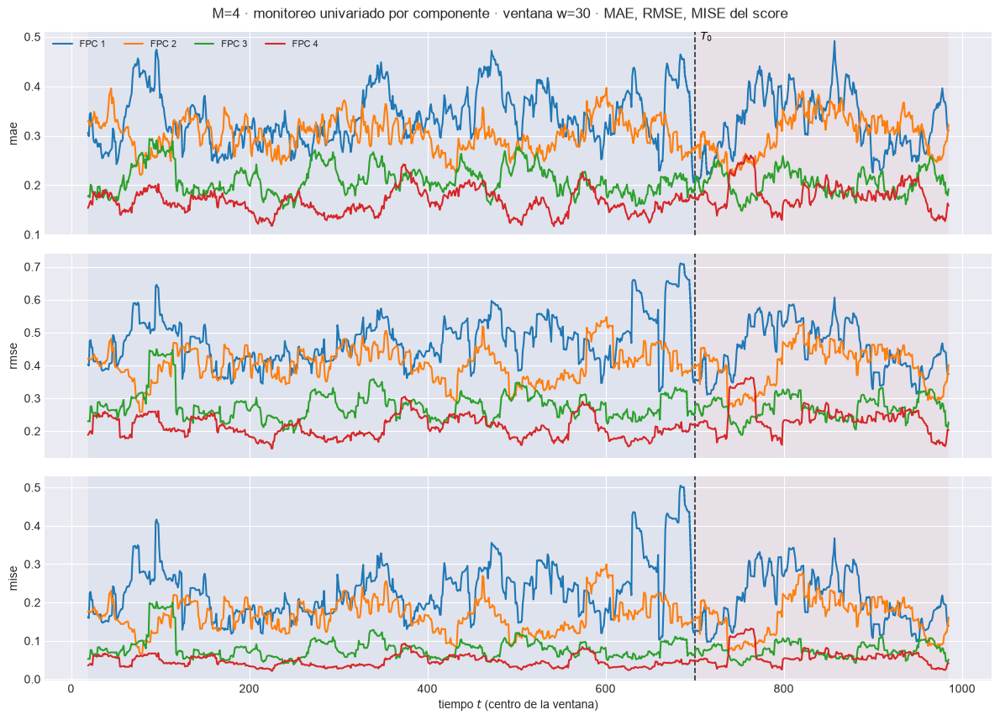

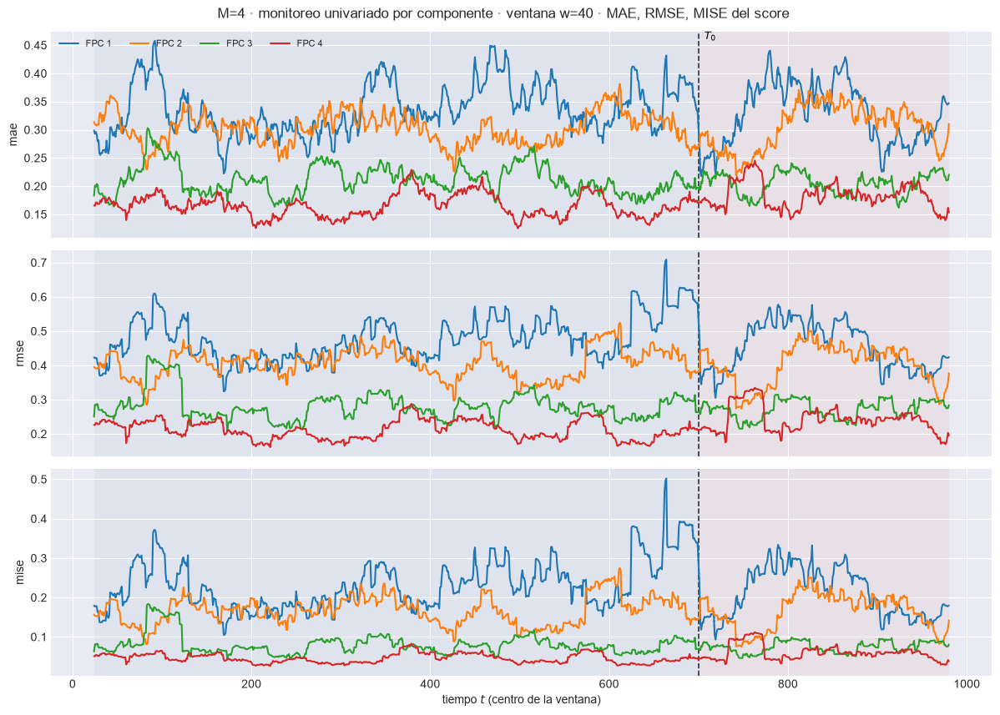

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.1s  t=19 [train] rmse=0.4025


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.498


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.5062


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.385


...

  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.2031


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] rmse=0.2048


  960/967 (99.3%) t=0.1s eta=0.0s  t=978 [test] rmse=0.1567


  967/967 (100.0%) t=0.1s eta=0.0s  t=985 [test] rmse=0.1349


[ventana_movil_scores[FPC 5, w=30]] listo: 967 pasos en 0.1s  29 ventanas cruzan T0


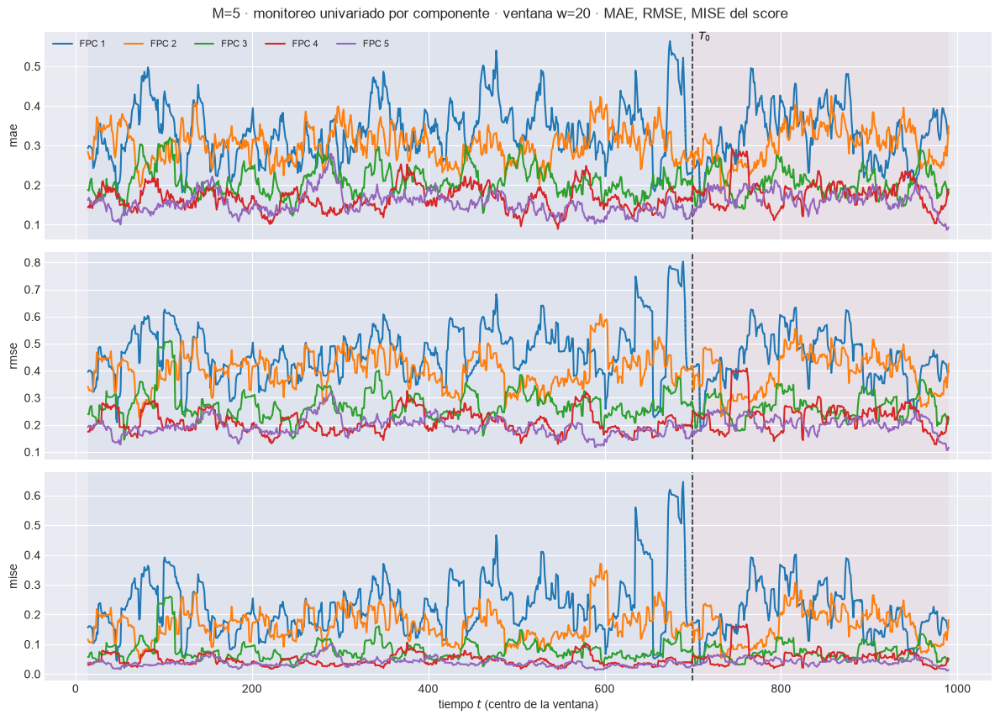

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  mae: w=30 train=0.2112  w=30 test=0.2149


  2/3 (66.7%) t=0.1s eta=0.0s  rmse: w=30 train=0.2784  w=30 test=0.2805


  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.07749  w=30 test=0.07867


[plot_ventana_movil] listo: 3 pasos en 0.9s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_m05\91_ventana_univariado_w30.png


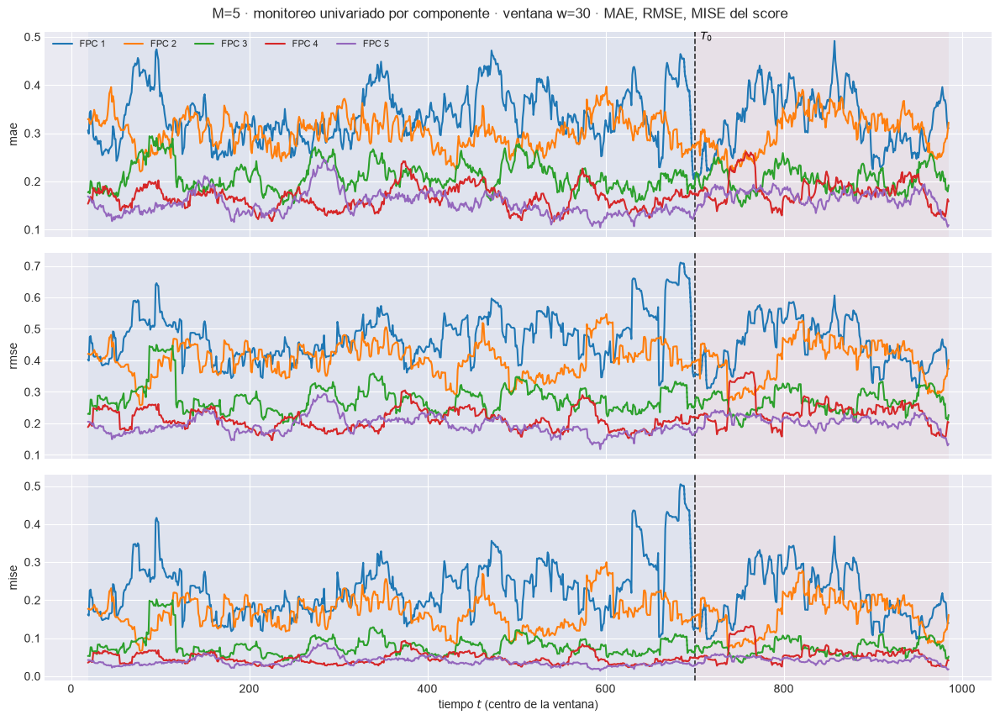

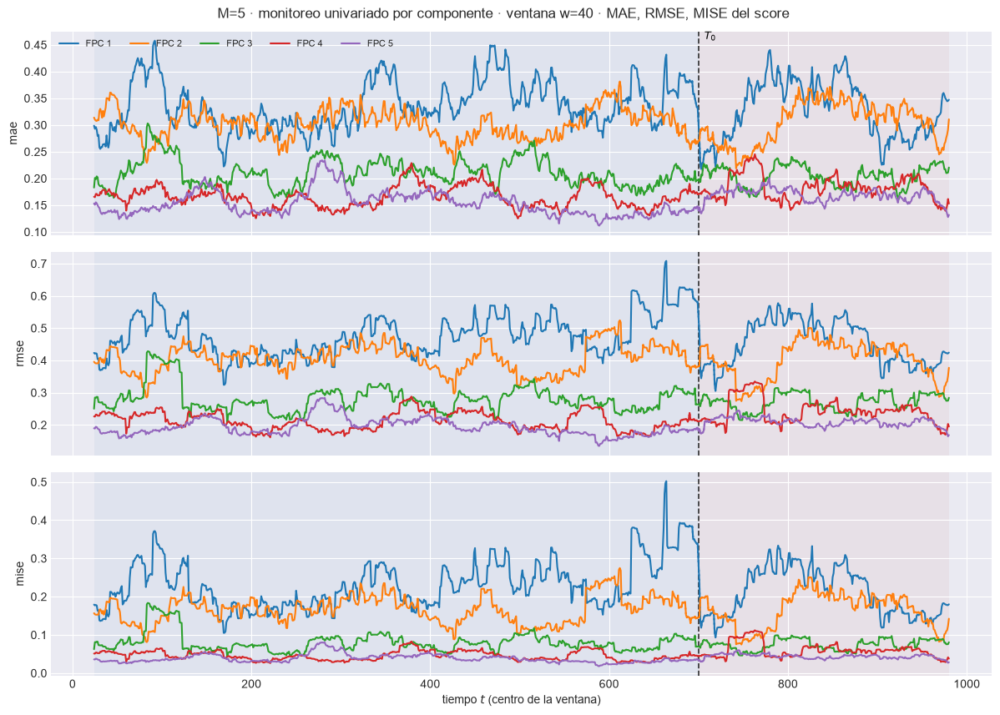

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.2s  t=19 [train] rmse=0.4025


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.498


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.5062


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.385


...

  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.1421


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] rmse=0.1267


  960/967 (99.3%) t=0.1s eta=0.0s  t=978 [test] rmse=0.1573


  967/967 (100.0%) t=0.1s eta=0.0s  t=985 [test] rmse=0.1584


[ventana_movil_scores[FPC 6, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


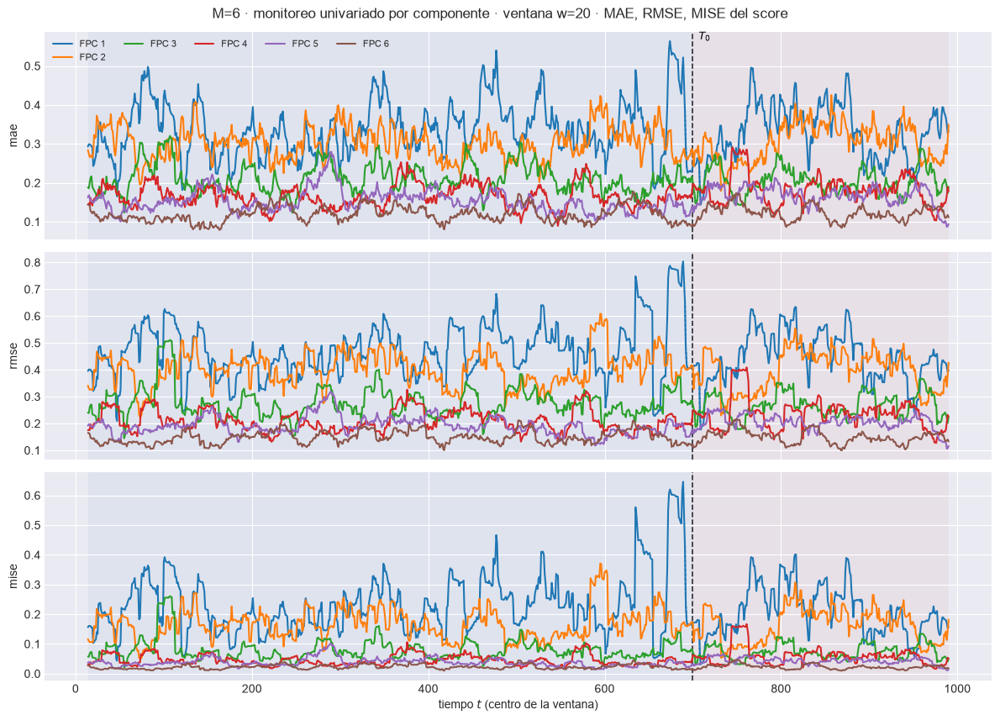

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  mae: w=30 train=0.1881  w=30 test=0.1919


  2/3 (66.7%) t=0.1s eta=0.0s  rmse: w=30 train=0.245  w=30 test=0.2527


  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.06002  w=30 test=0.06384


[plot_ventana_movil] listo: 3 pasos en 1.0s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_m06\91_ventana_univariado_w30.png


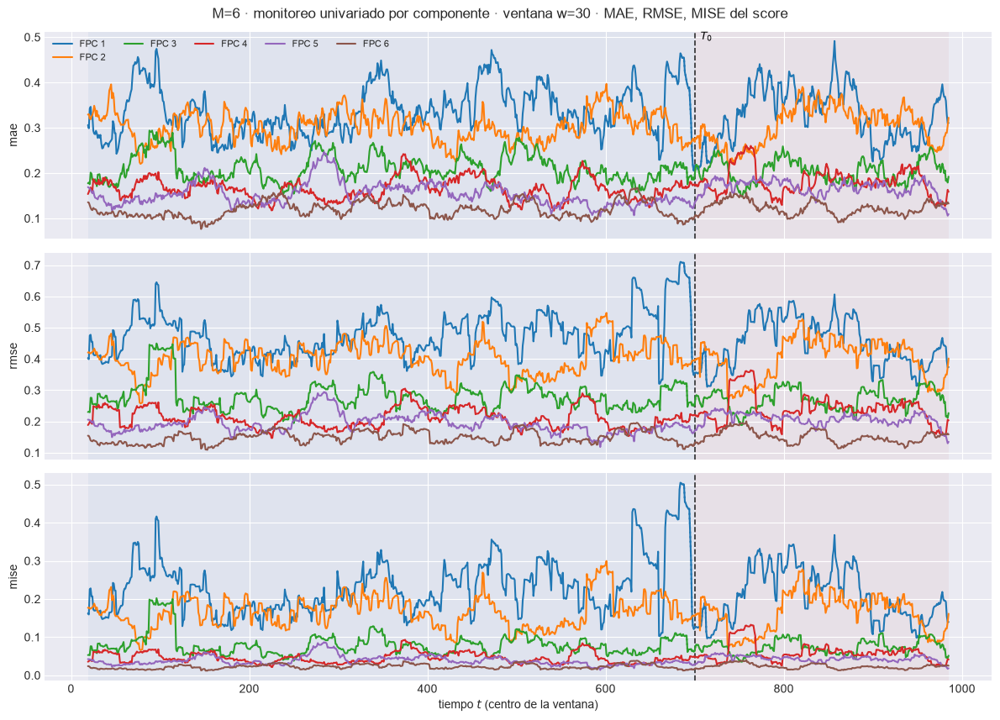

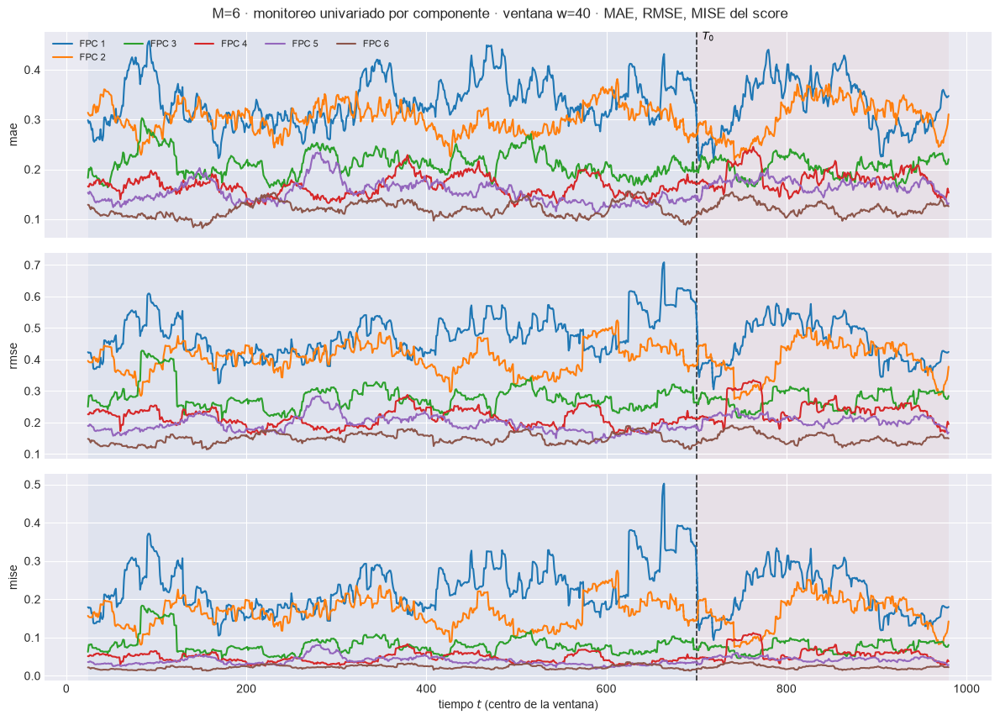

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.5s  t=19 [train] rmse=0.4025


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.498


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.5062


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.385


...

  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.1462


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] rmse=0.1099


  960/967 (99.3%) t=0.1s eta=0.0s  t=978 [test] rmse=0.1183


  967/967 (100.0%) t=0.1s eta=0.0s  t=985 [test] rmse=0.1214


[ventana_movil_scores[FPC 7, w=30]] listo: 967 pasos en 0.1s  29 ventanas cruzan T0


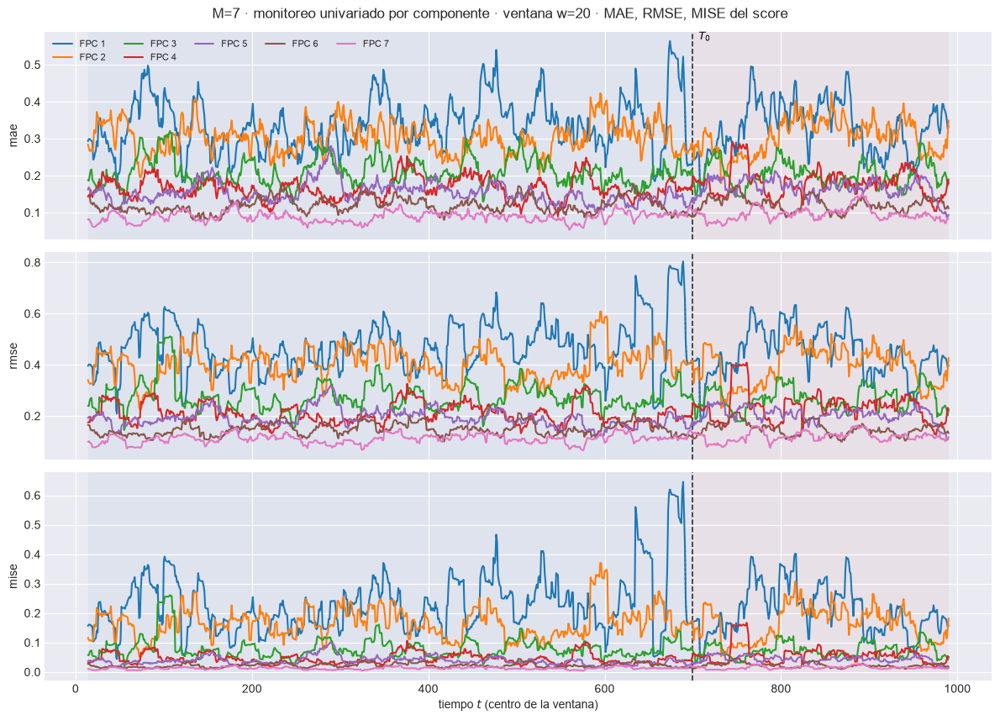

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  mae: w=30 train=0.1717  w=30 test=0.1816


  2/3 (66.7%) t=0.1s eta=0.0s  rmse: w=30 train=0.2187  w=30 test=0.2316


  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.04783  w=30 test=0.05366


[plot_ventana_movil] listo: 3 pasos en 1.0s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_m07\91_ventana_univariado_w30.png


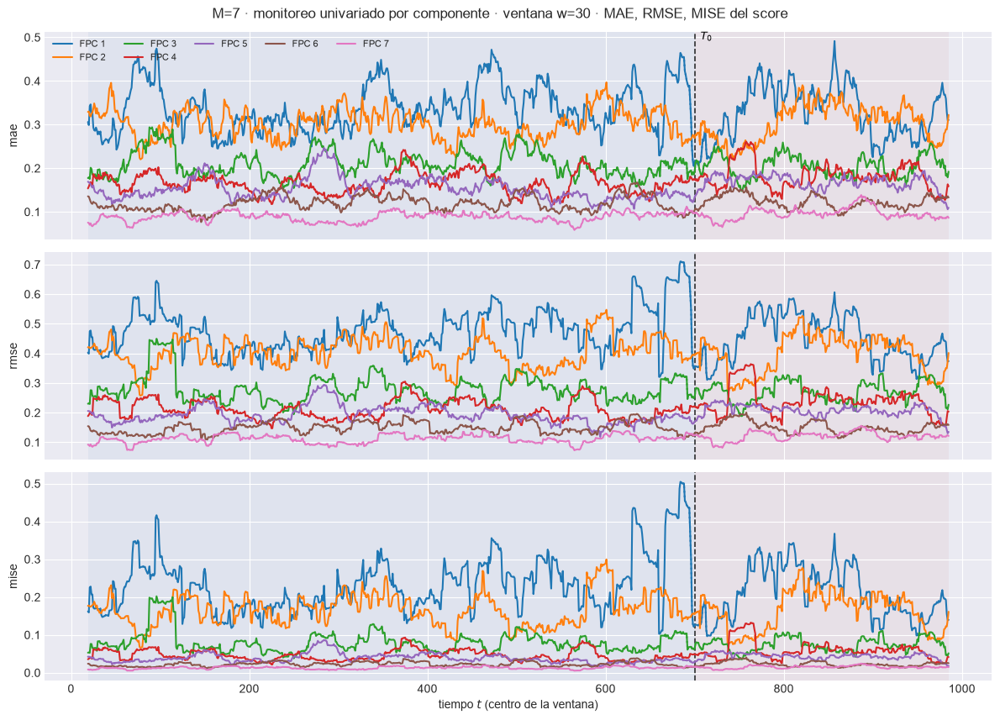

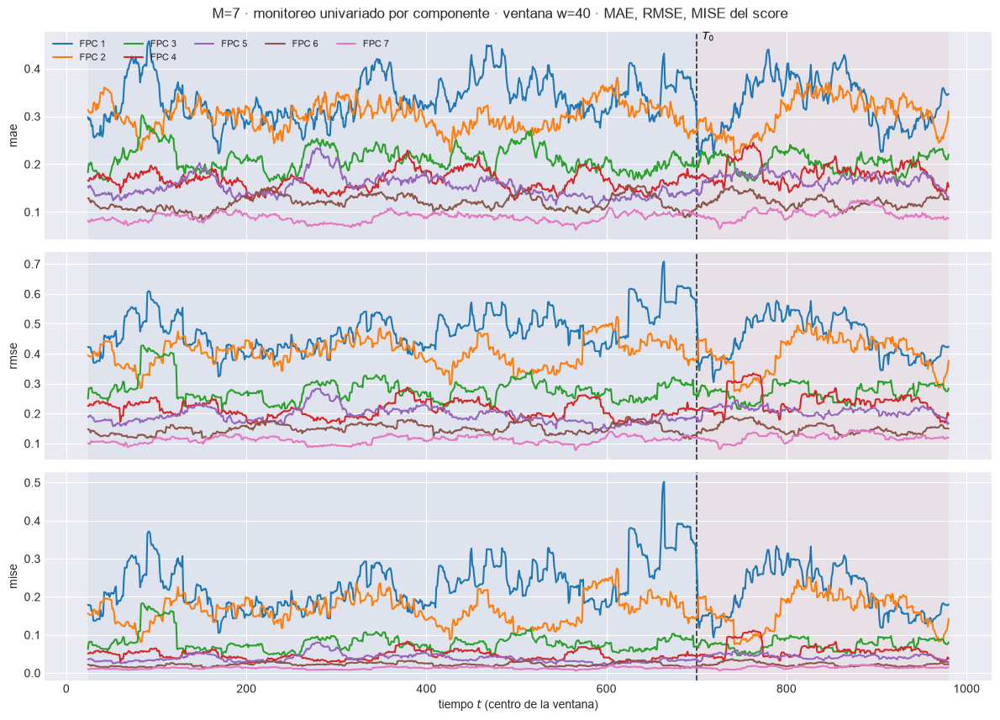

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.3s  t=19 [train] rmse=0.4025


  48/967 ( 5.0%) t=0.0s eta=0.1s  t=66 [train] rmse=0.498


  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.5062


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.385


...

  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.08297


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] rmse=0.0931


  960/967 (99.3%) t=0.1s eta=0.0s  t=978 [test] rmse=0.09117


  967/967 (100.0%) t=0.1s eta=0.0s  t=985 [test] rmse=0.07744


[ventana_movil_scores[FPC 8, w=30]] listo: 967 pasos en 0.1s  29 ventanas cruzan T0


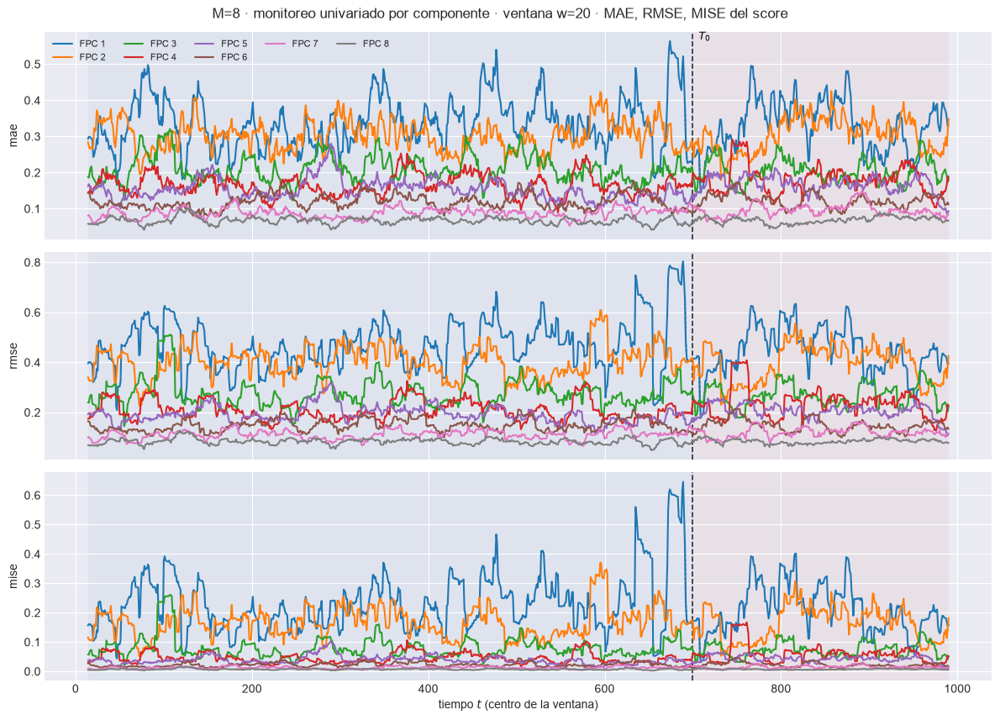

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  mae: w=30 train=0.1567  w=30 test=0.1729


  2/3 (66.7%) t=0.1s eta=0.0s  rmse: w=30 train=0.1953  w=30 test=0.2181


  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.03815  w=30 test=0.04758


[plot_ventana_movil] listo: 3 pasos en 1.0s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_m08\91_ventana_univariado_w30.png


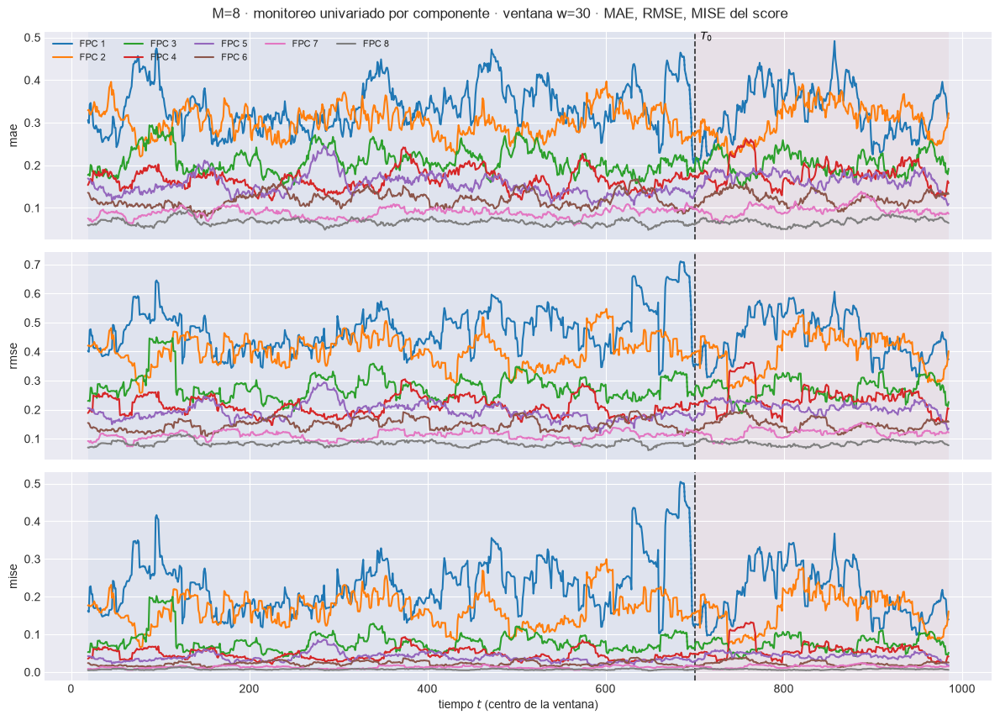

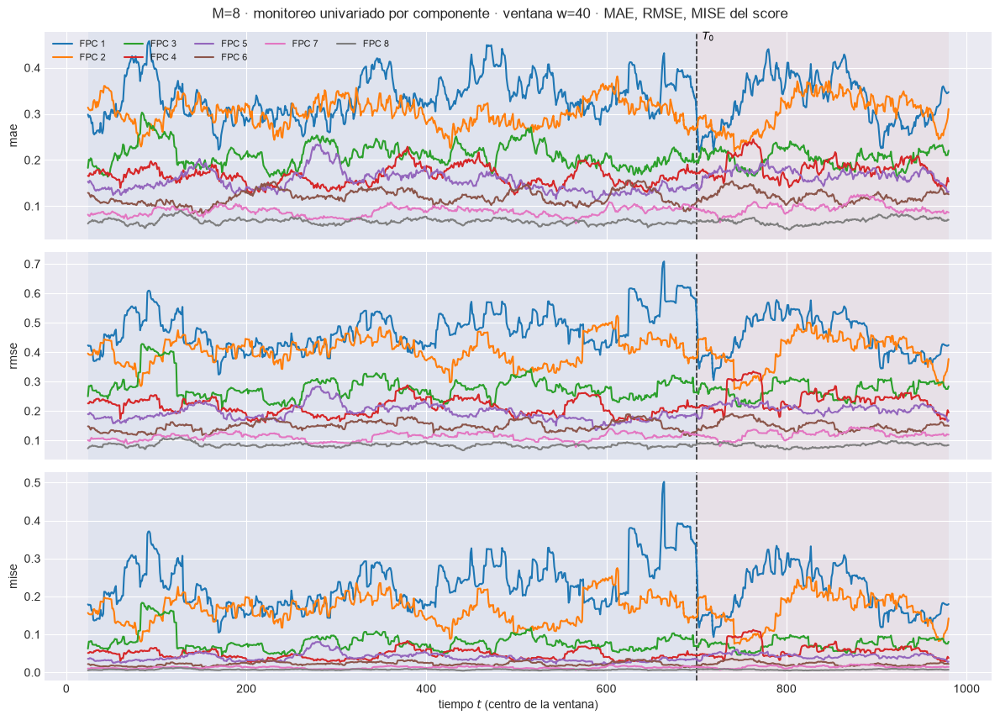

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.1s  t=19 [train] rmse=0.4025


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.498


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.5062


  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.385


...

  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.05974


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] rmse=0.06147


  960/967 (99.3%) t=0.1s eta=0.0s  t=978 [test] rmse=0.06049


  967/967 (100.0%) t=0.1s eta=0.0s  t=985 [test] rmse=0.06622


[ventana_movil_scores[FPC 9, w=30]] listo: 967 pasos en 0.2s  29 ventanas cruzan T0


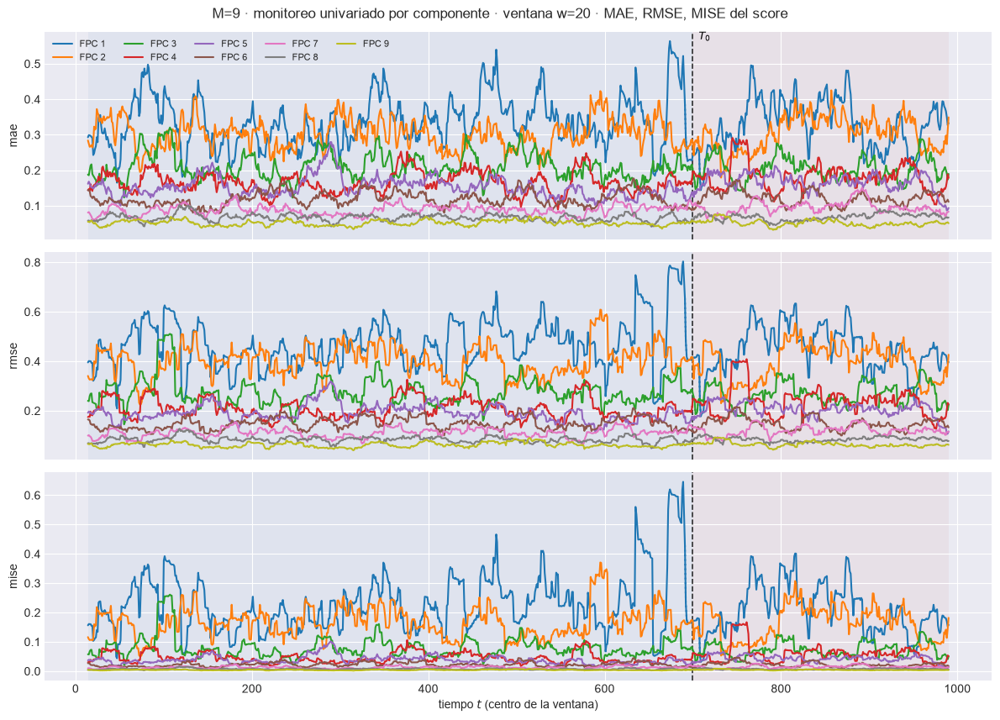

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  mae: w=30 train=0.1436  w=30 test=0.1599


  2/3 (66.7%) t=0.1s eta=0.0s  rmse: w=30 train=0.1805  w=30 test=0.2019


  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.03257  w=30 test=0.04077


[plot_ventana_movil] listo: 3 pasos en 1.0s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_m09\91_ventana_univariado_w30.png


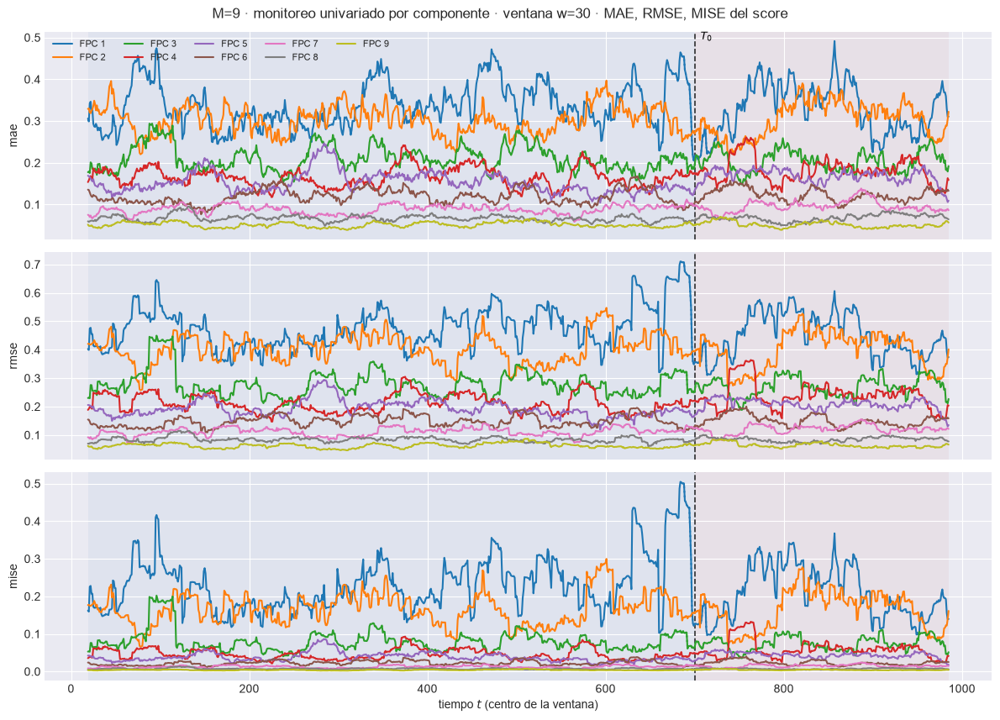

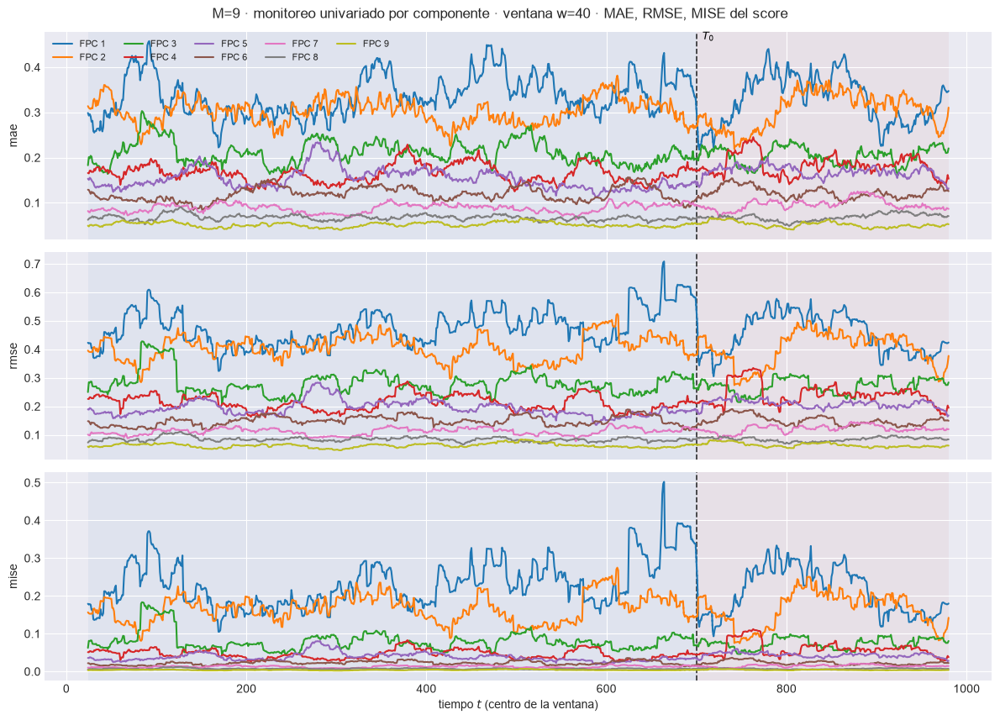

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)


  1/967 ( 0.1%) t=0.0s eta=1.6s  t=19 [train] rmse=0.4025


  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.498


  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.5062


  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.385


...

  864/967 (89.3%) t=0.1s eta=0.0s  t=882 [test] rmse=0.04087


  912/967 (94.3%) t=0.1s eta=0.0s  t=930 [test] rmse=0.04841


  960/967 (99.3%) t=0.1s eta=0.0s  t=978 [test] rmse=0.03484


  967/967 (100.0%) t=0.1s eta=0.0s  t=985 [test] rmse=0.03416


[ventana_movil_scores[FPC 10, w=30]] listo: 967 pasos en 0.1s  29 ventanas cruzan T0


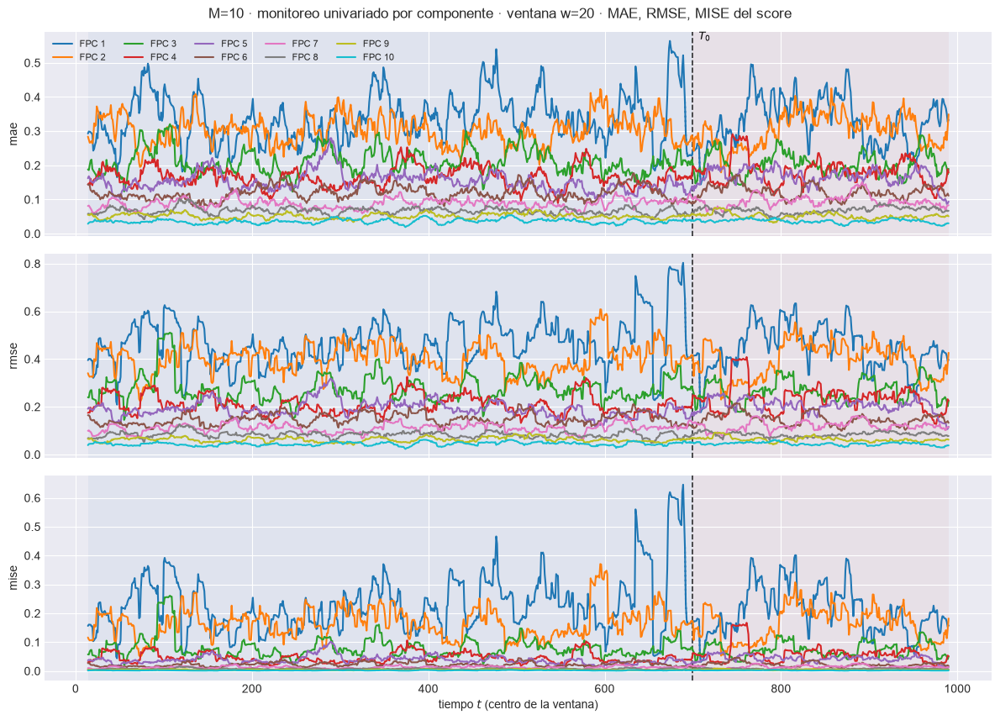

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.1s eta=0.2s  mae: w=30 train=0.1318  w=30 test=0.142


  2/3 (66.7%) t=0.2s eta=0.1s  rmse: w=30 train=0.1681  w=30 test=0.1772


  3/3 (100.0%) t=0.2s eta=0.0s  mise: w=30 train=0.02826  w=30 test=0.0314


[plot_ventana_movil] listo: 3 pasos en 1.3s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_m10\91_ventana_univariado_w30.png


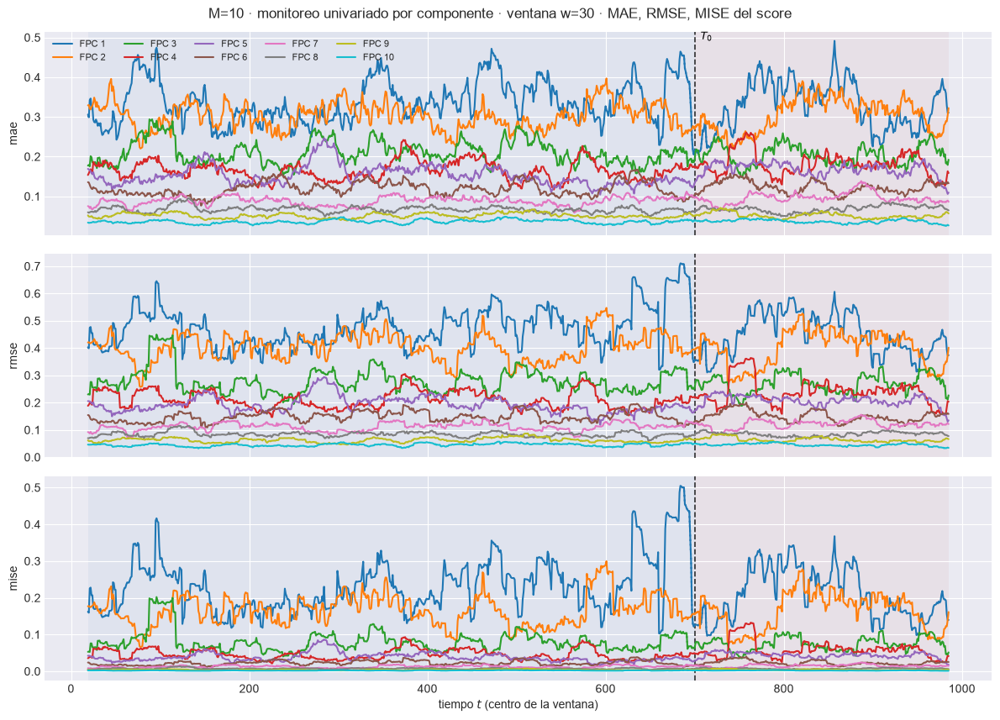

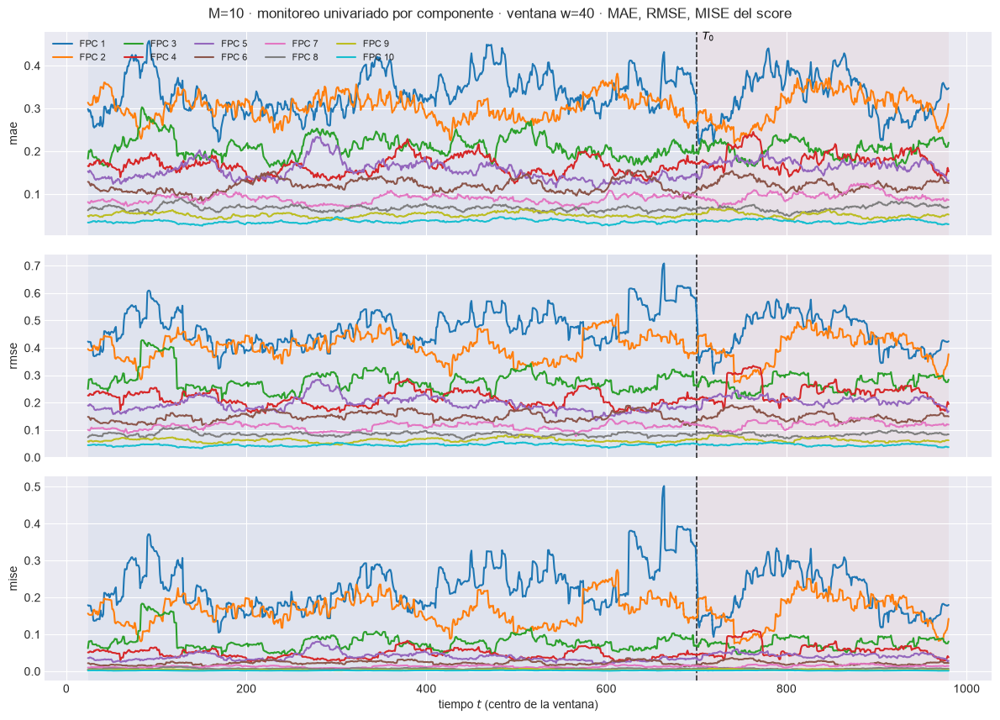

In [23]:
for M in M_OK:
    e = EST[M]
    monitoreo_scores(e, DIS, ORIG)
    for w in VENTANAS_W:
        tsc = e["tablas_score"][w].copy()
        tsc["mise"] = tsc["rmse"] ** 2      # MSE del score: análogo puntual del MISE
        plot_ventana_movil(
            tsc, T0, ["mae", "rmse", "mise"], columna_grupo="componente",
            title=f"M={M} · monitoreo univariado por componente · ventana w={w} · MAE, RMSE, MISE del score",
            save_path=str(e["paths"]["out_report"] / f"91_ventana_univariado_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

## 10. Evaluación puntual de los scores (coeficientes FPCA)

La banda es `li_s`/`ls_s` de §3, antes de propagar.

### 10.1 Cómo se mueve el intervalo de credibilidad de cada score

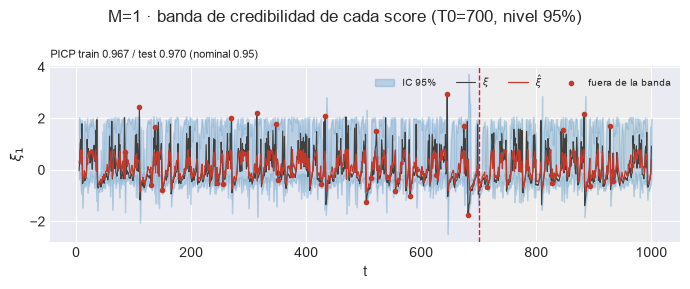

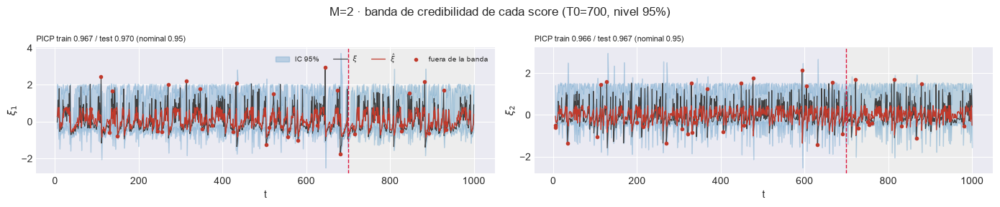

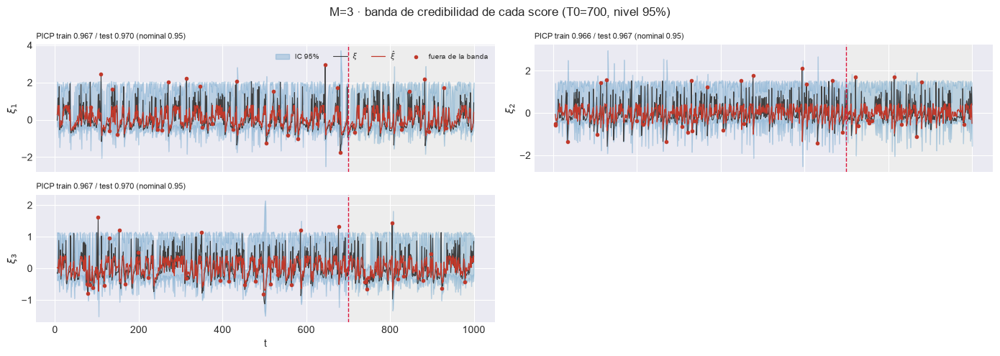

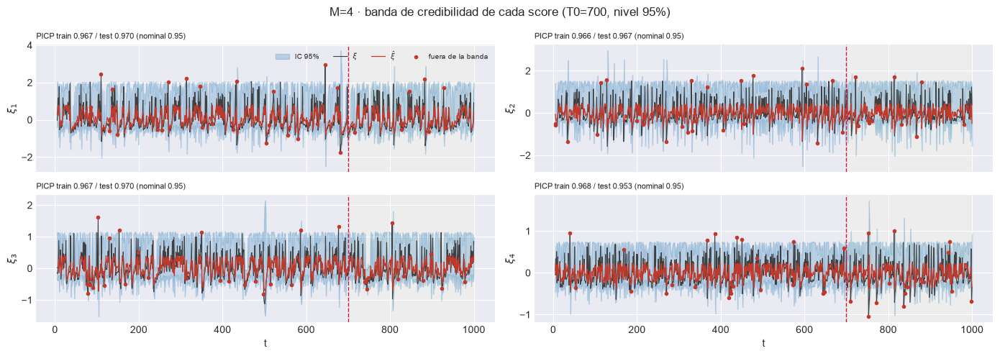

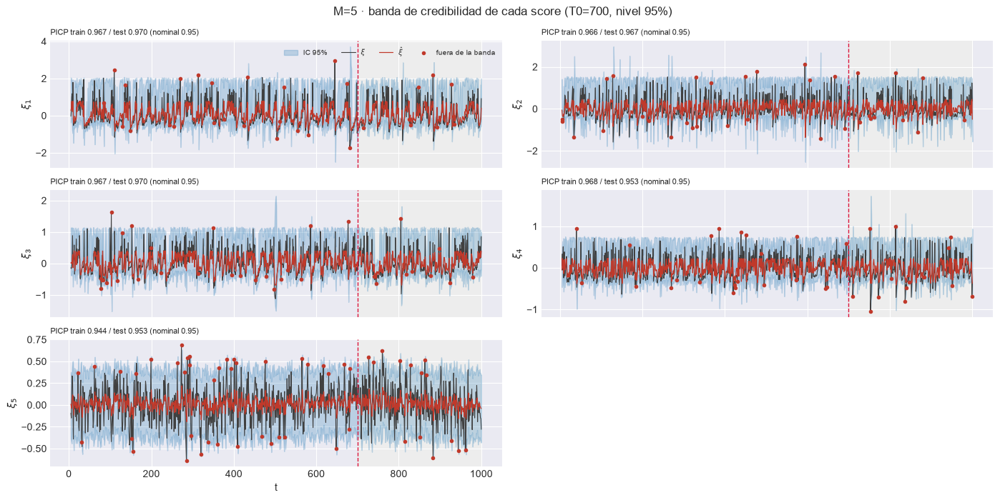

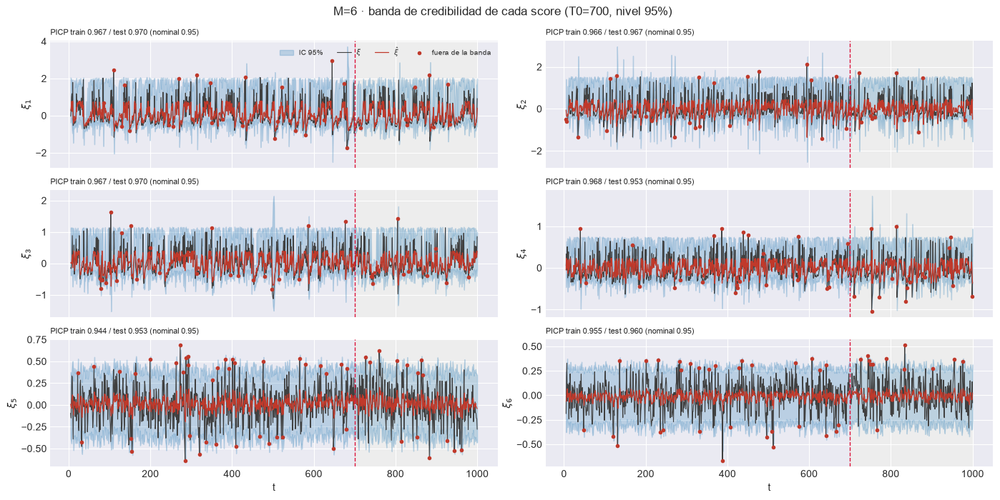

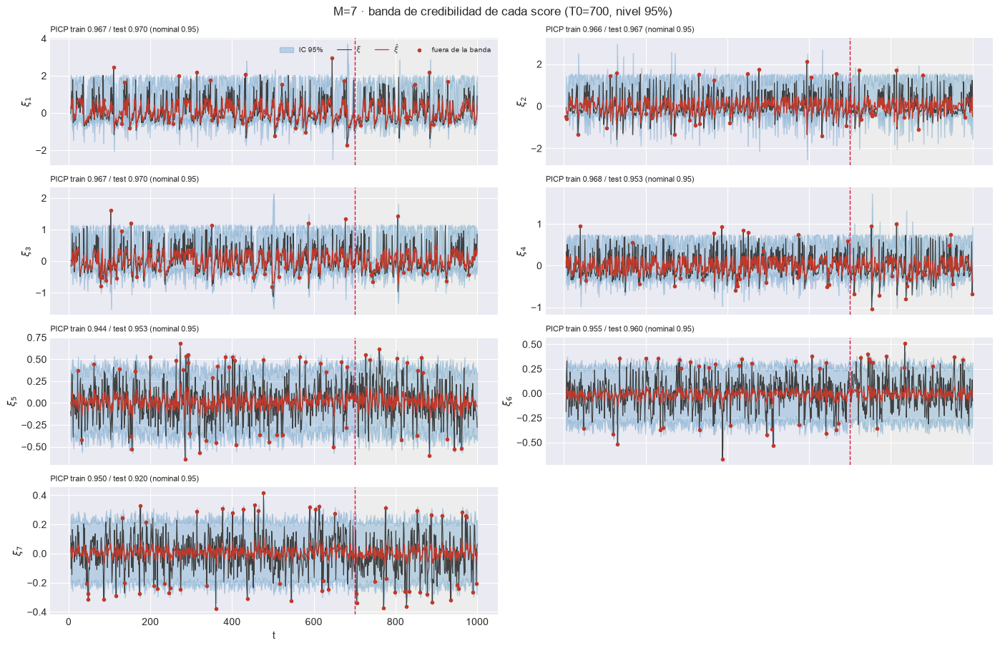

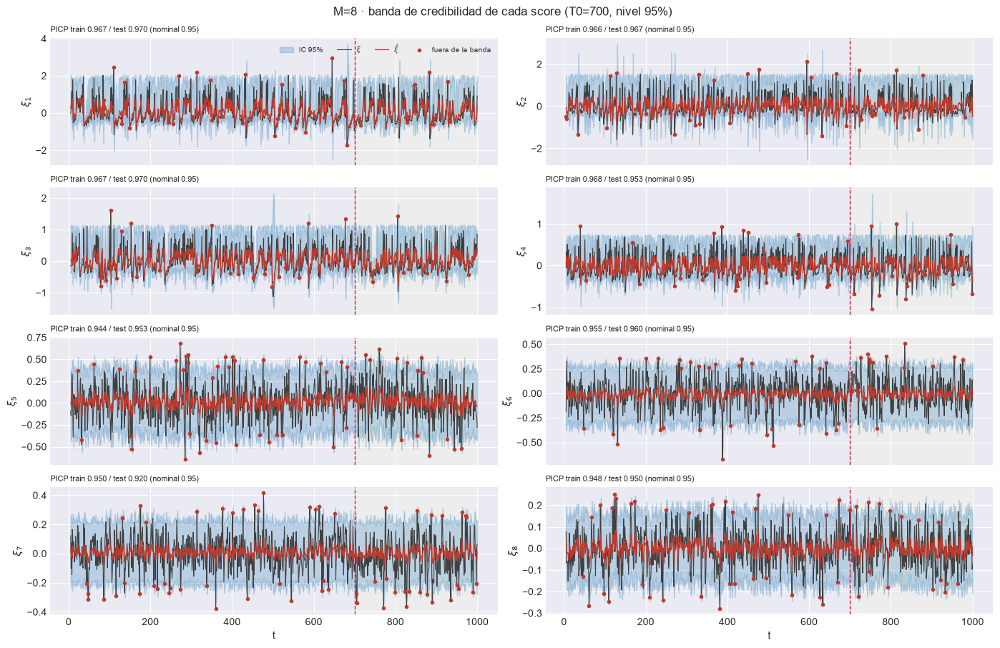

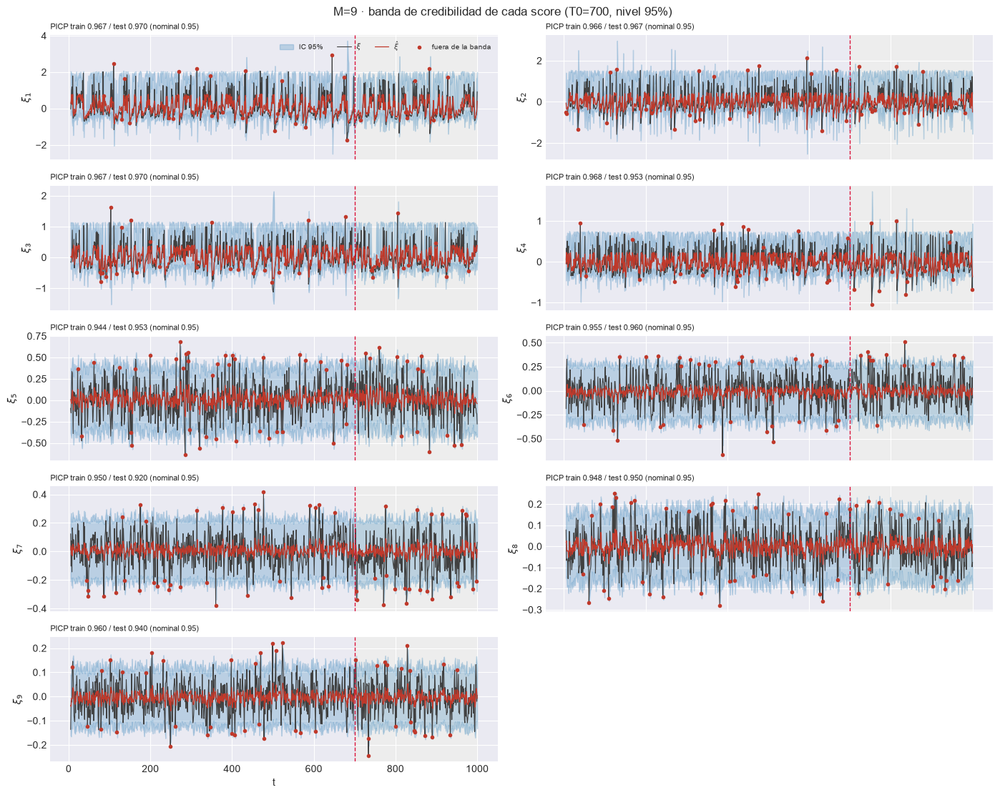

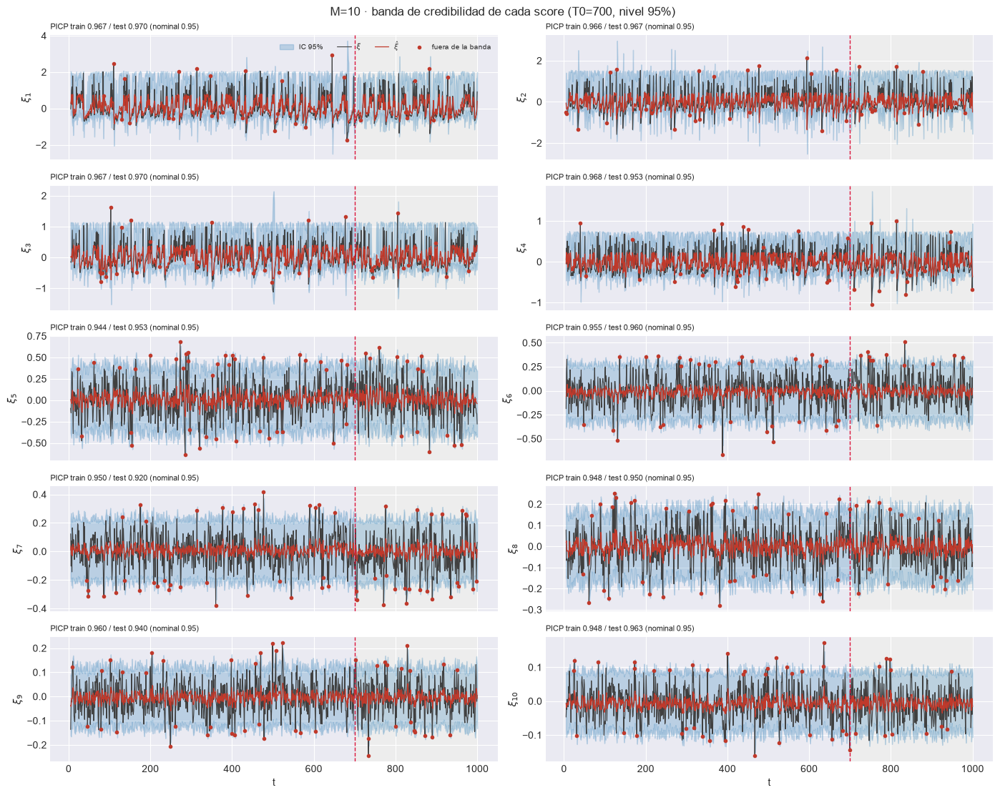

In [24]:
for M in M_OK:
    plot_scores_banda(EST[M], ORIG, DIS, M,
                      save_path=EST[M]["paths"]["out_report"] / "92_scores_banda_credibilidad.png")
    plt.show()

### 10.2 Métricas de intervalo sobre los scores

PICP, MPIW, Winkler y ACE por componente; global por bloque y sobre la ventana móvil.

OK ninguna componente se aleja mas de 0.1 del nominal en test.


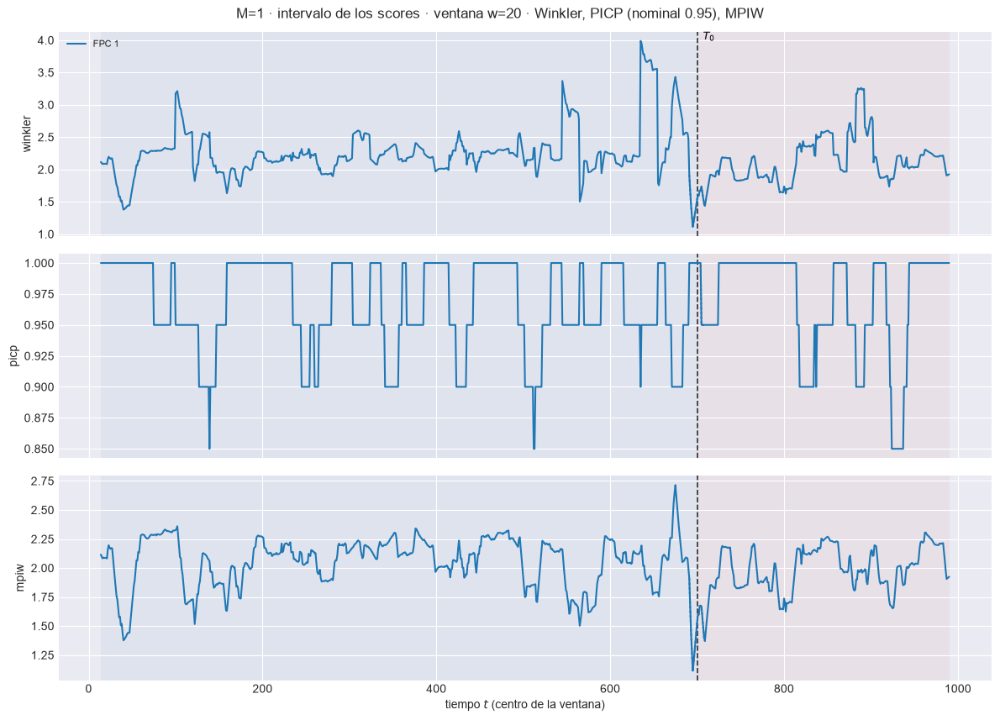

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=2.223  w=30 test=2.059


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.0s eta=0.0s  mpiw: w=30 train=2.087  w=30 test=1.984


[plot_ventana_movil] listo: 3 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_m01\93_ventana_scores_intervalo_w30.png


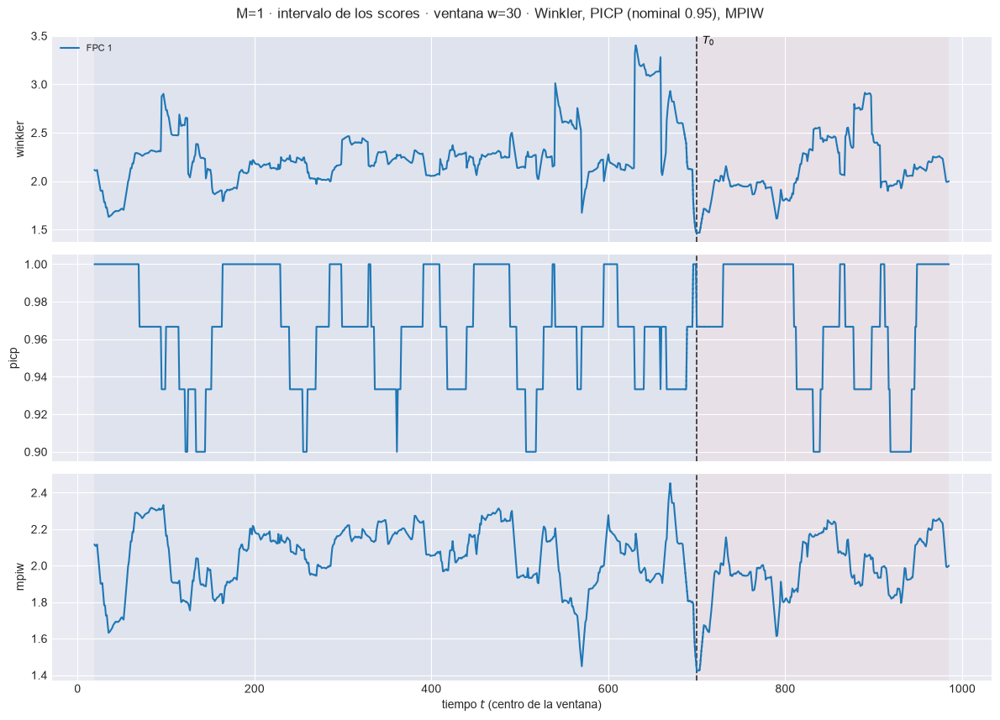

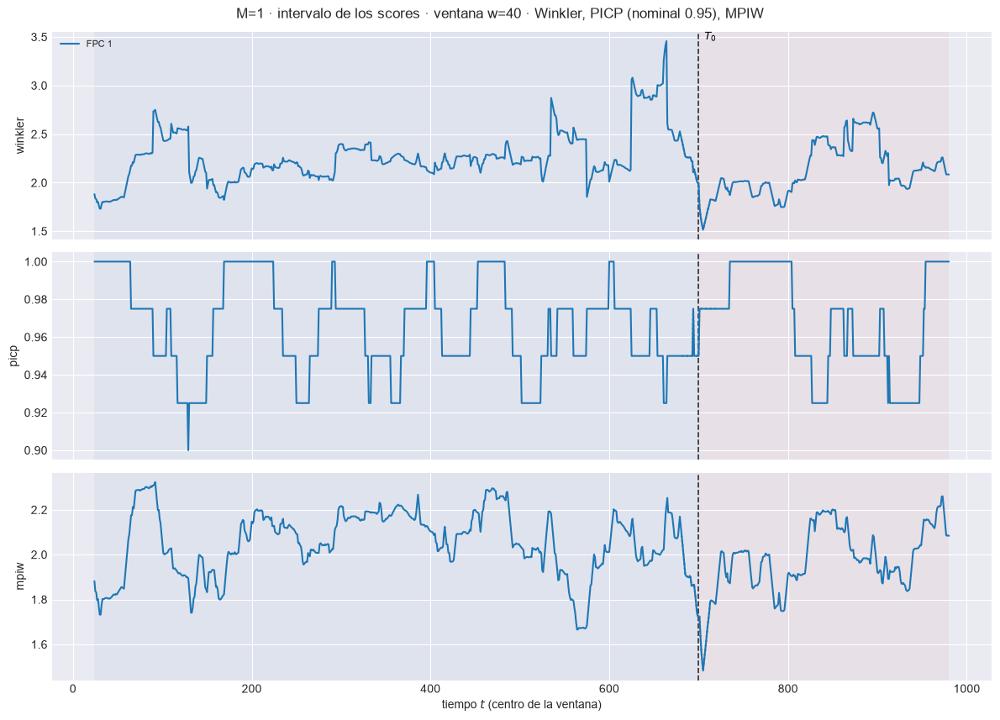

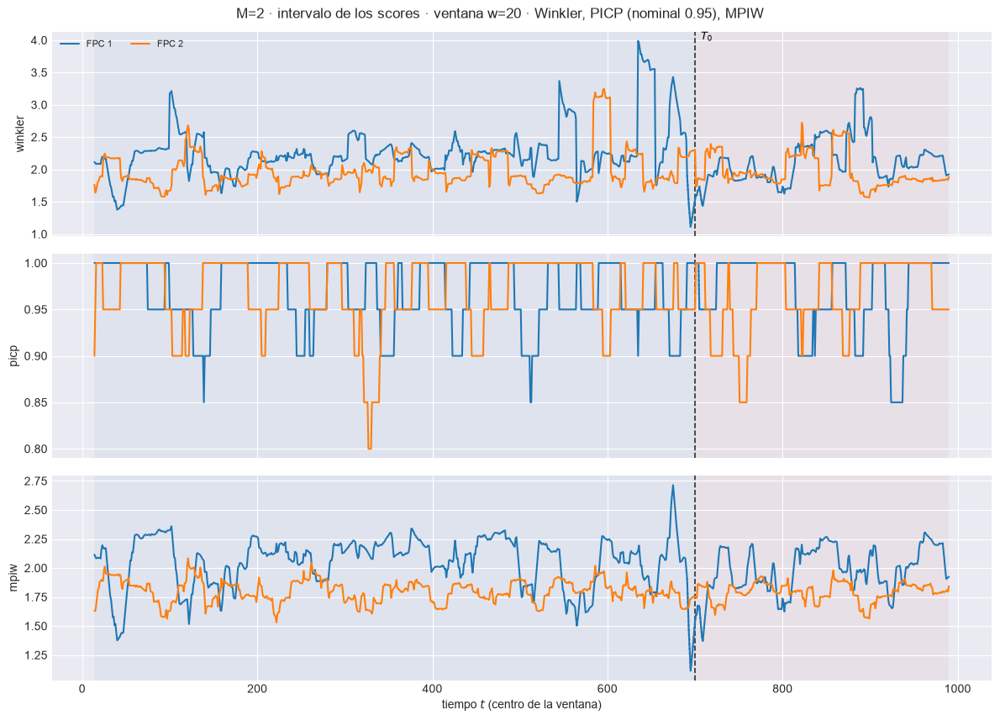

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=2.095  w=30 test=1.996


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=1.888  w=30 test=1.855


[plot_ventana_movil] listo: 3 pasos en 0.8s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_m02\93_ventana_scores_intervalo_w30.png


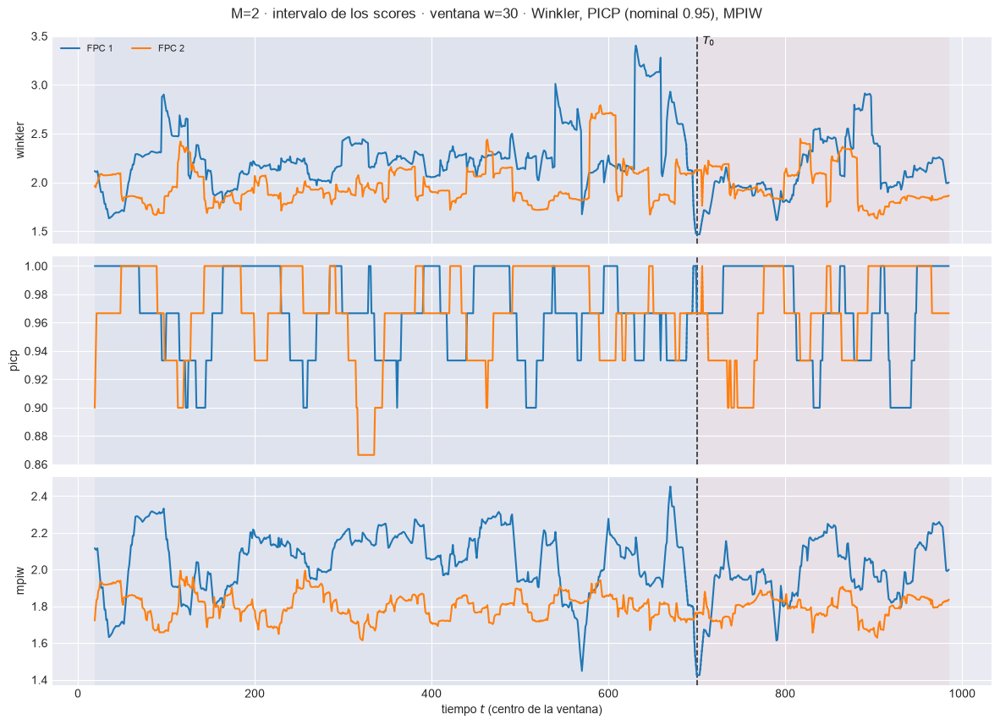

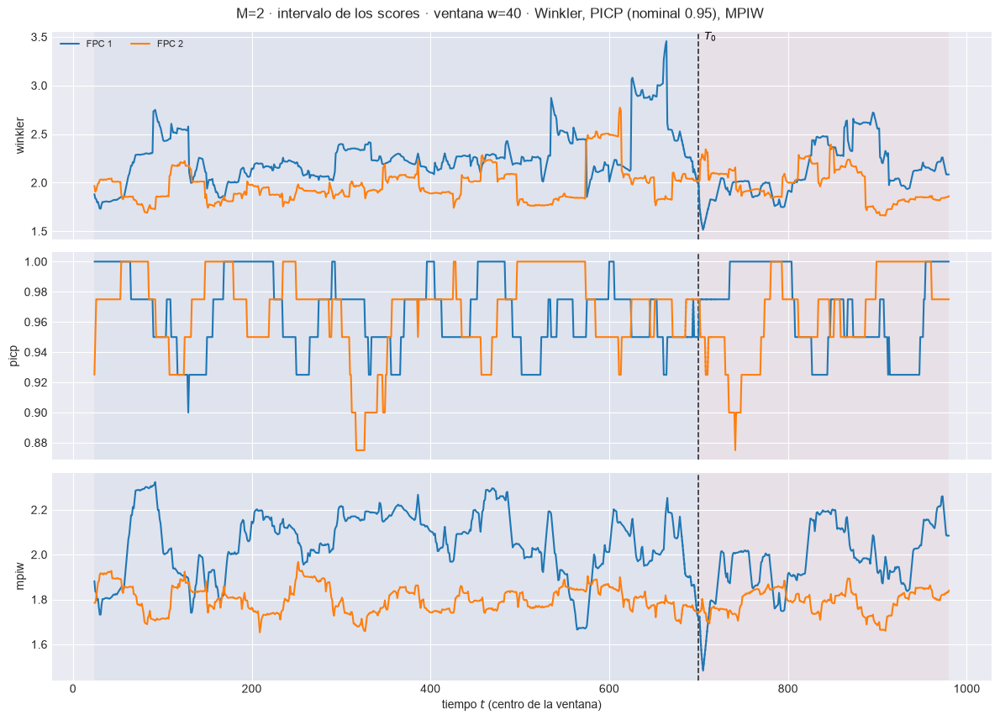

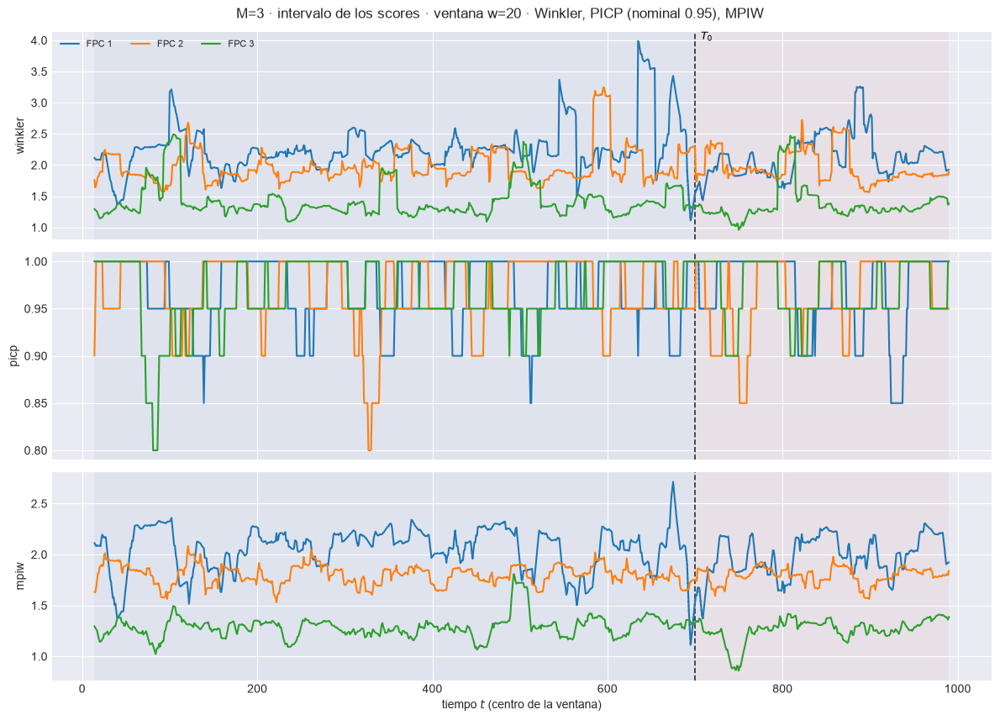

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=1.902  w=30 test=1.883


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=1.791  w=30 test=1.798


[plot_ventana_movil] listo: 3 pasos en 0.8s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_m03\93_ventana_scores_intervalo_w30.png


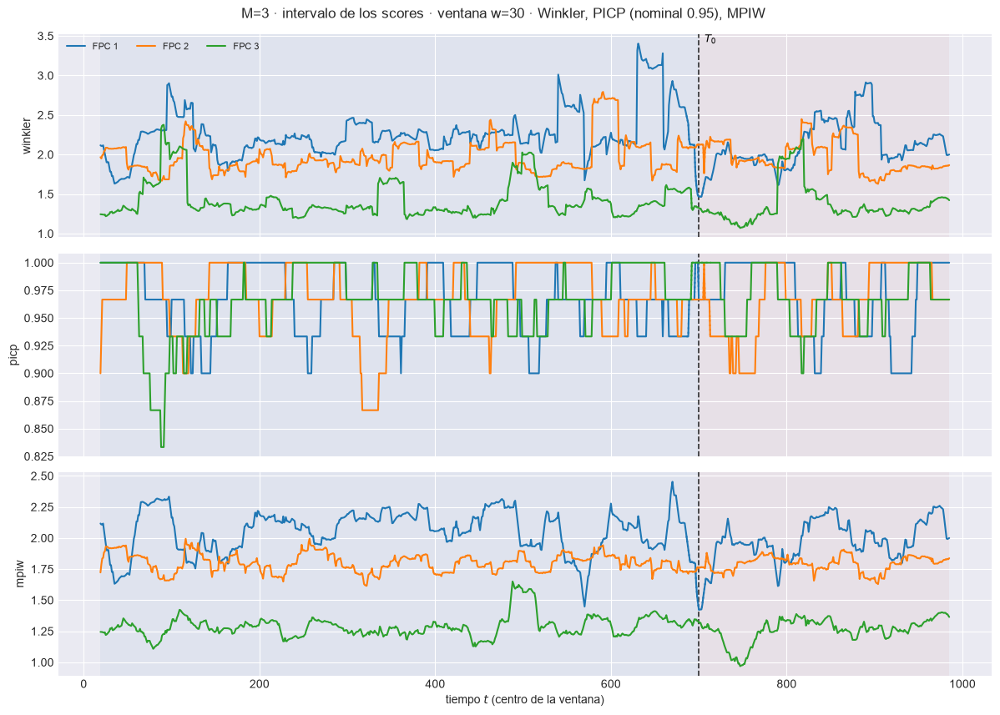

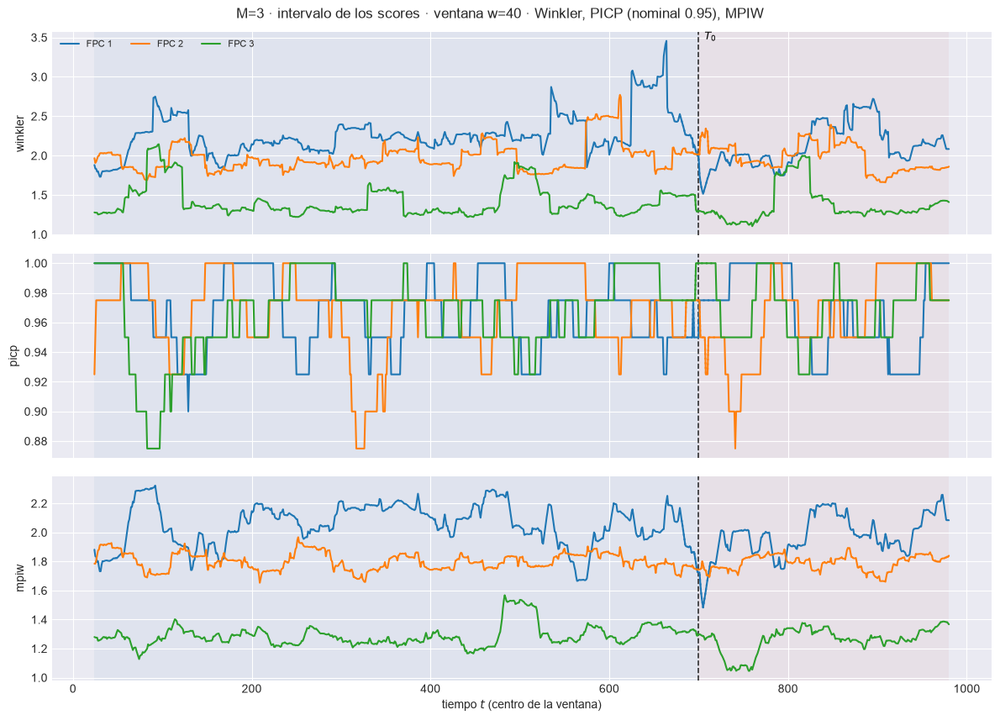

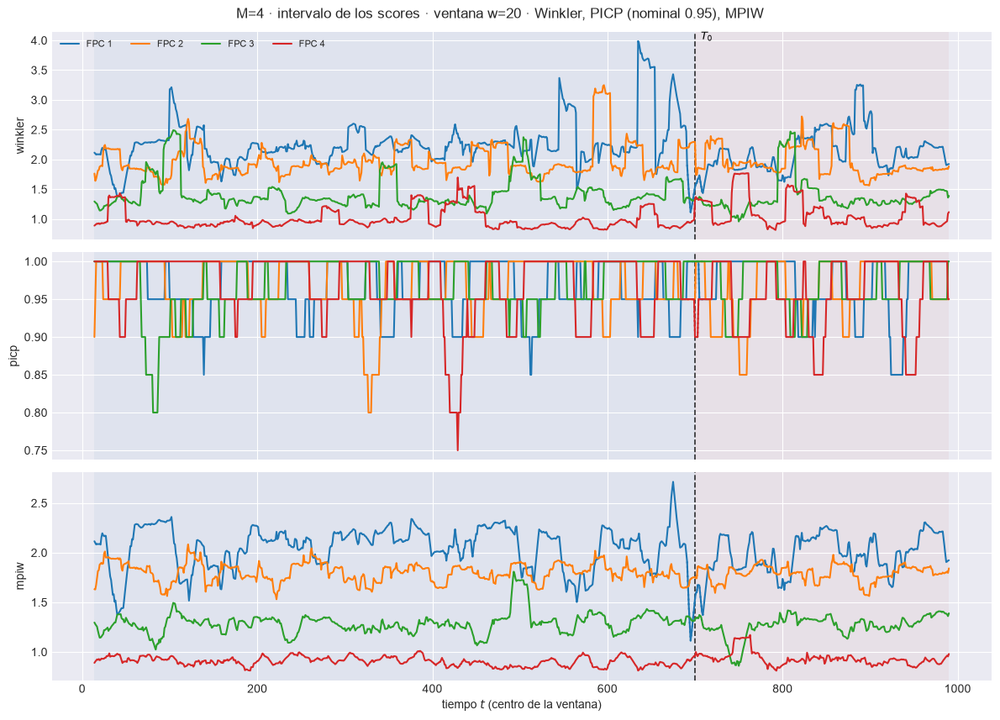

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  winkler: w=30 train=1.729  w=30 test=1.725


  2/3 (66.7%) t=0.1s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=1.606  w=30 test=1.508


[plot_ventana_movil] listo: 3 pasos en 0.9s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_m04\93_ventana_scores_intervalo_w30.png


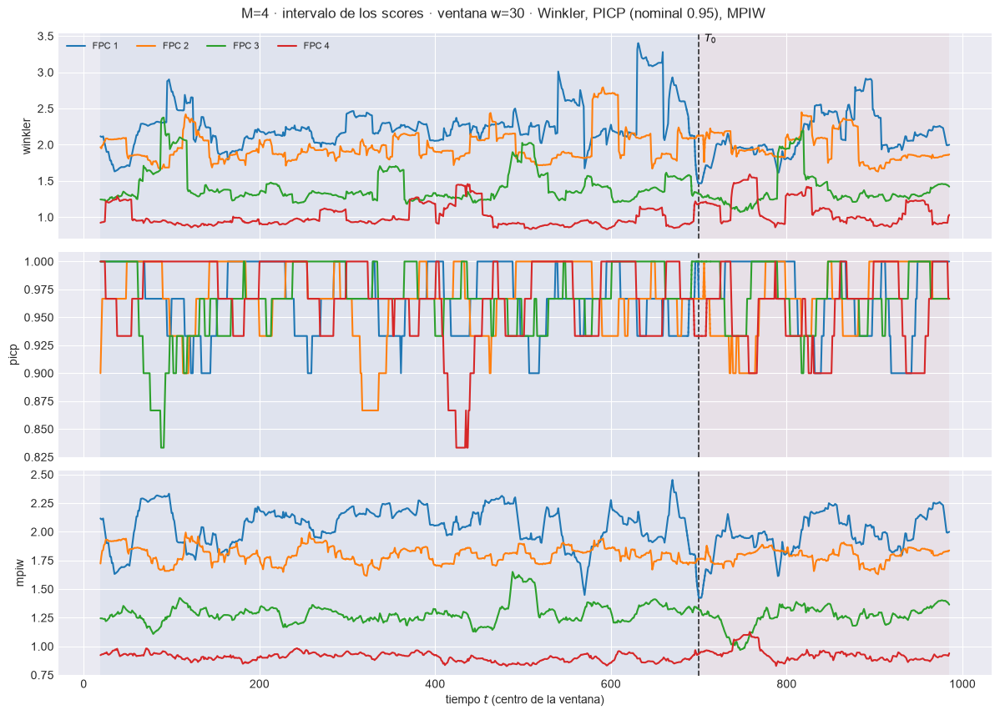

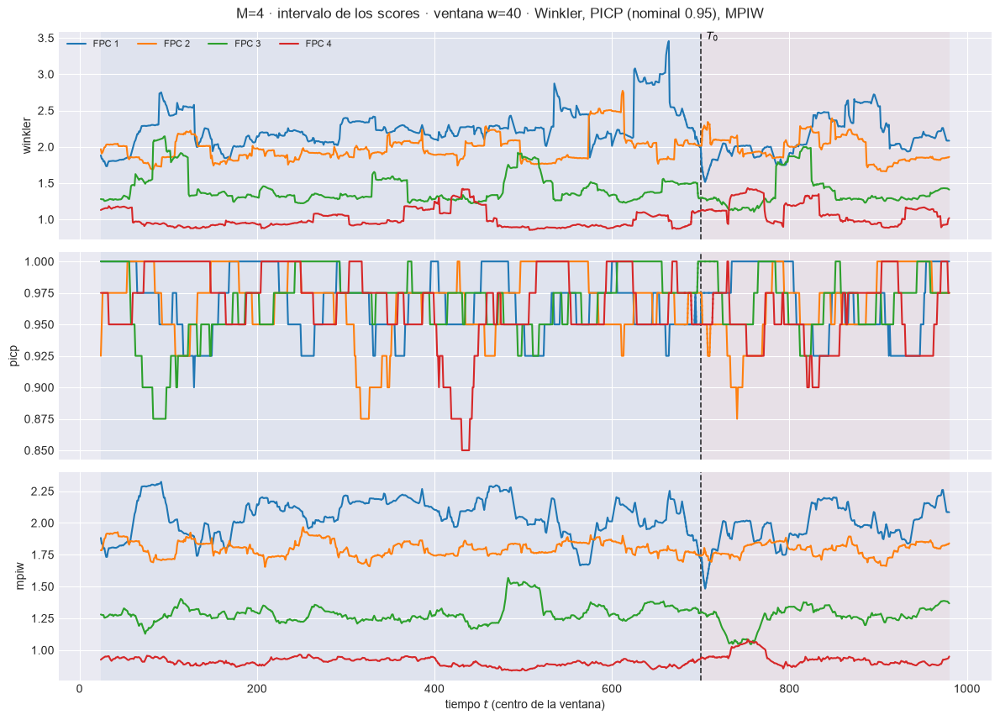

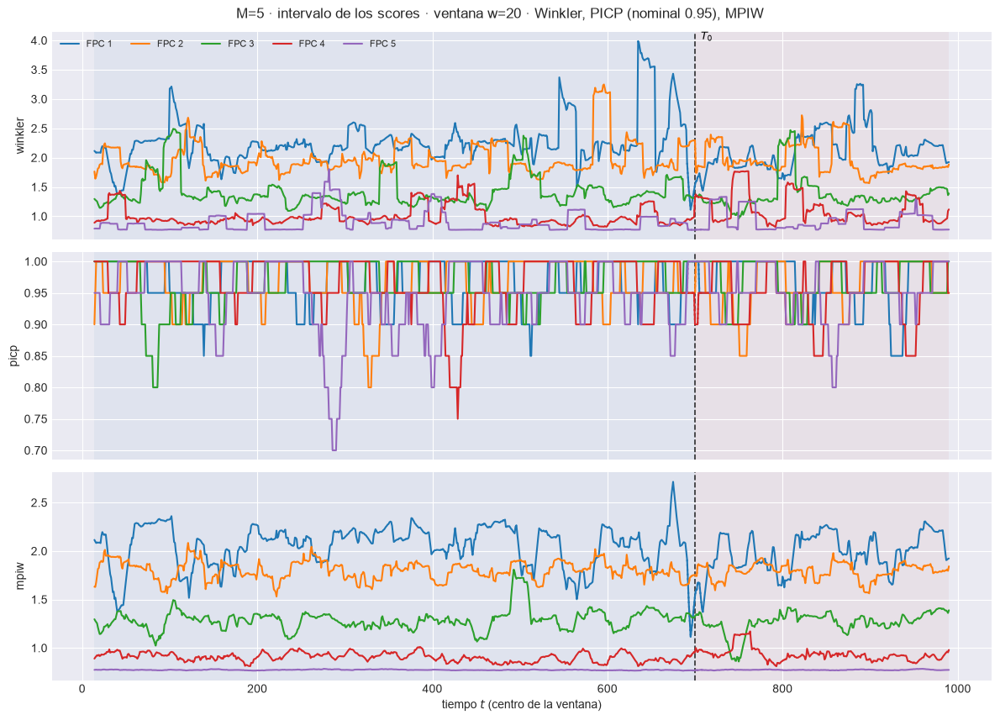

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  winkler: w=30 train=1.349  w=30 test=1.328


  2/3 (66.7%) t=0.1s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=1.28  w=30 test=1.274


[plot_ventana_movil] listo: 3 pasos en 0.8s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_m05\93_ventana_scores_intervalo_w30.png


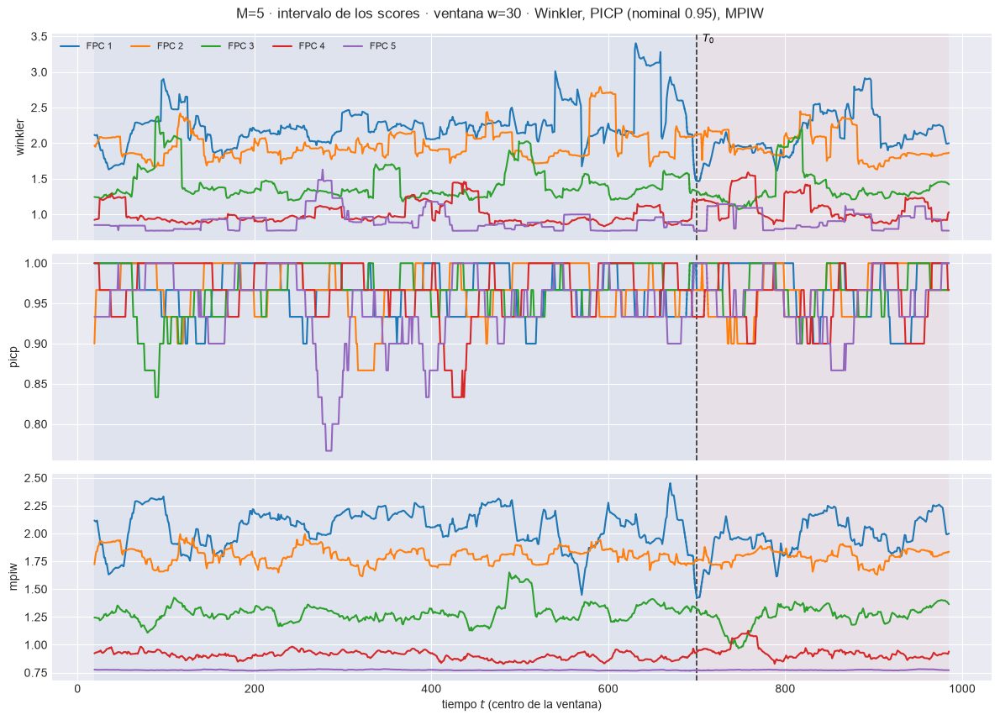

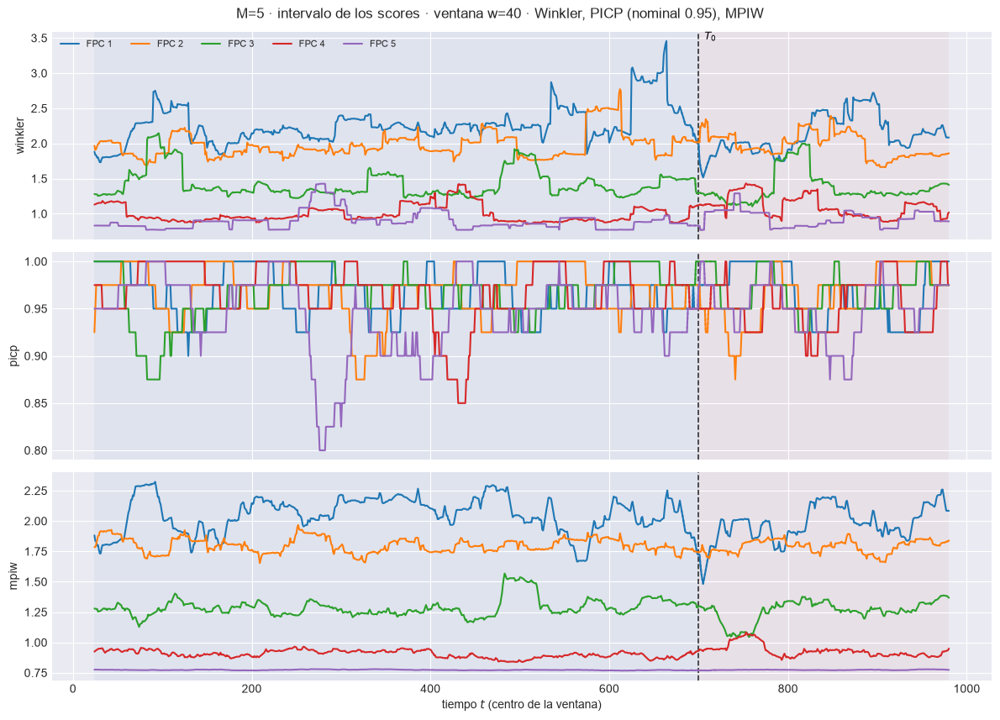

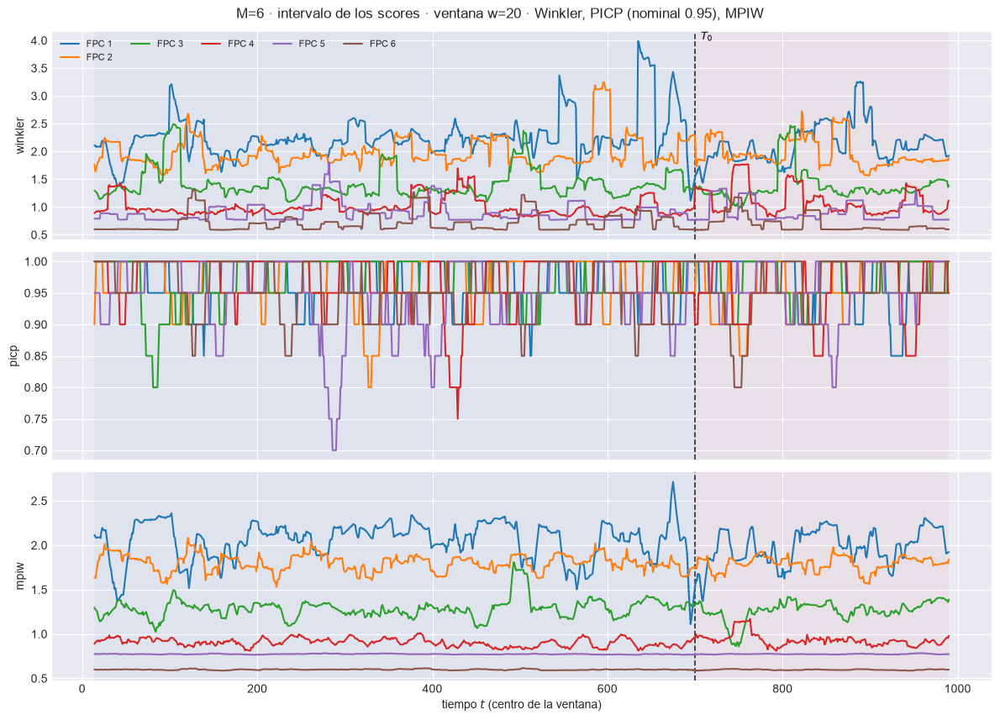

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  winkler: w=30 train=1.238  w=30 test=1.243


  2/3 (66.7%) t=0.1s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=1.046  w=30 test=1.068


[plot_ventana_movil] listo: 3 pasos en 0.9s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_m06\93_ventana_scores_intervalo_w30.png


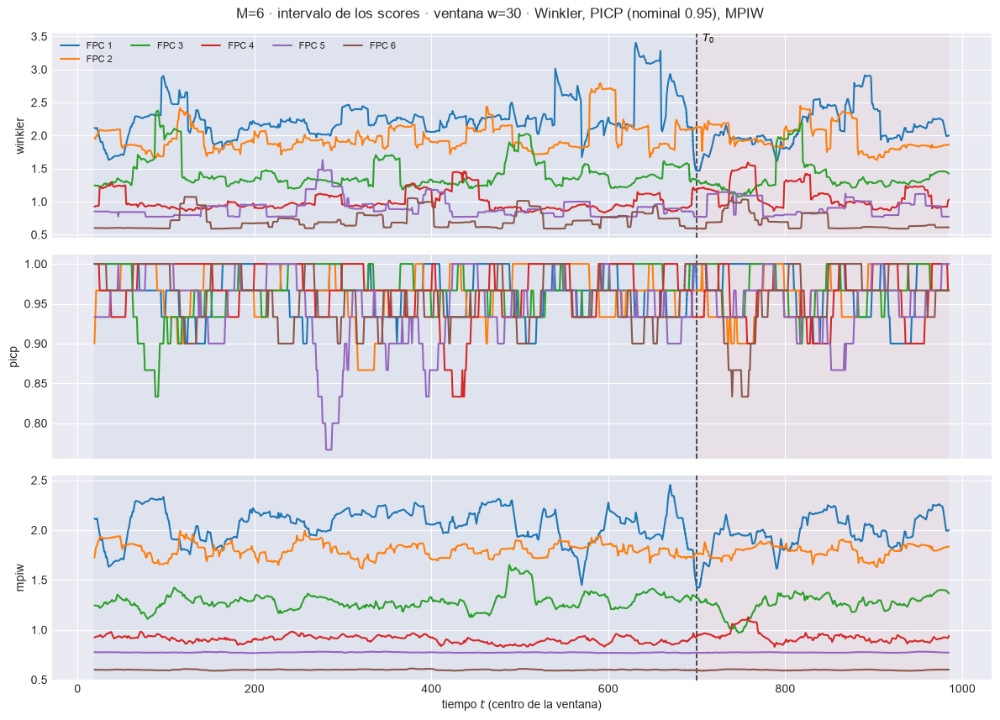

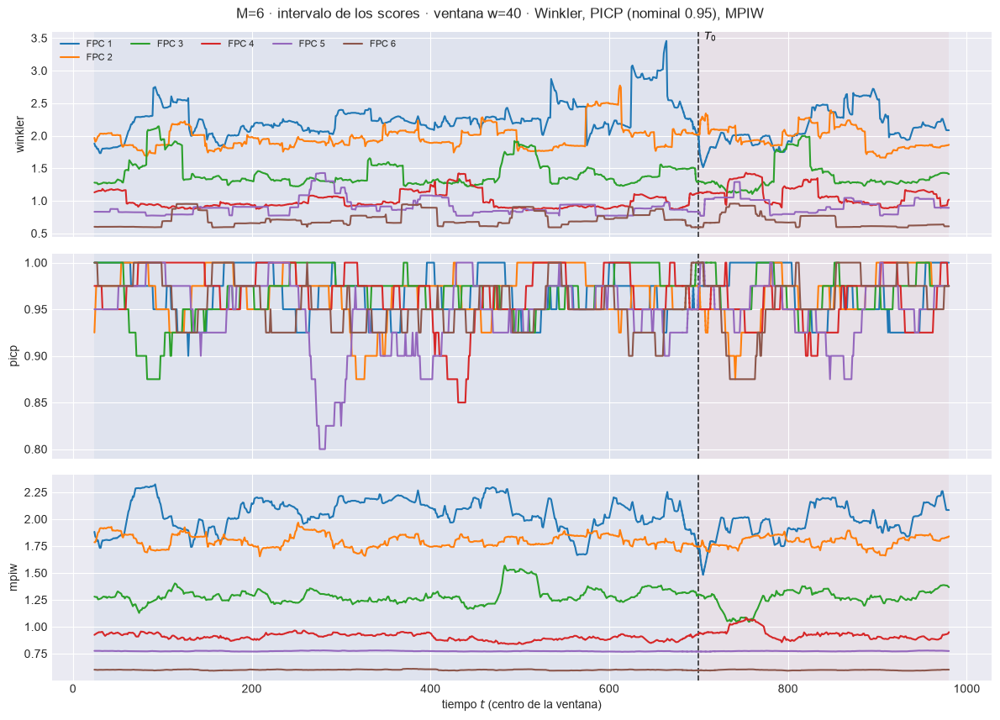

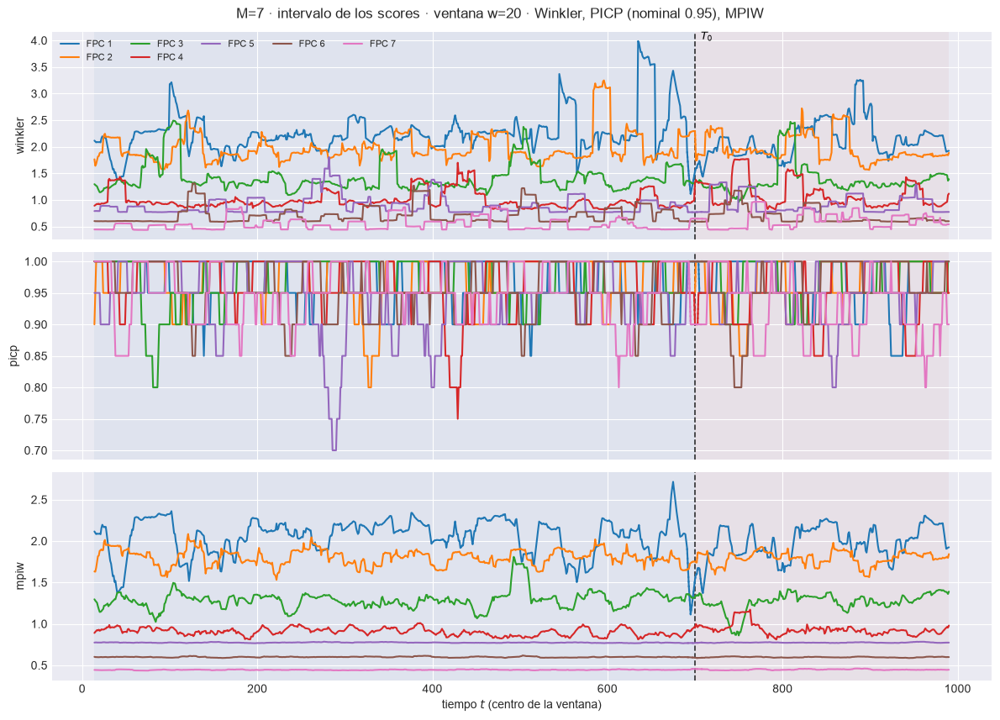

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  winkler: w=30 train=0.9946  w=30 test=1.115


  2/3 (66.7%) t=0.1s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=0.9058  w=30 test=0.9214


[plot_ventana_movil] listo: 3 pasos en 0.9s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_m07\93_ventana_scores_intervalo_w30.png


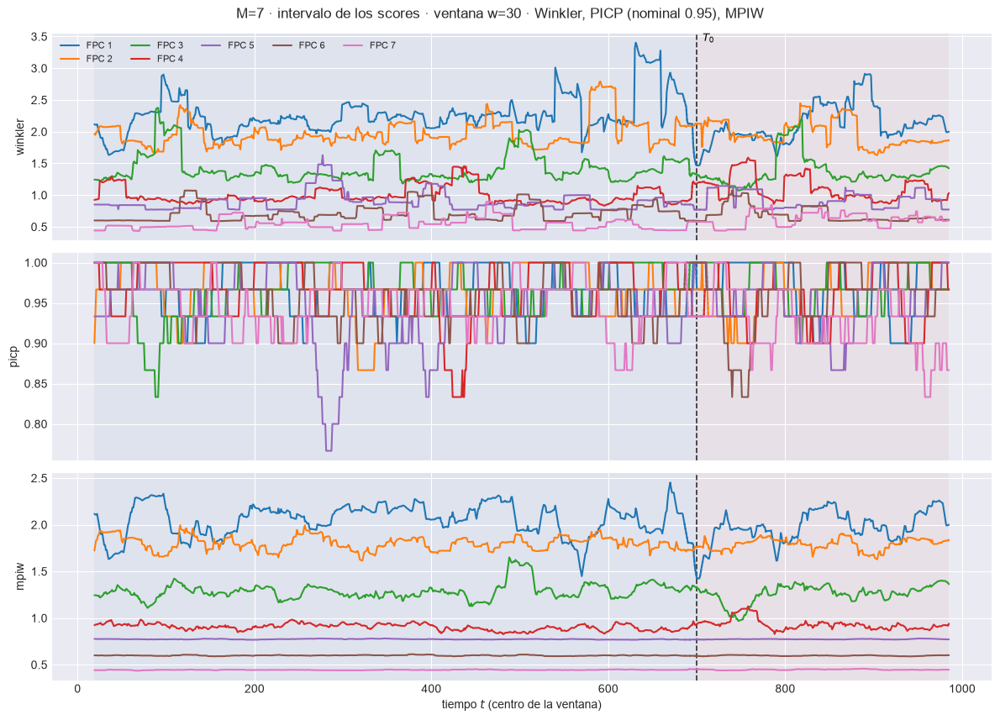

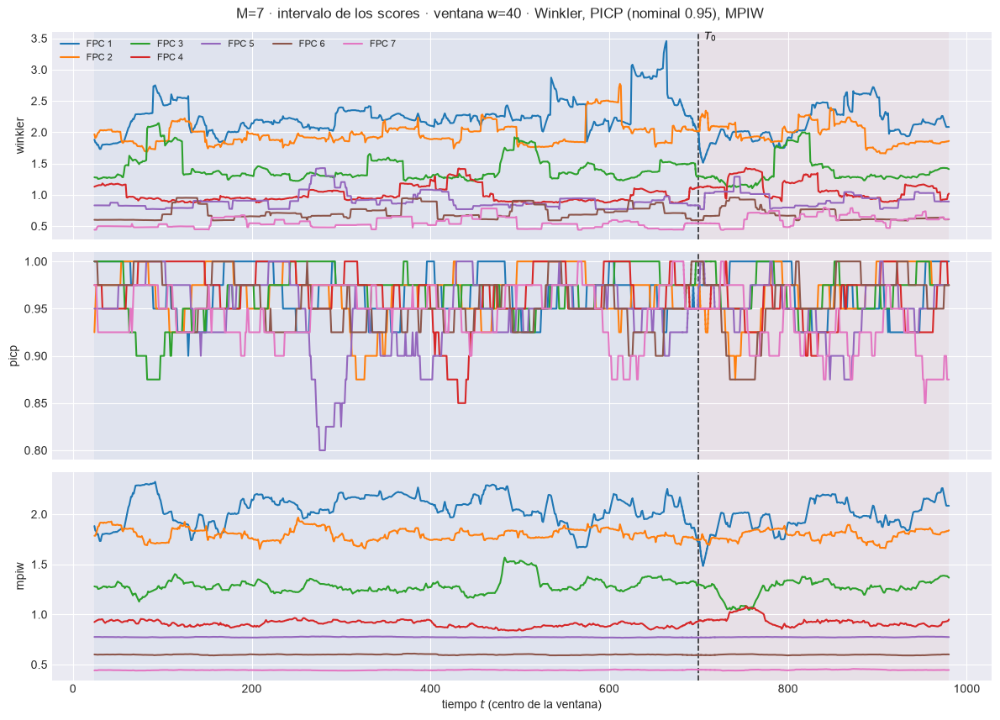

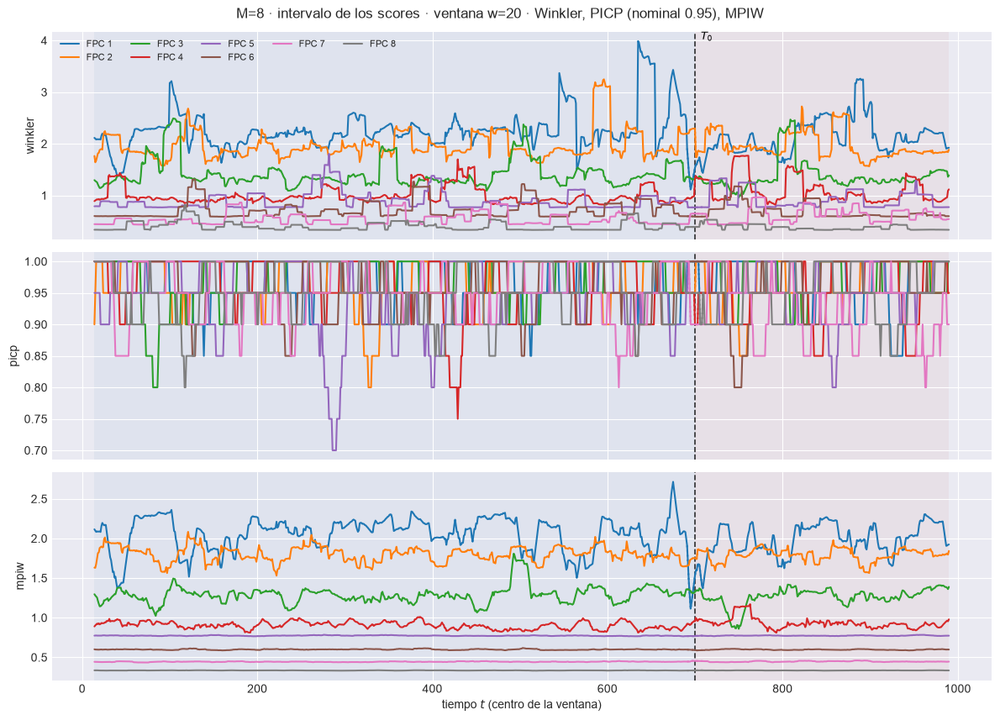

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  winkler: w=30 train=0.9308  w=30 test=0.9916


  2/3 (66.7%) t=0.1s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=0.8049  w=30 test=0.8054


[plot_ventana_movil] listo: 3 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_m08\93_ventana_scores_intervalo_w30.png


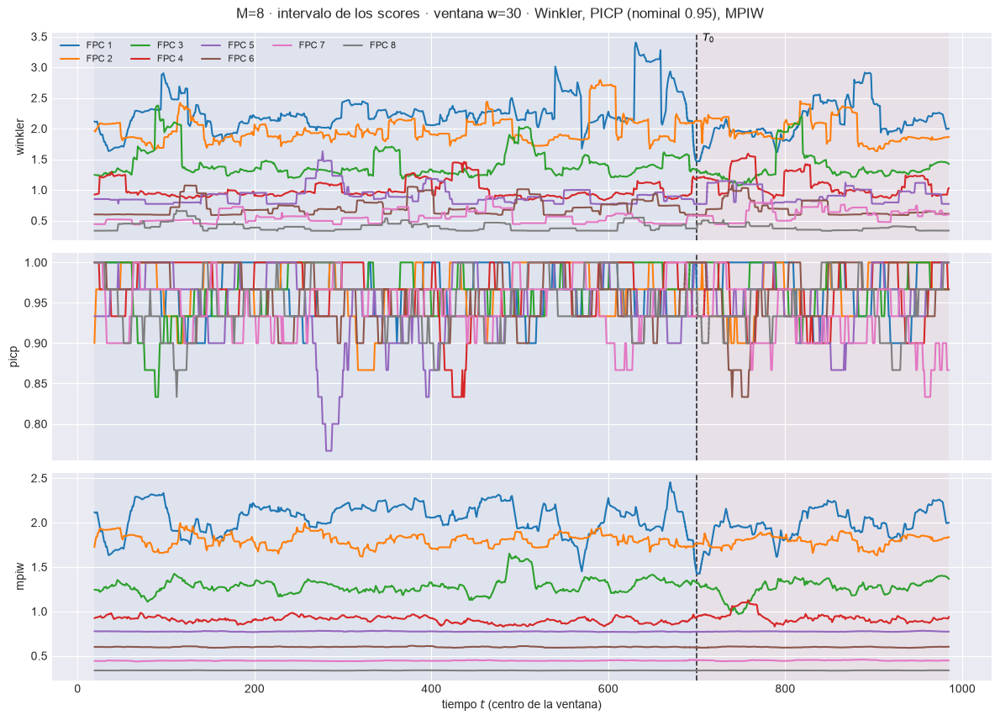

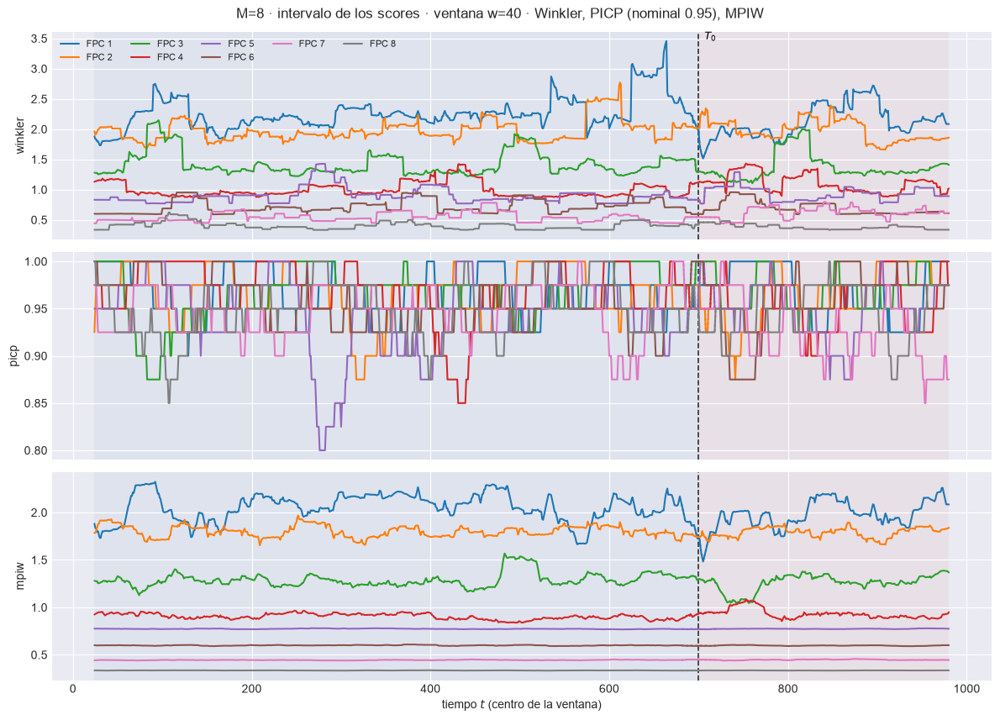

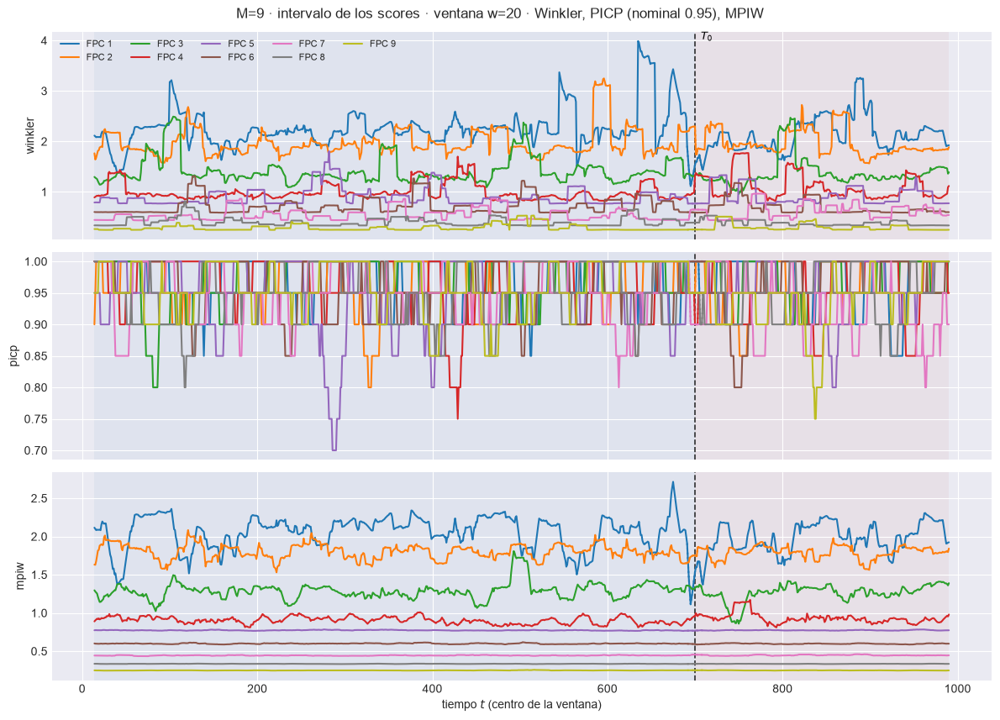

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  winkler: w=30 train=0.8763  w=30 test=0.9065


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=0.773  w=30 test=0.7734


[plot_ventana_movil] listo: 3 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_m09\93_ventana_scores_intervalo_w30.png


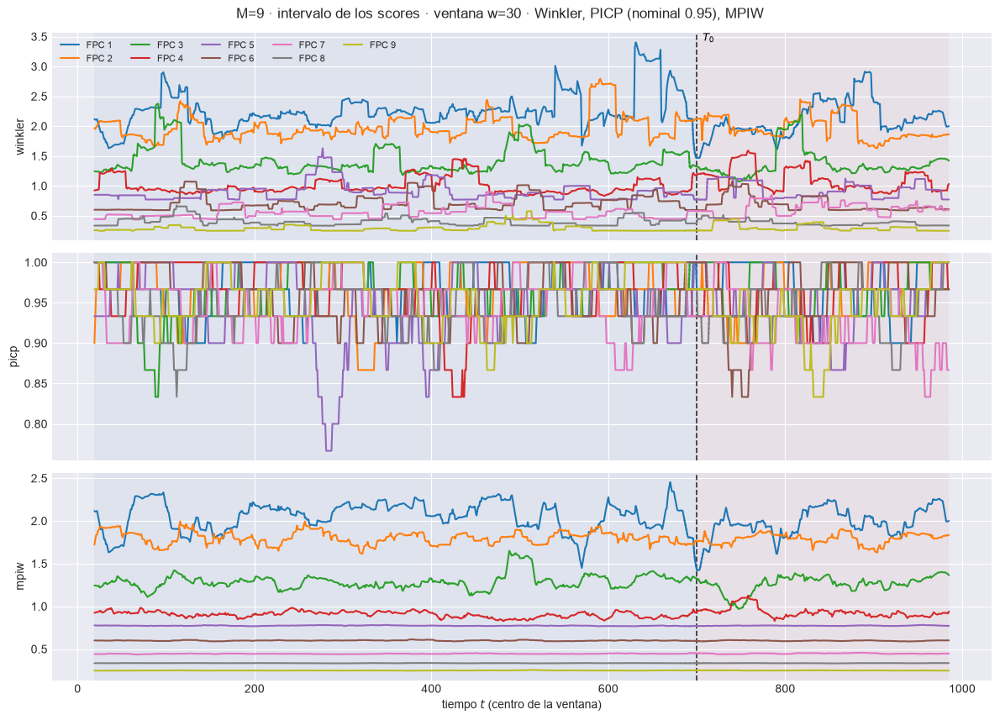

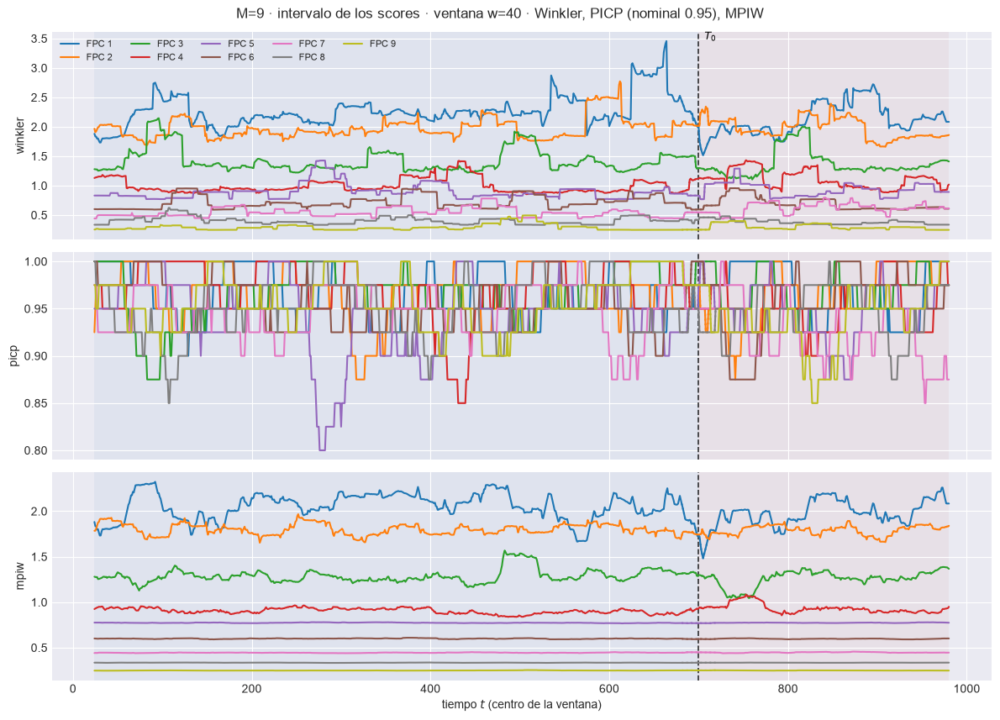

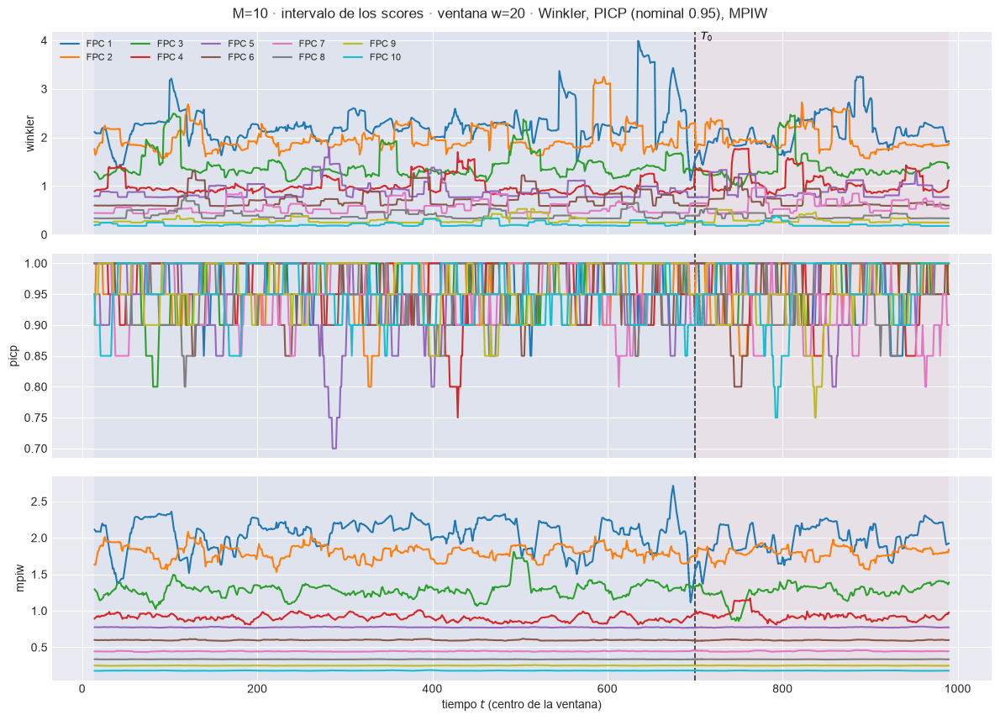

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  winkler: w=30 train=0.7781  w=30 test=0.802


  2/3 (66.7%) t=0.1s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=0.6898  w=30 test=0.6876


[plot_ventana_movil] listo: 3 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_m10\93_ventana_scores_intervalo_w30.png


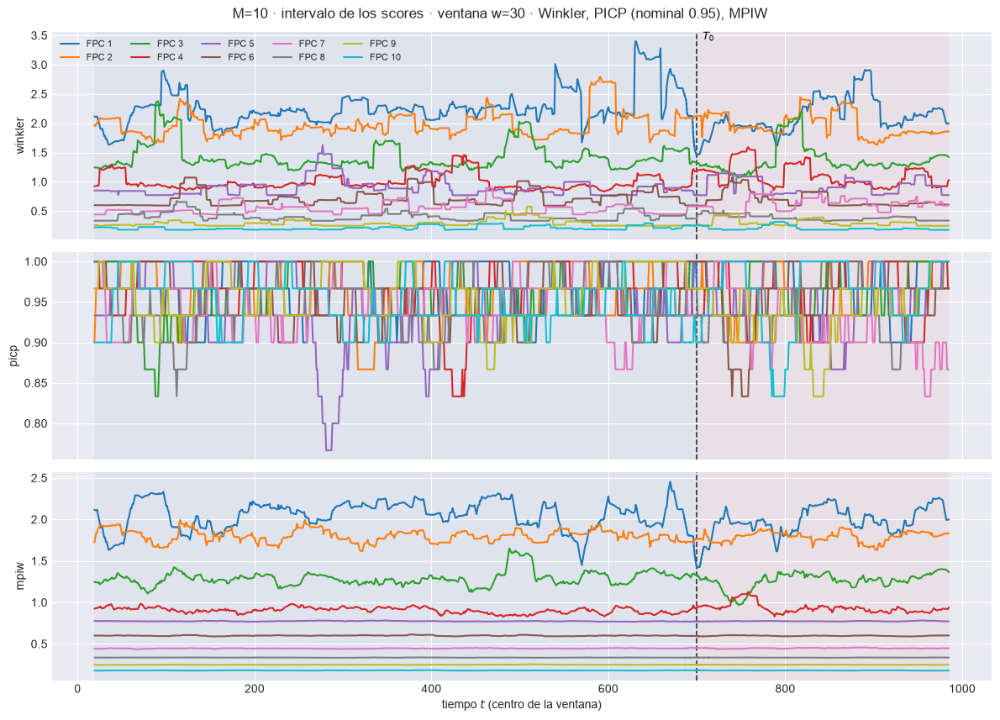

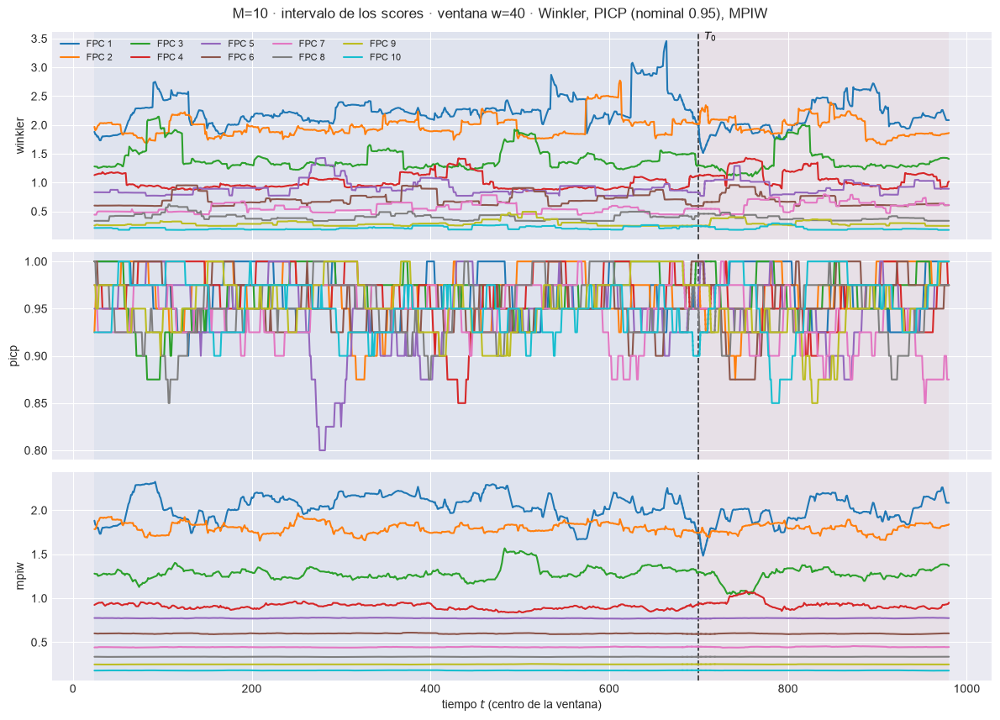

In [25]:
INT_SCORES = intervalos_scores(EST, M_OK, DIS, ORIG, PATH_BARRIDO)
display(INT_SCORES.set_index(["M", "componente", "bloque"]).style
        .format({"picp": "{:.4f}", "ace": "{:+.4f}", "mpiw": "{:.4f}", "winkler": "{:.4f}",
                 "sd_banda": "{:.4f}", "rmse": "{:.4f}", "mpiw_sobre_rmse": "{:.2f}"})
        .background_gradient(subset=["ace"], cmap="RdYlGn", vmin=-0.5, vmax=0.5)
        .set_caption(f"Intervalos de credibilidad de los scores, nivel {NIVEL:.0%} · ACE = PICP - nominal · "
                     "mpiw/rmse ≈ 3.92 si la banda fuera gaussiana y calibrada"))

# Evolución del intervalo sobre la ventana móvil, una figura por ancho.
for M in M_OK:
    for w in VENTANAS_W:
        plot_ventana_movil(
            EST[M]["tablas_score"][w], T0, ["winkler", "picp", "mpiw"], columna_grupo="componente",
            title=f"M={M} · intervalo de los scores · ventana w={w} · Winkler, PICP (nominal {NIVEL:.2f}), MPIW",
            save_path=str(EST[M]["paths"]["out_report"] / f"93_ventana_scores_intervalo_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

### 10.3 Dispersión $\hat\xi$ contra $\xi$

Un panel por componente con la diagonal; train y test con marcador distinto.

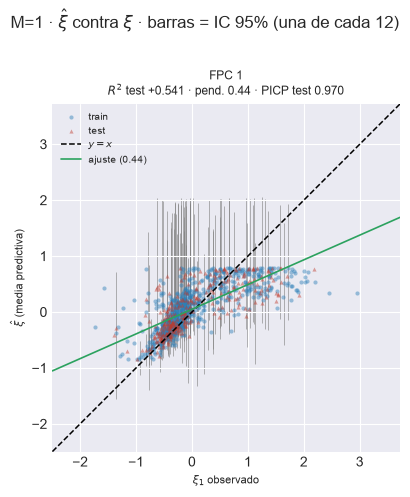

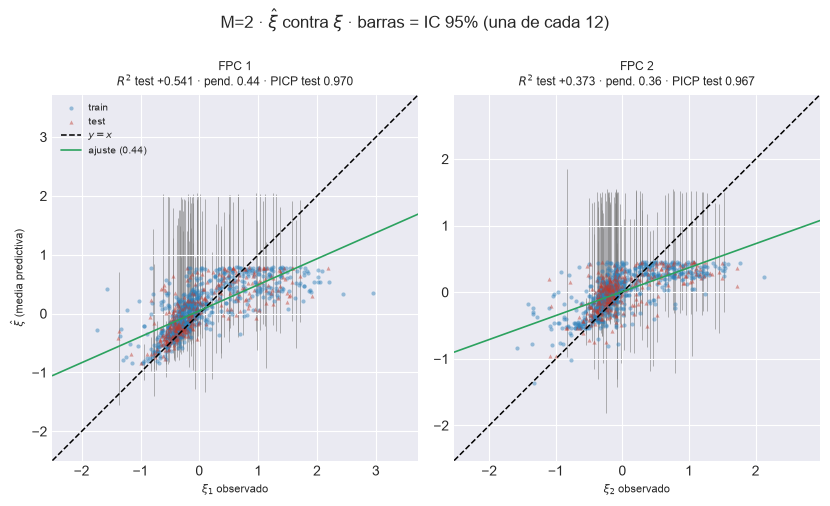

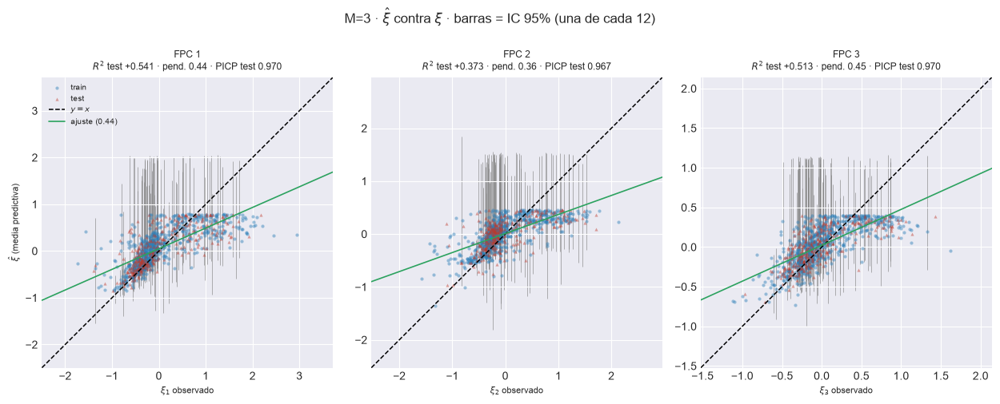

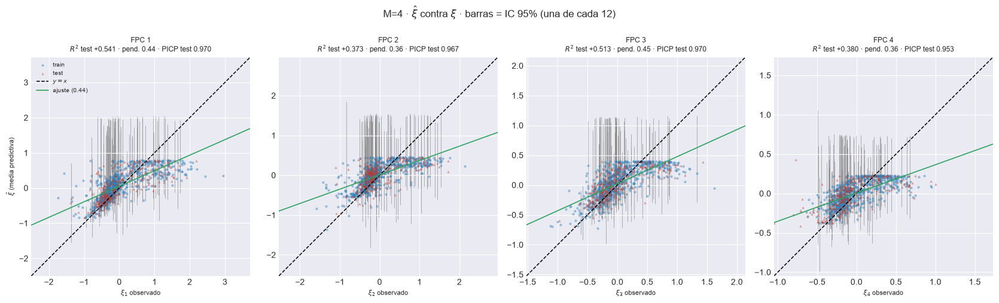

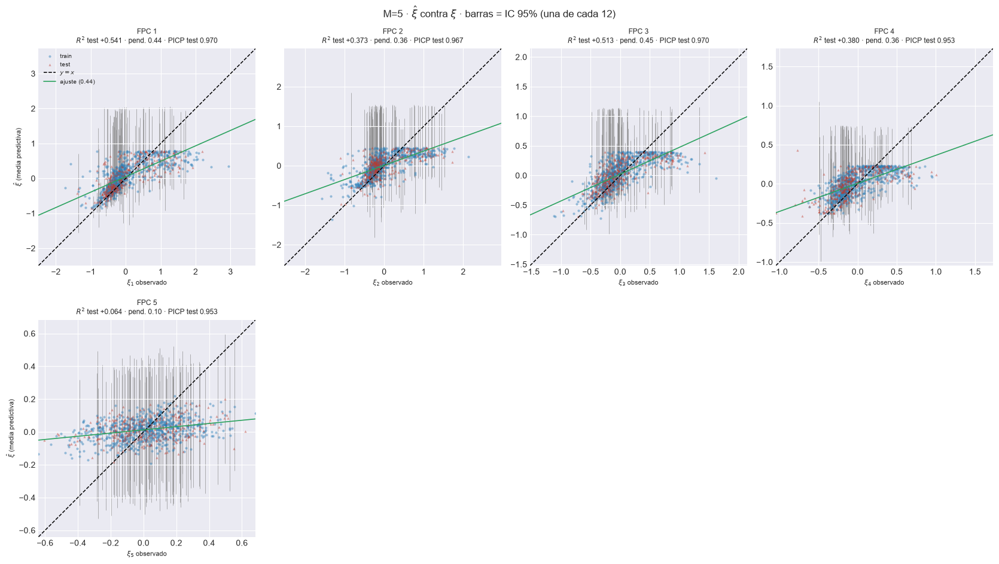

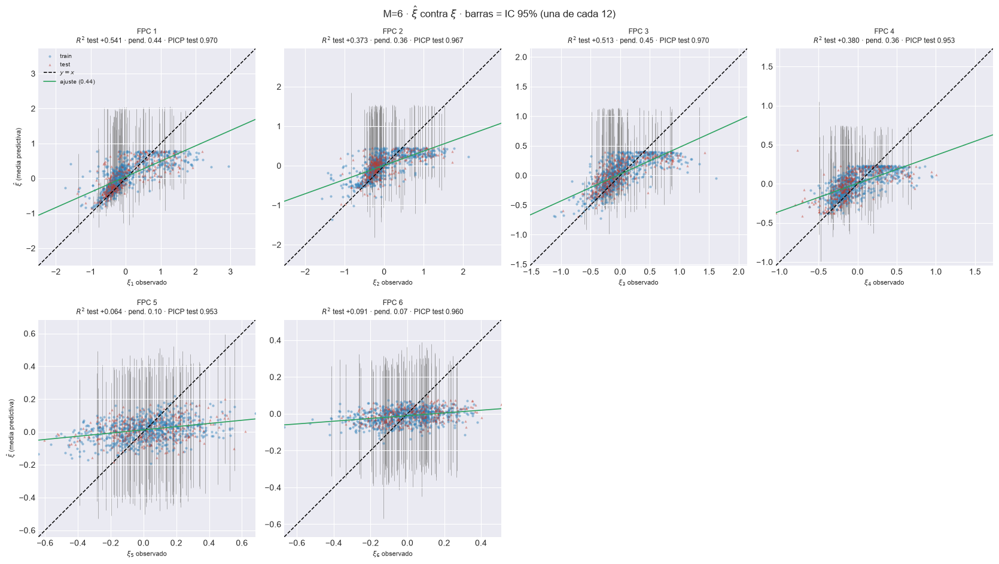

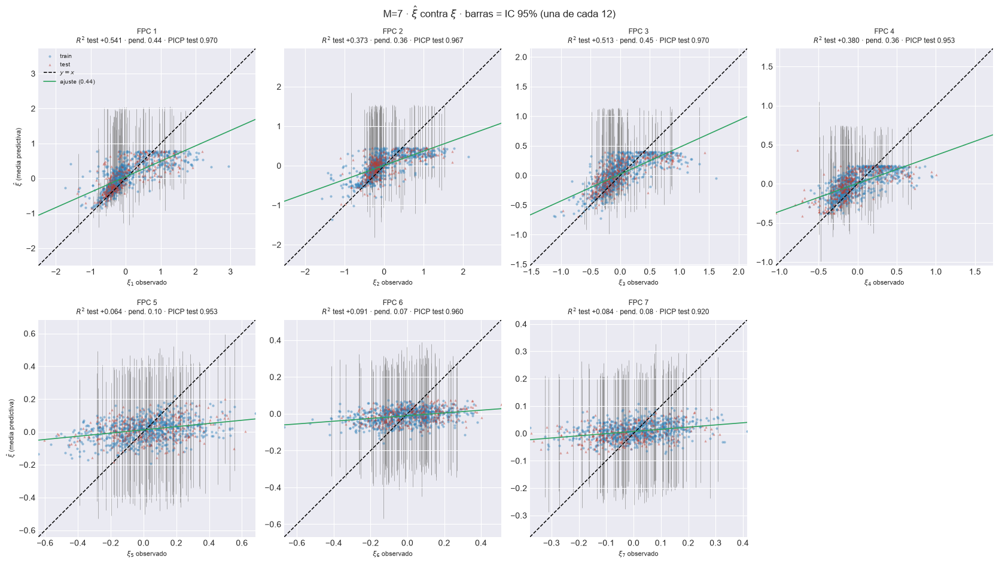

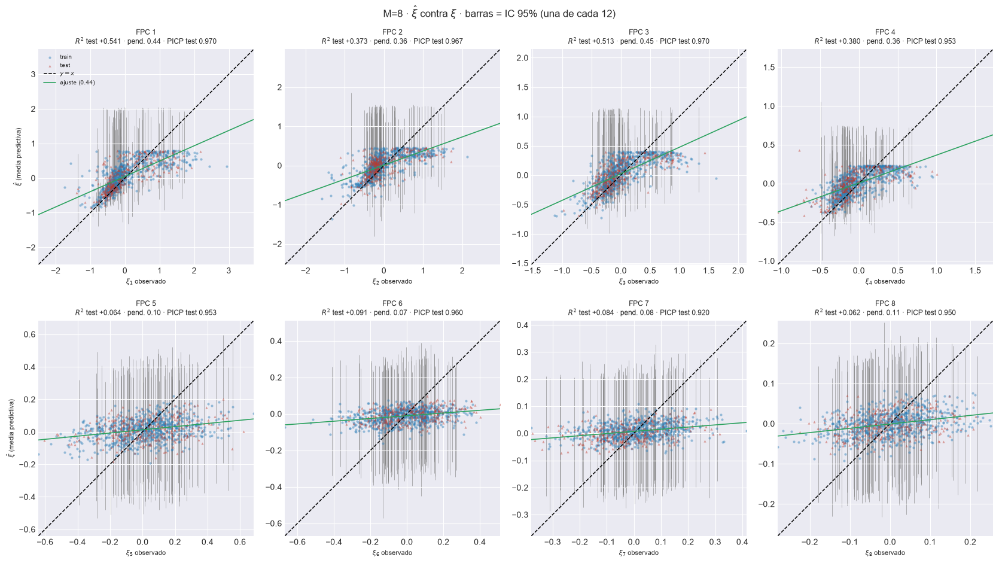

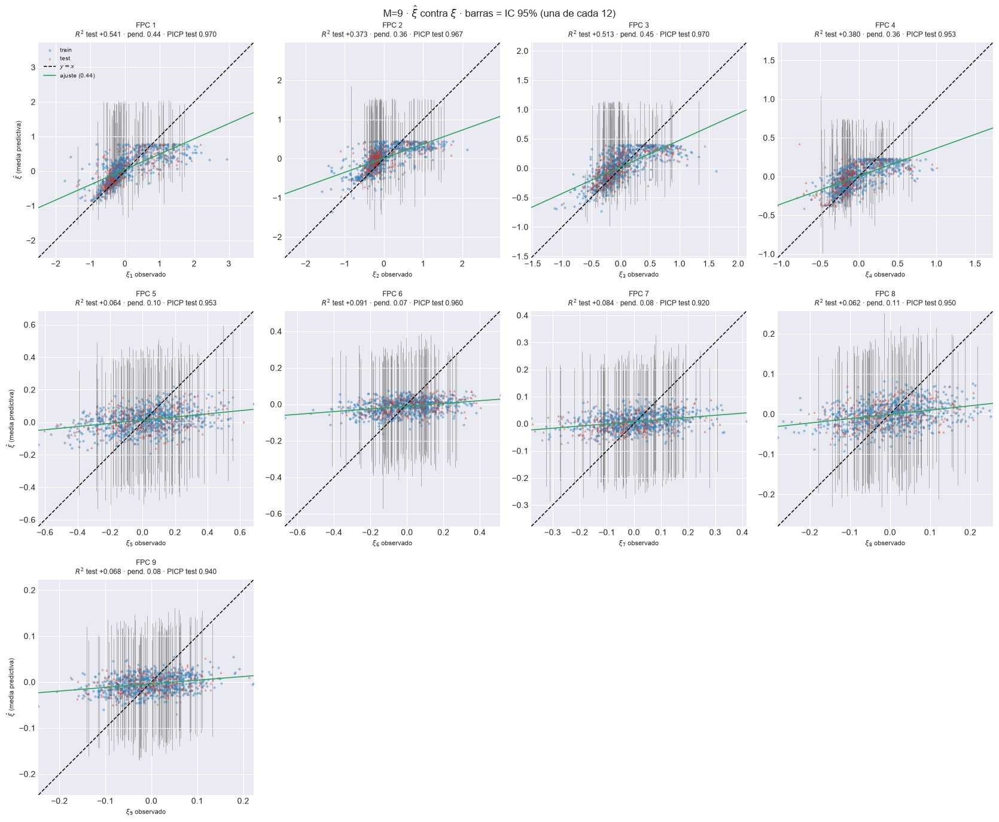

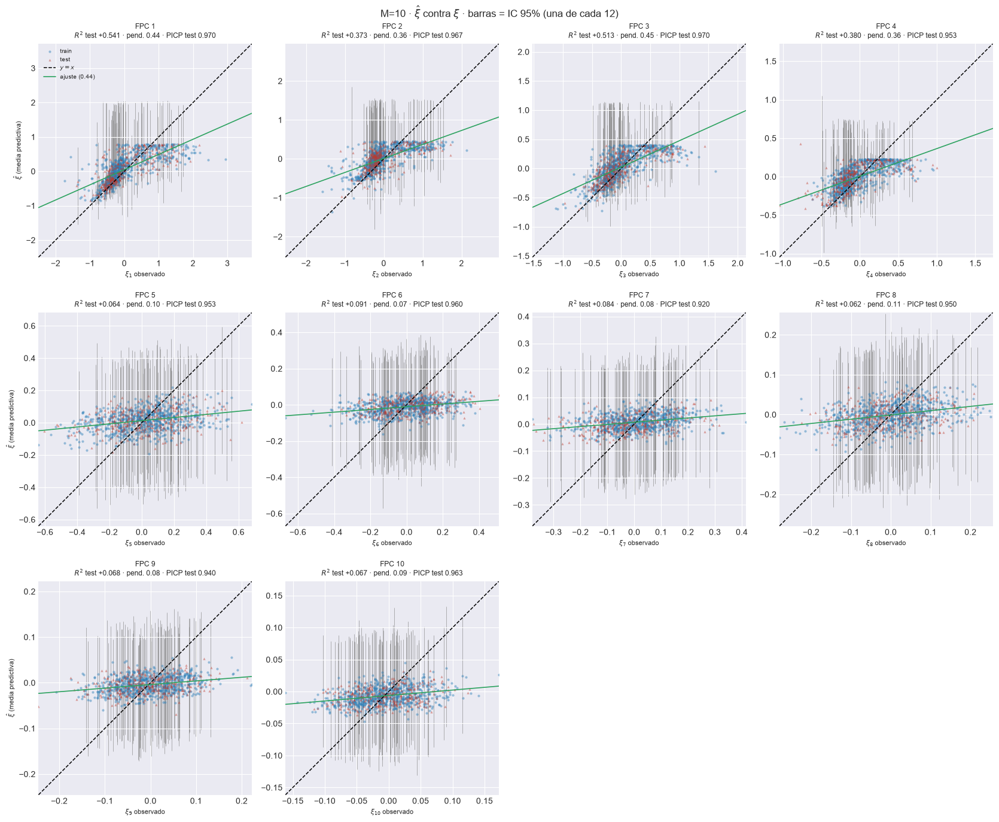

In [26]:
for M in M_OK:
    plot_scores_dispersion(EST[M], ORIG, DIS, M, CADA_BARRA,
                           save_path=EST[M]["paths"]["out_report"] / "94_scores_dispersion_vs_real.png")
    plt.show()

## 11. Diagnóstico de multimodalidad

En la ventana de detalle, como cuentas: por score, orígenes con $|\hat E - \mathrm{mediana}| > 0.25\,\hat s$; por origen, distancia de la mediana puntual a la extracción más cercana contra la de vecinas.

In [27]:
# Sobre los N_DETALLE orígenes de la ventana de detalle: cuentas k de N_DETALLE, descriptivas.
wn, MULTI = pesos_normalizados(grilla, PESOS_TAU), {}
for M in M_OK:
    e = EST[M]
    q16, q50, q84 = np.quantile(e["SC_draws"][:, IDX_DET], [0.16, 0.5, 0.84], axis=0)
    sep = np.abs(e["Y_hat"][IDX_DET] - q50) / np.maximum((q84 - q16) / 2.0, 1e-12)   # (N_DETALLE, M)
    por_score = pd.DataFrame({"componente": [f"FPC {c + 1}" for c in e["component_idx"]],
                              "n_origenes": N_DETALLE,
                              f"n_sep_gt_{UMBRAL_SEP}": (sep > UMBRAL_SEP).sum(axis=0),
                              "sep_mediana": np.median(sep, axis=0), "sep_max": sep.max(axis=0)})
    d = distancia_a_muestra_mas_cercana(curvas_draws(e, DIS, IDX_DET), e["X_PRED"]["mediana"][IDX_DET],
                                        grilla, PESOS_TAU, N_REF_NN, SEED_PRED)
    por_origen = pd.DataFrame({"t": T_DET, **d, "l1_esperanza_mediana":
                               np.abs(e["X_pred"][IDX_DET] - e["X_PRED"]["mediana"][IDX_DET]) @ wn,
                               "sep_max_score": sep.max(axis=1)})
    por_score.to_csv(e["paths"]["out_report"] / "60_multimodalidad_por_score.csv", index=False)
    por_origen.to_csv(e["paths"]["out_report"] / "61_distancia_mediana_muestra.csv", index=False)
    MULTI[M] = (por_score, por_origen)
multi_bar = pd.concat([MULTI[M][0].assign(M=M, t0_detalle=T0_DET) for M in M_OK], ignore_index=True)
multi_bar.to_csv(PATH_BARRIDO / "100_multimodalidad_por_M.csv", index=False)

display(multi_bar.pivot(index="componente", columns="M", values=f"n_sep_gt_{UMBRAL_SEP}")
        .reindex([f"FPC {k}" for k in range(1, max(M_OK) + 1)])
        .style.format("{:.0f}", na_rep="-").background_gradient(cmap="Reds", vmin=0, vmax=N_DETALLE, axis=None)
        .set_caption(f"Ventana de detalle (t={T0_DET}..): orígenes, de {N_DETALLE}, con "
                     f"|esperanza − mediana| > {UMBRAL_SEP} sd robusta, por score (descriptivo)"))
display(pd.DataFrame({M: MULTI[M][1].set_index("t")["razon"] for M in M_OK}).style.format("{:.2f}")
        .set_caption("Ventana de detalle · razón d(mediana, extracción más cercana) / d típica, por origen"))

M,1,2,3,4,5,6,7,8,9,10
componente,,,,,,,,,,
FPC 1,7,7,7,7,7,7,7,7,7,7
FPC 2,-,7,7,7,7,7,7,7,7,7
FPC 3,-,-,6,6,6,6,6,6,6,6
FPC 4,-,-,-,4,4,4,4,4,4,4
FPC 5,-,-,-,-,0,0,0,0,0,0
FPC 6,-,-,-,-,-,0,0,0,0,0
FPC 7,-,-,-,-,-,-,0,0,0,0
FPC 8,-,-,-,-,-,-,-,0,0,0
FPC 9,-,-,-,-,-,-,-,-,0,0


,1,2,3,4,5,6,7,8,9,10
t,,,,,,,,,,
807,1.87,1.28,0.74,0.74,0.63,0.61,0.65,0.60,0.67,0.64
808,0.14,4.33,1.82,1.27,0.92,0.98,0.93,0.91,0.88,0.89
809,0.27,0.77,0.41,0.56,0.47,1.02,0.91,0.87,0.87,0.86
810,0.29,1.94,0.90,1.03,0.74,0.83,0.82,0.86,0.80,0.78
811,0.17,1.63,0.96,0.64,0.40,0.37,0.67,0.80,0.76,0.72
812,0.52,2.22,0.91,0.71,0.80,0.84,0.90,0.81,0.75,0.78
813,1.54,1.58,0.96,1.28,0.91,0.80,0.81,0.79,0.80,0.80
814,1.74,2.87,0.93,1.00,1.16,1.00,0.98,0.97,1.04,0.99
815,0.62,2.97,1.54,0.75,0.70,0.97,0.89,0.84,0.77,0.74


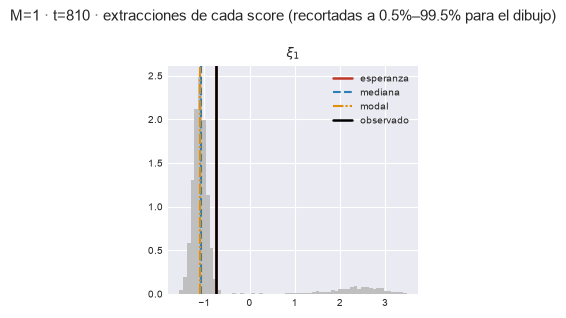

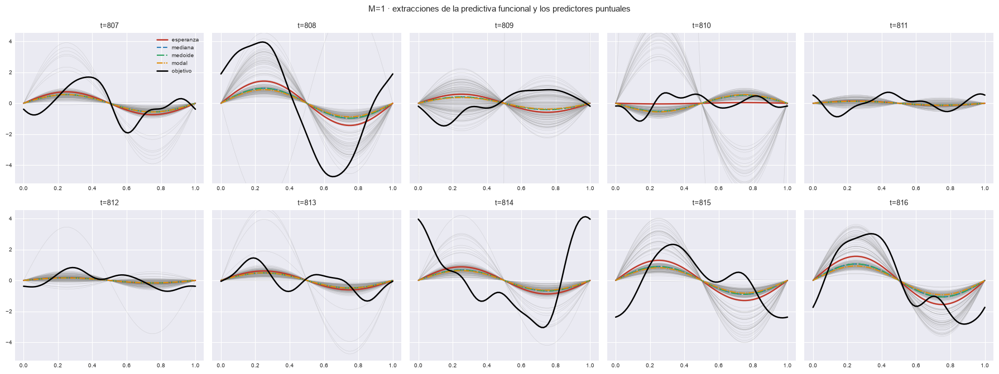

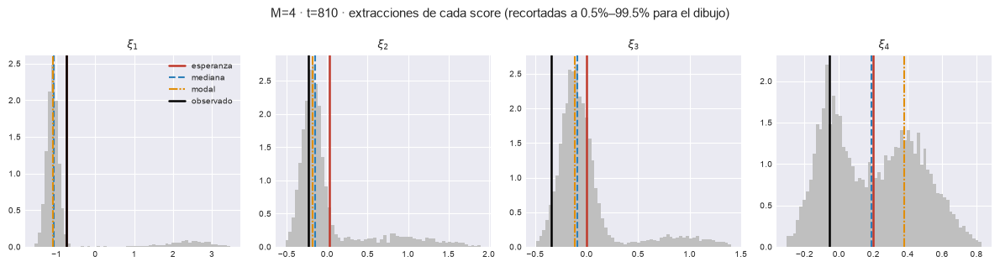

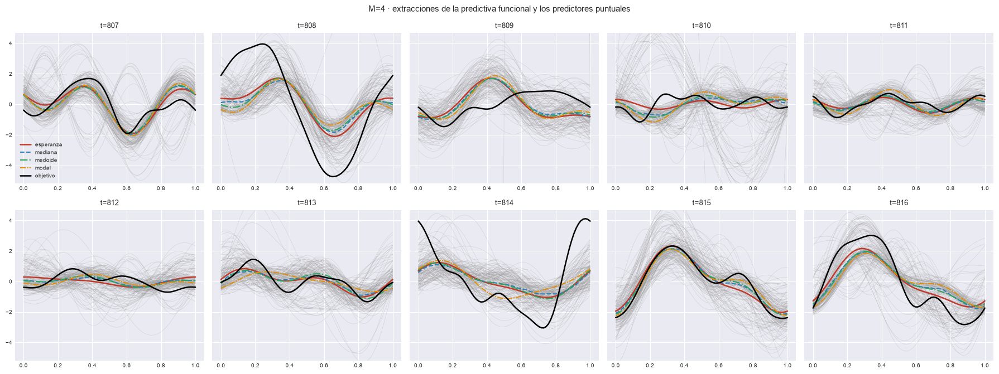

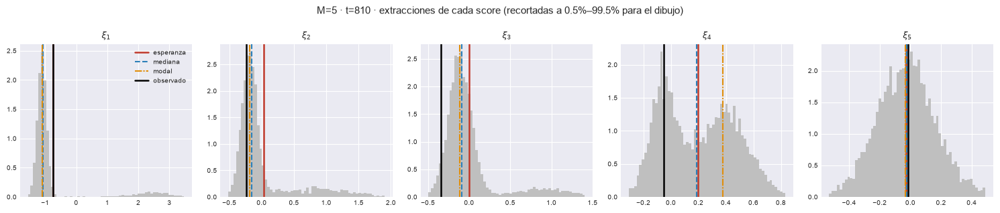

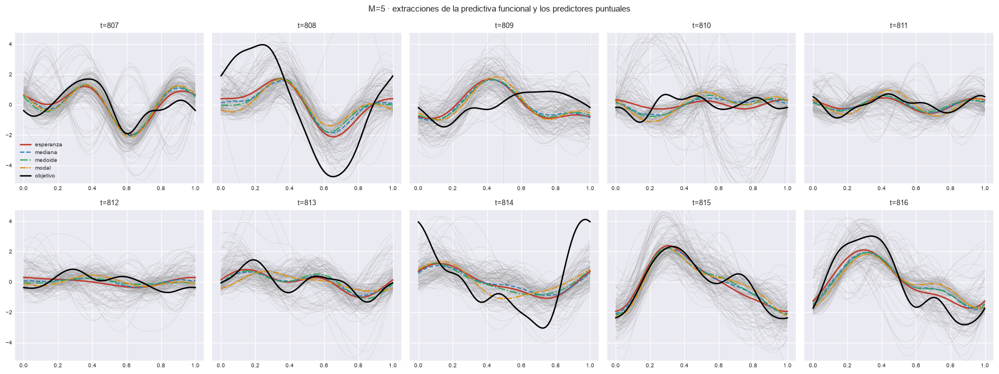

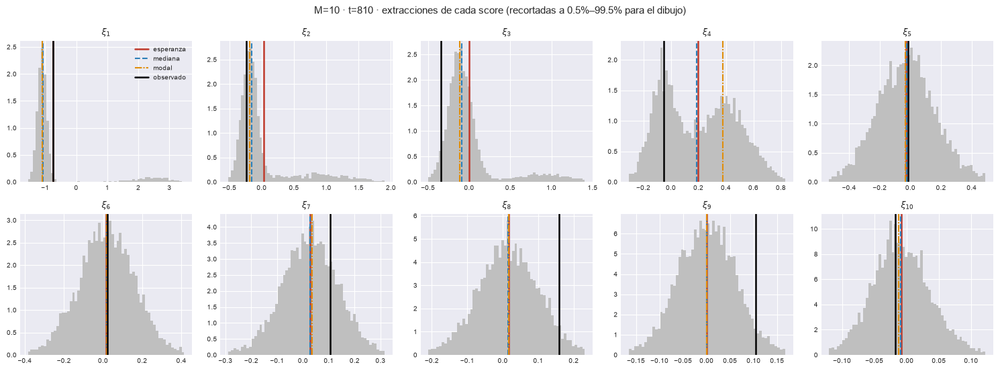

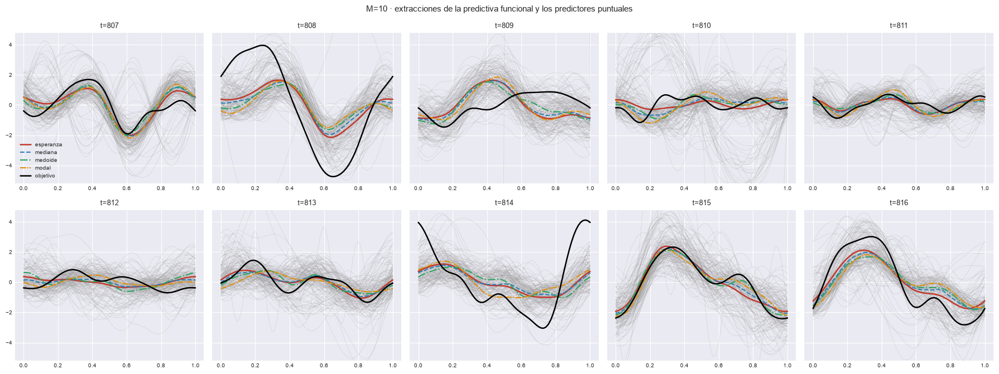

In [28]:
# El origen más multimodal de la ventana: extracciones por score; los N_DETALLE: curvas y predictores.
for M in (m for m in M_DETALLE if m in M_OK):
    e, po = EST[M], MULTI[M][1]
    i_mm = int(IDX_DET[int(np.argmax(po["sep_max_score"].to_numpy()))])
    marcas = {"esperanza": e["Y_hat"], "mediana": np.median(e["SC_draws"], axis=0),
              "modal": e["Y_mod"], "observado": e["Y_obs"]}
    plot_histogramas_draws(e["SC_draws"], i_mm, marcas, int(t_orig[i_mm]), M,
                           save_path=e["paths"]["out_report"] / f"61_histogramas_draws_t{int(t_orig[i_mm])}.png")
    plt.show()
    plot_curvas_predictores(curvas_draws(e, DIS, IDX_DET), {p: e["X_PRED"][p][IDX_DET] for p in PREDICTORES},
                            X_obj_ev[IDX_DET], grilla, T_DET, M, ncols=5,
                            save_path=e["paths"]["out_report"] / "61b_curvas_predictores.png")
    plt.show()

## 12. Comportamientos predictivos

k-medias sobre las extracciones de scores por origen; $K$ con las reglas de docs §03_06_02 (valle, crecimiento, masa); con $a_\tau \le 1$ se recortan los draws al 0.5–99.5 %. §12.1 sobre toda la serie; §12.2–§12.5 sobre la ventana de detalle. Se persiste en `comportamientos_psbp.npz`.

### 12.1 Número de comportamientos por origen

    comportamientos: 250/996 origenes


    comportamientos: 500/996 origenes


    comportamientos: 750/996 origenes


M= 1: K en test  K=1: 68.7%  K=2: 31.3%   (recorte si, 48 s)


    comportamientos: 250/996 origenes


...

    comportamientos: 500/996 origenes


    comportamientos: 750/996 origenes


M=10: K en test  K=1: 70.0%  K=2: 16.7%  K=3: 13.0%  K=4: 0.3%   (recorte si, 70 s)


M,1,2,3,4,5,6,7,8,9,10
K,,,,,,,,,,
1,61.6%,61.1%,60.5%,60.3%,60.5%,60.3%,60.3%,60.2%,60.5%,60.6%
2,38.4%,27.2%,27.3%,27.4%,27.3%,27.4%,27.6%,27.6%,27.6%,27.4%
3,0.0%,11.8%,12.2%,12.2%,12.2%,12.2%,12.1%,12.1%,11.9%,11.9%
4,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.1%,0.0%,0.0%
5,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
6,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%


M,1,2,3,4,5,6,7,8,9,10
K,,,,,,,,,,
1,68.7%,70.0%,69.7%,69.3%,69.7%,70.3%,69.7%,69.7%,70.0%,70.0%
2,31.3%,15.7%,15.7%,16.7%,16.7%,16.3%,16.7%,16.7%,16.7%,16.7%
3,0.0%,14.3%,14.3%,13.7%,13.3%,13.0%,13.3%,13.3%,13.3%,13.0%
4,0.0%,0.0%,0.3%,0.3%,0.3%,0.3%,0.3%,0.3%,0.0%,0.3%
5,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
6,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%


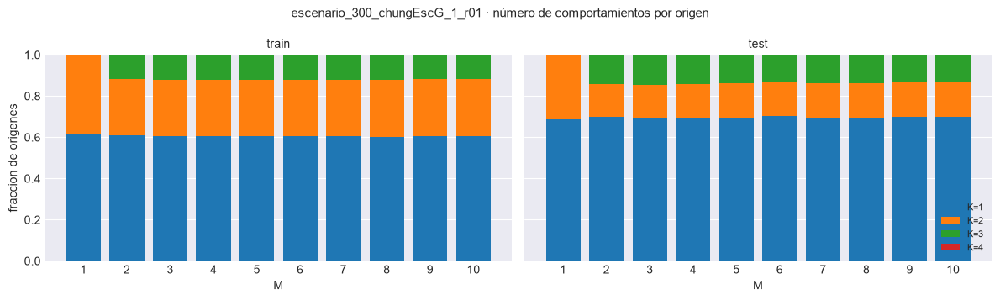

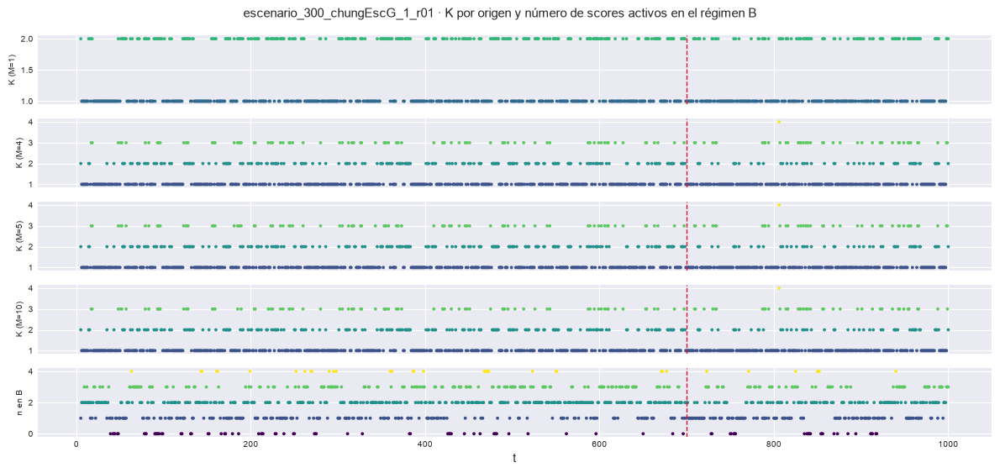

In [29]:
K_BAR = comportamientos_barrido(EST, M_OK, DIS, ORIG, PATH_BARRIDO, solo_test=COMP_SOLO_TEST)
for b in ("train", "test"):
    display(K_BAR[K_BAR.bloque == b].pivot(index="K", columns="M", values="frac")
            .style.format("{:.1%}").set_caption(f"Fracción de orígenes {b.upper()} con K comportamientos (102_K_por_M.csv)"))
plot_K_barrido(K_BAR, f"{EXPERIMENT_BASE} · número de comportamientos por origen", PATH_BARRIDO / "102_K_por_M.png")
plt.show()

esc   = cargar_escenario(str(EST[M_OK[0]]["paths"]["raw"] / f"escenario_{ESCENARIO_ID}.npz"))
A_ACT = esc["interno_parametros"].shape[0]                          # scores activos del TAR
REG_T = esc["interno_regimen"][REPLICA_ID - 1][t_orig - 1, :A_ACT]  # régimen verdadero (B = 1)
plot_K_serie({M: EST[M]["COMP"]["K"] for M in M_DETALLE if M in M_OK}, t_orig, T0, n_B=REG_T.sum(axis=1),
             titulo=f"{EXPERIMENT_BASE} · K por origen y número de scores activos en el régimen B",
             save_path=PATH_BARRIDO / "102b_K_serie.png")
plt.show()

### 12.2 Ventana de detalle: curvas típicas, bandas condicionales y tramos de la HDR

Grilla `63_comportamientos_ejemplos.png` y una figura por origen `63_detalle_t<t>.png`.

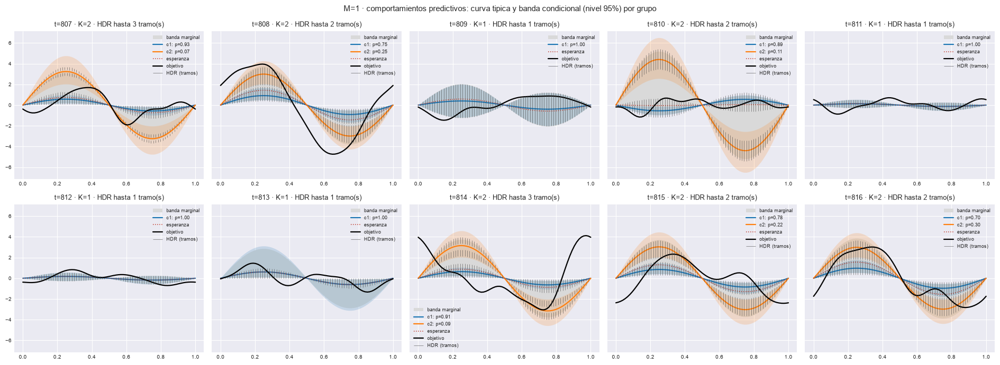

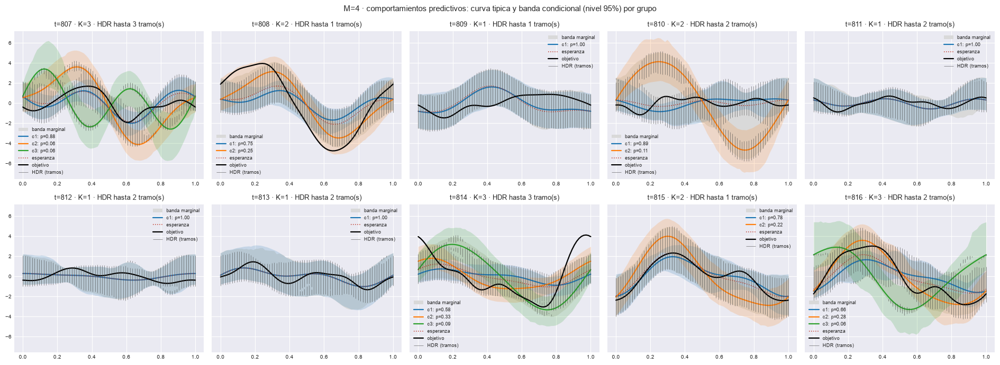

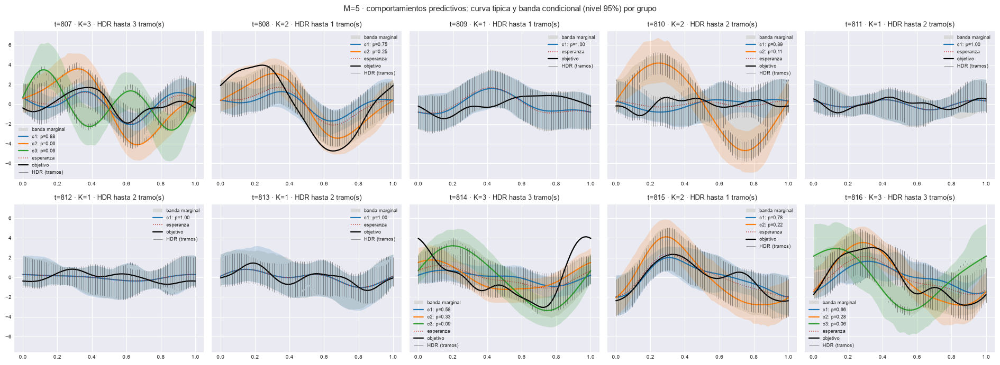

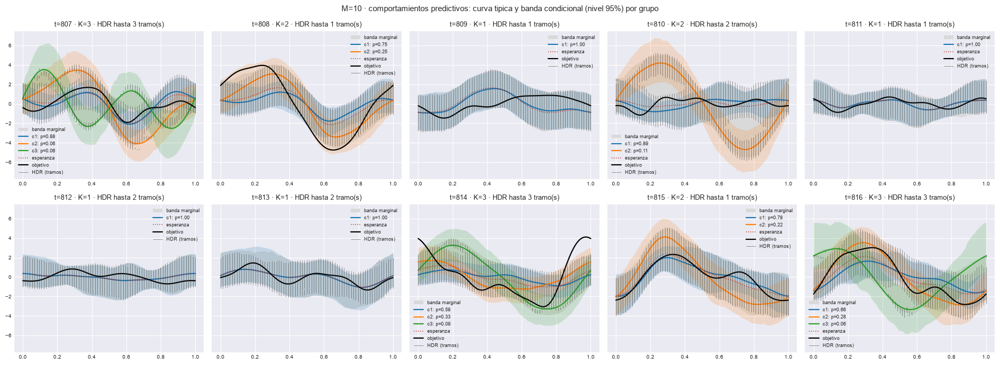

In [30]:
ESTILO_INT = {"equicolas": "#2c7fb8", "simultanea": "#8856a7", "hdr": "#2ca25f"}


def figura_origen(e, i, M, save_path):
    # Un origen: objetivo, los predictores, equi-colas, simultánea, tramos de la HDR y curvas típicas.
    C, (Ls, Us), (Lh, Uh) = e["COMP"], e["INTERVALOS"]["simultanea"], e["INTERVALOS"]["hdr"]
    fig, ax = plt.subplots(figsize=(8.6, 4.6))
    ax.fill_between(grilla, Ls[i, :, 0], Us[i, :, 0], color=ESTILO_INT["simultanea"], alpha=0.12, lw=0,
                    label="banda simultánea")
    ax.fill_between(grilla, e["li_f"][i], e["ls_f"][i], color=ESTILO_INT["equicolas"], alpha=0.22, lw=0,
                    label="equi-colas")
    for k in range(Lh.shape[2]):
        ok = np.isfinite(Lh[i, :, k])
        ax.vlines(grilla[ok], Lh[i, ok, k], Uh[i, ok, k], color=ESTILO_INT["hdr"], lw=1.1, alpha=0.75,
                  label="HDR (tramos)" if k == 0 else None)
    for c in range(int(C["K"][i])):
        ax.plot(grilla, C["curvas"][i, c], color="0.3", lw=0.8 + 2.4 * C["masas"][i, c], ls=(0, (4, 2)),
                label=f"comportamiento {c + 1}: p = {C['masas'][i, c]:.2f}")
    for pr in PREDICTORES:
        ax.plot(grilla, e["X_PRED"][pr][i], label=pr, **ESTILOS_PREDICTORES.get(pr, {}))
    ax.plot(grilla, X_obj_ev[i], color="k", lw=2.0, label="observada (objetivo)")
    ax.set_title(f"M={M} · t={int(t_orig[i])} · K={int(C['K'][i])} · HDR hasta "
                 f"{int(e['hdr_tramos'][i].max())} tramo(s)", fontsize=10)
    ax.set_xlabel(r"$\tau$")
    ax.legend(fontsize=7, ncol=2, loc="best")
    fig.tight_layout()
    fig.savefig(str(save_path), dpi=150, bbox_inches="tight")
    return fig


for M in (m for m in M_DETALLE if m in M_OK):
    e = EST[M]
    plot_comportamientos(e["COMP"], list(IDX_DET), X_obj_ev, e["li_f"], e["ls_f"], grilla, t_orig, M,
                         X_esp=e["X_pred"], hdr=e["INTERVALOS"]["hdr"], ncols=5,
                         save_path=e["paths"]["out_report"] / "63_comportamientos_ejemplos.png")
    plt.show()
    for i in IDX_DET:
        figura_origen(e, i, M, e["paths"]["out_report"] / f"63_detalle_t{int(t_orig[i])}.png")
        plt.close()

### 12.3 Catálogo global

Las mismas reglas sobre los centroides de la ventana, ponderados por masa.

M= 1: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 2: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 3: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 4: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 5: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 6: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 7: catalogo global con L=1 comportamiento(s), masas [1.0]


M= 8: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 9: catalogo global con L=1 comportamiento(s), masas [1.0]
M=10: catalogo global con L=1 comportamiento(s), masas [1.0]


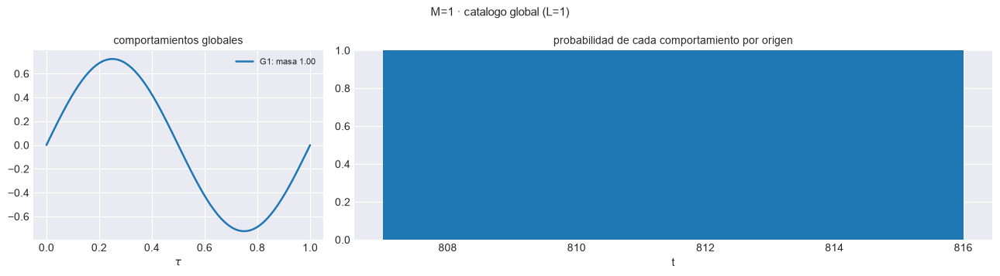

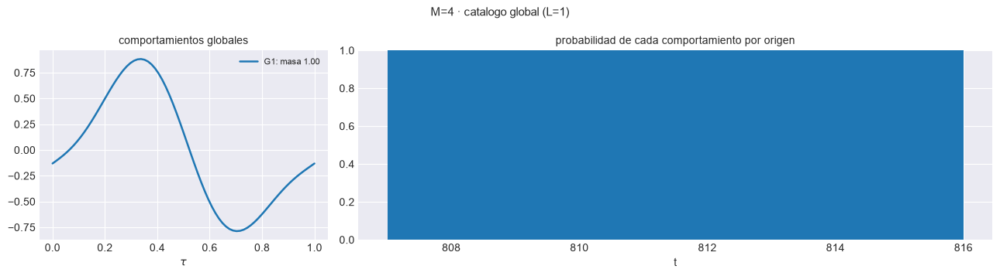

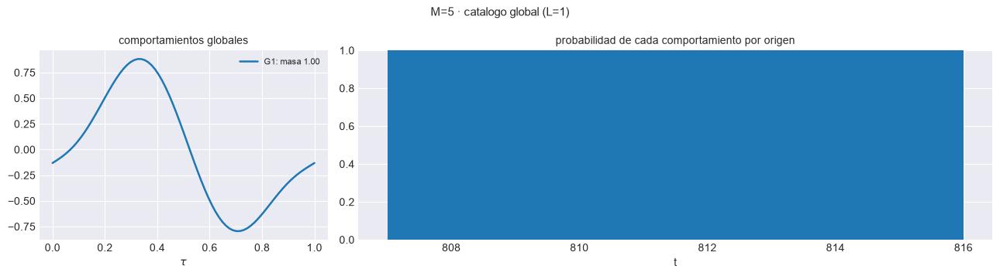

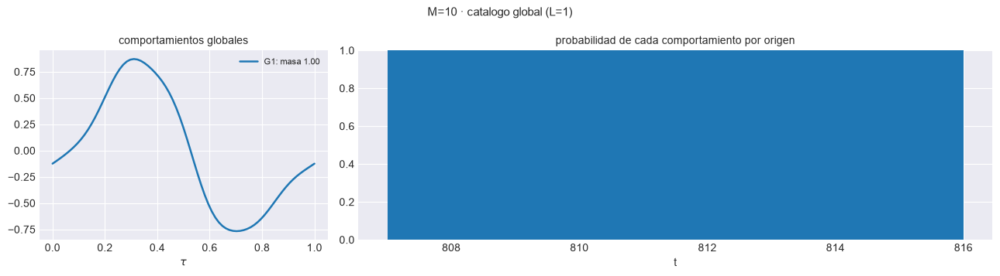

In [31]:
# catalogo_barrido sólo usa es_train para la máscara: la ventana de detalle hace de 'test'.
ORIG_DET = {**ORIG, "es_train": ~MASK_DET}
CAT_BAR = catalogo_barrido(EST, M_OK, ORIG_DET, PATH_BARRIDO)
for M in (m for m in M_DETALLE if m in M_OK):
    plot_catalogo(EST[M]["CATALOGO"], grilla, t_orig, M,
                  save_path=EST[M]["paths"]["out_report"] / "64_catalogo_global.png")
    plt.show()

### 12.4 Validación contra el régimen verdadero

Ley condicional verdadera por origen (`predictiva_oraculo_TAR`): $K$ del oráculo con las mismas reglas, TV entre masas, pureza y acierto de régimen. Como cuentas.

In [32]:
idx_te = IDX_DET                                                    # ventana de detalle (§3.2)
t_te   = t_orig[idx_te] - 1                                         # índice de curva, base 0
Z_OR, R_OR = predictiva_oraculo_TAR(esc, t_te, S_ORACULO, SEED_ORACULO, REPLICA_ID - 1)
R_REAL = esc["interno_regimen"][REPLICA_ID - 1][t_te, :A_ACT].astype(bool)
Y_REAL = esc["interno_scores"][REPLICA_ID - 1][t_te]
VAL_REG = regimen_barrido(EST, M_OK, ORIG, idx_te, Z_OR, R_OR, R_REAL, Y_REAL, PATH_BARRIDO)

CUENTAS = pd.DataFrame({M: {
    "orígenes": len(d), "K modelo = K oráculo": int((d.K == d.K_oraculo).sum()),
    "K >= 2, modelo": int((d.K >= 2).sum()), "K >= 2, oráculo": int((d.K_oraculo >= 2).sum()),
    "acierto de régimen, modelo": int(np.nansum(d.acierto_modelo)),
    "acierto de régimen, oráculo": int(np.nansum(d.acierto_oraculo))}
    for M, d in ((M, EST[M]["val_regimen"]) for M in M_OK)})
display(CUENTAS.style.set_caption(f"Ventana de detalle (t={T0_DET}..{T0_DET + N_DETALLE - 1}): cuentas sobre "
                                  f"{N_DETALLE} orígenes, descriptivas (104_validacion_regimen_por_M.csv)"))
for M in (m for m in M_DETALLE if m in M_OK):
    display(resumen_regimen(EST[M]["val_regimen"])["confusion"].style
            .set_caption(f"M={M} · K del modelo (filas) contra K del oráculo (columnas), ventana de detalle"))

M= 1: acuerdo en K 60.0% · TV 0.091 · pureza 0.977 · acierto de regimen modelo 80.0% / oraculo 90.0%


M= 2: acuerdo en K 60.0% · TV 0.115 · pureza 0.907 · acierto de regimen modelo 70.0% / oraculo 90.0%


M= 3: acuerdo en K 60.0% · TV 0.121 · pureza 0.881 · acierto de regimen modelo 70.0% / oraculo 90.0%


M= 4: acuerdo en K 60.0% · TV 0.121 · pureza 0.753 · acierto de regimen modelo 70.0% / oraculo 90.0%


M= 5: acuerdo en K 60.0% · TV 0.121 · pureza 0.753 · acierto de regimen modelo 70.0% / oraculo 90.0%


...

,1,2,3,4,5,6,7,8,9,10
orígenes,10,10,10,10,10,10,10,10,10,10
K modelo = K oráculo,6,6,6,6,6,6,6,6,6,6
"K >= 2, modelo",6,6,6,6,6,6,6,6,6,6
"K >= 2, oráculo",2,2,2,2,2,2,2,2,2,2
"acierto de régimen, modelo",8,7,7,7,7,7,7,7,7,7
"acierto de régimen, oráculo",9,9,9,9,9,9,9,9,9,9


K_oraculo,1,2
K_modelo,,
1,4,0
2,4,2


K_oraculo,1,2
K_modelo,,
1,4,0
2,1,2
3,3,0


K_oraculo,1,2
K_modelo,,
1,4,0
2,1,2
3,3,0


K_oraculo,1,2
K_modelo,,
1,4,0
2,1,2
3,3,0


### 12.5 Ventana de detalle, origen por origen

`112_ventana_detalle_por_origen.csv`: $K$ y masas, tramos de la HDR, longitud y cobertura de cada intervalo, verdad del generador y error de cada predictor.

In [33]:
wn, filas = pesos_normalizados(grilla, PESOS_TAU), []
for M in M_OK:
    e, C = EST[M], EST[M]["COMP"]
    nm = {pr: normas_error_por_origen(X_obj_ev[IDX_DET], e["X_PRED"][pr][IDX_DET], grilla,
                                      pesos_tau=PESOS_TAU, verificar=False) for pr in PREDICTORES}
    for j, i in enumerate(IDX_DET):
        fila = {"M": M, "t": int(t_orig[i]), "K": int(C["K"][i]),
                **{f"p_{c + 1}": float(C["masas"][i, c]) for c in range(int(C["K"][i]))},
                "hdr_tramos_max": int(e["hdr_tramos"][i].max())}
        for nombre, (L, U) in e["INTERVALOS"].items():
            fila[f"long_{nombre}"] = float(ancho_tramos(L[i], U[i]) @ wn)
            fila[f"cob_{nombre}"] = float(cobertura_tramos(X_obj_ev[i], L[i], U[i]).mean())
        for pr in PREDICTORES:
            fila[f"mae_{pr}"], fila[f"rmse_{pr}"] = float(nm[pr]["l1"][j]), float(nm[pr]["l2"][j])
        fila.update({k: v[i] for k, v in VERDAD_DET.items()})
        filas.append(fila)
DETALLE = pd.DataFrame(filas)
cols_p = sorted([c for c in DETALLE.columns if c.startswith("p_")], key=lambda c: int(c[2:]))
DETALLE = DETALLE[["M", "t", "K"] + cols_p + [c for c in DETALLE.columns if c not in ["M", "t", "K"] + cols_p]]
DETALLE.to_csv(PATH_BARRIDO / "112_ventana_detalle_por_origen.csv", index=False)
for M in (m for m in M_DETALLE if m in M_OK):
    display(DETALLE[DETALLE.M == M].drop(columns="M").set_index("t").style.format(precision=3)
            .set_caption(f"M={M} · ventana de detalle origen por origen (112_ventana_detalle_por_origen.csv)"))

,K,p_1,p_2,p_3,hdr_tramos_max,long_equicolas,cob_equicolas,long_simultanea,cob_simultanea,long_hdr,cob_hdr,mae_esperanza,rmse_esperanza,mae_mediana,rmse_mediana,mae_medoide,rmse_medoide,mae_modal,rmse_modal,regimen_activos,n_activos_en_B,cambios_de_regimen
t,,,,,,,,,,,,,,,,,,,,,,
807,2,0.930,0.070,nan,3,2.024,0.533,2.468,0.653,1.111,0.347,0.683,0.785,0.682,0.810,0.682,0.810,0.682,0.810,ABAB,2,1
808,2,0.753,0.247,nan,2,2.095,0.240,3.112,0.267,1.999,0.213,2.031,2.240,2.241,2.488,2.241,2.488,2.282,2.538,BBAA,2,2
809,1,1.000,nan,nan,1,2.068,0.653,2.072,0.653,2.074,0.667,0.999,1.118,0.892,1.004,0.892,1.005,0.869,0.981,BBAA,2,0
810,2,0.890,0.110,nan,2,3.897,0.747,6.623,0.947,2.424,0.640,0.398,0.476,0.490,0.576,0.490,0.576,0.504,0.591,AAAB,1,3
811,1,1.000,nan,nan,1,0.506,0.453,0.512,0.453,0.508,0.453,0.376,0.450,0.374,0.447,0.374,0.447,0.374,0.448,AAAB,1,0
812,1,1.000,nan,nan,1,0.509,0.307,0.508,0.333,0.516,0.320,0.339,0.381,0.341,0.384,0.341,0.384,0.343,0.386,AAAB,1,0
813,1,1.000,nan,nan,1,1.763,0.560,0.617,0.227,0.614,0.227,0.522,0.603,0.524,0.605,0.524,0.605,0.524,0.605,AABA,1,2
814,2,0.912,0.088,nan,3,2.239,0.400,3.022,0.413,1.612,0.253,1.733,2.062,1.730,2.064,1.730,2.064,1.731,2.065,ABBB,3,2
815,2,0.784,0.216,nan,2,2.088,0.360,3.240,0.667,1.901,0.333,1.178,1.349,1.156,1.326,1.156,1.326,1.155,1.329,ABAB,2,1


,K,p_1,p_2,p_3,hdr_tramos_max,long_equicolas,cob_equicolas,long_simultanea,cob_simultanea,long_hdr,cob_hdr,mae_esperanza,rmse_esperanza,mae_mediana,rmse_mediana,mae_medoide,rmse_medoide,mae_modal,rmse_modal,regimen_activos,n_activos_en_B,cambios_de_regimen
t,,,,,,,,,,,,,,,,,,,,,,
807,3,0.876,0.065,0.059,3,4.239,1.000,9.006,1.000,3.819,1.000,0.537,0.616,0.558,0.633,0.582,0.660,0.606,0.687,ABAB,2,1
808,2,0.753,0.247,nan,1,3.658,0.547,6.645,1.000,3.624,0.480,1.864,2.066,2.087,2.299,2.135,2.365,2.327,2.579,BBAA,2,2
809,1,1.000,nan,nan,1,3.587,0.973,5.198,1.000,3.588,0.933,1.101,1.223,0.998,1.117,0.990,1.123,0.993,1.171,BBAA,2,0
810,2,0.890,0.110,nan,2,5.447,1.000,13.383,1.000,4.836,1.000,0.475,0.551,0.431,0.531,0.470,0.572,0.503,0.641,AAAB,1,3
811,1,1.000,nan,nan,2,2.626,1.000,4.999,1.000,2.513,1.000,0.276,0.331,0.246,0.292,0.252,0.294,0.232,0.277,AAAB,1,0
812,1,1.000,nan,nan,2,2.592,1.000,4.383,1.000,2.569,1.000,0.486,0.531,0.389,0.445,0.367,0.413,0.334,0.380,AAAB,1,0
813,1,1.000,nan,nan,2,3.395,1.000,6.312,1.000,3.030,1.000,0.332,0.394,0.325,0.416,0.292,0.379,0.482,0.570,AABA,1,2
814,3,0.580,0.333,0.087,3,3.675,0.787,7.739,1.000,3.583,0.707,1.424,1.741,1.493,1.821,1.411,1.723,1.297,1.655,ABBB,3,2
815,2,0.784,0.216,nan,1,3.979,1.000,6.729,1.000,3.979,1.000,0.330,0.442,0.250,0.308,0.228,0.272,0.215,0.255,ABAB,2,1


,K,p_1,p_2,p_3,hdr_tramos_max,long_equicolas,cob_equicolas,long_simultanea,cob_simultanea,long_hdr,cob_hdr,mae_esperanza,rmse_esperanza,mae_mediana,rmse_mediana,mae_medoide,rmse_medoide,mae_modal,rmse_modal,regimen_activos,n_activos_en_B,cambios_de_regimen
t,,,,,,,,,,,,,,,,,,,,,,
807,3,0.876,0.065,0.059,3,4.305,1.000,8.629,1.000,3.899,1.000,0.534,0.606,0.566,0.628,0.543,0.613,0.612,0.678,ABAB,2,1
808,2,0.753,0.247,nan,1,3.746,0.547,6.612,1.000,3.711,0.453,1.873,2.069,2.084,2.290,2.156,2.373,2.336,2.581,BBAA,2,2
809,1,1.000,nan,nan,1,3.682,1.000,5.512,1.000,3.697,0.987,1.099,1.221,0.994,1.112,0.988,1.121,0.990,1.169,BBAA,2,0
810,2,0.890,0.110,nan,2,5.533,1.000,12.973,1.000,4.965,1.000,0.482,0.551,0.438,0.533,0.480,0.573,0.508,0.641,AAAB,1,3
811,1,1.000,nan,nan,2,2.750,1.000,4.752,1.000,2.677,1.000,0.277,0.332,0.249,0.297,0.255,0.301,0.232,0.277,AAAB,1,0
812,1,1.000,nan,nan,2,2.729,1.000,4.627,1.000,2.700,1.000,0.484,0.528,0.396,0.454,0.329,0.378,0.327,0.374,AAAB,1,0
813,1,1.000,nan,nan,2,3.470,1.000,6.309,1.000,3.155,1.000,0.325,0.385,0.315,0.401,0.292,0.377,0.476,0.563,AABA,1,2
814,3,0.580,0.333,0.087,3,3.761,0.787,7.491,1.000,3.680,0.747,1.423,1.734,1.484,1.808,1.349,1.687,1.298,1.647,ABBB,3,2
815,2,0.784,0.216,nan,1,4.101,1.000,6.792,1.000,4.092,1.000,0.382,0.494,0.274,0.360,0.297,0.373,0.285,0.350,ABAB,2,1


,K,p_1,p_2,p_3,hdr_tramos_max,long_equicolas,cob_equicolas,long_simultanea,cob_simultanea,long_hdr,cob_hdr,mae_esperanza,rmse_esperanza,mae_mediana,rmse_mediana,mae_medoide,rmse_medoide,mae_modal,rmse_modal,regimen_activos,n_activos_en_B,cambios_de_regimen
t,,,,,,,,,,,,,,,,,,,,,,
807,3,0.876,0.065,0.059,3,4.387,1.000,8.485,1.000,4.072,1.000,0.542,0.603,0.564,0.622,0.518,0.590,0.613,0.675,ABAB,2,1
808,2,0.753,0.247,nan,1,3.883,0.533,6.588,1.000,3.845,0.480,1.871,2.069,2.067,2.271,2.260,2.471,2.335,2.582,BBAA,2,2
809,1,1.000,nan,nan,1,3.792,1.000,5.804,1.000,3.800,1.000,1.106,1.222,1.000,1.112,0.908,1.023,1.002,1.170,BBAA,2,0
810,2,0.890,0.110,nan,2,5.637,1.000,12.736,1.000,5.174,1.000,0.478,0.541,0.441,0.526,0.427,0.566,0.508,0.631,AAAB,1,3
811,1,1.000,nan,nan,1,2.900,1.000,5.109,1.000,2.869,1.000,0.286,0.336,0.253,0.306,0.217,0.279,0.233,0.290,AAAB,1,0
812,1,1.000,nan,nan,2,2.869,1.000,4.878,1.000,2.851,1.000,0.474,0.524,0.401,0.458,0.547,0.626,0.329,0.368,AAAB,1,0
813,1,1.000,nan,nan,2,3.559,1.000,6.549,1.000,3.334,1.000,0.326,0.386,0.312,0.393,0.362,0.439,0.473,0.564,AABA,1,2
814,3,0.580,0.333,0.087,3,3.865,0.787,7.388,1.000,3.802,0.787,1.432,1.734,1.491,1.806,1.649,1.969,1.294,1.646,ABBB,3,2
815,2,0.784,0.216,nan,1,4.246,1.000,7.018,1.000,4.239,1.000,0.386,0.493,0.276,0.361,0.192,0.220,0.284,0.349,ABAB,2,1
